<ipython-input-9-8ed36a2ac234>:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved: D:\博士论文\小论文3\图片\Combined_VIC_and_PowerPlant.png
Saved: D:\博士论文\小论文3\图片\Combined_VIC_and_PowerPlant.pdf


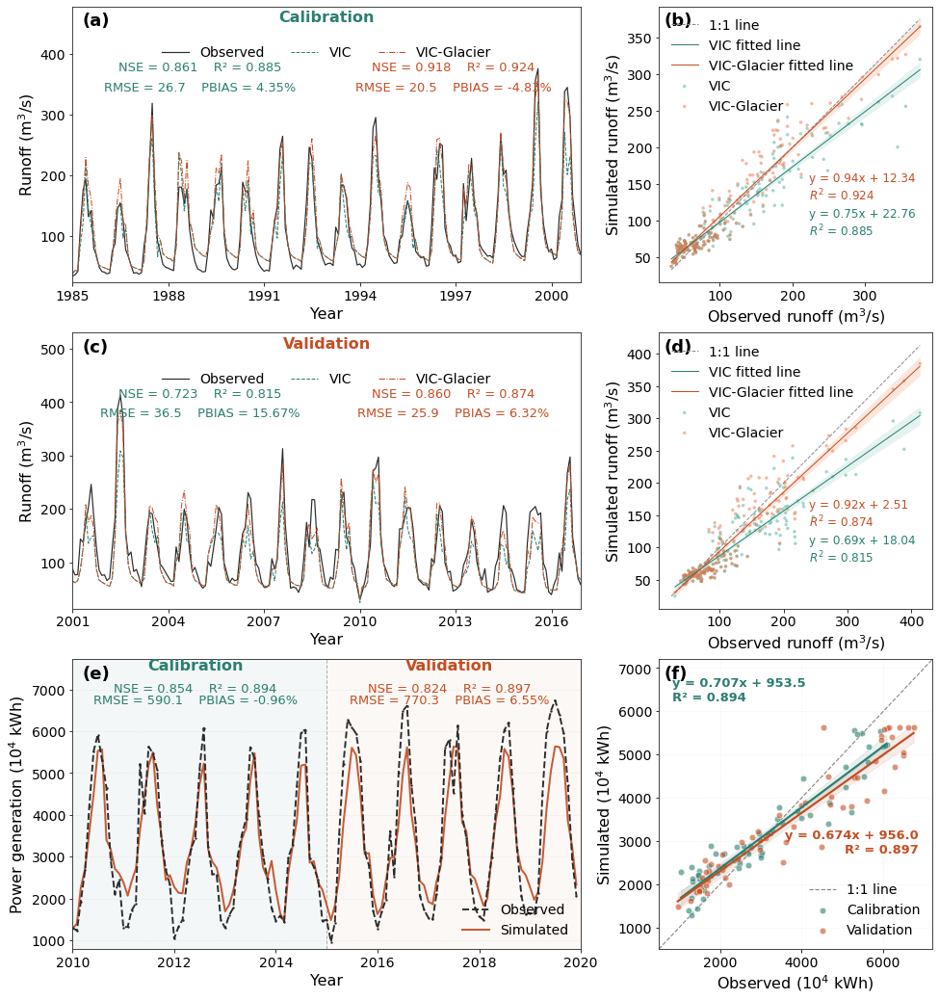

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from scipy import stats

# ==================== 1. 路径与数据加载 ====================
path_vic   = r"D:\Python code\boshilunwen\vic\cal"
path_power = r"D:\Python code\boshilunwen\电站模拟\results_kaidu_20261012_004612"

SAVE_DIR = r"D:\博士论文\小论文3\图片"
os.makedirs(SAVE_DIR, exist_ok=True)

os.chdir(path_vic)
df_vic_cal  = pd.read_excel('VIC率定期.xlsx')
df_vicg_cal = pd.read_excel('VIC-g率定期.xlsx')
df_vic_val  = pd.read_excel('VIC验证期.xlsx')
df_vicg_val = pd.read_excel('VIC-g验证期.xlsx')

for df in [df_vic_cal, df_vicg_cal, df_vic_val, df_vicg_val]:
    df.rename(columns={df.columns[0]: 'simulated', df.columns[1]: 'observed'}, inplace=True)

comparison = pd.read_excel(os.path.join(path_power, "cascade_monthly_comparison.xlsx"))
comparison["Date"] = pd.to_datetime(comparison["Year_Month"])
comparison = comparison.sort_values("Date").set_index("Date")

CAL_START, CAL_END = pd.Timestamp("2010-01-01"), pd.Timestamp("2014-12-31")
VAL_START, VAL_END = pd.Timestamp("2015-01-01"), pd.Timestamp("2019-12-31")

comparison_plot = comparison.loc["2010-01-01":"2019-12-31"]
cal_p = comparison.loc[CAL_START:CAL_END]
val_p = comparison.loc[VAL_START:VAL_END]

x_cal_p = cal_p["Actual_10^4kWh"].values;  y_cal_p = cal_p["Simulated_10^4kWh"].values
x_val_p = val_p["Actual_10^4kWh"].values;  y_val_p = val_p["Simulated_10^4kWh"].values

# ==================== 2. 日期索引 ====================
def generate_monthly_dates(start_year, end_year, n_rows):
    expected = (end_year - start_year + 1) * 12
    if n_rows == expected:
        return pd.date_range(start=f'{start_year}-01-31', end=f'{end_year}-12-31', freq='M')
    print(f"Warning: n_rows={n_rows} != expected={expected}, using sequential index")
    return np.arange(1, n_rows + 1)

dates_cal = generate_monthly_dates(1985, 2000, len(df_vic_cal))
dates_val = generate_monthly_dates(2001, 2016, len(df_vic_val))

# ==================== 3. 全局绘图设置（保持原英文版）====================
plt.rcParams['font.family']        = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

label_fontsize         = 16
tick_fontsize          = 14
legend_fontsize        = 14
subplot_label_fontsize = 18
annotation_fontsize    = 13

# ==================== 4. 海盐–珊瑚 色带 ====================
PALETTE = {
    # Sea-salt (teal)  → Observed / VIC / Calibration
    "sea_xxlight": "#E8F5F1",
    "sea_xlight":  "#C6E9E0",
    "sea_light":   "#95D3C4",
    "sea_mid":     "#4BAE9C",
    "sea_dark":    "#2A7F71",
    "sea_xdark":   "#134E45",
    # Coral (orange-red) → VIC-Glacier / Simulated / Validation
    "cor_xxlight": "#FFEDE4",
    "cor_xlight":  "#FBCBB4",
    "cor_light":   "#F5A07A",
    "cor_mid":     "#E97445",
    "cor_dark":    "#C44E23",
    "cor_xdark":   "#8B2F12",
    # Neutral (only for Observed / 1:1 line / divider)
    "neutral":     "#2B2B2B",
    "gray":        "#8A8A8A",
}

COLOR_CAL   = PALETTE["sea_dark"]     # calibration period
COLOR_VAL   = PALETTE["cor_dark"]     # validation period
COLOR_OBS   = PALETTE["neutral"]      # observed (kept neutral for readability)
COLOR_SIM   = PALETTE["cor_dark"]     # simulated power → coral family

C_VIC_TS    = PALETTE["sea_dark"]     # VIC time-series
C_VICG_TS   = PALETTE["cor_dark"]     # VIC-Glacier time-series
C_VIC_SC    = PALETTE["sea_mid"]      # VIC scatter
C_VICG_SC   = PALETTE["cor_mid"]      # VIC-Glacier scatter
C_VIC_FIT   = PALETTE["sea_dark"]     # VIC fitted line + annotation text
C_VICG_FIT  = PALETTE["cor_dark"]     # VIC-Glacier fitted line + annotation text
C_VIC_BAND  = PALETTE["sea_light"]    # VIC 95% band
C_VICG_BAND = PALETTE["cor_light"]    # VIC-Glacier 95% band
C_1TO1      = PALETTE["gray"]

# ==================== 5. 辅助函数 ====================
def set_year_ticks(ax, dates, start_year, end_year, step=3):
    if not isinstance(dates, pd.DatetimeIndex):
        return
    years = sorted(set(dates.year))
    disp  = [y for y in years if (y - start_year) % step == 0 and start_year <= y <= end_year]
    ticks, labels = [], []
    for y in disp:
        idx = dates[dates.year == y].min()
        if idx is not pd.NaT:
            ticks.append(idx); labels.append(str(y))
    ax.set_xticks(ticks); ax.set_xticklabels(labels, fontsize=tick_fontsize)

def calc_metrics(sim, obs):
    df = pd.DataFrame({"sim": sim, "obs": obs}).dropna()
    s, o = df["sim"].values, df["obs"].values
    return {
        "RMSE":  np.sqrt(np.mean((s - o) ** 2)),
        "R2":    np.corrcoef(s, o)[0, 1] ** 2,
        "NSE":   1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2),
        "PBIAS": np.sum(o - s) / np.sum(o) * 100,
    }

def regression_ci(x, y, confidence=0.95):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y); x, y = x[m], y[m]
    slope, intercept, r, _, _ = stats.linregress(x, y)
    xx = np.linspace(x.min(), x.max(), 200); yy = slope * xx + intercept
    n = len(x); resid = y - (slope * x + intercept)
    s_err = np.sqrt(np.sum(resid ** 2) / (n - 2))
    t_val = stats.t.ppf((1 + confidence) / 2, n - 2)
    ci = t_val * s_err * np.sqrt(1 / n + (xx - x.mean()) ** 2 / np.sum((x - x.mean()) ** 2))
    return xx, yy, yy - ci, yy + ci, slope, intercept, r ** 2

def format_eq(slope, intercept):
    sign = '+' if intercept >= 0 else '-'
    return f"y = {slope:.3f}x {sign} {abs(intercept):.1f}"

# ==================== 6. 组合大图 ====================
fig = plt.figure(figsize=(16, 18))
gs  = GridSpec(3, 2, width_ratios=[6.5, 3.5], height_ratios=[1, 1, 1.05],
               hspace=0.18, wspace=0.20)

# ---------------- (a) VIC calibration – runoff time series ----------------
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(dates_cal, df_vic_cal['observed'],  color=COLOR_OBS, ls='-',  linewidth=1.2, label='Observed')
ax1.plot(dates_cal, df_vic_cal['simulated'], color=C_VIC_TS,  ls='--', linewidth=1,   label='VIC')
ax1.plot(dates_cal, df_vicg_cal['simulated'],color=C_VICG_TS, ls='-.', linewidth=1,   label='VIC-Glacier')
ax1.set_ylabel(r'Runoff (m$^3$/s)', fontsize=label_fontsize)
ax1.set_xlabel('Year',              fontsize=label_fontsize)
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, 0.90),
           fontsize=legend_fontsize, frameon=False, ncol=3)
set_year_ticks(ax1, dates_cal, 1985, 2000, step=3)
ax1.tick_params(axis='both', labelsize=tick_fontsize)
ax1.set_xlim(dates_cal[0], dates_cal[-1])

ymax_a = max(df_vic_cal['observed'].max(),
             df_vic_cal['simulated'].max(),
             df_vicg_cal['simulated'].max())
ymin_a = min(df_vic_cal['observed'].min(),
             df_vic_cal['simulated'].min(),
             df_vicg_cal['simulated'].min())
yrange_a = ymax_a - ymin_a
ax1.set_ylim(ymin_a - 0.03 * yrange_a, ymax_a + 0.30 * yrange_a)

m_vic_cal  = calc_metrics(df_vic_cal['simulated'],  df_vic_cal['observed'])
m_vicg_cal = calc_metrics(df_vicg_cal['simulated'], df_vicg_cal['observed'])

ax1.text(0.5, 0.985, "Calibration", transform=ax1.transAxes,
         color=COLOR_CAL, fontsize=16, ha="center", va="top", fontweight="bold")

ax1.text(0.25, 0.8,
         f"NSE = {m_vic_cal['NSE']:.3f}    R² = {m_vic_cal['R2']:.3f}",
         transform=ax1.transAxes, color=C_VIC_TS, fontsize=annotation_fontsize,
         ha="center", va="top")
ax1.text(0.25, 0.73,
         f"RMSE = {m_vic_cal['RMSE']:.1f}    PBIAS = {m_vic_cal['PBIAS']:.2f}%",
         transform=ax1.transAxes, color=C_VIC_TS, fontsize=annotation_fontsize,
         ha="center", va="top")

ax1.text(0.75, 0.8,
         f"NSE = {m_vicg_cal['NSE']:.3f}    R² = {m_vicg_cal['R2']:.3f}",
         transform=ax1.transAxes, color=C_VICG_TS, fontsize=annotation_fontsize,
         ha="center", va="top")
ax1.text(0.75, 0.73,
         f"RMSE = {m_vicg_cal['RMSE']:.1f}    PBIAS = {m_vicg_cal['PBIAS']:.2f}%",
         transform=ax1.transAxes, color=C_VICG_TS, fontsize=annotation_fontsize,
         ha="center", va="top")

ax1.text(0.02, 0.98, '(a)', transform=ax1.transAxes, fontsize=subplot_label_fontsize,
         fontweight='bold', va='top', ha='left')

# ---------------- (b) VIC calibration – scatter ----------------
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(df_vic_cal['observed'],  df_vic_cal['simulated'],
            color=C_VIC_SC,  label='VIC',         alpha=0.5, s=12, edgecolors='none')
ax2.scatter(df_vicg_cal['observed'], df_vicg_cal['simulated'],
            color=C_VICG_SC, label='VIC-Glacier', alpha=0.5, s=12, edgecolors='none')
mn = min(df_vic_cal['observed'].min(), df_vic_cal['simulated'].min(), df_vicg_cal['simulated'].min())
mx = max(df_vic_cal['observed'].max(), df_vic_cal['simulated'].max(), df_vicg_cal['simulated'].max())
ax2.plot([mn, mx], [mn, mx], color=C_1TO1, ls='--', linewidth=1, label='1:1 line')

for tag, dfa, colr, band in [
        ('vic',  df_vic_cal,  C_VIC_FIT,  C_VIC_BAND),
        ('vicg', df_vicg_cal, C_VICG_FIT, C_VICG_BAND)]:
    slope, intercept, r, _, _ = stats.linregress(dfa['observed'], dfa['simulated'])
    r2 = r ** 2
    x_fit = np.linspace(dfa['observed'].min(), dfa['observed'].max(), 100)
    y_fit = slope * x_fit + intercept
    lbl   = 'VIC' if tag == 'vic' else 'VIC-Glacier'
    ax2.plot(x_fit, y_fit, color=colr, linewidth=1, linestyle='-', label=f'{lbl} fitted line')
    res = dfa['simulated'] - (slope * dfa['observed'] + intercept)
    se  = np.sqrt(np.sum(res ** 2) / (len(dfa) - 2))
    n   = len(dfa); t = stats.t.ppf(0.975, n - 2); xm = np.mean(dfa['observed'])
    se_fit = se * np.sqrt(1/n + (x_fit - xm)**2 / np.sum((dfa['observed'] - xm)**2))
    ax2.fill_between(x_fit, y_fit - t*se_fit, y_fit + t*se_fit, color=band, alpha=0.25, lw=0)
    txt = f'y = {slope:.2f}x + {intercept:.2f}\n$R^2$ = {r2:.3f}'
    ypos = 0.27 if tag == 'vic' else 0.4
    ax2.annotate(txt, xy=(0.55, ypos), xycoords='axes fraction',
                 fontsize=legend_fontsize - 2, ha='left', va='top', color=colr)

ax2.set_xlabel(r'Observed runoff (m$^3$/s)',  fontsize=label_fontsize)
ax2.set_ylabel(r'Simulated runoff (m$^3$/s)', fontsize=label_fontsize)
ax2.legend(fontsize=legend_fontsize, frameon=False)
ax2.tick_params(axis='both', labelsize=tick_fontsize)
ax2.text(0.02, 0.98, '(b)', transform=ax2.transAxes, fontsize=subplot_label_fontsize,
         fontweight='bold', va='top', ha='left')

# ---------------- (c) VIC validation – runoff time series ----------------
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(dates_val, df_vic_val['observed'],  color=COLOR_OBS, ls='-',  linewidth=1.2, label='Observed')
ax3.plot(dates_val, df_vic_val['simulated'], color=C_VIC_TS,  ls='--', linewidth=1,   label='VIC')
ax3.plot(dates_val, df_vicg_val['simulated'],color=C_VICG_TS, ls='-.', linewidth=1,   label='VIC-Glacier')
ax3.set_xlabel('Year',              fontsize=label_fontsize)
ax3.set_ylabel(r'Runoff (m$^3$/s)', fontsize=label_fontsize)
ax3.legend(loc='upper center', bbox_to_anchor=(0.5, 0.90),
           fontsize=legend_fontsize, frameon=False, ncol=3)
set_year_ticks(ax3, dates_val, 2001, 2016, step=3)
ax3.tick_params(axis='both', labelsize=tick_fontsize)
ax3.set_xlim(dates_val[0], dates_val[-1])

ymax_v = max(df_vic_val['observed'].max(),
             df_vic_val['simulated'].max(),
             df_vicg_val['simulated'].max())
ymin_v = min(df_vic_val['observed'].min(),
             df_vic_val['simulated'].min(),
             df_vicg_val['simulated'].min())
yrange_v = ymax_v - ymin_v
ax3.set_ylim(ymin_v - 0.03 * yrange_v, ymax_v + 0.30 * yrange_v)

m_vic_val  = calc_metrics(df_vic_val['simulated'],  df_vic_val['observed'])
m_vicg_val = calc_metrics(df_vicg_val['simulated'], df_vicg_val['observed'])

ax3.text(0.5, 0.985, "Validation", transform=ax3.transAxes,
         color=COLOR_VAL, fontsize=16, ha="center", va="top", fontweight="bold")

ax3.text(0.25, 0.8,
         f"NSE = {m_vic_val['NSE']:.3f}    R² = {m_vic_val['R2']:.3f}",
         transform=ax3.transAxes, color=C_VIC_TS, fontsize=annotation_fontsize,
         ha="center", va="top")
ax3.text(0.25, 0.73,
         f"RMSE = {m_vic_val['RMSE']:.1f}    PBIAS = {m_vic_val['PBIAS']:.2f}%",
         transform=ax3.transAxes, color=C_VIC_TS, fontsize=annotation_fontsize,
         ha="center", va="top")

ax3.text(0.75, 0.8,
         f"NSE = {m_vicg_val['NSE']:.3f}    R² = {m_vicg_val['R2']:.3f}",
         transform=ax3.transAxes, color=C_VICG_TS, fontsize=annotation_fontsize,
         ha="center", va="top")
ax3.text(0.75, 0.73,
         f"RMSE = {m_vicg_val['RMSE']:.1f}    PBIAS = {m_vicg_val['PBIAS']:.2f}%",
         transform=ax3.transAxes, color=C_VICG_TS, fontsize=annotation_fontsize,
         ha="center", va="top")

ax3.text(0.02, 0.98, '(c)', transform=ax3.transAxes, fontsize=subplot_label_fontsize,
         fontweight='bold', va='top', ha='left')

# ---------------- (d) VIC validation – scatter ----------------
ax4 = fig.add_subplot(gs[1, 1])
ax4.scatter(df_vic_val['observed'],  df_vic_val['simulated'],
            color=C_VIC_SC,  label='VIC',         alpha=0.5, s=12, edgecolors='none')
ax4.scatter(df_vicg_val['observed'], df_vicg_val['simulated'],
            color=C_VICG_SC, label='VIC-Glacier', alpha=0.5, s=12, edgecolors='none')
mn = min(df_vic_val['observed'].min(), df_vic_val['simulated'].min(), df_vicg_val['simulated'].min())
mx = max(df_vic_val['observed'].max(), df_vic_val['simulated'].max(), df_vicg_val['simulated'].max())
ax4.plot([mn, mx], [mn, mx], color=C_1TO1, ls='--', linewidth=1, label='1:1 line')

for tag, dfa, colr, band in [
        ('vic',  df_vic_val,  C_VIC_FIT,  C_VIC_BAND),
        ('vicg', df_vicg_val, C_VICG_FIT, C_VICG_BAND)]:
    slope, intercept, r, _, _ = stats.linregress(dfa['observed'], dfa['simulated'])
    r2 = r ** 2
    x_fit = np.linspace(dfa['observed'].min(), dfa['observed'].max(), 100)
    y_fit = slope * x_fit + intercept
    lbl   = 'VIC' if tag == 'vic' else 'VIC-Glacier'
    ax4.plot(x_fit, y_fit, color=colr, linewidth=1, linestyle='-', label=f'{lbl} fitted line')
    res = dfa['simulated'] - (slope * dfa['observed'] + intercept)
    se  = np.sqrt(np.sum(res ** 2) / (len(dfa) - 2))
    n   = len(dfa); t = stats.t.ppf(0.975, n - 2); xm = np.mean(dfa['observed'])
    se_fit = se * np.sqrt(1/n + (x_fit - xm)**2 / np.sum((dfa['observed'] - xm)**2))
    ax4.fill_between(x_fit, y_fit - t*se_fit, y_fit + t*se_fit, color=band, alpha=0.25, lw=0)
    txt = f'y = {slope:.2f}x + {intercept:.2f}\n$R^2$ = {r2:.3f}'
    ypos = 0.27 if tag == 'vic' else 0.4
    ax4.annotate(txt, xy=(0.55, ypos), xycoords='axes fraction',
                 fontsize=legend_fontsize - 2, ha='left', va='top', color=colr)

ax4.set_xlabel(r'Observed runoff (m$^3$/s)',  fontsize=label_fontsize)
ax4.set_ylabel(r'Simulated runoff (m$^3$/s)', fontsize=label_fontsize)
ax4.legend(fontsize=legend_fontsize, frameon=False)
ax4.tick_params(axis='both', labelsize=tick_fontsize)
ax4.text(0.02, 0.98, '(d)', transform=ax4.transAxes, fontsize=subplot_label_fontsize,
         fontweight='bold', va='top', ha='left')

# ---------------- (e) Power plant – monthly time series ----------------
ax5 = fig.add_subplot(gs[2, 0])
ax5.axvspan(CAL_START, CAL_END, color=COLOR_CAL, alpha=0.055, lw=0)
ax5.axvspan(VAL_START, VAL_END, color=COLOR_VAL, alpha=0.040, lw=0)

ax5.plot(comparison_plot.index, comparison_plot["Actual_10^4kWh"],
         color=COLOR_OBS, linewidth=1.9, linestyle="--",
         marker="o", markersize=2.4, markerfacecolor=COLOR_OBS,
         markeredgewidth=0, label="Observed", zorder=5)
ax5.plot(comparison_plot.index, comparison_plot["Simulated_10^4kWh"],
         color=COLOR_SIM, linewidth=2.0, label="Simulated", zorder=4, alpha=0.92)
ax5.axvline(pd.Timestamp("2015-01-01"), color="#888888",
            linestyle="--", linewidth=1.0, alpha=0.65)

ax5.set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2020-01-01"))
ymax = max(comparison_plot["Actual_10^4kWh"].max(), comparison_plot["Simulated_10^4kWh"].max())
ymin = min(comparison_plot["Actual_10^4kWh"].min(), comparison_plot["Simulated_10^4kWh"].min())
yrange = ymax - ymin
ax5.set_ylim(ymin - 0.03 * yrange, ymax + 0.17 * yrange)

m_cal = calc_metrics(y_cal_p, x_cal_p)
m_val = calc_metrics(y_val_p, x_val_p)

ax5.text(pd.Timestamp("2012-06-01"), ymax + 0.125 * yrange, "Calibration",
         color=COLOR_CAL, fontsize=16, ha="center", fontweight="bold")
ax5.text(pd.Timestamp("2017-06-01"), ymax + 0.125 * yrange, "Validation",
         color=COLOR_VAL, fontsize=16, ha="center", fontweight="bold")

ax5.text(pd.Timestamp("2012-06-01"), ymax + 0.075 * yrange,
         f"NSE = {m_cal['NSE']:.3f}    R² = {m_cal['R2']:.3f}",
         color=COLOR_CAL, fontsize=annotation_fontsize, ha="center", va="top")
ax5.text(pd.Timestamp("2012-06-01"), ymax + 0.025 * yrange,
         f"RMSE = {m_cal['RMSE']:.1f}    PBIAS = {m_cal['PBIAS']:.2f}%",
         color=COLOR_CAL, fontsize=annotation_fontsize, ha="center", va="top")
ax5.text(pd.Timestamp("2017-06-01"), ymax + 0.075 * yrange,
         f"NSE = {m_val['NSE']:.3f}    R² = {m_val['R2']:.3f}",
         color=COLOR_VAL, fontsize=annotation_fontsize, ha="center", va="top")
ax5.text(pd.Timestamp("2017-06-01"), ymax + 0.025 * yrange,
         f"RMSE = {m_val['RMSE']:.1f}    PBIAS = {m_val['PBIAS']:.2f}%",
         color=COLOR_VAL, fontsize=annotation_fontsize, ha="center", va="top")

ax5.set_xlabel("Year", fontsize=label_fontsize)
ax5.set_ylabel(r"Power generation ($10^4$ kWh)", fontsize=label_fontsize)
ax5.xaxis.set_major_locator(mdates.YearLocator(2))
ax5.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax5.tick_params(axis='both', labelsize=tick_fontsize)
ax5.legend(loc='lower right', fontsize=legend_fontsize, frameon=False)
ax5.grid(axis="y", linestyle="--", linewidth=0.55, color="#D0D0D0", alpha=0.35)
ax5.set_axisbelow(True)
ax5.text(0.02, 0.98, '(e)', transform=ax5.transAxes, fontsize=subplot_label_fontsize,
         fontweight='bold', va='top', ha='left')

# ---------------- (f) Power plant – scatter regression ----------------
ax6 = fig.add_subplot(gs[2, 1])
ax6.scatter(x_cal_p, y_cal_p, s=42, color=COLOR_CAL, alpha=0.60,
            edgecolor="white", linewidth=0.7, label="Calibration", zorder=3)
xx_c, yy_c, lo_c, hi_c, s_c, i_c, r2_c = regression_ci(x_cal_p, y_cal_p)
ax6.fill_between(xx_c, lo_c, hi_c, color=COLOR_CAL, alpha=0.10, zorder=1)
ax6.plot(xx_c, yy_c, color=COLOR_CAL, linewidth=2.2, zorder=4)

ax6.scatter(x_val_p, y_val_p, s=42, color=COLOR_VAL, alpha=0.60,
            edgecolor="white", linewidth=0.7, label="Validation", zorder=3)
xx_v, yy_v, lo_v, hi_v, s_v, i_v, r2_v = regression_ci(x_val_p, y_val_p)
ax6.fill_between(xx_v, lo_v, hi_v, color=COLOR_VAL, alpha=0.10, zorder=1)
ax6.plot(xx_v, yy_v, color=COLOR_VAL, linewidth=2.2, zorder=4)

low  = min(np.min(x_cal_p), np.min(x_val_p), np.min(y_cal_p), np.min(y_val_p))
high = max(np.max(x_cal_p), np.max(x_val_p), np.max(y_cal_p), np.max(y_val_p))
pad = (high - low) * 0.08; low -= pad; high += pad
ax6.plot([low, high], [low, high], linestyle="--", color="#888888",
         linewidth=1.15, label="1:1 line", zorder=2)
ax6.set_xlim(low, high); ax6.set_ylim(low, high)

ax6.text(0.05, 0.94,
         f"{format_eq(s_c, i_c)}\nR² = {r2_c:.3f}",
         transform=ax6.transAxes, fontsize=annotation_fontsize,
         va="top", ha="left", color=COLOR_CAL, fontweight="bold")
ax6.text(0.95, 0.32,
         f"{format_eq(s_v, i_v)}\nR² = {r2_v:.3f}",
         transform=ax6.transAxes, fontsize=annotation_fontsize,
         va="bottom", ha="right", color=COLOR_VAL, fontweight="bold")

ax6.set_xlabel(r"Observed ($10^4$ kWh)",  fontsize=label_fontsize)
ax6.set_ylabel(r"Simulated ($10^4$ kWh)", fontsize=label_fontsize)
ax6.tick_params(axis='both', labelsize=tick_fontsize)
ax6.legend(loc='lower right', fontsize=legend_fontsize, frameon=False)
ax6.grid(True, linestyle="--", linewidth=0.5, color="#D0D0D0", alpha=0.30)
ax6.set_axisbelow(True)
ax6.text(0.02, 0.98, '(f)', transform=ax6.transAxes, fontsize=subplot_label_fontsize,
         fontweight='bold', va='top', ha='left')

# ==================== 7. 保存 ====================
plt.tight_layout()
out_png = os.path.join(SAVE_DIR, "Combined_VIC_and_PowerPlant.png")
out_pdf = os.path.join(SAVE_DIR, "Combined_VIC_and_PowerPlant.pdf")
plt.savefig(out_png, dpi=300, bbox_inches='tight')
plt.savefig(out_pdf, bbox_inches='tight')
print("Saved:", out_png)
print("Saved:", out_pdf)
plt.show()

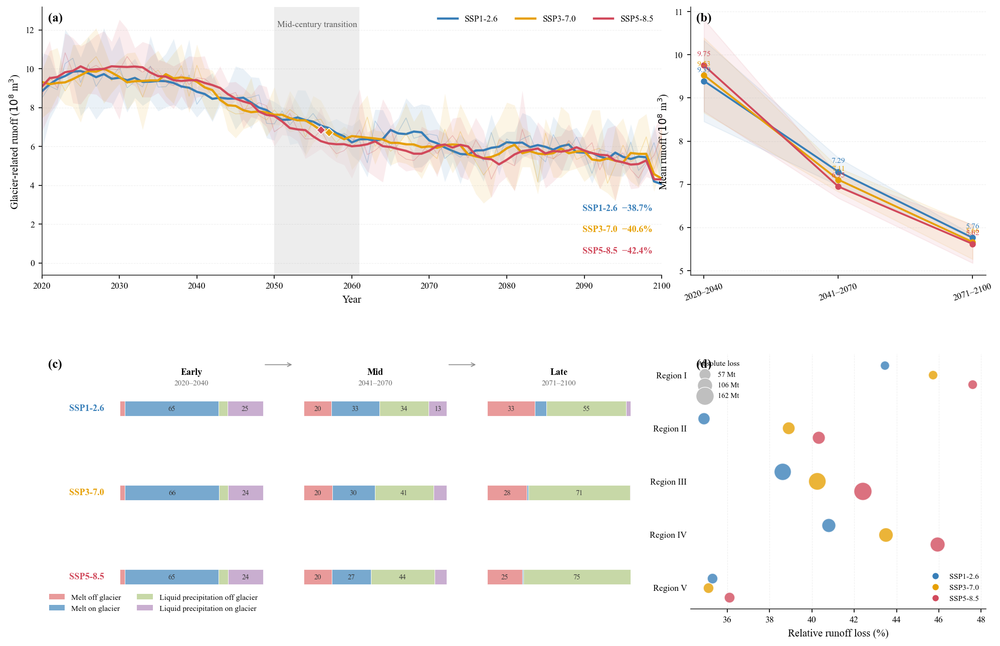


Saved:
D:\博士论文\小论文3\图片\Fig3_Journal_Composite_v2.png
D:\博士论文\小论文3\图片\Fig3_Journal_Composite_v2.pdf
D:\博士论文\小论文3\图片\Fig3_Journal_Composite_v2.svg


In [13]:
# =====================================================================
# Fig. 3 - Journal-style composite figure
#
# (a) Future annual glacier-related runoff
# (b) Stage-mean runoff trajectories
# (c) Runoff-source composition transition
# (d) Regional vulnerability: relative vs absolute runoff loss
#
# Existing OGGM outputs only - NO rerun
# =====================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import rankdata
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")


# =====================================================================
# 1. GLOBAL SETTINGS
# =====================================================================

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False

mpl.rcParams["font.size"] = 9
mpl.rcParams["axes.labelsize"] = 10
mpl.rcParams["xtick.labelsize"] = 8.5
mpl.rcParams["ytick.labelsize"] = 8.5
mpl.rcParams["legend.fontsize"] = 8.5

mpl.rcParams["axes.linewidth"] = 0.8
mpl.rcParams["xtick.direction"] = "out"
mpl.rcParams["ytick.direction"] = "out"

mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["savefig.facecolor"] = "white"


# =====================================================================
# 2. PATHS
# =====================================================================

BASE_FOLDER = r"D:\oggm\论文数据\开都河数据"
OUTPUT_FOLDER = r"D:\博士论文\小论文3\图片"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)


# =====================================================================
# 3. BASIC INFORMATION
# =====================================================================

MODELS = [
    "kd-year-gfdl-esm4",
    "kd-year-ipsl-cm6a-lr",
    "kd-year-mpi-esm1-2",
    "kd-year-mri-esm2-0",
    "kd-year-ukesm1-0-ll"
]

SCENARIOS = [
    "ssp126",
    "ssp370",
    "ssp585"
]

SCENARIO_LABELS = {
    "ssp126": "SSP1-2.6",
    "ssp370": "SSP3-7.0",
    "ssp585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "ssp126": "#377EB8",
    "ssp370": "#E69F00",
    "ssp585": "#D1495B"
}

REGIONS = ["I", "II", "III", "IV", "V"]

COMPONENTS = [
    "melt_off_glacier",
    "melt_on_glacier",
    "liq_prcp_off_glacier",
    "liq_prcp_on_glacier"
]

COMPONENT_LABELS = {
    "melt_off_glacier": "Melt off glacier",
    "melt_on_glacier": "Melt on glacier",
    "liq_prcp_off_glacier": "Liquid precipitation off glacier",
    "liq_prcp_on_glacier": "Liquid precipitation on glacier"
}

COMPONENT_COLORS = {
    "melt_off_glacier": "#E99A9A",
    "melt_on_glacier": "#78A9CF",
    "liq_prcp_off_glacier": "#C7D8A7",
    "liq_prcp_on_glacier": "#C9AED0"
}

PERIODS = {
    "Early": (2020, 2040),
    "Mid":   (2041, 2070),
    "Late":  (2071, 2100)
}

PERIOD_LABELS = {
    "Early": "2020–2040",
    "Mid": "2041–2070",
    "Late": "2071–2100"
}


# =====================================================================
# 4. PETTITT TEST
# =====================================================================

def pettitt_test(x):

    x = np.asarray(x, dtype=float)

    valid = np.isfinite(x)
    x = x[valid]

    n = len(x)

    ranks = rankdata(x)

    U = np.zeros(n)

    for t in range(n):

        U[t] = (
            2 * np.sum(ranks[:t + 1])
            - (t + 1) * (n + 1)
        )

    K = np.max(np.abs(U))

    idx = np.argmax(
        np.abs(U)
    )

    p = 2 * np.exp(
        (-6 * K ** 2)
        /
        (n ** 3 + n ** 2)
    )

    return K, p, idx


# =====================================================================
# 5. BASIN DATA
# =====================================================================

def load_basin_scenario(scenario):

    frames = []

    for model in MODELS:

        path = os.path.join(
            BASE_FOLDER,
            model,
            scenario,
            "summed_runoff.csv"
        )

        if not os.path.exists(path):
            print("Missing:", path)
            continue

        df = pd.read_csv(path)

        if "time" not in df.columns:
            continue

        df["time"] = pd.to_numeric(
            df["time"],
            errors="coerce"
        )

        df = df.dropna(
            subset=["time"]
        )

        df["time"] = (
            df["time"]
            .astype(int)
        )

        required = (
            COMPONENTS
            +
            ["total_runoff"]
        )

        if not all(
            c in df.columns
            for c in required
        ):
            continue

        for col in required:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

        df["model"] = model

        frames.append(
            df[
                ["time", "model"]
                + required
            ]
        )

    if not frames:
        return pd.DataFrame()

    return pd.concat(
        frames,
        ignore_index=True
    )


# =====================================================================
# 6. REGIONAL DATA
# =====================================================================

def load_region_scenario(region, scenario):

    frames = []

    for model in MODELS:

        path = os.path.join(
            BASE_FOLDER,
            model,
            scenario,
            "regional_runoff",
            f"Region_{region}_summed_runoff.csv"
        )

        if not os.path.exists(path):
            continue

        df = pd.read_csv(path)

        if (
            "time" not in df.columns
            or
            "total_runoff" not in df.columns
        ):
            continue

        df["time"] = pd.to_numeric(
            df["time"],
            errors="coerce"
        )

        df["total_runoff"] = pd.to_numeric(
            df["total_runoff"],
            errors="coerce"
        )

        df = df.dropna(
            subset=[
                "time",
                "total_runoff"
            ]
        )

        df["time"] = (
            df["time"]
            .astype(int)
        )

        df["model"] = model

        frames.append(
            df[
                [
                    "time",
                    "model",
                    "total_runoff"
                ]
            ]
        )

    if not frames:
        return pd.DataFrame()

    return pd.concat(
        frames,
        ignore_index=True
    )


# =====================================================================
# 7. ENSEMBLE
# =====================================================================

def get_basin_ensemble(scenario):

    df = load_basin_scenario(
        scenario
    )

    pivot = df.pivot_table(
        index="time",
        columns="model",
        values="total_runoff",
        aggfunc="mean"
    ).sort_index()

    result = pd.DataFrame(
        index=pivot.index
    )

    result["mean"] = (
        pivot.mean(axis=1)
    )

    result["p10"] = (
        pivot.quantile(
            0.10,
            axis=1
        )
    )

    result["p90"] = (
        pivot.quantile(
            0.90,
            axis=1
        )
    )

    # Mt → 10^8 m3
    factor = 0.01

    return result * factor


# =====================================================================
# 8. PERIOD MEANS
# =====================================================================

def get_period_statistics(scenario):

    df = load_basin_scenario(
        scenario
    )

    result = {}

    for period, (
        start,
        end
    ) in PERIODS.items():

        sub = df[
            (df.time >= start)
            &
            (df.time <= end)
        ]

        model_mean = (
            sub
            .groupby("model")
            ["total_runoff"]
            .mean()
        )

        result[period] = {

            "mean":
                model_mean.mean()
                * 0.01,

            "std":
                model_mean.std()
                * 0.01
        }

    return result


# =====================================================================
# 9. PERIOD COMPOSITION
# =====================================================================

def get_period_composition(scenario):

    df = load_basin_scenario(
        scenario
    )

    result = {}

    for period, (
        start,
        end
    ) in PERIODS.items():

        sub = df[
            (df.time >= start)
            &
            (df.time <= end)
        ]

        model_means = (
            sub
            .groupby("model")
            [COMPONENTS]
            .mean()
        )

        ensemble = (
            model_means.mean(axis=0)
        )

        pct = (
            ensemble
            /
            ensemble.sum()
            *
            100
        )

        result[period] = pct

    return result


# =====================================================================
# 10. REGIONAL LOSS
# =====================================================================

def get_region_loss(region, scenario):

    df = load_region_scenario(
        region,
        scenario
    )

    early = df[
        (df.time >= 2020)
        &
        (df.time <= 2040)
    ]

    late = df[
        (df.time >= 2071)
        &
        (df.time <= 2100)
    ]

    early_mean = (
        early
        .groupby("model")
        ["total_runoff"]
        .mean()
    )

    late_mean = (
        late
        .groupby("model")
        ["total_runoff"]
        .mean()
    )

    common = (
        early_mean.index
        .intersection(
            late_mean.index
        )
    )

    early_mean = (
        early_mean.loc[
            common
        ]
    )

    late_mean = (
        late_mean.loc[
            common
        ]
    )

    relative_loss = (
        (
            early_mean
            -
            late_mean
        )
        /
        early_mean
        *
        100
    )

    absolute_loss = (
        early_mean
        -
        late_mean
    )

    return {

        "relative":
            relative_loss.mean(),

        "absolute":
            absolute_loss.mean()
    }


# =====================================================================
# 11. FIGURE LAYOUT
# =====================================================================

fig = plt.figure(
    figsize=(13.8, 9.2),
    facecolor="white"
)

gs = GridSpec(
    2,
    12,
    figure=fig,

    height_ratios=[
        1.05,
        1
    ],

    hspace=0.30,
    wspace=0.55,

    left=0.07,
    right=0.98,
    top=0.97,
    bottom=0.10
)

ax_a = fig.add_subplot(
    gs[0, :8]
)

ax_b = fig.add_subplot(
    gs[0, 8:]
)

ax_c = fig.add_subplot(
    gs[1, :8]
)

ax_d = fig.add_subplot(
    gs[1, 8:]
)


# =====================================================================
# 12. PANEL A - FUTURE TIME SERIES
# =====================================================================

change_years = {}

declines = {}

for scenario in SCENARIOS:

    ensemble = (
        get_basin_ensemble(
            scenario
        )
    )

    years = ensemble.index

    mean = ensemble["mean"]

    moving = mean.rolling(
        5,
        center=True,
        min_periods=3
    ).mean()

    color = (
        SCENARIO_COLORS[
            scenario
        ]
    )

    ax_a.fill_between(
        years,
        ensemble["p10"],
        ensemble["p90"],
        color=color,
        alpha=0.10,
        linewidth=0
    )

    ax_a.plot(
        years,
        mean,
        color=color,
        linewidth=0.65,
        alpha=0.28
    )

    ax_a.plot(
        years,
        moving,
        color=color,
        linewidth=2.1,
        label=(
            SCENARIO_LABELS[
                scenario
            ]
        )
    )

    K, p, idx = (
        pettitt_test(
            mean.values
        )
    )

    if p < 0.05:

        cp = int(
            years[idx]
        )

        change_years[
            scenario
        ] = cp

        ax_a.scatter(
            cp,
            mean.iloc[idx],
            s=34,
            marker="D",
            color=color,
            edgecolor="white",
            linewidth=0.7,
            zorder=5
        )

    stats = (
        get_period_statistics(
            scenario
        )
    )

    early = (
        stats[
            "Early"
        ]["mean"]
    )

    late = (
        stats[
            "Late"
        ]["mean"]
    )

    decline = (
        (
            early - late
        )
        /
        early
        *
        100
    )

    declines[
        scenario
    ] = decline


# transition zone
ax_a.axvspan(
    2050,
    2061,
    color="0.85",
    alpha=0.45,
    linewidth=0
)

ax_a.text(
    2055.5,
    0.95,
    "Mid-century transition",
    transform=ax_a.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=8.5,
    color="0.35"
)


# end labels
label_y = [
    0.25,
    0.17,
    0.09
]

for scenario, yy in zip(
    SCENARIOS,
    label_y
):

    ax_a.text(
        0.985,
        yy,
        (
            f"{SCENARIO_LABELS[scenario]}  "
            f"−{declines[scenario]:.1f}%"
        ),
        transform=ax_a.transAxes,
        ha="right",
        va="center",
        color=(
            SCENARIO_COLORS[
                scenario
            ]
        ),
        fontsize=8.8,
        fontweight="bold"
    )


ax_a.set_xlim(
    2020,
    2100
)

ax_a.set_xlabel(
    "Year"
)

ax_a.set_ylabel(
    r"Glacier-related runoff ($10^8$ m$^3$)"
)

ax_a.legend(
    ncol=3,
    frameon=False,
    loc="upper right",
    handlelength=2.2
)

ax_a.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.20
)

ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)

ax_a.text(
    0.01,
    0.98,
    "(a)",
    transform=ax_a.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)


# =====================================================================
# 13. PANEL B - STAGE-MEAN SLOPE GRAPH
# =====================================================================

period_names = [
    "Early",
    "Mid",
    "Late"
]

x = np.arange(3)

for scenario in SCENARIOS:

    stats = (
        get_period_statistics(
            scenario
        )
    )

    vals = np.array(
        [
            stats[p]["mean"]
            for p in period_names
        ]
    )

    errs = np.array(
        [
            stats[p]["std"]
            for p in period_names
        ]
    )

    color = (
        SCENARIO_COLORS[
            scenario
        ]
    )

    ax_b.plot(
        x,
        vals,
        color=color,
        linewidth=1.8,
        marker="o",
        markersize=5,
        label=(
            SCENARIO_LABELS[
                scenario
            ]
        )
    )

    ax_b.fill_between(
        x,
        vals - errs,
        vals + errs,
        color=color,
        alpha=0.08
    )

    for xi, val in zip(
        x,
        vals
    ):

        ax_b.text(
            xi,
            val + 0.18,
            f"{val:.2f}",
            ha="center",
            va="bottom",
            fontsize=7.6,
            color=color
        )


ax_b.set_xticks(
    x
)

ax_b.set_xticklabels(
    [
        "2020–2040",
        "2041–2070",
        "2071–2100"
    ],
    rotation=18
)

ax_b.set_ylabel(
    r"Mean runoff ($10^8$ m$^3$)"
)

ax_b.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.20
)

ax_b.spines["top"].set_visible(False)
ax_b.spines["right"].set_visible(False)

ax_b.text(
    0.02,
    0.98,
    "(b)",
    transform=ax_b.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)


# =====================================================================
# =====================================================================
# 14. PANEL C - COMPOSITION TRANSITION
# =====================================================================

group_centers = [
    2.4,
    1.4,
    0.4
]

bar_height = 0.18

period_positions = [
    0,
    1.18,
    2.36
]

for row, scenario in enumerate(SCENARIOS):

    composition = get_period_composition(scenario)

    y = group_centers[row]

    for px, period in zip(period_positions, period_names):

        left = px

        pct = composition[period]

        for component in COMPONENTS:

            value = float(pct[component])

            width = value / 100 * 0.92

            ax_c.barh(
                y,
                width,
                left=left,
                height=bar_height,
                color=COMPONENT_COLORS[component],
                edgecolor="white",
                linewidth=0.4
            )

            if value >= 10:

                ax_c.text(
                    left + width / 2,
                    y,
                    f"{value:.0f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="0.20"
                )

            left += width

    ax_c.text(
        -0.10,
        y,
        SCENARIO_LABELS[scenario],
        ha="right",
        va="center",
        fontsize=8.8,
        fontweight="bold",
        color=SCENARIO_COLORS[scenario]
    )


for px, period in zip(period_positions, period_names):

    ax_c.text(
        px + 0.46,
        2.78,
        period,
        ha="center",
        va="bottom",
        fontsize=8.7,
        fontweight="bold"
    )

    ax_c.text(
        px + 0.46,
        2.66,
        PERIOD_LABELS[period],
        ha="center",
        va="bottom",
        fontsize=7.3,
        color="0.40"
    )


# arrows
for xx in [
    1.02,
    2.20
]:

    ax_c.annotate(
        "",
        xy=(
            xx + 0.10,
            2.92
        ),
        xytext=(
            xx - 0.10,
            2.92
        ),
        arrowprops=dict(
            arrowstyle="->",
            color="0.55",
            linewidth=0.8
        )
    )


legend_handles = [
    Patch(
        facecolor=(
            COMPONENT_COLORS[c]
        ),
        edgecolor="none",
        label=(
            COMPONENT_LABELS[c]
        )
    )
    for c in COMPONENTS
]

ax_c.legend(
    handles=legend_handles,
    ncol=2,
    frameon=False,
    loc="lower left",
    bbox_to_anchor=(
        0.00,
        -0.04
    ),
    fontsize=7.6
)

ax_c.set_xlim(
    -0.50,
    3.48
)

ax_c.set_ylim(
    0.02,
    3.05
)

ax_c.axis(
    "off"
)

ax_c.text(
    0.01,
    0.98,
    "(c)",
    transform=ax_c.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)


# =====================================================================
# =====================================================================
# 15. PANEL D - REGIONAL DOT-BUBBLE PLOT
# =====================================================================

scenario_offsets = {
    "ssp126": 0.18,
    "ssp370": 0.00,
    "ssp585": -0.18
}

all_abs = []

regional_results = {}

for region in REGIONS:

    regional_results[region] = {}

    for scenario in SCENARIOS:

        result = get_region_loss(region, scenario)

        regional_results[region][scenario] = result

        all_abs.append(result["absolute"])


max_abs = max(all_abs)

y_base = np.arange(len(REGIONS))[::-1]


for i, region in enumerate(REGIONS):

    y0 = y_base[i]

    for scenario in SCENARIOS:

        result = regional_results[region][scenario]

        relative = result["relative"]

        absolute = result["absolute"]

        size = 35 + 260 * (absolute / max_abs)

        ax_d.scatter(
            relative,
            y0 + scenario_offsets[scenario],
            s=size,
            color=SCENARIO_COLORS[scenario],
            alpha=0.78,
            edgecolor="white",
            linewidth=0.7,
            zorder=3
        )

ax_d.set_yticks(
    y_base
)

ax_d.set_yticklabels(
    [
        f"Region {r}"
        for r in REGIONS
    ]
)

ax_d.set_xlabel(
    "Relative runoff loss (%)"
)

ax_d.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.20
)

ax_d.spines["top"].set_visible(False)
ax_d.spines["right"].set_visible(False)
ax_d.spines["left"].set_visible(False)

ax_d.tick_params(
    axis="y",
    length=0
)


scenario_handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=6,
        markerfacecolor=(
            SCENARIO_COLORS[s]
        ),
        markeredgecolor="none",
        label=(
            SCENARIO_LABELS[s]
        )
    )
    for s in SCENARIOS
]

ax_d.legend(
    handles=scenario_handles,
    frameon=False,
    loc="lower right",
    fontsize=7.5
)

ax_d.text(
    0.02,
    0.98,
    "(d)",
    transform=ax_d.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)


# =====================================================================
# 16. BUBBLE SIZE LEGEND
# =====================================================================

bubble_vals = [
    max_abs * 0.35,
    max_abs * 0.65,
    max_abs
]

bubble_handles = []

for v in bubble_vals:

    size = (
        35
        +
        260
        *
        (
            v
            /
            max_abs
        )
    )

    bubble_handles.append(
        ax_d.scatter(
            [],
            [],
            s=size,
            facecolor="0.75",
            edgecolor="white",
            linewidth=0.6
        )
    )

bubble_labels = [
    f"{v:.0f} Mt"
    for v in bubble_vals
]

bubble_legend = (
    ax_d.legend(
        bubble_handles,
        bubble_labels,
        title="Absolute loss",
        frameon=False,
        loc="upper left",
        fontsize=7,
        title_fontsize=7.5
    )
)

ax_d.add_artist(
    bubble_legend
)

ax_d.legend(
    handles=scenario_handles,
    frameon=False,
    loc="lower right",
    fontsize=7.5
)


# =====================================================================
# 17. SAVE
# =====================================================================

png_path = os.path.join(
    OUTPUT_FOLDER,
    "Fig3_Journal_Composite_v2.png"
)

pdf_path = os.path.join(
    OUTPUT_FOLDER,
    "Fig3_Journal_Composite_v2.pdf"
)

svg_path = os.path.join(
    OUTPUT_FOLDER,
    "Fig3_Journal_Composite_v2.svg"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nSaved:")
print(png_path)
print(pdf_path)
print(svg_path)

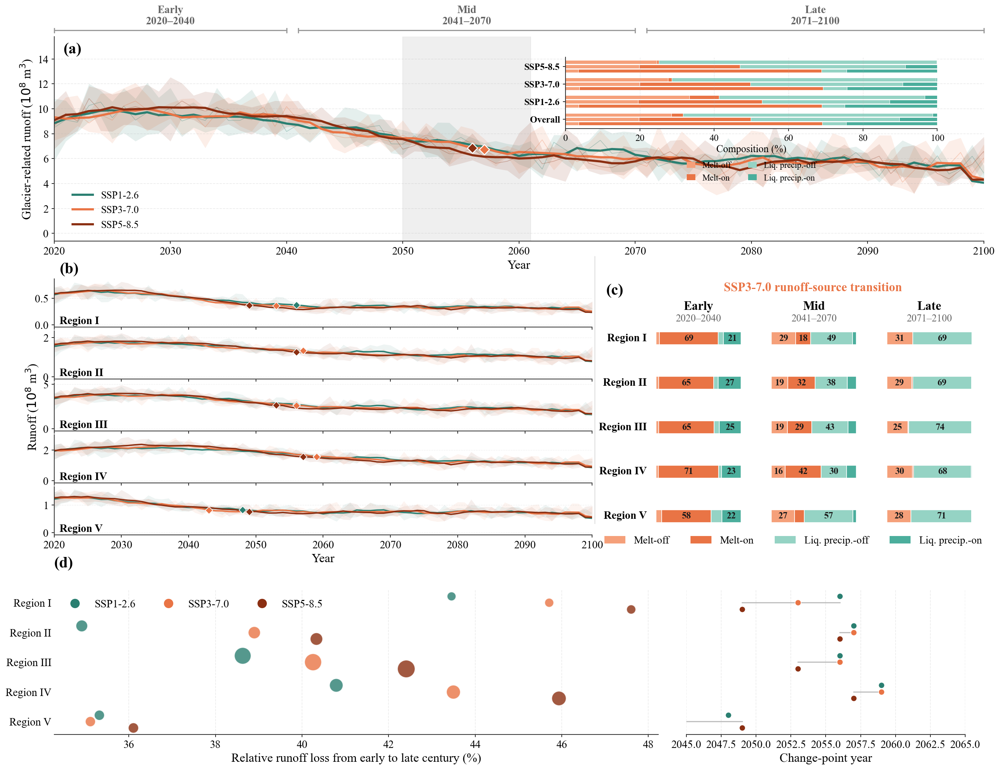

Saved successfully.


In [21]:
# ======================================================================
# Fig. 3
# Spatially explicit future transition of glacier-related runoff
# in the Kaidu River Basin
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import rankdata
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ======================================================================
# 1. GLOBAL STYLE
# ======================================================================
mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["savefig.facecolor"] = "white"

mpl.rcParams["font.size"] = 14
mpl.rcParams["axes.labelsize"] = 16
mpl.rcParams["xtick.labelsize"] = 14
mpl.rcParams["ytick.labelsize"] = 14
mpl.rcParams["legend.fontsize"] = 13

mpl.rcParams["axes.linewidth"] = 1.0
mpl.rcParams["xtick.direction"] = "out"
mpl.rcParams["ytick.direction"] = "out"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600

# ======================================================================
# 2. PATHS
# ======================================================================
BASE_FOLDER = r"D:\oggm\论文数据\开都河数据"
OUTPUT_FOLDER = r"D:\博士论文\小论文3\图片"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# ======================================================================
# 3. MODELS / SCENARIOS / REGIONS
# ======================================================================
MODELS = [
    "kd-year-gfdl-esm4", "kd-year-ipsl-cm6a-lr", "kd-year-mpi-esm1-2",
    "kd-year-mri-esm2-0", "kd-year-ukesm1-0-ll"
]
SCENARIOS = ["ssp126", "ssp370", "ssp585"]
SCENARIO_LABELS = {"ssp126": "SSP1-2.6", "ssp370": "SSP3-7.0", "ssp585": "SSP5-8.5"}

SCENARIO_COLORS = {
    "ssp126": "#2A7F71",  # 深海盐
    "ssp370": "#E97445",  # 中珊瑚
    "ssp585": "#8B2F12"   # 深珊瑚
}

REGIONS = ["I", "II", "III", "IV", "V"]

# ======================================================================
# 4. RUNOFF COMPONENTS
# ======================================================================
COMPONENTS = ["melt_off_glacier", "melt_on_glacier", "liq_prcp_off_glacier", "liq_prcp_on_glacier"]
COMPONENT_SHORT = {
    "melt_off_glacier": "Melt-off",
    "melt_on_glacier": "Melt-on",
    "liq_prcp_off_glacier": "Liq. precip.-off",
    "liq_prcp_on_glacier": "Liq. precip.-on"
}
COMPONENT_COLORS = {
    "melt_off_glacier": "#F5A07A",      # 浅珊瑚
    "melt_on_glacier": "#E97445",       # 中珊瑚
    "liq_prcp_off_glacier": "#95D3C4",  # 浅海盐
    "liq_prcp_on_glacier": "#4BAE9C"    # 中海盐
}

# ======================================================================
# 5. FUTURE PERIODS
# ======================================================================
PERIODS = {"Early": (2020, 2040), "Mid": (2041, 2070), "Late": (2071, 2100)}
PERIOD_LABELS = {"Early": "2020–2040", "Mid": "2041–2070", "Late": "2071–2100"}

# ======================================================================
# 6. PETTITT TEST
# ======================================================================
def pettitt_test(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 5: return np.nan, np.nan, None
    ranks = rankdata(x)
    U = np.zeros(n)
    for t in range(n):
        U[t] = (2 * np.sum(ranks[:t + 1]) - (t + 1) * (n + 1))
    K = np.max(np.abs(U))
    idx = np.argmax(np.abs(U))
    p = 2 * np.exp((-6 * K ** 2) / (n ** 3 + n ** 2))
    return K, min(p, 1.0), idx

# ======================================================================
# 7-11. DATA LOADING & STATISTICS
# ======================================================================
def load_basin_scenario(scenario):
    frames = []
    for model in MODELS:
        file_path = os.path.join(BASE_FOLDER, model, scenario, "summed_runoff.csv")
        if not os.path.exists(file_path): continue
        df = pd.read_csv(file_path)
        required = ["time", "total_runoff"] + COMPONENTS
        if not all(col in df.columns for col in required): continue
        df["time"] = pd.to_numeric(df["time"], errors="coerce").dropna().astype(int)
        for col in ["total_runoff"] + COMPONENTS: df[col] = pd.to_numeric(df[col], errors="coerce")
        df["model"] = model
        frames.append(df[["time", "model", "total_runoff"] + COMPONENTS])
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def load_region_scenario(region, scenario):
    frames = []
    for model in MODELS:
        file_path = os.path.join(BASE_FOLDER, model, scenario, "regional_runoff", f"Region_{region}_summed_runoff.csv")
        if not os.path.exists(file_path): continue
        df = pd.read_csv(file_path)
        required = ["time", "total_runoff"] + COMPONENTS
        if not all(col in df.columns for col in required): continue
        df["time"] = pd.to_numeric(df["time"], errors="coerce").dropna().astype(int)
        for col in ["total_runoff"] + COMPONENTS: df[col] = pd.to_numeric(df[col], errors="coerce")
        df["model"] = model
        frames.append(df[["time", "model", "total_runoff"] + COMPONENTS])
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def ensemble_statistics(df, variable="total_runoff"):
    pivot = df.pivot_table(index="time", columns="model", values=variable, aggfunc="mean").sort_index()
    out = pd.DataFrame(index=pivot.index)
    out["mean"] = pivot.mean(axis=1)
    out["p10"] = pivot.quantile(0.10, axis=1)
    out["p90"] = pivot.quantile(0.90, axis=1)
    out["std"] = pivot.std(axis=1)
    return out * 0.01  # Mt -> 10^8 m3

def period_composition(df):
    result = {}
    for period_name, (start, end) in PERIODS.items():
        sub = df[(df["time"] >= start) & (df["time"] <= end)].copy()
        if sub.empty: result[period_name] = None; continue
        model_means = sub.groupby("model")[COMPONENTS].mean()
        ensemble_mean = model_means.mean(axis=0)
        total = ensemble_mean.sum()
        result[period_name] = (ensemble_mean / total * 100) if total > 0 else None
    return result

def regional_metrics(region, scenario):
    df = load_region_scenario(region, scenario)
    if df.empty: return None
    early = df[(df["time"] >= 2020) & (df["time"] <= 2040)]
    late = df[(df["time"] >= 2071) & (df["time"] <= 2100)]
    early_model = early.groupby("model")["total_runoff"].mean()
    late_model = late.groupby("model")["total_runoff"].mean()
    common_models = early_model.index.intersection(late_model.index)
    early_model = early_model.loc[common_models]
    late_model = late_model.loc[common_models]
    relative_loss = ((early_model - late_model) / early_model * 100)
    absolute_loss = (early_model - late_model)
    ens = ensemble_statistics(df, variable="total_runoff")
    mean_series = ens["mean"]
    K, p, idx = pettitt_test(mean_series.values)
    cp_year = int(mean_series.index[idx]) if idx is not None else np.nan
    return {"relative_loss": relative_loss.mean(), "absolute_loss": absolute_loss.mean(), "change_year": cp_year, "change_p": p}

# ======================================================================
# 12. PRECOMPUTE DATA
# ======================================================================
basin_ensemble = {}
basin_change_year = {}
basin_comps = {}

for scenario in SCENARIOS:
    df = load_basin_scenario(scenario)
    ens = ensemble_statistics(df, "total_runoff")
    basin_ensemble[scenario] = ens
    basin_comps[scenario] = period_composition(df)
    
    K, p, idx = pettitt_test(ens["mean"].values)
    basin_change_year[scenario] = int(ens.index[idx]) if idx is not None else np.nan

# 计算总体（3个情景平均）的组分占比
overall_comps = {}
for p in PERIODS:
    series_list = [basin_comps[sc][p] for sc in SCENARIOS if basin_comps[sc][p] is not None]
    if series_list:
        overall_comps[p] = pd.concat(series_list, axis=1).mean(axis=1)
    else:
        overall_comps[p] = None

# ======================================================================
# 13. FIGURE LAYOUT
# ======================================================================
fig = plt.figure(figsize=(18, 14), facecolor="white")
outer = GridSpec(3, 12, figure=fig,
                 height_ratios=[1.2, 1.5, 1.0],
                 hspace=0.18, wspace=0.15,
                 left=0.06, right=0.98, top=0.96, bottom=0.06)

# ======================================================================
# PANEL A
# ======================================================================
ax_a = fig.add_subplot(outer[0, :])

# 顶部时段标注线
periods_visual = [("Early", 2020, 2040), ("Mid", 2041, 2070), ("Late", 2071, 2100)]
for p_name, p_start, p_end in periods_visual:
    ax_a.plot([p_start, p_end], [1.03, 1.03], transform=ax_a.get_xaxis_transform(), 
              color="0.6", linewidth=1.5, clip_on=False)
    ax_a.plot([p_start, p_start], [1.02, 1.04], transform=ax_a.get_xaxis_transform(), 
              color="0.6", linewidth=1.5, clip_on=False)
    ax_a.plot([p_end, p_end], [1.02, 1.04], transform=ax_a.get_xaxis_transform(), 
              color="0.6", linewidth=1.5, clip_on=False)
    ax_a.text((p_start + p_end)/2, 1.05, f"{p_name}\n{PERIOD_LABELS[p_name]}", 
              transform=ax_a.get_xaxis_transform(), ha="center", va="bottom", 
              fontsize=14, color="0.4", fontweight="bold")

main_handles = []
for scenario in SCENARIOS:
    ens = basin_ensemble[scenario]
    years = ens.index
    mean = ens["mean"]
    smooth = mean.rolling(5, center=True, min_periods=3).mean()
    color = SCENARIO_COLORS[scenario]

    ax_a.fill_between(years, ens["p10"], ens["p90"], color=color, alpha=0.12, linewidth=0)
    ax_a.plot(years, mean, color=color, linewidth=0.8, alpha=0.3)
    line, = ax_a.plot(years, smooth, color=color, linewidth=2.8, label=SCENARIO_LABELS[scenario])
    main_handles.append(line)

    cp = basin_change_year[scenario]
    if np.isfinite(cp):
        cp_idx = np.argmin(np.abs(years.to_numpy() - cp))
        cp_y = mean.iloc[cp_idx]
        ax_a.scatter(cp, cp_y, s=85, marker="D", color=color, edgecolor="white", linewidth=1.2, zorder=10)

ax_a.axvspan(2050, 2061, color="0.88", alpha=0.50, zorder=0)

ax_a.set_xlim(2020, 2100)
ymin, ymax = ax_a.get_ylim()
ax_a.set_ylim(ymin, ymax * 1.20) 

ax_a.set_ylabel(r"Glacier-related runoff ($10^8$ m$^3$)")
ax_a.set_xlabel("Year")
ax_a.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.25)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)

# (a) 主图图例移至左下角
ax_a.legend(handles=main_handles, loc="lower left", frameon=False, fontsize=13, bbox_to_anchor=(0.01, 0.01))

ax_a.text(0.01, 0.97, "(a)", transform=ax_a.transAxes, fontsize=20, fontweight="bold", va="top")

# 【新增】在 (a) 图右上角画嵌入图 (包含总体 + 3个情景)
inset_ax = ax_a.inset_axes([0.55, 0.55, 0.40, 0.35]) 

# 纵向排列：Overall, SSP126, SSP370, SSP585
labels = ["Overall"] + [SCENARIO_LABELS[s] for s in SCENARIOS]
y_ticks = range(len(labels))

for i, label in enumerate(labels):
    if label == "Overall":
        comps_data = overall_comps
    else:
        sc = SCENARIOS[i-1]
        comps_data = basin_comps[sc]
        
    for j, p in enumerate(["Early", "Mid", "Late"]):
        pct = comps_data[p]
        if pct is None: continue
        left = 0
        # 错开重叠：每个时间段在纵轴 i 处上下错开
        y_pos = i + (j - 1) * 0.25 
        for k, comp in enumerate(COMPONENTS):
            if label == "Overall":
                val = pct.iloc[k]
            else:
                val = float(pct[comp])
            inset_ax.barh(y_pos, val, left=left, height=0.2, 
                          color=COMPONENT_COLORS[comp], edgecolor="white", linewidth=0.5)
            left += val

inset_ax.set_yticks(y_ticks)
inset_ax.set_yticklabels(labels, fontsize=12, fontweight="bold")
inset_ax.set_xlim(0, 100)
inset_ax.set_xlabel("Composition (%)", fontsize=13, labelpad=2)
inset_ax.tick_params(axis='x', labelsize=12)
inset_ax.spines["top"].set_visible(False)
inset_ax.spines["right"].set_visible(False)
inset_ax.grid(axis="x", linestyle="--", linewidth=0.6, alpha=0.3)

# 嵌入图图例放置在嵌入图下部
inset_handles = [Patch(facecolor=COMPONENT_COLORS[comp], edgecolor="none", label=COMPONENT_SHORT[comp]) for comp in COMPONENTS]
inset_ax.legend(handles=inset_handles, loc="upper center", bbox_to_anchor=(0.5, -0.35), 
                ncol=2, frameon=False, fontsize=11, handlelength=1)

# ======================================================================
# PANEL B
# ======================================================================
regional_grid = GridSpecFromSubplotSpec(5, 1, subplot_spec=outer[1, :7], hspace=0.08)
regional_axes = []

for i, region in enumerate(REGIONS):
    if i == 0:
        ax = fig.add_subplot(regional_grid[i, 0])
    else:
        ax = fig.add_subplot(regional_grid[i, 0], sharex=regional_axes[0])
    regional_axes.append(ax)

    for scenario in SCENARIOS:
        df = load_region_scenario(region, scenario)
        if df.empty: continue
        ens = ensemble_statistics(df, "total_runoff")
        years = ens.index
        smooth = ens["mean"].rolling(5, center=True, min_periods=3).mean()
        color = SCENARIO_COLORS[scenario]

        ax.fill_between(years, ens["p10"], ens["p90"], color=color, alpha=0.08, linewidth=0)
        ax.plot(years, smooth, color=color, linewidth=1.8)
        
        K, p, idx = pettitt_test(ens["mean"].values)
        if idx is not None:
            cp_year = years[idx]
            cp_idx = np.argmin(np.abs(years - cp_year))
            cp_y = smooth.iloc[cp_idx]
            if np.isfinite(cp_y):
                ax.scatter(cp_year, cp_y, s=45, marker="D", color=color, edgecolor="white", linewidth=0.8, zorder=5)

    ax.set_xlim(2020, 2100)
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    # (b) 图区域标签放在左下角 (y=0.12)
    ax.text(0.01, 0.12, f"Region {region}", transform=ax.transAxes, fontsize=14, fontweight="bold", va="center")

    if i < len(REGIONS) - 1:
        ax.tick_params(axis="x", labelbottom=False)
    if i == 2:
        ax.set_ylabel(r"Runoff ($10^8$ m$^3$)")

regional_axes[-1].set_xlabel("Year")
regional_axes[0].text(0.01, 1.05, "(b)", transform=regional_axes[0].transAxes, fontsize=20, fontweight="bold", va="bottom")

# ======================================================================
# PANEL C
# ======================================================================
ax_c = fig.add_subplot(outer[1, 7:])
composition_scenario = "ssp370"
bar_height = 0.35

region_y = {"I": 4.8, "II": 3.6, "III": 2.4, "IV": 1.2, "V": 0.0}
period_x = {"Early": 0.0, "Mid": 1.25, "Late": 2.50}
bar_width_total = 0.92

for region in REGIONS:
    df = load_region_scenario(region, composition_scenario)
    comp_result = period_composition(df)
    y = region_y[region]

    for period_name in ["Early", "Mid", "Late"]:
        pct = comp_result[period_name]
        if pct is None: continue
        left = period_x[period_name]

        for component in COMPONENTS:
            value = float(pct[component])
            width = (bar_width_total * value / 100)
            ax_c.barh(y, width, left=left, height=bar_height, color=COMPONENT_COLORS[component], edgecolor="white", linewidth=0.8)
            
            if value >= 13:
                ax_c.text(left + width / 2, y, f"{value:.0f}", ha="center", va="center", fontsize=12, color="0.1", fontweight="bold")
            left += width

for region in REGIONS:
    ax_c.text(-0.10, region_y[region], f"Region {region}", ha="right", va="center", fontsize=14, fontweight="bold")

for period_name in ["Early", "Mid", "Late"]:
    center_x = (period_x[period_name] + bar_width_total / 2)
    ax_c.text(center_x, 5.5, period_name, ha="center", va="bottom", fontsize=16, fontweight="bold")
    ax_c.text(center_x, 5.2, PERIOD_LABELS[period_name], ha="center", va="bottom", fontsize=13, color="0.40")

ax_c.text(1.70, 6.0, "SSP3-7.0 runoff-source transition", ha="center", va="bottom",
          fontsize=16, color=SCENARIO_COLORS[composition_scenario], fontweight="bold")

component_handles = [Patch(facecolor=COMPONENT_COLORS[comp], edgecolor="none", label=COMPONENT_SHORT[comp]) for comp in COMPONENTS]
ax_c.legend(handles=component_handles, ncol=4, frameon=False, fontsize=13.5, loc="lower center", bbox_to_anchor=(0.50, -0.08))

ax_c.set_xlim(-0.58, 3.55)
ax_c.set_ylim(-0.5, 6.4) 
ax_c.axis("off")
ax_c.text(0.01, 0.98, "(c)", transform=ax_c.transAxes, fontsize=20, fontweight="bold", va="top")

# ======================================================================
# PANEL D
# ======================================================================
ax_d = fig.add_subplot(outer[2, :])
metrics = {}
for region in REGIONS:
    metrics[region] = {}
    for scenario in SCENARIOS:
        metrics[region][scenario] = regional_metrics(region, scenario)

left_ax = ax_d.inset_axes([0.00, 0.05, 0.65, 0.85]) 
all_abs_losses = [metrics[r][s]["absolute_loss"] for r in REGIONS for s in SCENARIOS]
max_abs_loss = max(all_abs_losses)
region_positions = np.arange(len(REGIONS))[::-1]
scenario_offset = {"ssp126": 0.22, "ssp370": 0.00, "ssp585": -0.22}

for i, region in enumerate(REGIONS):
    y = region_positions[i]
    for scenario in SCENARIOS:
        result = metrics[region][scenario]
        bubble_size = 60 + 450 * (result["absolute_loss"] / max_abs_loss)
        left_ax.scatter(result["relative_loss"], y + scenario_offset[scenario], s=bubble_size,
                        color=SCENARIO_COLORS[scenario], alpha=0.80, edgecolor="white", linewidth=1.0, zorder=3)

left_ax.set_yticks(region_positions)
left_ax.set_yticklabels([f"Region {r}" for r in REGIONS], fontsize=14)
left_ax.set_xlabel("Relative runoff loss from early to late century (%)", fontsize=16)
left_ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
left_ax.spines["top"].set_visible(False)
left_ax.spines["right"].set_visible(False)
left_ax.spines["left"].set_visible(False)
left_ax.tick_params(axis="y", length=0)

scenario_legend_handles = [Line2D([0], [0], marker="o", linestyle="", markerfacecolor=SCENARIO_COLORS[s],
                                  markeredgecolor="none", markersize=12, label=SCENARIO_LABELS[s]) for s in SCENARIOS]
left_ax.legend(handles=scenario_legend_handles, frameon=False, ncol=3, loc="upper left", fontsize=14)

right_ax = ax_d.inset_axes([0.68, 0.05, 0.30, 0.85])
for i, region in enumerate(REGIONS):
    y = region_positions[i]
    years = []
    for scenario in SCENARIOS:
        cp_year = metrics[region][scenario]["change_year"]
        years.append(cp_year)
        right_ax.scatter(cp_year, y + scenario_offset[scenario], s=60,
                         color=SCENARIO_COLORS[scenario], edgecolor="white", linewidth=0.8)
    valid_years = [yr for yr in years if np.isfinite(yr)]
    if valid_years:
        right_ax.plot([min(valid_years), max(valid_years)], [y, y], color="0.75", linewidth=1.5, zorder=0)

right_ax.set_yticks(region_positions)
right_ax.set_yticklabels([])
right_ax.set_xlim(2045, 2065)
right_ax.set_xlabel("Change-point year", fontsize=16)
right_ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
right_ax.spines["top"].set_visible(False)
right_ax.spines["right"].set_visible(False)
right_ax.spines["left"].set_visible(False)
right_ax.tick_params(axis="y", length=0)

ax_d.axis("off")
ax_d.text(0.00, 1.01, "(d)", transform=ax_d.transAxes, fontsize=20, fontweight="bold", va="bottom")

# ======================================================================
# 14. GLOBAL PANEL DIVIDERS
# ======================================================================
fig.add_artist(Line2D([0.595, 0.595], [0.34, 0.68], transform=fig.transFigure, color="0.88", linewidth=1.2))

# ======================================================================
# 15. SAVE
# ======================================================================
png_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.png")
pdf_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.pdf")
svg_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.svg")

fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
fig.savefig(svg_path, bbox_inches="tight", facecolor="white")

plt.show()
print("Saved successfully.")

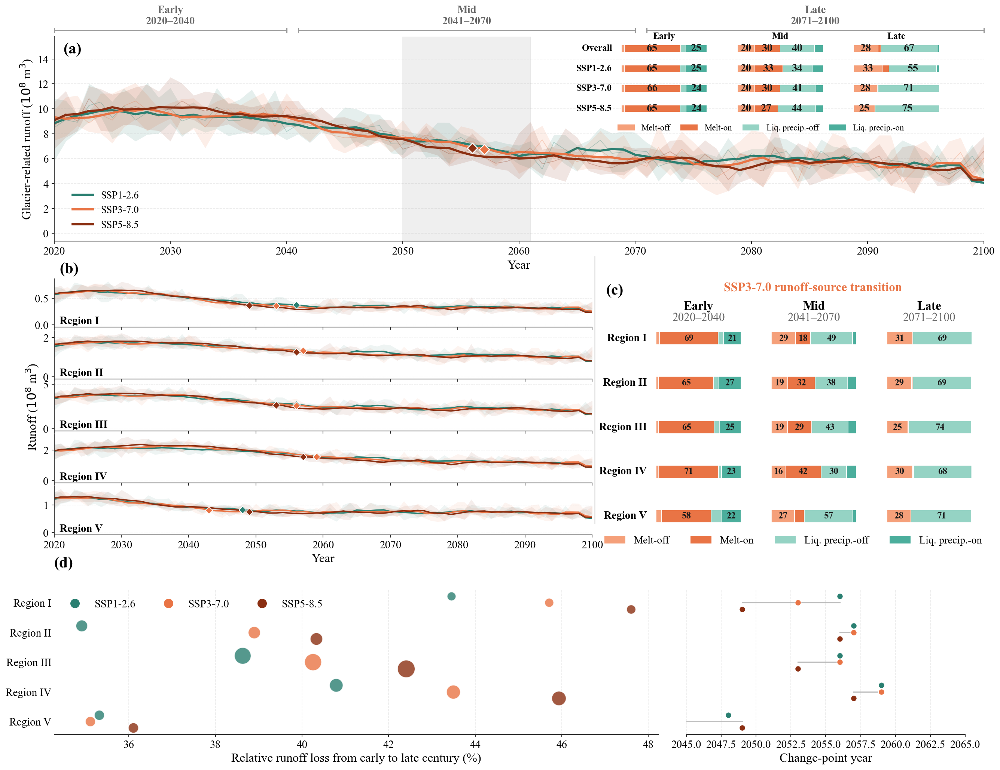

Saved successfully.


In [28]:
# ======================================================================
# Fig. 3
# Spatially explicit future transition of glacier-related runoff
# in the Kaidu River Basin
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import rankdata
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ======================================================================
# 1. GLOBAL STYLE
# ======================================================================
mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["savefig.facecolor"] = "white"

mpl.rcParams["font.size"] = 14
mpl.rcParams["axes.labelsize"] = 16
mpl.rcParams["xtick.labelsize"] = 14
mpl.rcParams["ytick.labelsize"] = 14
mpl.rcParams["legend.fontsize"] = 13

mpl.rcParams["axes.linewidth"] = 1.0
mpl.rcParams["xtick.direction"] = "out"
mpl.rcParams["ytick.direction"] = "out"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600

# ======================================================================
# 2. PATHS
# ======================================================================
BASE_FOLDER = r"D:\oggm\论文数据\开都河数据"
OUTPUT_FOLDER = r"D:\博士论文\小论文3\图片"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# ======================================================================
# 3. MODELS / SCENARIOS / REGIONS
# ======================================================================
MODELS = [
    "kd-year-gfdl-esm4", "kd-year-ipsl-cm6a-lr", "kd-year-mpi-esm1-2",
    "kd-year-mri-esm2-0", "kd-year-ukesm1-0-ll"
]
SCENARIOS = ["ssp126", "ssp370", "ssp585"]
SCENARIO_LABELS = {"ssp126": "SSP1-2.6", "ssp370": "SSP3-7.0", "ssp585": "SSP5-8.5"}

SCENARIO_COLORS = {
    "ssp126": "#2A7F71",  # 深海盐
    "ssp370": "#E97445",  # 中珊瑚
    "ssp585": "#8B2F12"   # 深珊瑚
}

REGIONS = ["I", "II", "III", "IV", "V"]

# ======================================================================
# 4. RUNOFF COMPONENTS
# ======================================================================
COMPONENTS = ["melt_off_glacier", "melt_on_glacier", "liq_prcp_off_glacier", "liq_prcp_on_glacier"]
COMPONENT_SHORT = {
    "melt_off_glacier": "Melt-off",
    "melt_on_glacier": "Melt-on",
    "liq_prcp_off_glacier": "Liq. precip.-off",
    "liq_prcp_on_glacier": "Liq. precip.-on"
}
COMPONENT_COLORS = {
    "melt_off_glacier": "#F5A07A",      # 浅珊瑚
    "melt_on_glacier": "#E97445",       # 中珊瑚
    "liq_prcp_off_glacier": "#95D3C4",  # 浅海盐
    "liq_prcp_on_glacier": "#4BAE9C"    # 中海盐
}

# ======================================================================
# 5. FUTURE PERIODS
# ======================================================================
PERIODS = {"Early": (2020, 2040), "Mid": (2041, 2070), "Late": (2071, 2100)}
PERIOD_LABELS = {"Early": "2020–2040", "Mid": "2041–2070", "Late": "2071–2100"}

# ======================================================================
# 6. PETTITT TEST
# ======================================================================
def pettitt_test(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 5: return np.nan, np.nan, None
    ranks = rankdata(x)
    U = np.zeros(n)
    for t in range(n):
        U[t] = (2 * np.sum(ranks[:t + 1]) - (t + 1) * (n + 1))
    K = np.max(np.abs(U))
    idx = np.argmax(np.abs(U))
    p = 2 * np.exp((-6 * K ** 2) / (n ** 3 + n ** 2))
    return K, min(p, 1.0), idx

# ======================================================================
# 7-11. DATA LOADING & STATISTICS
# ======================================================================
def load_basin_scenario(scenario):
    frames = []
    for model in MODELS:
        file_path = os.path.join(BASE_FOLDER, model, scenario, "summed_runoff.csv")
        if not os.path.exists(file_path): continue
        df = pd.read_csv(file_path)
        required = ["time", "total_runoff"] + COMPONENTS
        if not all(col in df.columns for col in required): continue
        df["time"] = pd.to_numeric(df["time"], errors="coerce").dropna().astype(int)
        for col in ["total_runoff"] + COMPONENTS: df[col] = pd.to_numeric(df[col], errors="coerce")
        df["model"] = model
        frames.append(df[["time", "model", "total_runoff"] + COMPONENTS])
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def load_region_scenario(region, scenario):
    frames = []
    for model in MODELS:
        file_path = os.path.join(BASE_FOLDER, model, scenario, "regional_runoff", f"Region_{region}_summed_runoff.csv")
        if not os.path.exists(file_path): continue
        df = pd.read_csv(file_path)
        required = ["time", "total_runoff"] + COMPONENTS
        if not all(col in df.columns for col in required): continue
        df["time"] = pd.to_numeric(df["time"], errors="coerce").dropna().astype(int)
        for col in ["total_runoff"] + COMPONENTS: df[col] = pd.to_numeric(df[col], errors="coerce")
        df["model"] = model
        frames.append(df[["time", "model", "total_runoff"] + COMPONENTS])
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def ensemble_statistics(df, variable="total_runoff"):
    pivot = df.pivot_table(index="time", columns="model", values=variable, aggfunc="mean").sort_index()
    out = pd.DataFrame(index=pivot.index)
    out["mean"] = pivot.mean(axis=1)
    out["p10"] = pivot.quantile(0.10, axis=1)
    out["p90"] = pivot.quantile(0.90, axis=1)
    out["std"] = pivot.std(axis=1)
    return out * 0.01  # Mt -> 10^8 m3

def period_composition(df):
    result = {}
    for period_name, (start, end) in PERIODS.items():
        sub = df[(df["time"] >= start) & (df["time"] <= end)].copy()
        if sub.empty: result[period_name] = None; continue
        model_means = sub.groupby("model")[COMPONENTS].mean()
        ensemble_mean = model_means.mean(axis=0)
        total = ensemble_mean.sum()
        result[period_name] = (ensemble_mean / total * 100) if total > 0 else None
    return result

def regional_metrics(region, scenario):
    df = load_region_scenario(region, scenario)
    if df.empty: return None
    early = df[(df["time"] >= 2020) & (df["time"] <= 2040)]
    late = df[(df["time"] >= 2071) & (df["time"] <= 2100)]
    early_model = early.groupby("model")["total_runoff"].mean()
    late_model = late.groupby("model")["total_runoff"].mean()
    common_models = early_model.index.intersection(late_model.index)
    early_model = early_model.loc[common_models]
    late_model = late_model.loc[common_models]
    relative_loss = ((early_model - late_model) / early_model * 100)
    absolute_loss = (early_model - late_model)
    ens = ensemble_statistics(df, variable="total_runoff")
    mean_series = ens["mean"]
    K, p, idx = pettitt_test(mean_series.values)
    cp_year = int(mean_series.index[idx]) if idx is not None else np.nan
    return {"relative_loss": relative_loss.mean(), "absolute_loss": absolute_loss.mean(), "change_year": cp_year, "change_p": p}

# ======================================================================
# 12. PRECOMPUTE DATA
# ======================================================================
basin_ensemble = {}
basin_change_year = {}
basin_comps = {}

for scenario in SCENARIOS:
    df = load_basin_scenario(scenario)
    ens = ensemble_statistics(df, "total_runoff")
    basin_ensemble[scenario] = ens
    basin_comps[scenario] = period_composition(df)
    
    K, p, idx = pettitt_test(ens["mean"].values)
    basin_change_year[scenario] = int(ens.index[idx]) if idx is not None else np.nan

# 计算总体平均组分
overall_comps = {}
for p in PERIODS:
    series_list = [basin_comps[sc][p] for sc in SCENARIOS if basin_comps[sc][p] is not None]
    if series_list:
        overall_comps[p] = pd.concat(series_list, axis=1).mean(axis=1)
    else:
        overall_comps[p] = None

# ======================================================================
# 13. FIGURE LAYOUT
# ======================================================================
fig = plt.figure(figsize=(18, 14), facecolor="white")
outer = GridSpec(3, 12, figure=fig,
                 height_ratios=[1.2, 1.5, 1.0],
                 hspace=0.18, wspace=0.15,
                 left=0.06, right=0.98, top=0.96, bottom=0.06)

# ======================================================================
# PANEL A
# ======================================================================
ax_a = fig.add_subplot(outer[0, :])

# 顶部时段标注
periods_visual = [("Early", 2020, 2040), ("Mid", 2041, 2070), ("Late", 2071, 2100)]
for p_name, p_start, p_end in periods_visual:
    ax_a.plot([p_start, p_end], [1.03, 1.03], transform=ax_a.get_xaxis_transform(), 
              color="0.6", linewidth=1.5, clip_on=False)
    ax_a.plot([p_start, p_start], [1.02, 1.04], transform=ax_a.get_xaxis_transform(), 
              color="0.6", linewidth=1.5, clip_on=False)
    ax_a.plot([p_end, p_end], [1.02, 1.04], transform=ax_a.get_xaxis_transform(), 
              color="0.6", linewidth=1.5, clip_on=False)
    ax_a.text((p_start + p_end)/2, 1.05, f"{p_name}\n{PERIOD_LABELS[p_name]}", 
              transform=ax_a.get_xaxis_transform(), ha="center", va="bottom", 
              fontsize=14, color="0.4", fontweight="bold")

main_handles = []
for scenario in SCENARIOS:
    ens = basin_ensemble[scenario]
    years = ens.index
    mean = ens["mean"]
    smooth = mean.rolling(5, center=True, min_periods=3).mean()
    color = SCENARIO_COLORS[scenario]

    ax_a.fill_between(years, ens["p10"], ens["p90"], color=color, alpha=0.12, linewidth=0)
    ax_a.plot(years, mean, color=color, linewidth=0.8, alpha=0.3)
    line, = ax_a.plot(years, smooth, color=color, linewidth=2.8, label=SCENARIO_LABELS[scenario])
    main_handles.append(line)

    cp = basin_change_year[scenario]
    if np.isfinite(cp):
        cp_idx = np.argmin(np.abs(years.to_numpy() - cp))
        cp_y = mean.iloc[cp_idx]
        ax_a.scatter(cp, cp_y, s=85, marker="D", color=color, edgecolor="white", linewidth=1.2, zorder=10)

ax_a.axvspan(2050, 2061, color="0.88", alpha=0.50, zorder=0)

ax_a.set_xlim(2020, 2100)
ymin, ymax = ax_a.get_ylim()
ax_a.set_ylim(ymin, ymax * 1.20) 

ax_a.set_ylabel(r"Glacier-related runoff ($10^8$ m$^3$)")
ax_a.set_xlabel("Year")
ax_a.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.25)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)

# 主图图例：左下角
ax_a.legend(handles=main_handles, loc="lower left", frameon=False, fontsize=13, bbox_to_anchor=(0.01, 0.01))
ax_a.text(0.01, 0.97, "(a)", transform=ax_a.transAxes, fontsize=20, fontweight="bold", va="top")

# ================= 嵌入图：类似 (c) 图 =================
inset_ax = ax_a.inset_axes([0.55, 0.60, 0.42, 0.42]) 

# 参数设置
bar_height = 0.35
y_labels = ["Overall", "SSP1-2.6", "SSP3-7.0", "SSP5-8.5"]
y_pos = [3, 2, 1, 0]  # 从上到下
period_names = ["Early", "Mid", "Late"]
period_x = [0.0, 1.25, 2.50]
bar_width_total = 0.92

for i, label in enumerate(y_labels):
    y = y_pos[i]
    if label == "Overall":
        comps_data = overall_comps
    else:
        sc = SCENARIOS[i-1]
        comps_data = basin_comps[sc]
        
    for j, p in enumerate(period_names):
        pct = comps_data[p]
        if pct is None: continue
        left = period_x[j]
        for comp in COMPONENTS:
            val = float(pct[comp])
            width = bar_width_total * val / 100
            inset_ax.barh(y, width, left=left, height=bar_height, color=COMPONENT_COLORS[comp], edgecolor="white", linewidth=0.5)
            
            if val >= 15:  # 字体稍小
                inset_ax.text(left + width / 2, y, f"{val:.0f}", ha="center", va="center", fontsize=14, color="0.1", fontweight="bold")
            left += width

# 添加 Y 轴文本 (不画刻度线)
for i, label in enumerate(y_labels):
    inset_ax.text(-0.1, y_pos[i], label, ha="right", va="center", fontsize=12, fontweight="bold")

# 添加时段标题 (顶部)
for j, p_name in enumerate(period_names):
    center_x = period_x[j] + bar_width_total / 2
    inset_ax.text(center_x, 3.4, p_name, ha="center", va="bottom", fontsize=12, fontweight="bold")

inset_ax.set_xlim(-0.6, 3.6)
inset_ax.set_ylim(-0.5, 3.8)
inset_ax.axis("off")

# 嵌入图图例：放置在嵌入图下部
inset_handles = [Patch(facecolor=COMPONENT_COLORS[comp], edgecolor="none", label=COMPONENT_SHORT[comp]) for comp in COMPONENTS]
inset_ax.legend(handles=inset_handles, ncol=4, frameon=False, fontsize=11, loc="lower center", bbox_to_anchor=(0.5, -0.25), columnspacing=1.2)

# ======================================================================
# PANEL B
# ======================================================================
regional_grid = GridSpecFromSubplotSpec(5, 1, subplot_spec=outer[1, :7], hspace=0.08)
regional_axes = []

for i, region in enumerate(REGIONS):
    if i == 0:
        ax = fig.add_subplot(regional_grid[i, 0])
    else:
        ax = fig.add_subplot(regional_grid[i, 0], sharex=regional_axes[0])
    regional_axes.append(ax)

    for scenario in SCENARIOS:
        df = load_region_scenario(region, scenario)
        if df.empty: continue
        ens = ensemble_statistics(df, "total_runoff")
        years = ens.index
        smooth = ens["mean"].rolling(5, center=True, min_periods=3).mean()
        color = SCENARIO_COLORS[scenario]

        ax.fill_between(years, ens["p10"], ens["p90"], color=color, alpha=0.08, linewidth=0)
        ax.plot(years, smooth, color=color, linewidth=1.8)
        
        K, p, idx = pettitt_test(ens["mean"].values)
        if idx is not None:
            cp_year = years[idx]
            cp_idx = np.argmin(np.abs(years - cp_year))
            cp_y = smooth.iloc[cp_idx]
            if np.isfinite(cp_y):
                ax.scatter(cp_year, cp_y, s=45, marker="D", color=color, edgecolor="white", linewidth=0.8, zorder=5)

    ax.set_xlim(2020, 2100)
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    # (b) 区域标签移至左下角 (y=0.12)
    ax.text(0.01, 0.12, f"Region {region}", transform=ax.transAxes, fontsize=14, fontweight="bold", va="center")

    if i < len(REGIONS) - 1:
        ax.tick_params(axis="x", labelbottom=False)
    if i == 2:
        ax.set_ylabel(r"Runoff ($10^8$ m$^3$)")

regional_axes[-1].set_xlabel("Year")
regional_axes[0].text(0.01, 1.05, "(b)", transform=regional_axes[0].transAxes, fontsize=20, fontweight="bold", va="bottom")

# ======================================================================
# PANEL C
# ======================================================================
ax_c = fig.add_subplot(outer[1, 7:])
composition_scenario = "ssp370"
bar_height = 0.35

region_y = {"I": 4.8, "II": 3.6, "III": 2.4, "IV": 1.2, "V": 0.0}
period_x = {"Early": 0.0, "Mid": 1.25, "Late": 2.50}
bar_width_total = 0.92

for region in REGIONS:
    df = load_region_scenario(region, composition_scenario)
    comp_result = period_composition(df)
    y = region_y[region]

    for period_name in ["Early", "Mid", "Late"]:
        pct = comp_result[period_name]
        if pct is None: continue
        left = period_x[period_name]

        for component in COMPONENTS:
            value = float(pct[component])
            width = (bar_width_total * value / 100)
            ax_c.barh(y, width, left=left, height=bar_height, color=COMPONENT_COLORS[component], edgecolor="white", linewidth=0.8)
            
            if value >= 13:
                ax_c.text(left + width / 2, y, f"{value:.0f}", ha="center", va="center", fontsize=12, color="0.1", fontweight="bold")
            left += width

for region in REGIONS:
    ax_c.text(-0.10, region_y[region], f"Region {region}", ha="right", va="center", fontsize=14, fontweight="bold")

for period_name in ["Early", "Mid", "Late"]:
    center_x = (period_x[period_name] + bar_width_total / 2)
    ax_c.text(center_x, 5.5, period_name, ha="center", va="bottom", fontsize=16, fontweight="bold")
    ax_c.text(center_x, 5.2, PERIOD_LABELS[period_name], ha="center", va="bottom", fontsize=15, color="0.40")

ax_c.text(1.70, 6.0, "SSP3-7.0 runoff-source transition", ha="center", va="bottom",
          fontsize=16, color=SCENARIO_COLORS[composition_scenario], fontweight="bold")

component_handles = [Patch(facecolor=COMPONENT_COLORS[comp], edgecolor="none", label=COMPONENT_SHORT[comp]) for comp in COMPONENTS]
ax_c.legend(handles=component_handles, ncol=4, frameon=False, fontsize=13.5, loc="lower center", bbox_to_anchor=(0.50, -0.08))

ax_c.set_xlim(-0.58, 3.55)
ax_c.set_ylim(-0.5, 6.4) 
ax_c.axis("off")
ax_c.text(0.01, 0.98, "(c)", transform=ax_c.transAxes, fontsize=20, fontweight="bold", va="top")

# ======================================================================
# PANEL D
# ======================================================================
ax_d = fig.add_subplot(outer[2, :])
metrics = {}
for region in REGIONS:
    metrics[region] = {}
    for scenario in SCENARIOS:
        metrics[region][scenario] = regional_metrics(region, scenario)

left_ax = ax_d.inset_axes([0.00, 0.05, 0.65, 0.85]) 
all_abs_losses = [metrics[r][s]["absolute_loss"] for r in REGIONS for s in SCENARIOS]
max_abs_loss = max(all_abs_losses)
region_positions = np.arange(len(REGIONS))[::-1]
scenario_offset = {"ssp126": 0.22, "ssp370": 0.00, "ssp585": -0.22}

for i, region in enumerate(REGIONS):
    y = region_positions[i]
    for scenario in SCENARIOS:
        result = metrics[region][scenario]
        bubble_size = 60 + 450 * (result["absolute_loss"] / max_abs_loss)
        left_ax.scatter(result["relative_loss"], y + scenario_offset[scenario], s=bubble_size,
                        color=SCENARIO_COLORS[scenario], alpha=0.80, edgecolor="white", linewidth=1.0, zorder=3)

left_ax.set_yticks(region_positions)
left_ax.set_yticklabels([f"Region {r}" for r in REGIONS], fontsize=14)
left_ax.set_xlabel("Relative runoff loss from early to late century (%)", fontsize=16)
left_ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
left_ax.spines["top"].set_visible(False)
left_ax.spines["right"].set_visible(False)
left_ax.spines["left"].set_visible(False)
left_ax.tick_params(axis="y", length=0)

scenario_legend_handles = [Line2D([0], [0], marker="o", linestyle="", markerfacecolor=SCENARIO_COLORS[s],
                                  markeredgecolor="none", markersize=12, label=SCENARIO_LABELS[s]) for s in SCENARIOS]
left_ax.legend(handles=scenario_legend_handles, frameon=False, ncol=3, loc="upper left", fontsize=14)

right_ax = ax_d.inset_axes([0.68, 0.05, 0.30, 0.85])
for i, region in enumerate(REGIONS):
    y = region_positions[i]
    years = []
    for scenario in SCENARIOS:
        cp_year = metrics[region][scenario]["change_year"]
        years.append(cp_year)
        right_ax.scatter(cp_year, y + scenario_offset[scenario], s=60,
                         color=SCENARIO_COLORS[scenario], edgecolor="white", linewidth=0.8)
    valid_years = [yr for yr in years if np.isfinite(yr)]
    if valid_years:
        right_ax.plot([min(valid_years), max(valid_years)], [y, y], color="0.75", linewidth=1.5, zorder=0)

right_ax.set_yticks(region_positions)
right_ax.set_yticklabels([])
right_ax.set_xlim(2045, 2065)
right_ax.set_xlabel("Change-point year", fontsize=16)
right_ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
right_ax.spines["top"].set_visible(False)
right_ax.spines["right"].set_visible(False)
right_ax.spines["left"].set_visible(False)
right_ax.tick_params(axis="y", length=0)

ax_d.axis("off")
ax_d.text(0.00, 1.01, "(d)", transform=ax_d.transAxes, fontsize=20, fontweight="bold", va="bottom")

# ======================================================================
# 14. GLOBAL PANEL DIVIDERS
# ======================================================================
fig.add_artist(Line2D([0.595, 0.595], [0.34, 0.68], transform=fig.transFigure, color="0.88", linewidth=1.2))

# ======================================================================
# 15. SAVE
# ======================================================================
png_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.png")
pdf_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.pdf")
svg_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.svg")

fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
fig.savefig(svg_path, bbox_inches="tight", facecolor="white")

plt.show()
print("Saved successfully.")

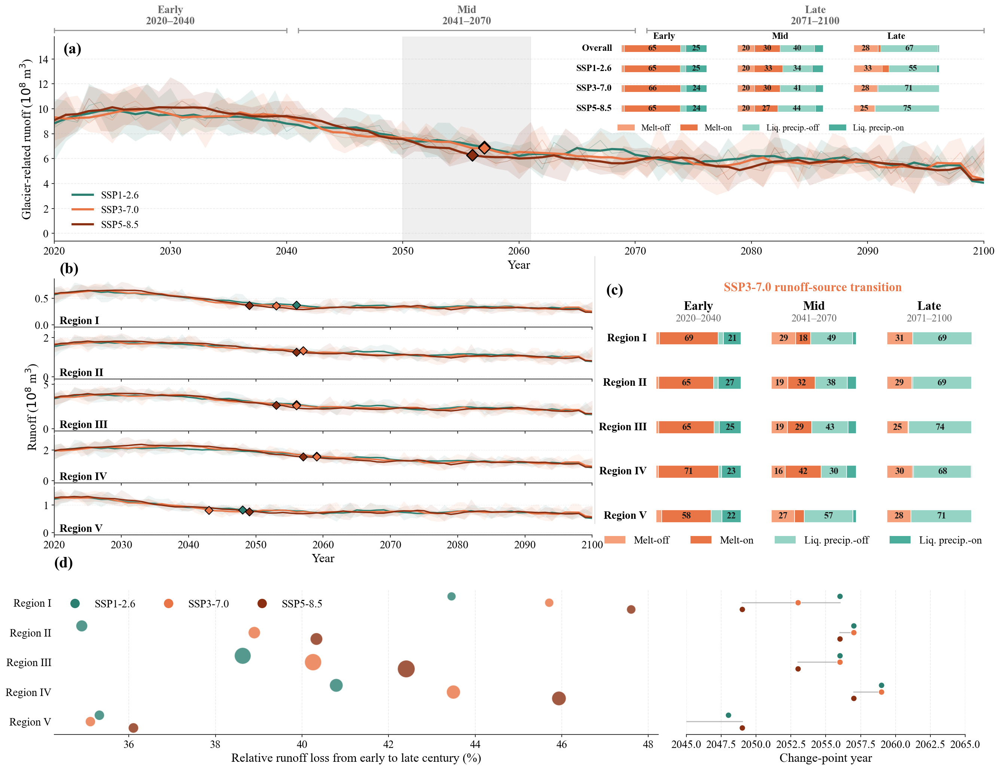

Saved successfully.

 SECTION 1 — BASIN-WIDE CHANGE POINTS (Panel a, diamonds)
  SSP1-2.6    Change-point year = 2057  |  Pettitt p-value = 0.0000
  SSP3-7.0    Change-point year = 2057  |  Pettitt p-value = 0.0000
  SSP5-8.5    Change-point year = 2056  |  Pettitt p-value = 0.0000

 SECTION 2 — BASIN-WIDE RUNOFF COMPOSITION (%)  [By Scenario]

  ── SSP1-2.6 ──
    Early (2020–2040):  Melt-off=3.50%  Melt-on=65.41%  Liq. precip.-off=6.19%  Liq. precip.-on=24.90%
    Mid   (2041–2070):  Melt-off=19.56%  Melt-on=33.31%  Liq. precip.-off=34.34%  Liq. precip.-on=12.79%
    Late  (2071–2100):  Melt-off=33.28%  Melt-on=8.02%  Liq. precip.-off=55.36%  Liq. precip.-on=3.34%

  ── SSP3-7.0 ──
    Early (2020–2040):  Melt-off=3.69%  Melt-on=65.60%  Liq. precip.-off=6.44%  Liq. precip.-on=24.27%
    Mid   (2041–2070):  Melt-off=19.94%  Melt-on=29.79%  Liq. precip.-off=40.98%  Liq. precip.-on=9.30%
    Late  (2071–2100):  Melt-off=27.58%  Melt-on=1.02%  Liq. precip.-off=71.02%  Liq. precip.-on=0.3

In [26]:
# ======================================================================
# Fig. 3
# Spatially explicit future transition of glacier-related runoff
# in the Kaidu River Basin
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import rankdata
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ======================================================================
# 1. GLOBAL STYLE
# ======================================================================
mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["savefig.facecolor"] = "white"

mpl.rcParams["font.size"] = 14
mpl.rcParams["axes.labelsize"] = 16
mpl.rcParams["xtick.labelsize"] = 14
mpl.rcParams["ytick.labelsize"] = 14
mpl.rcParams["legend.fontsize"] = 13

mpl.rcParams["axes.linewidth"] = 1.0
mpl.rcParams["xtick.direction"] = "out"
mpl.rcParams["ytick.direction"] = "out"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600

# ======================================================================
# 2. PATHS
# ======================================================================
BASE_FOLDER = r"D:\oggm\论文数据\开都河数据"
OUTPUT_FOLDER = r"D:\博士论文\小论文3\图片"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# ======================================================================
# 3. MODELS / SCENARIOS / REGIONS
# ======================================================================
MODELS = [
    "kd-year-gfdl-esm4", "kd-year-ipsl-cm6a-lr", "kd-year-mpi-esm1-2",
    "kd-year-mri-esm2-0", "kd-year-ukesm1-0-ll"
]
SCENARIOS = ["ssp126", "ssp370", "ssp585"]
SCENARIO_LABELS = {"ssp126": "SSP1-2.6", "ssp370": "SSP3-7.0", "ssp585": "SSP5-8.5"}

SCENARIO_COLORS = {
    "ssp126": "#2A7F71",  # 深海盐
    "ssp370": "#E97445",  # 中珊瑚
    "ssp585": "#8B2F12"   # 深珊瑚
}

REGIONS = ["I", "II", "III", "IV", "V"]

# ======================================================================
# 4. RUNOFF COMPONENTS
# ======================================================================
COMPONENTS = ["melt_off_glacier", "melt_on_glacier", "liq_prcp_off_glacier", "liq_prcp_on_glacier"]
COMPONENT_SHORT = {
    "melt_off_glacier": "Melt-off",
    "melt_on_glacier": "Melt-on",
    "liq_prcp_off_glacier": "Liq. precip.-off",
    "liq_prcp_on_glacier": "Liq. precip.-on"
}
COMPONENT_COLORS = {
    "melt_off_glacier": "#F5A07A",
    "melt_on_glacier": "#E97445",
    "liq_prcp_off_glacier": "#95D3C4",
    "liq_prcp_on_glacier": "#4BAE9C"
}

# ======================================================================
# 5. FUTURE PERIODS
# ======================================================================
PERIODS = {"Early": (2020, 2040), "Mid": (2041, 2070), "Late": (2071, 2100)}
PERIOD_LABELS = {"Early": "2020–2040", "Mid": "2041–2070", "Late": "2071–2100"}

# ======================================================================
# 6. PETTITT TEST
# ======================================================================
def pettitt_test(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 5: return np.nan, np.nan, None
    ranks = rankdata(x)
    U = np.zeros(n)
    for t in range(n):
        U[t] = (2 * np.sum(ranks[:t + 1]) - (t + 1) * (n + 1))
    K = np.max(np.abs(U))
    idx = np.argmax(np.abs(U))
    p = 2 * np.exp((-6 * K ** 2) / (n ** 3 + n ** 2))
    return K, min(p, 1.0), idx

# ======================================================================
# 7-11. DATA LOADING & STATISTICS
# ======================================================================
def load_basin_scenario(scenario):
    frames = []
    for model in MODELS:
        file_path = os.path.join(BASE_FOLDER, model, scenario, "summed_runoff.csv")
        if not os.path.exists(file_path): continue
        df = pd.read_csv(file_path)
        required = ["time", "total_runoff"] + COMPONENTS
        if not all(col in df.columns for col in required): continue
        df["time"] = pd.to_numeric(df["time"], errors="coerce").dropna().astype(int)
        for col in ["total_runoff"] + COMPONENTS: df[col] = pd.to_numeric(df[col], errors="coerce")
        df["model"] = model
        frames.append(df[["time", "model", "total_runoff"] + COMPONENTS])
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def load_region_scenario(region, scenario):
    frames = []
    for model in MODELS:
        file_path = os.path.join(BASE_FOLDER, model, scenario, "regional_runoff", f"Region_{region}_summed_runoff.csv")
        if not os.path.exists(file_path): continue
        df = pd.read_csv(file_path)
        required = ["time", "total_runoff"] + COMPONENTS
        if not all(col in df.columns for col in required): continue
        df["time"] = pd.to_numeric(df["time"], errors="coerce").dropna().astype(int)
        for col in ["total_runoff"] + COMPONENTS: df[col] = pd.to_numeric(df[col], errors="coerce")
        df["model"] = model
        frames.append(df[["time", "model", "total_runoff"] + COMPONENTS])
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def ensemble_statistics(df, variable="total_runoff"):
    pivot = df.pivot_table(index="time", columns="model", values=variable, aggfunc="mean").sort_index()
    out = pd.DataFrame(index=pivot.index)
    out["mean"] = pivot.mean(axis=1)
    out["p10"] = pivot.quantile(0.10, axis=1)
    out["p90"] = pivot.quantile(0.90, axis=1)
    out["std"] = pivot.std(axis=1)
    return out * 0.01

def period_composition(df):
    result = {}
    for period_name, (start, end) in PERIODS.items():
        sub = df[(df["time"] >= start) & (df["time"] <= end)].copy()
        if sub.empty: result[period_name] = None; continue
        model_means = sub.groupby("model")[COMPONENTS].mean()
        ensemble_mean = model_means.mean(axis=0)
        total = ensemble_mean.sum()
        result[period_name] = (ensemble_mean / total * 100) if total > 0 else None
    return result

def regional_metrics(region, scenario):
    df = load_region_scenario(region, scenario)
    if df.empty: return None
    early = df[(df["time"] >= 2020) & (df["time"] <= 2040)]
    late = df[(df["time"] >= 2071) & (df["time"] <= 2100)]
    early_model = early.groupby("model")["total_runoff"].mean()
    late_model = late.groupby("model")["total_runoff"].mean()
    common_models = early_model.index.intersection(late_model.index)
    early_model = early_model.loc[common_models]
    late_model = late_model.loc[common_models]
    relative_loss = ((early_model - late_model) / early_model * 100)
    absolute_loss = (early_model - late_model)
    ens = ensemble_statistics(df, variable="total_runoff")
    mean_series = ens["mean"]
    K, p, idx = pettitt_test(mean_series.values)
    cp_year = int(mean_series.index[idx]) if idx is not None else np.nan
    return {"relative_loss": relative_loss.mean(), "absolute_loss": absolute_loss.mean(),
            "change_year": cp_year, "change_p": p}

# ======================================================================
# 12. PRECOMPUTE DATA
# ======================================================================
basin_ensemble = {}
basin_change_year = {}
basin_comps = {}
basin_change_p = {}

for scenario in SCENARIOS:
    df = load_basin_scenario(scenario)
    ens = ensemble_statistics(df, "total_runoff")
    basin_ensemble[scenario] = ens
    basin_comps[scenario] = period_composition(df)
    K, p, idx = pettitt_test(ens["mean"].values)
    basin_change_year[scenario] = int(ens.index[idx]) if idx is not None else np.nan
    basin_change_p[scenario] = p

overall_comps = {}
for p in PERIODS:
    series_list = [basin_comps[sc][p] for sc in SCENARIOS if basin_comps[sc][p] is not None]
    overall_comps[p] = pd.concat(series_list, axis=1).mean(axis=1) if series_list else None

# ======================================================================
# 13. FIGURE LAYOUT
# ======================================================================
fig = plt.figure(figsize=(18, 14), facecolor="white")
outer = GridSpec(3, 12, figure=fig,
                 height_ratios=[1.2, 1.5, 1.0],
                 hspace=0.18, wspace=0.15,
                 left=0.06, right=0.98, top=0.96, bottom=0.06)

# ======================================================================
# PANEL A
# ======================================================================
ax_a = fig.add_subplot(outer[0, :])

periods_visual = [("Early", 2020, 2040), ("Mid", 2041, 2070), ("Late", 2071, 2100)]
for p_name, p_start, p_end in periods_visual:
    ax_a.plot([p_start, p_end], [1.03, 1.03], transform=ax_a.get_xaxis_transform(), color="0.6", linewidth=1.5, clip_on=False)
    ax_a.plot([p_start, p_start], [1.02, 1.04], transform=ax_a.get_xaxis_transform(), color="0.6", linewidth=1.5, clip_on=False)
    ax_a.plot([p_end, p_end], [1.02, 1.04], transform=ax_a.get_xaxis_transform(), color="0.6", linewidth=1.5, clip_on=False)
    ax_a.text((p_start + p_end)/2, 1.05, f"{p_name}\n{PERIOD_LABELS[p_name]}",
              transform=ax_a.get_xaxis_transform(), ha="center", va="bottom",
              fontsize=14, color="0.4", fontweight="bold")

main_handles = []
for scenario in SCENARIOS:
    ens = basin_ensemble[scenario]
    years = ens.index
    mean = ens["mean"]
    smooth = mean.rolling(5, center=True, min_periods=3).mean()
    color = SCENARIO_COLORS[scenario]

    ax_a.fill_between(years, ens["p10"], ens["p90"], color=color, alpha=0.12, linewidth=0)
    ax_a.plot(years, mean, color=color, linewidth=0.8, alpha=0.3)
    line, = ax_a.plot(years, smooth, color=color, linewidth=2.8, label=SCENARIO_LABELS[scenario])
    main_handles.append(line)

    # 【修改】转折点画在 smooth 上，黑边，加大尺寸，提高 zorder
    cp = basin_change_year[scenario]
    if np.isfinite(cp):
        cp_idx = np.argmin(np.abs(years.to_numpy() - cp))
        cp_y = smooth.iloc[cp_idx]
        if np.isfinite(cp_y):
            ax_a.scatter(cp, cp_y, s=110, marker="D", facecolor=color,
                         edgecolor="black", linewidth=1.5, zorder=15)

ax_a.axvspan(2050, 2061, color="0.88", alpha=0.50, zorder=0)

ax_a.set_xlim(2020, 2100)
ymin, ymax = ax_a.get_ylim()
ax_a.set_ylim(ymin, ymax * 1.20)

ax_a.set_ylabel(r"Glacier-related runoff ($10^8$ m$^3$)")
ax_a.set_xlabel("Year")
ax_a.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.25)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.legend(handles=main_handles, loc="lower left", frameon=False, fontsize=13, bbox_to_anchor=(0.01, 0.01))
ax_a.text(0.01, 0.97, "(a)", transform=ax_a.transAxes, fontsize=20, fontweight="bold", va="top")

# ================= 嵌入图 =================
inset_ax = ax_a.inset_axes([0.55, 0.60, 0.42, 0.42])
bar_height = 0.35
y_labels = ["Overall", "SSP1-2.6", "SSP3-7.0", "SSP5-8.5"]
y_pos = [3, 2, 1, 0]
period_names = ["Early", "Mid", "Late"]
period_x = [0.0, 1.25, 2.50]
bar_width_total = 0.92

for i, label in enumerate(y_labels):
    y = y_pos[i]
    comps_data = overall_comps if label == "Overall" else basin_comps[SCENARIOS[i-1]]
    for j, p in enumerate(period_names):
        pct = comps_data[p]
        if pct is None: continue
        left = period_x[j]
        for comp in COMPONENTS:
            val = float(pct[comp])
            width = bar_width_total * val / 100
            inset_ax.barh(y, width, left=left, height=bar_height, color=COMPONENT_COLORS[comp], edgecolor="white", linewidth=0.5)
            if val >= 15:
                inset_ax.text(left + width / 2, y, f"{val:.0f}", ha="center", va="center", fontsize=11, color="0.1", fontweight="bold")
            left += width

for i, label in enumerate(y_labels):
    inset_ax.text(-0.1, y_pos[i], label, ha="right", va="center", fontsize=12, fontweight="bold")

for j, p_name in enumerate(period_names):
    center_x = period_x[j] + bar_width_total / 2
    inset_ax.text(center_x, 3.4, p_name, ha="center", va="bottom", fontsize=12, fontweight="bold")

inset_ax.set_xlim(-0.6, 3.6)
inset_ax.set_ylim(-0.5, 3.8)
inset_ax.axis("off")

inset_handles = [Patch(facecolor=COMPONENT_COLORS[comp], edgecolor="none", label=COMPONENT_SHORT[comp]) for comp in COMPONENTS]
inset_ax.legend(handles=inset_handles, ncol=4, frameon=False, fontsize=11, loc="lower center", bbox_to_anchor=(0.5, -0.25), columnspacing=1.2)

# ======================================================================
# PANEL B
# ======================================================================
regional_grid = GridSpecFromSubplotSpec(5, 1, subplot_spec=outer[1, :7], hspace=0.08)
regional_axes = []
regional_change_year = {}   # 【新增】保存各区域转折点

for i, region in enumerate(REGIONS):
    ax = fig.add_subplot(regional_grid[i, 0]) if i == 0 else fig.add_subplot(regional_grid[i, 0], sharex=regional_axes[0])
    regional_axes.append(ax)
    regional_change_year[region] = {}

    for scenario in SCENARIOS:
        df = load_region_scenario(region, scenario)
        if df.empty: continue
        ens = ensemble_statistics(df, "total_runoff")
        years = ens.index
        smooth = ens["mean"].rolling(5, center=True, min_periods=3).mean()
        color = SCENARIO_COLORS[scenario]

        ax.fill_between(years, ens["p10"], ens["p90"], color=color, alpha=0.08, linewidth=0)
        ax.plot(years, smooth, color=color, linewidth=1.8)

        K, p, idx = pettitt_test(ens["mean"].values)
        if idx is not None:
            cp_year = int(years[idx])
            regional_change_year[region][scenario] = cp_year
            cp_idx = np.argmin(np.abs(years.to_numpy() - cp_year))
            cp_y = smooth.iloc[cp_idx]
            if np.isfinite(cp_y):
                ax.scatter(cp_year, cp_y, s=55, marker="D", color=color, edgecolor="black", linewidth=1.0, zorder=10)
        else:
            regional_change_year[region][scenario] = np.nan

    ax.set_xlim(2020, 2100)
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.01, 0.12, f"Region {region}", transform=ax.transAxes, fontsize=14, fontweight="bold", va="center")

    if i < len(REGIONS) - 1:
        ax.tick_params(axis="x", labelbottom=False)
    if i == 2:
        ax.set_ylabel(r"Runoff ($10^8$ m$^3$)")

regional_axes[-1].set_xlabel("Year")
regional_axes[0].text(0.01, 1.05, "(b)", transform=regional_axes[0].transAxes, fontsize=20, fontweight="bold", va="bottom")

# ======================================================================
# PANEL C
# ======================================================================
ax_c = fig.add_subplot(outer[1, 7:])
composition_scenario = "ssp370"
bar_height = 0.35

region_y = {"I": 4.8, "II": 3.6, "III": 2.4, "IV": 1.2, "V": 0.0}
period_x = {"Early": 0.0, "Mid": 1.25, "Late": 2.50}
bar_width_total = 0.92

for region in REGIONS:
    df = load_region_scenario(region, composition_scenario)
    comp_result = period_composition(df)
    y = region_y[region]
    for period_name in ["Early", "Mid", "Late"]:
        pct = comp_result[period_name]
        if pct is None: continue
        left = period_x[period_name]
        for component in COMPONENTS:
            value = float(pct[component])
            width = (bar_width_total * value / 100)
            ax_c.barh(y, width, left=left, height=bar_height, color=COMPONENT_COLORS[component], edgecolor="white", linewidth=0.8)
            if value >= 13:
                ax_c.text(left + width / 2, y, f"{value:.0f}", ha="center", va="center", fontsize=12, color="0.1", fontweight="bold")
            left += width

for region in REGIONS:
    ax_c.text(-0.10, region_y[region], f"Region {region}", ha="right", va="center", fontsize=14, fontweight="bold")

for period_name in ["Early", "Mid", "Late"]:
    center_x = (period_x[period_name] + bar_width_total / 2)
    ax_c.text(center_x, 5.5, period_name, ha="center", va="bottom", fontsize=16, fontweight="bold")
    ax_c.text(center_x, 5.2, PERIOD_LABELS[period_name], ha="center", va="bottom", fontsize=13, color="0.40")

ax_c.text(1.70, 6.0, "SSP3-7.0 runoff-source transition", ha="center", va="bottom",
          fontsize=16, color=SCENARIO_COLORS[composition_scenario], fontweight="bold")

component_handles = [Patch(facecolor=COMPONENT_COLORS[comp], edgecolor="none", label=COMPONENT_SHORT[comp]) for comp in COMPONENTS]
ax_c.legend(handles=component_handles, ncol=4, frameon=False, fontsize=13.5, loc="lower center", bbox_to_anchor=(0.50, -0.08))

ax_c.set_xlim(-0.58, 3.55)
ax_c.set_ylim(-0.5, 6.4)
ax_c.axis("off")
ax_c.text(0.01, 0.98, "(c)", transform=ax_c.transAxes, fontsize=20, fontweight="bold", va="top")

# ======================================================================
# PANEL D
# ======================================================================
ax_d = fig.add_subplot(outer[2, :])
metrics = {}
for region in REGIONS:
    metrics[region] = {}
    for scenario in SCENARIOS:
        metrics[region][scenario] = regional_metrics(region, scenario)

left_ax = ax_d.inset_axes([0.00, 0.05, 0.65, 0.85])
all_abs_losses = [metrics[r][s]["absolute_loss"] for r in REGIONS for s in SCENARIOS]
max_abs_loss = max(all_abs_losses)
region_positions = np.arange(len(REGIONS))[::-1]
scenario_offset = {"ssp126": 0.22, "ssp370": 0.00, "ssp585": -0.22}

for i, region in enumerate(REGIONS):
    y = region_positions[i]
    for scenario in SCENARIOS:
        result = metrics[region][scenario]
        bubble_size = 60 + 450 * (result["absolute_loss"] / max_abs_loss)
        left_ax.scatter(result["relative_loss"], y + scenario_offset[scenario], s=bubble_size,
                        color=SCENARIO_COLORS[scenario], alpha=0.80, edgecolor="white", linewidth=1.0, zorder=3)

left_ax.set_yticks(region_positions)
left_ax.set_yticklabels([f"Region {r}" for r in REGIONS], fontsize=14)
left_ax.set_xlabel("Relative runoff loss from early to late century (%)", fontsize=16)
left_ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
left_ax.spines["top"].set_visible(False); left_ax.spines["right"].set_visible(False); left_ax.spines["left"].set_visible(False)
left_ax.tick_params(axis="y", length=0)

scenario_legend_handles = [Line2D([0], [0], marker="o", linestyle="", markerfacecolor=SCENARIO_COLORS[s],
                                  markeredgecolor="none", markersize=12, label=SCENARIO_LABELS[s]) for s in SCENARIOS]
left_ax.legend(handles=scenario_legend_handles, frameon=False, ncol=3, loc="upper left", fontsize=14)

right_ax = ax_d.inset_axes([0.68, 0.05, 0.30, 0.85])
for i, region in enumerate(REGIONS):
    y = region_positions[i]
    years = []
    for scenario in SCENARIOS:
        cp_year = metrics[region][scenario]["change_year"]
        years.append(cp_year)
        right_ax.scatter(cp_year, y + scenario_offset[scenario], s=60, color=SCENARIO_COLORS[scenario], edgecolor="white", linewidth=0.8)
    valid_years = [yr for yr in years if np.isfinite(yr)]
    if valid_years:
        right_ax.plot([min(valid_years), max(valid_years)], [y, y], color="0.75", linewidth=1.5, zorder=0)

right_ax.set_yticks(region_positions)
right_ax.set_yticklabels([])
right_ax.set_xlim(2045, 2065)
right_ax.set_xlabel("Change-point year", fontsize=16)
right_ax.grid(axis="x", linestyle="--", linewidth=0.8, alpha=0.25)
right_ax.spines["top"].set_visible(False); right_ax.spines["right"].set_visible(False); right_ax.spines["left"].set_visible(False)
right_ax.tick_params(axis="y", length=0)

ax_d.axis("off")
ax_d.text(0.00, 1.01, "(d)", transform=ax_d.transAxes, fontsize=20, fontweight="bold", va="bottom")

# ======================================================================
# 14. GLOBAL PANEL DIVIDERS
# ======================================================================
fig.add_artist(Line2D([0.595, 0.595], [0.34, 0.68], transform=fig.transFigure, color="0.88", linewidth=1.2))

# ======================================================================
# 15. SAVE
# ======================================================================
png_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.png")
pdf_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.pdf")
svg_path = os.path.join(OUTPUT_FOLDER, "Fig3_Spatial_Glacier_Runoff_Composite.svg")

fig.savefig(png_path, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
fig.savefig(svg_path, bbox_inches="tight", facecolor="white")

plt.show()
print("Saved successfully.")


# ======================================================================
# 16. ★ 全量打印 —— 写论文用 ★
# ======================================================================

def fmt_pct(pct_series):
    """把一个组分的 pd.Series 格式化为字符串"""
    return "  ".join([f"{COMPONENT_SHORT[c]}={pct_series[c]:.2f}%" for c in COMPONENTS])

print("\n" + "=" * 90)
print(" SECTION 1 — BASIN-WIDE CHANGE POINTS (Panel a, diamonds)")
print("=" * 90)
for sc in SCENARIOS:
    cp = basin_change_year[sc]
    p_val = basin_change_p[sc]
    if np.isfinite(cp):
        print(f"  {SCENARIO_LABELS[sc]:10s}  Change-point year = {cp}  |  Pettitt p-value = {p_val:.4f}")
    else:
        print(f"  {SCENARIO_LABELS[sc]:10s}  Change-point year = NaN (数据可能异常，请检查 {sc} 的 summed_runoff.csv)")

print("\n" + "=" * 90)
print(" SECTION 2 — BASIN-WIDE RUNOFF COMPOSITION (%)  [By Scenario]")
print("=" * 90)
for sc in SCENARIOS:
    print(f"\n  ── {SCENARIO_LABELS[sc]} ──")
    for p_name in ["Early", "Mid", "Late"]:
        pct = basin_comps[sc][p_name]
        if pct is not None:
            print(f"    {p_name:5s} ({PERIOD_LABELS[p_name]}):  {fmt_pct(pct)}")

print("\n" + "=" * 90)
print(" SECTION 3 — BASIN-WIDE RUNOFF COMPOSITION (%)  [Overall 3-scenario mean]")
print("=" * 90)
for p_name in ["Early", "Mid", "Late"]:
    pct = overall_comps[p_name]
    if pct is not None:
        print(f"  {p_name:5s} ({PERIOD_LABELS[p_name]}):  {fmt_pct(pct)}")

print("\n" + "=" * 90)
print(" SECTION 4 — REGIONAL CHANGE POINTS (Panel b & d-right)")
print("=" * 90)
print(f"  {'Region':<8} {'SSP1-2.6':>12} {'SSP3-7.0':>12} {'SSP5-8.5':>12}")
for region in REGIONS:
    row = [f"{regional_change_year[region].get(sc, np.nan)}" for sc in SCENARIOS]
    print(f"  Region {region:<2} {row[0]:>12} {row[1]:>12} {row[2]:>12}")

print("\n" + "=" * 90)
print(" SECTION 5 — REGIONAL METRICS (Panel d-left: relative loss, absolute loss)")
print("=" * 90)
for region in REGIONS:
    print(f"\n  ── Region {region} ──")
    for sc in SCENARIOS:
        m = metrics[region][sc]
        print(f"    {SCENARIO_LABELS[sc]:10s}  "
              f"Relative loss = {m['relative_loss']:6.2f}%  |  "
              f"Absolute loss = {m['absolute_loss']:7.3f} (x10^8 m3)  |  "
              f"CP year = {m['change_year']}  (p={m['change_p']:.4f})")

print("\n" + "=" * 90)
print(" SECTION 6 — REGIONAL RUNOFF COMPOSITION (%)  [SSP3-7.0, Panel c]")
print("=" * 90)
for region in REGIONS:
    df = load_region_scenario(region, "ssp370")
    comp_result = period_composition(df)
    print(f"\n  ── Region {region} (SSP3-7.0) ──")
    for p_name in ["Early", "Mid", "Late"]:
        pct = comp_result[p_name]
        if pct is not None:
            print(f"    {p_name:5s} ({PERIOD_LABELS[p_name]}):  {fmt_pct(pct)}")

print("\n" + "=" * 90)
print(" DONE — 所有打印内容可直接复制到论文中。")
print("=" * 90)

Loading coupling-diagnosis datasets
SSP1-2.6 annual: 2017–2070, n=54
SSP1-2.6 monthly: n=648
SSP3-7.0 annual: 2017–2070, n=54
SSP3-7.0 monthly: n=648
SSP5-8.5 annual: 2017–2070, n=54
SSP5-8.5 monthly: n=648


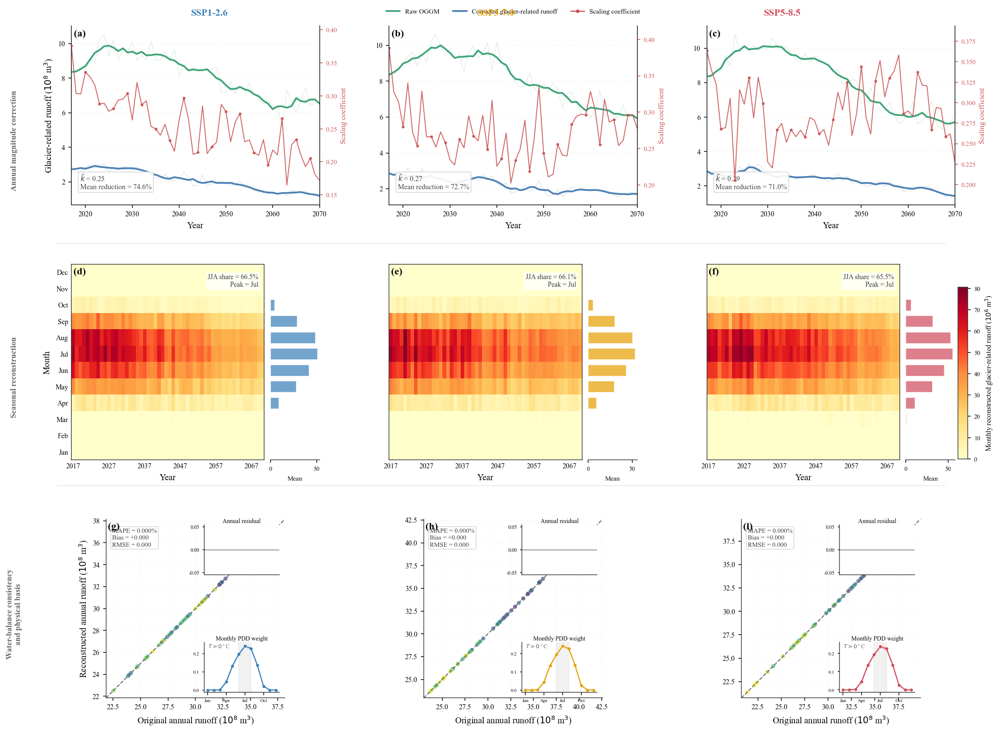


FIG. 4 ENHANCED SUMMARY

SSP1-2.6
  Mean scaling coefficient = 0.254
  Scaling coefficient SD   = 0.045
  Mean reduction           = 74.59%
  MAPE                     = 0.0000%
  RMSE                     = 0.00000 ×10^8 m3
  Bias                     = +0.00000 ×10^8 m3
  JJA share                = 66.52%
  Peak month               = 7

SSP3-7.0
  Mean scaling coefficient = 0.273
  Scaling coefficient SD   = 0.037
  Mean reduction           = 72.69%
  MAPE                     = 0.0000%
  RMSE                     = 0.00000 ×10^8 m3
  Bias                     = +0.00000 ×10^8 m3
  JJA share                = 66.12%
  Peak month               = 7

SSP5-8.5
  Mean scaling coefficient = 0.290
  Scaling coefficient SD   = 0.036
  Mean reduction           = 71.02%
  MAPE                     = 0.0000%
  RMSE                     = 0.00000 ×10^8 m3
  Bias                     = +0.00000 ×10^8 m3
  JJA share                = 65.47%
  Peak month               = 7

Saved:
D:\Python code\boshilunwen\v

In [30]:
# ======================================================================
# Fig. 4
# Enhanced 3 × 3 composite figure
# Hydrologically constrained reconstruction of glacier-related runoff
# under future climate scenarios
#
# Row 1: Annual magnitude correction
#   (a-c) Raw OGGM runoff, corrected glacier-related runoff,
#         annual scaling coefficient, mean k and mean reduction
#
# Row 2: Seasonal reconstruction
#   (d-f) Monthly reconstructed glacier-related runoff heatmaps
#         + marginal monthly climatology
#         + JJA share
#         + peak month
#
# Row 3: Water-balance consistency and physical basis
#   (g-i) Annual 1:1 water-balance consistency
#         + annual residual inset
#         + monthly PDD-weight inset
#
# Existing coupling diagnosis outputs only.
# NO model rerun required.
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

warnings.filterwarnings("ignore")


# ======================================================================
# 1. GLOBAL STYLE
# ======================================================================

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False

mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["savefig.facecolor"] = "white"

mpl.rcParams["font.size"] = 9
mpl.rcParams["axes.labelsize"] = 10
mpl.rcParams["xtick.labelsize"] = 8
mpl.rcParams["ytick.labelsize"] = 8
mpl.rcParams["legend.fontsize"] = 8

mpl.rcParams["axes.linewidth"] = 0.75
mpl.rcParams["xtick.direction"] = "out"
mpl.rcParams["ytick.direction"] = "out"

mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600


# ======================================================================
# 2. PATHS
# ======================================================================

DIAGNOSIS_DIR = (
    r"D:\Python code\boshilunwen\vic\径流重构"
    r"\coupling_diagnosis_ssp585"
)

OUTPUT_DIR = os.path.join(
    DIAGNOSIS_DIR,
    "Fig4_Journal_of_Hydrology_Enhanced"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ======================================================================
# 3. SCENARIOS
# ======================================================================

SCENARIOS = [
    "ssp126",
    "ssp370",
    "ssp585"
]

SCENARIO_LABELS = {
    "ssp126": "SSP1-2.6",
    "ssp370": "SSP3-7.0",
    "ssp585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "ssp126": "#377EB8",
    "ssp370": "#E69F00",
    "ssp585": "#D1495B"
}


# ======================================================================
# 4. COLORS
# ======================================================================

COLOR_RAW = "#43A57A"
COLOR_CORRECTED = "#4E82B4"
COLOR_SCALE = "#C94F4F"

COLOR_RESIDUAL_POS = "#D95F5F"
COLOR_RESIDUAL_NEG = "#4C78A8"

HEATMAP_CMAP = "YlOrRd"


# ======================================================================
# 5. LOAD DATA
# ======================================================================

annual_data = {}
monthly_data = {}

print("=" * 80)
print("Loading coupling-diagnosis datasets")
print("=" * 80)

for scenario in SCENARIOS:

    annual_file = os.path.join(
        DIAGNOSIS_DIR,
        f"annual_coupling_evaluation_{scenario}.csv"
    )

    monthly_file = os.path.join(
        DIAGNOSIS_DIR,
        f"monthly_glacier_process_{scenario}.csv"
    )

    if os.path.exists(annual_file):

        df = pd.read_csv(
            annual_file
        )

        df = (
            df
            .sort_values("year")
            .reset_index(drop=True)
        )

        annual_data[scenario] = df

        print(
            f"{SCENARIO_LABELS[scenario]} annual: "
            f"{df['year'].min()}–{df['year'].max()}, "
            f"n={len(df)}"
        )

    else:

        print(
            f"[Missing annual] {annual_file}"
        )

    if os.path.exists(monthly_file):

        dfm = pd.read_csv(
            monthly_file
        )

        dfm = (
            dfm
            .sort_values(
                ["year", "month"]
            )
            .reset_index(drop=True)
        )

        monthly_data[scenario] = dfm

        print(
            f"{SCENARIO_LABELS[scenario]} monthly: "
            f"n={len(dfm)}"
        )

    else:

        print(
            f"[Missing monthly] {monthly_file}"
        )


# ======================================================================
# 6. CHECK COLUMNS
# ======================================================================

REQUIRED_ANNUAL_COLS = [
    "year",
    "Q_glacier_oggm",
    "Q_glacier_achieved",
    "glacier_scale",
    "Q_total_original",
    "Q_total_new"
]

REQUIRED_MONTHLY_COLS = [
    "year",
    "month",
    "Q_glacier_monthly",
    "monthly_pos_weight"
]

for scenario, df in annual_data.items():

    missing = [
        c for c in REQUIRED_ANNUAL_COLS
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{scenario} annual missing columns: {missing}"
        )


for scenario, df in monthly_data.items():

    missing = [
        c for c in REQUIRED_MONTHLY_COLS
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{scenario} monthly missing columns: {missing}"
        )


# ======================================================================
# 7. SUMMARY STATISTICS
# ======================================================================

summary_stats = {}

for scenario in SCENARIOS:

    if scenario not in annual_data:
        continue

    df = annual_data[scenario]

    # scaling coefficient
    k_mean = df["glacier_scale"].mean()
    k_std = df["glacier_scale"].std()

    # correction magnitude
    valid = (
        np.isfinite(df["Q_glacier_oggm"])
        &
        np.isfinite(df["Q_glacier_achieved"])
        &
        (df["Q_glacier_oggm"] != 0)
    )

    reduction_yearly = (
        1
        -
        df.loc[
            valid,
            "Q_glacier_achieved"
        ]
        /
        df.loc[
            valid,
            "Q_glacier_oggm"
        ]
    ) * 100

    reduction_mean = reduction_yearly.mean()

    # annual total runoff consistency
    x = df["Q_total_original"] / 1e8
    y = df["Q_total_new"] / 1e8

    residual = y - x

    rmse = np.sqrt(
        np.mean(
            residual ** 2
        )
    )

    bias = np.mean(
        residual
    )

    mape = np.mean(
        np.abs(
            (
                df["Q_total_new"]
                -
                df["Q_total_original"]
            )
            /
            df["Q_total_original"]
        )
    ) * 100

    summary_stats[scenario] = {
        "k_mean": k_mean,
        "k_std": k_std,
        "reduction_mean": reduction_mean,
        "rmse": rmse,
        "bias": bias,
        "mape": mape
    }


# ======================================================================
# 8. HEATMAP DATA + GLOBAL COLOR RANGE
# ======================================================================

heatmap_pivots = {}
all_heat_vals = []

for scenario in SCENARIOS:

    if scenario not in monthly_data:
        continue

    dfm = monthly_data[scenario]

    pivot = dfm.pivot(
        index="month",
        columns="year",
        values="Q_glacier_monthly"
    )

    heatmap_pivots[scenario] = pivot

    vals = pivot.values / 1e6

    all_heat_vals.extend(
        vals[np.isfinite(vals)]
    )

HEATMAP_VMIN = np.nanmin(
    all_heat_vals
)

HEATMAP_VMAX = np.nanmax(
    all_heat_vals
)


# ======================================================================
# 9. FIGURE LAYOUT
# ======================================================================

fig = plt.figure(
    figsize=(15.5, 12.0),
    facecolor="white"
)

outer = GridSpec(
    3,
    3,
    figure=fig,

    height_ratios=[
        1.05,
        1.15,
        1.05
    ],

    hspace=0.32,
    wspace=0.28,

    left=0.07,
    right=0.965,
    top=0.95,
    bottom=0.07
)


# ======================================================================
# 10. PANEL LABELS
# ======================================================================

panel_labels = [
    "(a)", "(b)", "(c)",
    "(d)", "(e)", "(f)",
    "(g)", "(h)", "(i)"
]


# ======================================================================
# 11. COLUMN HEADERS
# ======================================================================

for col, scenario in enumerate(SCENARIOS):

    x_center = (
        [0.21, 0.50, 0.79][col]
    )

    fig.text(
        x_center,
        0.972,
        SCENARIO_LABELS[scenario],
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold",
        color=SCENARIO_COLORS[scenario]
    )


# ======================================================================
# 12. ROW LABELS
# ======================================================================

row_texts = [
    "Annual magnitude correction",
    "Seasonal reconstruction",
    "Water-balance consistency\nand physical basis"
]

row_y = [
    0.80,
    0.49,
    0.18
]

for txt, yy in zip(
    row_texts,
    row_y
):

    fig.text(
        0.012,
        yy,
        txt,
        rotation=90,
        ha="center",
        va="center",
        fontsize=9,
        color="0.40",
        fontweight="bold"
    )


# ======================================================================
# 13. ROW 1
# ANNUAL MAGNITUDE CORRECTION
# ======================================================================

row1_axes = []

for col, scenario in enumerate(
    SCENARIOS
):

    ax = fig.add_subplot(
        outer[0, col]
    )

    row1_axes.append(
        ax
    )

    if scenario not in annual_data:
        continue

    df = annual_data[scenario]

    years = df["year"].to_numpy()

    raw = (
        df["Q_glacier_oggm"]
        / 1e8
    )

    corrected = (
        df["Q_glacier_achieved"]
        / 1e8
    )

    raw_smooth = raw.rolling(
        window=5,
        center=True,
        min_periods=2
    ).mean()

    corrected_smooth = corrected.rolling(
        window=5,
        center=True,
        min_periods=2
    ).mean()

    # annual raw
    ax.plot(
        years,
        raw,
        color=COLOR_RAW,
        linewidth=0.55,
        alpha=0.25
    )

    # 5-y smooth raw
    ax.plot(
        years,
        raw_smooth,
        color=COLOR_RAW,
        linewidth=2.0
    )

    # annual corrected
    ax.plot(
        years,
        corrected,
        color=COLOR_CORRECTED,
        linewidth=0.55,
        alpha=0.28
    )

    # 5-y smooth corrected
    ax.plot(
        years,
        corrected_smooth,
        color=COLOR_CORRECTED,
        linewidth=2.0
    )

    # --------------------------------------------------
    # secondary y-axis: scaling coefficient
    # --------------------------------------------------

    ax2 = ax.twinx()

    ax2.plot(
        years,
        df["glacier_scale"],
        color=COLOR_SCALE,
        linewidth=1.05,
        alpha=0.85,
        marker="o",
        markersize=2.2,
        markevery=3
    )

    ax2.set_ylabel(
        "Scaling coefficient",
        color=COLOR_SCALE,
        fontsize=8.5
    )

    ax2.tick_params(
        axis="y",
        colors=COLOR_SCALE,
        labelsize=7.3
    )

    scale_min = df["glacier_scale"].min()
    scale_max = df["glacier_scale"].max()

    pad = max(
        0.03,
        0.10 * (
            scale_max - scale_min
        )
    )

    ax2.set_ylim(
        max(
            0,
            scale_min - pad
        ),
        scale_max + pad
    )

    # --------------------------------------------------
    # statistic annotation
    # --------------------------------------------------

    stat = summary_stats[scenario]

    text_info = (
        r"$\bar{k}$"
        f" = {stat['k_mean']:.2f}\n"
        f"Mean reduction = "
        f"{stat['reduction_mean']:.1f}%"
    )

    ax.text(
        0.035,
        0.08,
        text_info,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=8.1,
        color="0.25",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="0.85",
            alpha=0.90
        )
    )

    # --------------------------------------------------
    # axes
    # --------------------------------------------------

    ax.set_xlim(
        years.min(),
        years.max()
    )

    ax.set_xlabel(
        "Year"
    )

    if col == 0:

        ax.set_ylabel(
            r"Glacier-related runoff ($10^8$ m$^3$)"
        )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.45,
        alpha=0.18
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax2.spines[
        "top"
    ].set_visible(False)

    ax.text(
        0.01,
        0.98,
        panel_labels[col],
        transform=ax.transAxes,
        fontsize=11.5,
        fontweight="bold",
        va="top"
    )


# row-1 legend
legend_handles = [
    Line2D(
        [0],
        [0],
        color=COLOR_RAW,
        linewidth=2.0,
        label="Raw OGGM"
    ),

    Line2D(
        [0],
        [0],
        color=COLOR_CORRECTED,
        linewidth=2.0,
        label="Corrected glacier-related runoff"
    ),

    Line2D(
        [0],
        [0],
        color=COLOR_SCALE,
        linewidth=1.2,
        marker="o",
        markersize=3,
        label="Scaling coefficient"
    )
]

row1_axes[1].legend(
    handles=legend_handles,
    frameon=False,
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        1.13
    ),
    fontsize=7.6
)


# ======================================================================
# 14. ROW 2
# HEATMAP + MARGINAL MONTHLY CLIMATOLOGY
# ======================================================================

last_im = None

for col, scenario in enumerate(
    SCENARIOS
):

    # each cell is split into:
    # heatmap + marginal climatology
    sub = GridSpecFromSubplotSpec(
        1,
        2,
        subplot_spec=outer[1, col],
        width_ratios=[
            4.5,
            1.15
        ],
        wspace=0.05
    )

    ax_heat = fig.add_subplot(
        sub[0, 0]
    )

    ax_side = fig.add_subplot(
        sub[0, 1],
        sharey=ax_heat
    )

    if scenario not in heatmap_pivots:
        continue

    pivot = heatmap_pivots[
        scenario
    ]

    values = pivot.values / 1e6

    last_im = ax_heat.imshow(
        values,
        aspect="auto",
        origin="lower",
        cmap=HEATMAP_CMAP,
        vmin=HEATMAP_VMIN,
        vmax=HEATMAP_VMAX,
        interpolation="nearest"
    )

    # --------------------------------------------------
    # heatmap axes
    # --------------------------------------------------

    years = list(
        pivot.columns
    )

    step = max(
        1,
        len(years) // 5
    )

    tick_idx = np.arange(
        0,
        len(years),
        step
    )

    ax_heat.set_xticks(
        tick_idx
    )

    ax_heat.set_xticklabels(
        [
            years[i]
            for i in tick_idx
        ]
    )

    months_present = list(
        pivot.index
    )

    ax_heat.set_yticks(
        np.arange(
            len(months_present)
        )
    )

    month_labels_full = [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]

    if col == 0:

        ax_heat.set_yticklabels(
            [
                month_labels_full[
                    int(m) - 1
                ]
                for m in months_present
            ]
        )

        ax_heat.set_ylabel(
            "Month"
        )

    else:

        ax_heat.set_yticklabels(
            []
        )

    ax_heat.set_xlabel(
        "Year"
    )

    ax_heat.tick_params(
        length=0
    )

    # --------------------------------------------------
    # marginal climatology
    # --------------------------------------------------

    month_mean = np.nanmean(
        values,
        axis=1
    )

    y_month = np.arange(
        len(month_mean)
    )

    ax_side.barh(
        y_month,
        month_mean,
        height=0.68,
        color=SCENARIO_COLORS[
            scenario
        ],
        alpha=0.70,
        edgecolor="white",
        linewidth=0.3
    )

    ax_side.set_xlabel(
        "Mean",
        fontsize=7.5
    )

    ax_side.tick_params(
        axis="x",
        labelsize=6.8
    )

    ax_side.tick_params(
        axis="y",
        left=False,
        labelleft=False
    )

    ax_side.spines[
        "top"
    ].set_visible(False)

    ax_side.spines[
        "right"
    ].set_visible(False)

    ax_side.spines[
        "left"
    ].set_visible(False)

    # --------------------------------------------------
    # JJA share
    # --------------------------------------------------

    if scenario in monthly_data:

        dfm = monthly_data[
            scenario
        ]

        annual_month = (
            dfm
            .groupby(
                ["year", "month"]
            )[
                "Q_glacier_monthly"
            ]
            .sum()
            .reset_index()
        )

        annual_total = (
            annual_month
            .groupby("year")[
                "Q_glacier_monthly"
            ]
            .sum()
        )

        jja_total = (
            annual_month[
                annual_month[
                    "month"
                ].isin(
                    [6, 7, 8]
                )
            ]
            .groupby("year")[
                "Q_glacier_monthly"
            ]
            .sum()
        )

        common = (
            annual_total.index
            .intersection(
                jja_total.index
            )
        )

        jja_share = (
            jja_total.loc[
                common
            ]
            /
            annual_total.loc[
                common
            ]
            *
            100
        ).mean()

        monthly_clim = (
            dfm
            .groupby("month")[
                "Q_glacier_monthly"
            ]
            .mean()
        )

        peak_month = int(
            monthly_clim.idxmax()
        )

        ax_heat.text(
            0.97,
            0.95,
            (
                f"JJA share = "
                f"{jja_share:.1f}%\n"
                f"Peak = "
                f"{month_labels_full[peak_month - 1]}"
            ),
            transform=ax_heat.transAxes,
            ha="right",
            va="top",
            fontsize=7.7,
            color="0.20",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="none",
                alpha=0.82
            )
        )

    ax_heat.text(
        0.01,
        0.98,
        panel_labels[
            3 + col
        ],
        transform=ax_heat.transAxes,
        fontsize=11.5,
        fontweight="bold",
        va="top"
    )


# --------------------------------------------------
# common colorbar
# --------------------------------------------------

if last_im is not None:

    cax = fig.add_axes(
        [
            0.968,
            0.383,
            0.010,
            0.225
        ]
    )

    cbar = fig.colorbar(
        last_im,
        cax=cax
    )

    cbar.set_label(
        r"Monthly reconstructed glacier-related runoff "
        r"($10^6$ m$^3$)",
        fontsize=8.0
    )

    cbar.ax.tick_params(
        labelsize=7
    )


# ======================================================================
# 15. ROW 3
# 1:1 + RESIDUAL INSET + PDD-WEIGHT INSET
# ======================================================================

for col, scenario in enumerate(
    SCENARIOS
):

    ax = fig.add_subplot(
        outer[2, col]
    )

    if scenario not in annual_data:
        continue

    df = annual_data[
        scenario
    ]

    x = (
        df["Q_total_original"]
        / 1e8
    )

    y = (
        df["Q_total_new"]
        / 1e8
    )

    years = df[
        "year"
    ].to_numpy()

    # --------------------------------------------------
    # main 1:1 scatter
    # --------------------------------------------------

    sc = ax.scatter(
        x,
        y,
        c=years,
        cmap="viridis",
        s=24,
        alpha=0.68,
        edgecolor="white",
        linewidth=0.35
    )

    all_vals = np.concatenate(
        [
            x.to_numpy(),
            y.to_numpy()
        ]
    )

    min_val = (
        np.nanmin(
            all_vals
        )
        * 0.97
    )

    max_val = (
        np.nanmax(
            all_vals
        )
        * 1.03
    )

    ax.plot(
        [
            min_val,
            max_val
        ],
        [
            min_val,
            max_val
        ],
        "--",
        color="0.42",
        linewidth=1.1
    )

    ax.set_xlim(
        min_val,
        max_val
    )

    ax.set_ylim(
        min_val,
        max_val
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.set_xlabel(
        r"Original annual runoff ($10^8$ m$^3$)"
    )

    if col == 0:

        ax.set_ylabel(
            r"Reconstructed annual runoff ($10^8$ m$^3$)"
        )

    ax.grid(
        linestyle="--",
        linewidth=0.4,
        alpha=0.16
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    # --------------------------------------------------
    # statistics annotation
    # --------------------------------------------------

    stat = summary_stats[
        scenario
    ]

    ax.text(
        0.035,
        0.95,
        (
            f"MAPE = "
            f"{stat['mape']:.3f}%\n"
            f"Bias = "
            f"{stat['bias']:+.3f}\n"
            f"RMSE = "
            f"{stat['rmse']:.3f}"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=7.3,
        color="0.22",
        bbox=dict(
            boxstyle="round,pad=0.22",
            facecolor="white",
            edgecolor="0.85",
            alpha=0.88
        )
    )

    # --------------------------------------------------
    # residual inset
    # --------------------------------------------------

    ax_res = inset_axes(
        ax,
        width="42%",
        height="28%",
        loc="upper right",
        borderpad=0.8
    )

    residual = (
        df["Q_total_new"]
        -
        df["Q_total_original"]
    ) / 1e8

    pos = residual >= 0

    ax_res.bar(
        years[pos],
        residual[pos],
        width=0.7,
        color=COLOR_RESIDUAL_POS,
        alpha=0.65
    )

    ax_res.bar(
        years[~pos],
        residual[~pos],
        width=0.7,
        color=COLOR_RESIDUAL_NEG,
        alpha=0.65
    )

    ax_res.axhline(
        0,
        color="0.30",
        linewidth=0.6
    )

    ax_res.set_title(
        "Annual residual",
        fontsize=6.8,
        pad=2
    )

    ax_res.tick_params(
        axis="both",
        labelsize=5.8,
        length=2
    )

    ax_res.set_xticks(
        []
    )

    ax_res.spines[
        "top"
    ].set_visible(False)

    ax_res.spines[
        "right"
    ].set_visible(False)

    # --------------------------------------------------
    # PDD weight inset
    # --------------------------------------------------

    if scenario in monthly_data:

        dfm = monthly_data[
            scenario
        ]

        pdd_stats = (
            dfm
            .groupby("month")[
                "monthly_pos_weight"
            ]
            .agg(
                ["mean", "std"]
            )
            .reindex(
                np.arange(
                    1,
                    13
                )
            )
        )

        mean_w = pdd_stats[
            "mean"
        ]

        std_w = pdd_stats[
            "std"
        ].fillna(0)

        ax_pdd = inset_axes(
            ax,
            width="42%",
            height="28%",
            loc="lower right",
            borderpad=0.8
        )

        months = np.arange(
            1,
            13
        )

        ax_pdd.plot(
            months,
            mean_w,
            color=SCENARIO_COLORS[
                scenario
            ],
            linewidth=1.2,
            marker="o",
            markersize=2.3
        )

        ax_pdd.fill_between(
            months,
            mean_w - std_w,
            mean_w + std_w,
            color=SCENARIO_COLORS[
                scenario
            ],
            alpha=0.12,
            linewidth=0
        )

        peak_m = int(
            mean_w.idxmax()
        )

        peak_v = float(
            mean_w.max()
        )

        ax_pdd.scatter(
            peak_m,
            peak_v,
            s=16,
            color=SCENARIO_COLORS[
                scenario
            ],
            edgecolor="white",
            linewidth=0.4,
            zorder=5
        )

        ax_pdd.axvspan(
            6,
            8,
            color="0.88",
            alpha=0.45,
            zorder=0
        )

        ax_pdd.set_title(
            "Monthly PDD weight",
            fontsize=6.8,
            pad=2
        )

        ax_pdd.set_xticks(
            [
                1,
                4,
                7,
                10
            ]
        )

        ax_pdd.set_xticklabels(
            [
                "Jan",
                "Apr",
                "Jul",
                "Oct"
            ],
            fontsize=5.6
        )

        ax_pdd.tick_params(
            axis="y",
            labelsize=5.6,
            length=2
        )

        ax_pdd.spines[
            "top"
        ].set_visible(False)

        ax_pdd.spines[
            "right"
        ].set_visible(False)

        ax_pdd.text(
            0.05,
            0.88,
            r"$T>0^\circ$C",
            transform=ax_pdd.transAxes,
            fontsize=6.2,
            color="0.35"
        )

    # --------------------------------------------------
    # panel label
    # --------------------------------------------------

    ax.text(
        0.01,
        0.98,
        panel_labels[
            6 + col
        ],
        transform=ax.transAxes,
        fontsize=11.5,
        fontweight="bold",
        va="top"
    )


# ======================================================================
# 16. OPTIONAL SUBTLE ROW DIVIDERS
# ======================================================================

fig.add_artist(
    Line2D(
        [
            0.055,
            0.955
        ],
        [
            0.665,
            0.665
        ],
        transform=fig.transFigure,
        color="0.90",
        linewidth=0.8
    )
)

fig.add_artist(
    Line2D(
        [
            0.055,
            0.955
        ],
        [
            0.348,
            0.348
        ],
        transform=fig.transFigure,
        color="0.90",
        linewidth=0.8
    )
)


# ======================================================================
# 17. SAVE
# ======================================================================

png_path = os.path.join(
    OUTPUT_DIR,
    "Fig4_Enhanced_3x3_Composite.png"
)

pdf_path = os.path.join(
    OUTPUT_DIR,
    "Fig4_Enhanced_3x3_Composite.pdf"
)

svg_path = os.path.join(
    OUTPUT_DIR,
    "Fig4_Enhanced_3x3_Composite.svg"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ======================================================================
# 18. PRINT SUMMARY
# ======================================================================

print("\n" + "=" * 80)
print("FIG. 4 ENHANCED SUMMARY")
print("=" * 80)

for scenario in SCENARIOS:

    if scenario not in summary_stats:
        continue

    stat = summary_stats[
        scenario
    ]

    print(
        f"\n{SCENARIO_LABELS[scenario]}"
    )

    print(
        f"  Mean scaling coefficient = "
        f"{stat['k_mean']:.3f}"
    )

    print(
        f"  Scaling coefficient SD   = "
        f"{stat['k_std']:.3f}"
    )

    print(
        f"  Mean reduction           = "
        f"{stat['reduction_mean']:.2f}%"
    )

    print(
        f"  MAPE                     = "
        f"{stat['mape']:.4f}%"
    )

    print(
        f"  RMSE                     = "
        f"{stat['rmse']:.5f} ×10^8 m3"
    )

    print(
        f"  Bias                     = "
        f"{stat['bias']:+.5f} ×10^8 m3"
    )

    # seasonal diagnostics
    if scenario in monthly_data:

        dfm = monthly_data[
            scenario
        ]

        annual_month = (
            dfm
            .groupby(
                ["year", "month"]
            )[
                "Q_glacier_monthly"
            ]
            .sum()
            .reset_index()
        )

        annual_total = (
            annual_month
            .groupby("year")[
                "Q_glacier_monthly"
            ]
            .sum()
        )

        jja_total = (
            annual_month[
                annual_month[
                    "month"
                ].isin(
                    [6, 7, 8]
                )
            ]
            .groupby("year")[
                "Q_glacier_monthly"
            ]
            .sum()
        )

        common = (
            annual_total.index
            .intersection(
                jja_total.index
            )
        )

        jja_share = (
            jja_total.loc[
                common
            ]
            /
            annual_total.loc[
                common
            ]
            *
            100
        ).mean()

        clim = (
            dfm
            .groupby("month")[
                "Q_glacier_monthly"
            ]
            .mean()
        )

        peak_month = int(
            clim.idxmax()
        )

        print(
            f"  JJA share                = "
            f"{jja_share:.2f}%"
        )

        print(
            f"  Peak month               = "
            f"{peak_month}"
        )

print("\nSaved:")
print(png_path)
print(pdf_path)
print(svg_path)

print("\nDone.")

Loading coupling datasets
✓ SSP1-2.6 annual: 2017–2070
✓ SSP1-2.6 monthly: 648 rows
✓ SSP3-7.0 annual: 2017–2070
✓ SSP3-7.0 monthly: 648 rows
✓ SSP5-8.5 annual: 2017–2070
✓ SSP5-8.5 monthly: 648 rows
✓ SSP1-2.6 daily: 19723 rows
✓ SSP3-7.0 daily: 19723 rows
✓ SSP5-8.5 daily: 19723 rows


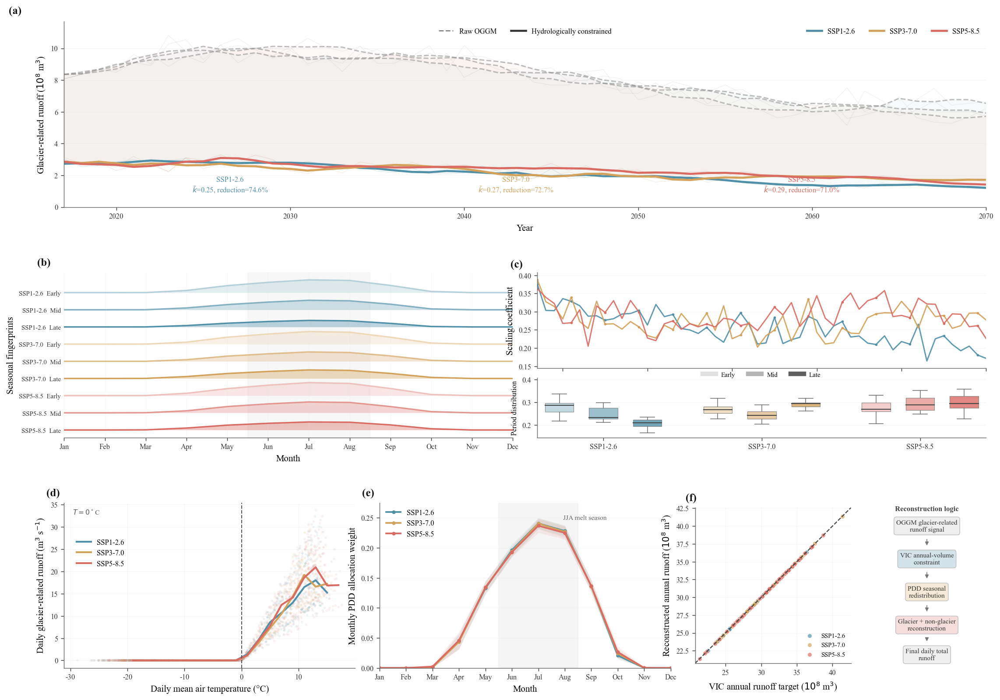


FIG. 4 SUMMARY

SSP1-2.6
  mean scaling coefficient = 0.254
  SD scaling coefficient   = 0.045
  mean correction          = 74.59%

SSP3-7.0
  mean scaling coefficient = 0.273
  SD scaling coefficient   = 0.037
  mean correction          = 72.69%

SSP5-8.5
  mean scaling coefficient = 0.290
  SD scaling coefficient   = 0.036
  mean correction          = 71.02%

Saved:
D:\博士论文\小论文3\图片\Fig4_Reconstructed_Composite.png
D:\博士论文\小论文3\图片\Fig4_Reconstructed_Composite.pdf
D:\博士论文\小论文3\图片\Fig4_Reconstructed_Composite.svg

Done.


In [33]:
# ======================================================================
# Fig. 4
# Journal of Hydrology-style composite figure
#
# Hydrologically constrained reconstruction of glacier-related runoff
# under future climate scenarios
#
# (a) Annual OGGM raw vs hydrologically constrained runoff
# (b) Seasonal fingerprints: Early / Mid / Late
# (c) Scaling coefficient evolution + period distribution
# (d) Temperature-runoff physical consistency
# (e) Monthly PDD allocation weights
# (f) Annual water-balance consistency + reconstruction schematic
#
# No model rerun required.
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import to_rgb

warnings.filterwarnings("ignore")


# ======================================================================
# 1. PATHS
# ======================================================================

DIAGNOSIS_DIR = (
    r"D:\Python code\boshilunwen\vic\径流重构"
    r"\coupling_diagnosis_ssp585"
)

DAILY_DIR = r"D:\Python code\boshilunwen\vic\径流重构"

OUTPUT_DIR = r"D:\博士论文\小论文3\图片"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ======================================================================
# 2. GLOBAL STYLE
# ======================================================================

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False

mpl.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "axes.linewidth": 0.75,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "xtick.major.size": 3.2,
    "ytick.major.size": 3.2,

    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,

    "figure.dpi": 150,
    "savefig.dpi": 600,
})


# ======================================================================
# 3. SCENARIOS
# ======================================================================

SCENARIOS = [
    "ssp126",
    "ssp370",
    "ssp585"
]

SCENARIO_LABELS = {
    "ssp126": "SSP1-2.6",
    "ssp370": "SSP3-7.0",
    "ssp585": "SSP5-8.5"
}


# ======================================================================
# 4. SEA-SALT → CORAL PALETTE
# ======================================================================

SSP_COLORS = {
    "ssp126": "#4F8FA8",   # sea-salt blue
    "ssp370": "#D3A15A",   # warm sand
    "ssp585": "#D96B62",   # coral
}

COLOR_RAW = "#8A8A8A"
COLOR_SCALE = "#404040"

COLOR_GRID = "#E2E2E2"
COLOR_SPINE = "#666666"
COLOR_TEXT = "#303030"

JJA_FACE = "#F1F1F1"


# ======================================================================
# 5. PERIODS
# ======================================================================

PERIODS = {
    "Early": (2020, 2040),
    "Mid":   (2041, 2055),
    "Late":  (2056, 2070)
}


# ======================================================================
# 6. HELPERS
# ======================================================================

def clean_axis(ax):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color(COLOR_SPINE)
    ax.spines["bottom"].set_color(COLOR_SPINE)

    ax.spines["left"].set_linewidth(0.7)
    ax.spines["bottom"].set_linewidth(0.7)

    ax.tick_params(colors="#333333")


def add_panel_label(ax, label):

    ax.text(
        -0.06,
        1.03,
        label,

        transform=ax.transAxes,

        fontsize=12,
        fontweight="bold",

        ha="left",
        va="bottom",

        color="#111111",

        clip_on=False
    )


def moving_average(series, window=5):

    return series.rolling(
        window=window,
        center=True,
        min_periods=2
    ).mean()


def mix_with_white(color, amount):

    rgb = np.array(
        to_rgb(color)
    )

    white = np.ones(3)

    return tuple(
        rgb * (1 - amount)
        +
        white * amount
    )


def get_period_colors(base_color):

    return {
        "Early": mix_with_white(base_color, 0.58),
        "Mid":   mix_with_white(base_color, 0.30),
        "Late":  base_color
    }


# ======================================================================
# 7. LOAD ANNUAL + MONTHLY COUPLING DATA
# ======================================================================

annual_data = {}
monthly_data = {}

print("=" * 80)
print("Loading coupling datasets")
print("=" * 80)

for scenario in SCENARIOS:

    annual_file = os.path.join(
        DIAGNOSIS_DIR,
        f"annual_coupling_evaluation_{scenario}.csv"
    )

    monthly_file = os.path.join(
        DIAGNOSIS_DIR,
        f"monthly_glacier_process_{scenario}.csv"
    )

    if os.path.exists(annual_file):

        df = pd.read_csv(
            annual_file
        )

        df = (
            df
            .sort_values("year")
            .reset_index(drop=True)
        )

        annual_data[
            scenario
        ] = df

        print(
            f"✓ {SCENARIO_LABELS[scenario]} annual: "
            f"{df['year'].min()}–{df['year'].max()}"
        )

    else:

        print(
            f"✗ Missing annual: {annual_file}"
        )

    if os.path.exists(monthly_file):

        dfm = pd.read_csv(
            monthly_file
        )

        dfm = (
            dfm
            .sort_values(
                [
                    "year",
                    "month"
                ]
            )
            .reset_index(drop=True)
        )

        monthly_data[
            scenario
        ] = dfm

        print(
            f"✓ {SCENARIO_LABELS[scenario]} monthly: "
            f"{len(dfm)} rows"
        )

    else:

        print(
            f"✗ Missing monthly: {monthly_file}"
        )


# ======================================================================
# 8. LOAD DAILY RECONSTRUCTED DATA
#    Used only for temperature-runoff physical consistency panel
# ======================================================================

daily_data = {}

for scenario in SCENARIOS:

    daily_file = os.path.join(
        DAILY_DIR,
        f"daily_runoff_reconstructed_{scenario}_2017_2070.csv"
    )

    if os.path.exists(
        daily_file
    ):

        dfd = pd.read_csv(
            daily_file
        )

        dfd["date"] = pd.to_datetime(
            dfd["date"]
        )

        dfd = (
            dfd
            .sort_values("date")
            .reset_index(drop=True)
        )

        daily_data[
            scenario
        ] = dfd

        print(
            f"✓ {SCENARIO_LABELS[scenario]} daily: "
            f"{len(dfd)} rows"
        )

    else:

        print(
            f"✗ Missing daily: {daily_file}"
        )


# ======================================================================
# 9. BASIC CHECKS
# ======================================================================

required_annual = [
    "year",
    "Q_glacier_oggm",
    "Q_glacier_achieved",
    "glacier_scale",
    "Q_total_original",
    "Q_total_new"
]

required_monthly = [
    "year",
    "month",
    "Q_glacier_monthly",
    "monthly_pos_weight"
]

required_daily = [
    "year",
    "month",
    "T_air",
    "Q_glacier"
]


for scenario, df in annual_data.items():

    missing = [
        c for c in required_annual
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{scenario} annual missing: {missing}"
        )


for scenario, df in monthly_data.items():

    missing = [
        c for c in required_monthly
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{scenario} monthly missing: {missing}"
        )


for scenario, df in daily_data.items():

    missing = [
        c for c in required_daily
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{scenario} daily missing: {missing}"
        )


# ======================================================================
# 10. SUMMARY STATISTICS
# ======================================================================

summary_stats = {}

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    valid = (
        np.isfinite(
            df["Q_glacier_oggm"]
        )
        &
        (
            df["Q_glacier_oggm"]
            != 0
        )
    )

    reduction = (
        1
        -
        df.loc[
            valid,
            "Q_glacier_achieved"
        ]
        /
        df.loc[
            valid,
            "Q_glacier_oggm"
        ]
    ) * 100

    summary_stats[
        scenario
    ] = {
        "k_mean":
            df[
                "glacier_scale"
            ].mean(),

        "k_std":
            df[
                "glacier_scale"
            ].std(),

        "reduction":
            reduction.mean()
    }


# ======================================================================
# 11. SEASONAL PROFILES
# ======================================================================

seasonal_profiles = {}

seasonal_max = 0

for scenario in SCENARIOS:

    dfm = monthly_data[
        scenario
    ]

    seasonal_profiles[
        scenario
    ] = {}

    for period_name, (
        start_year,
        end_year
    ) in PERIODS.items():

        sub = dfm[
            (
                dfm["year"]
                >=
                start_year
            )
            &
            (
                dfm["year"]
                <=
                end_year
            )
        ]

        month_year = (
            sub
            .groupby(
                [
                    "year",
                    "month"
                ]
            )[
                "Q_glacier_monthly"
            ]
            .sum()
            .reset_index()
        )

        profile = (
            month_year
            .groupby(
                "month"
            )[
                "Q_glacier_monthly"
            ]
            .agg(
                [
                    "mean",
                    "std"
                ]
            )
            /
            1e6
        )

        profile = profile.reindex(
            np.arange(
                1,
                13
            )
        )

        seasonal_profiles[
            scenario
        ][
            period_name
        ] = profile

        seasonal_max = max(
            seasonal_max,
            np.nanmax(
                profile[
                    "mean"
                ]
                +
                profile[
                    "std"
                ].fillna(0)
            )
        )


# ======================================================================
# 12. SCALING COEFFICIENT PERIOD DISTRIBUTIONS
# ======================================================================

scale_period_values = {}

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    scale_period_values[
        scenario
    ] = {}

    for period_name, (
        start_year,
        end_year
    ) in PERIODS.items():

        vals = df.loc[
            (
                df["year"]
                >=
                start_year
            )
            &
            (
                df["year"]
                <=
                end_year
            ),
            "glacier_scale"
        ].dropna()

        scale_period_values[
            scenario
        ][
            period_name
        ] = vals.values


# ======================================================================
# 13. PDD PROFILES
# ======================================================================

pdd_profiles = {}

PDD_MAX = 0

for scenario in SCENARIOS:

    stat = (
        monthly_data[
            scenario
        ]
        .groupby(
            "month"
        )[
            "monthly_pos_weight"
        ]
        .agg(
            [
                "mean",
                "std"
            ]
        )
        .reindex(
            np.arange(
                1,
                13
            )
        )
    )

    pdd_profiles[
        scenario
    ] = stat

    PDD_MAX = max(
        PDD_MAX,
        np.nanmax(
            stat[
                "mean"
            ]
            +
            stat[
                "std"
            ].fillna(0)
        )
    )


# ======================================================================
# 14. COMMON LIMITS
# ======================================================================

# annual raw + corrected
ANNUAL_YMAX = 0

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    temp = np.nanmax(
        df[
            [
                "Q_glacier_oggm",
                "Q_glacier_achieved"
            ]
        ].values
    ) / 1e8

    ANNUAL_YMAX = max(
        ANNUAL_YMAX,
        temp
    )

ANNUAL_YMAX *= 1.08


# scaling range
all_scale = np.concatenate([
    annual_data[s]["glacier_scale"].dropna().values
    for s in SCENARIOS
])

SCALE_MIN = max(
    0,
    np.nanmin(all_scale) - 0.02
)

SCALE_MAX = np.nanmax(
    all_scale
) + 0.02


# balance limits
balance_values = []

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    balance_values.extend(
        (
            df[
                "Q_total_original"
            ]
            /
            1e8
        ).tolist()
    )

    balance_values.extend(
        (
            df[
                "Q_total_new"
            ]
            /
            1e8
        ).tolist()
    )

BALANCE_MIN = (
    np.nanmin(
        balance_values
    )
    *
    0.97
)

BALANCE_MAX = (
    np.nanmax(
        balance_values
    )
    *
    1.03
)


# ======================================================================
# 15. FIGURE LAYOUT
# ======================================================================

fig = plt.figure(
    figsize=(
        15.6,
        11.2
    ),
    facecolor="white"
)

outer = GridSpec(
    3,
    12,
    figure=fig,

    height_ratios=[
        1.18,
        1.05,
        1.05
    ],

    hspace=0.38,
    wspace=0.45,

    left=0.065,
    right=0.965,

    bottom=0.065,
    top=0.945
)


# ======================================================================
# 16. PANEL (a)
# Annual correction trajectories
# ======================================================================

ax_a = fig.add_subplot(
    outer[
        0,
        :
    ]
)

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    years = df[
        "year"
    ]

    raw = (
        df[
            "Q_glacier_oggm"
        ]
        /
        1e8
    )

    corrected = (
        df[
            "Q_glacier_achieved"
        ]
        /
        1e8
    )

    raw_ma = moving_average(
        raw
    )

    corrected_ma = moving_average(
        corrected
    )

    # raw annual, very light
    ax_a.plot(
        years,
        raw,
        color=COLOR_RAW,
        linewidth=0.45,
        alpha=0.16
    )

    # raw moving mean
    ax_a.plot(
        years,
        raw_ma,
        color=COLOR_RAW,
        linestyle="--",
        linewidth=1.45,
        alpha=0.55
    )

    # corrected annual
    ax_a.plot(
        years,
        corrected,
        color=color,
        linewidth=0.55,
        alpha=0.20
    )

    # corrected moving mean
    ax_a.plot(
        years,
        corrected_ma,
        color=color,
        linewidth=2.3,
        label=SCENARIO_LABELS[
            scenario
        ]
    )

    # difference ribbon
    ax_a.fill_between(
        years,
        corrected_ma,
        raw_ma,
        color=color,
        alpha=0.045,
        linewidth=0
    )


ax_a.set_xlim(
    2017,
    2070
)

ax_a.set_ylim(
    0,
    ANNUAL_YMAX
)

ax_a.set_xlabel(
    "Year"
)

ax_a.set_ylabel(
    r"Glacier-related runoff ($10^8$ m$^3$)"
)

ax_a.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.45
)

clean_axis(
    ax_a
)

add_panel_label(
    ax_a,
    "(a)"
)

# legends
scenario_handles = [
    Line2D(
        [0],
        [0],
        color=SSP_COLORS[s],
        linewidth=2.3,
        label=SCENARIO_LABELS[s]
    )
    for s in SCENARIOS
]

style_handles = [
    Line2D(
        [0],
        [0],
        color=COLOR_RAW,
        linestyle="--",
        linewidth=1.4,
        label="Raw OGGM"
    ),

    Line2D(
        [0],
        [0],
        color="#333333",
        linewidth=2.2,
        label="Hydrologically constrained"
    )
]

legend1 = ax_a.legend(
    handles=scenario_handles,
    ncol=3,
    frameon=False,
    loc="upper right"
)

ax_a.add_artist(
    legend1
)

ax_a.legend(
    handles=style_handles,
    ncol=2,
    frameon=False,
    loc="upper center"
)

# scaling summary labels
x_positions = [
    0.18,
    0.49,
    0.80
]

for xpos, scenario in zip(
    x_positions,
    SCENARIOS
):

    s = summary_stats[
        scenario
    ]

    ax_a.text(
        xpos,
        0.07,

        (
            f"{SCENARIO_LABELS[scenario]}\n"
            r"$\bar{k}$"
            f"={s['k_mean']:.2f}, "
            f"reduction={s['reduction']:.1f}%"
        ),

        transform=ax_a.transAxes,

        ha="center",
        va="bottom",

        fontsize=8,

        color=SSP_COLORS[
            scenario
        ]
    )


# ======================================================================
# 17. PANEL (b)
# Seasonal fingerprints / ridgeline
# ======================================================================

ax_b = fig.add_subplot(
    outer[
        1,
        :6
    ]
)

months = np.arange(
    1,
    13
)

month_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec"
]

# 9 ridgelines:
# each profile normalized within its own row to emphasize shape
# baseline positions
ridge_gap = 1.0

row_index = 0

ytick_positions = []
ytick_labels = []

for scenario in SCENARIOS:

    period_colors = get_period_colors(
        SSP_COLORS[
            scenario
        ]
    )

    for period_name in [
        "Early",
        "Mid",
        "Late"
    ]:

        stat = seasonal_profiles[
            scenario
        ][
            period_name
        ]

        mean = stat[
            "mean"
        ].values

        baseline = (
            8 - row_index
        ) * ridge_gap

        # normalized vertical relief
        norm = (
            mean
            /
            seasonal_max
            *
            0.85
        )

        ax_b.fill_between(
            months,
            baseline,
            baseline + norm,
            color=period_colors[
                period_name
            ],
            alpha=0.38,
            linewidth=0
        )

        ax_b.plot(
            months,
            baseline + norm,
            color=period_colors[
                period_name
            ],
            linewidth=1.6
        )

        ytick_positions.append(
            baseline
        )

        ytick_labels.append(
            f"{SCENARIO_LABELS[scenario]}  {period_name}"
        )

        row_index += 1


ax_b.axvspan(
    5.5,
    8.5,
    color=JJA_FACE,
    alpha=0.55,
    zorder=0
)

ax_b.set_xlim(
    1,
    12
)

ax_b.set_xticks(
    months
)

ax_b.set_xticklabels(
    month_labels
)

ax_b.set_yticks(
    ytick_positions
)

ax_b.set_yticklabels(
    ytick_labels,
    fontsize=7.2
)

ax_b.set_xlabel(
    "Month"
)

ax_b.set_ylabel(
    "Seasonal fingerprints"
)

ax_b.grid(
    axis="x",
    color=COLOR_GRID,
    linewidth=0.4,
    alpha=0.35
)

clean_axis(
    ax_b
)

ax_b.spines[
    "left"
].set_visible(
    False
)

ax_b.tick_params(
    axis="y",
    length=0
)

add_panel_label(
    ax_b,
    "(b)"
)


# ======================================================================
# 18. PANEL (c)
# Scaling coefficient evolution + period distribution
# ======================================================================

cell_c = GridSpecFromSubplotSpec(
    2,
    1,
    subplot_spec=outer[
        1,
        6:
    ],
    height_ratios=[
        1.6,
        1.0
    ],
    hspace=0.12
)

ax_c1 = fig.add_subplot(
    cell_c[
        0,
        0
    ]
)

ax_c2 = fig.add_subplot(
    cell_c[
        1,
        0
    ]
)


# ---- upper: annual trajectories

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    ax_c1.plot(
        df["year"],
        df["glacier_scale"],
        color=color,
        linewidth=1.4,
        alpha=0.90
    )

    ax_c1.scatter(
        df["year"].values[
            ::4
        ],
        df["glacier_scale"].values[
            ::4
        ],
        color=color,
        s=9,
        edgecolor="white",
        linewidth=0.3
    )


ax_c1.set_xlim(
    2017,
    2070
)

ax_c1.set_ylim(
    SCALE_MIN,
    SCALE_MAX
)

ax_c1.set_ylabel(
    "Scaling coefficient"
)

ax_c1.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.40
)

clean_axis(
    ax_c1
)

ax_c1.set_xticklabels(
    []
)

add_panel_label(
    ax_c1,
    "(c)"
)


# ---- lower: box distribution Early/Mid/Late

positions = []
box_data = []
box_colors = []

xpos = 1

for scenario in SCENARIOS:

    base = SSP_COLORS[
        scenario
    ]

    period_colors = get_period_colors(
        base
    )

    for period_name in [
        "Early",
        "Mid",
        "Late"
    ]:

        vals = scale_period_values[
            scenario
        ][
            period_name
        ]

        box_data.append(
            vals
        )

        positions.append(
            xpos
        )

        box_colors.append(
            period_colors[
                period_name
            ]
        )

        xpos += 1

    xpos += 0.6


bp = ax_c2.boxplot(
    box_data,
    positions=positions,
    widths=0.65,
    patch_artist=True,
    showfliers=False,

    medianprops=dict(
        color="#444444",
        linewidth=1.0
    ),

    whiskerprops=dict(
        color="#777777",
        linewidth=0.8
    ),

    capprops=dict(
        color="#777777",
        linewidth=0.8
    )
)

for patch, color in zip(
    bp[
        "boxes"
    ],
    box_colors
):

    patch.set_facecolor(
        color
    )

    patch.set_edgecolor(
        "#777777"
    )

    patch.set_linewidth(
        0.6
    )

    patch.set_alpha(
        0.80
    )


group_centers = [
    np.mean(
        positions[
            0:3
        ]
    ),

    np.mean(
        positions[
            3:6
        ]
    ),

    np.mean(
        positions[
            6:9
        ]
    )
]

ax_c2.set_xticks(
    group_centers
)

ax_c2.set_xticklabels(
    [
        "SSP1-2.6",
        "SSP3-7.0",
        "SSP5-8.5"
    ]
)

ax_c2.set_ylabel(
    "Period distribution",
    fontsize=8
)

ax_c2.set_ylim(
    SCALE_MIN,
    SCALE_MAX
)

clean_axis(
    ax_c2
)

ax_c2.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.4,
    alpha=0.35
)

period_legend = [
    Line2D(
        [0],
        [0],
        color="#AAAAAA",
        linewidth=5,
        alpha=0.35,
        label="Early"
    ),

    Line2D(
        [0],
        [0],
        color="#777777",
        linewidth=5,
        alpha=0.55,
        label="Mid"
    ),

    Line2D(
        [0],
        [0],
        color="#444444",
        linewidth=5,
        alpha=0.85,
        label="Late"
    )
]

ax_c2.legend(
    handles=period_legend,
    frameon=False,
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        1.20
    ),
    fontsize=7.2
)


# ======================================================================
# 19. PANEL (d)
# Temperature-runoff physical consistency
# ======================================================================

ax_d = fig.add_subplot(
    outer[
        2,
        :4
    ]
)

for scenario in SCENARIOS:

    if scenario not in daily_data:
        continue

    df = daily_data[
        scenario
    ]

    # subsample for plotting only
    sample = (
        df
        .iloc[
            ::25
        ]
        .copy()
    )

    temp = sample[
        "T_air"
    ].values

    q = (
        sample[
            "Q_glacier"
        ].values
        /
        86400
    )

    color = SSP_COLORS[
        scenario
    ]

    ax_d.scatter(
        temp,
        q,
        s=7,
        color=color,
        alpha=0.09,
        edgecolors="none"
    )

    # binned trend, more readable than regression
    temp_bins = np.arange(
        -20,
        25,
        2
    )

    centers = (
        temp_bins[
            :-1
        ]
        +
        temp_bins[
            1:
        ]
    ) / 2

    bin_id = np.digitize(
        temp,
        temp_bins
    )

    means = []

    for i in range(
        1,
        len(
            temp_bins
        )
    ):

        vals = q[
            bin_id
            ==
            i
        ]

        if len(vals) >= 5:

            means.append(
                np.nanmedian(
                    vals
                )
            )

        else:

            means.append(
                np.nan
            )

    means = np.array(
        means
    )

    ax_d.plot(
        centers,
        means,
        color=color,
        linewidth=2.0,
        label=SCENARIO_LABELS[
            scenario
        ]
    )


ax_d.axvline(
    0,
    color="#555555",
    linestyle="--",
    linewidth=1.0
)

ax_d.text(
    0.03,
    0.93,
    r"$T=0^\circ$C",
    transform=ax_d.transAxes,
    fontsize=7.5,
    color="#555555"
)

ax_d.set_xlabel(
    "Daily mean air temperature (°C)"
)

ax_d.set_ylabel(
    r"Daily glacier-related runoff (m$^3$ s$^{-1}$)"
)

ax_d.grid(
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.35
)

clean_axis(
    ax_d
)

ax_d.legend(
    frameon=False,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(
        0.02,
        0.82
    )
)

add_panel_label(
    ax_d,
    "(d)"
)


# ======================================================================
# 20. PANEL (e)
# Monthly PDD allocation
# ======================================================================

ax_e = fig.add_subplot(
    outer[
        2,
        4:8
    ]
)

months = np.arange(
    1,
    13
)

ax_e.axvspan(
    5.5,
    8.5,
    color=JJA_FACE,
    alpha=0.70,
    zorder=0
)

for scenario in SCENARIOS:

    stat = pdd_profiles[
        scenario
    ]

    mean = stat[
        "mean"
    ]

    sd = stat[
        "std"
    ].fillna(0)

    color = SSP_COLORS[
        scenario
    ]

    ax_e.fill_between(
        months,
        np.maximum(
            mean - sd,
            0
        ),
        mean + sd,
        color=color,
        alpha=0.10,
        linewidth=0
    )

    ax_e.plot(
        months,
        mean,
        color=color,
        linewidth=1.8,
        marker="o",
        markersize=3,
        label=SCENARIO_LABELS[
            scenario
        ]
    )


ax_e.set_xlim(
    1,
    12
)

ax_e.set_ylim(
    0,
    PDD_MAX
    *
    1.10
)

ax_e.set_xticks(
    months
)

ax_e.set_xticklabels(
    month_labels
)

ax_e.set_xlabel(
    "Month"
)

ax_e.set_ylabel(
    "Monthly PDD allocation weight"
)

ax_e.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.35
)

clean_axis(
    ax_e
)

ax_e.legend(
    frameon=False,
    ncol=1,
    loc="upper left"
)

ax_e.text(
    0.63,
    0.90,
    "JJA melt season",
    transform=ax_e.transAxes,
    fontsize=7.5,
    color="#666666"
)

add_panel_label(
    ax_e,
    "(e)"
)


# ======================================================================
# 21. PANEL (f)
# Combined 1:1 water-balance consistency + schematic
# ======================================================================

cell_f = GridSpecFromSubplotSpec(
    1,
    2,
    subplot_spec=outer[
        2,
        8:
    ],
    width_ratios=[
        1.25,
        0.95
    ],
    wspace=0.12
)

ax_f = fig.add_subplot(
    cell_f[
        0,
        0
    ]
)

ax_flow = fig.add_subplot(
    cell_f[
        0,
        1
    ]
)


# ---- water balance scatter

for scenario in SCENARIOS:

    df = annual_data[
        scenario
    ]

    x = (
        df[
            "Q_total_original"
        ]
        /
        1e8
    )

    y = (
        df[
            "Q_total_new"
        ]
        /
        1e8
    )

    ax_f.scatter(
        x,
        y,
        s=22,
        color=SSP_COLORS[
            scenario
        ],
        alpha=0.68,
        edgecolor="white",
        linewidth=0.45,
        label=SCENARIO_LABELS[
            scenario
        ]
    )


ax_f.plot(
    [
        BALANCE_MIN,
        BALANCE_MAX
    ],
    [
        BALANCE_MIN,
        BALANCE_MAX
    ],
    "--",
    color="#444444",
    linewidth=1.1
)

ax_f.set_xlim(
    BALANCE_MIN,
    BALANCE_MAX
)

ax_f.set_ylim(
    BALANCE_MIN,
    BALANCE_MAX
)

ax_f.set_aspect(
    "equal",
    adjustable="box"
)

ax_f.set_xlabel(
    r"VIC annual runoff target ($10^8$ m$^3$)"
)

ax_f.set_ylabel(
    r"Reconstructed annual runoff ($10^8$ m$^3$)"
)

ax_f.grid(
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.35
)

clean_axis(
    ax_f
)

ax_f.legend(
    frameon=False,
    fontsize=7.1,
    loc="lower right"
)

add_panel_label(
    ax_f,
    "(f)"
)


# ---- schematic

ax_flow.set_xlim(
    0,
    1
)

ax_flow.set_ylim(
    0,
    1
)

ax_flow.axis(
    "off"
)

box_x = 0.50

box_y = [
    0.86,
    0.66,
    0.46,
    0.26,
    0.08
]

box_text = [
    "OGGM glacier-related\nrunoff signal",
    "VIC annual-volume\nconstraint",
    "PDD seasonal\nredistribution",
    "Glacier + non-glacier\nreconstruction",
    "Final daily total\nrunoff"
]

box_face = [
    "#EEEEEE",
    mix_with_white(
        SSP_COLORS[
            "ssp126"
        ],
        0.75
    ),
    mix_with_white(
        SSP_COLORS[
            "ssp370"
        ],
        0.75
    ),
    mix_with_white(
        SSP_COLORS[
            "ssp585"
        ],
        0.78
    ),
    "#EFEFEF"
]

for i, (
    y0,
    txt,
    face
) in enumerate(
    zip(
        box_y,
        box_text,
        box_face
    )
):

    ax_flow.text(
        box_x,
        y0,
        txt,
        ha="center",
        va="center",
        fontsize=7.4,
        color="#333333",

        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor=face,
            edgecolor="#BFBFBF",
            linewidth=0.7
        )
    )

    if i < len(
        box_y
    ) - 1:

        arrow = FancyArrowPatch(
            (
                box_x,
                y0 - 0.07
            ),
            (
                box_x,
                box_y[
                    i + 1
                ] + 0.07
            ),

            arrowstyle="-|>",
            mutation_scale=8,

            linewidth=0.8,
            color="#777777"
        )

        ax_flow.add_patch(
            arrow
        )


ax_flow.text(
    0.50,
    0.98,
    "Reconstruction logic",
    ha="center",
    va="top",
    fontsize=8,
    fontweight="bold",
    color="#444444"
)


# ======================================================================
# 22. SAVE
# ======================================================================

PNG_FILE = os.path.join(
    OUTPUT_DIR,
    "Fig4_Reconstructed_Composite.png"
)

PDF_FILE = os.path.join(
    OUTPUT_DIR,
    "Fig4_Reconstructed_Composite.pdf"
)

SVG_FILE = os.path.join(
    OUTPUT_DIR,
    "Fig4_Reconstructed_Composite.svg"
)

fig.savefig(
    PNG_FILE,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    PDF_FILE,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    SVG_FILE,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ======================================================================
# 23. PRINT SUMMARY
# ======================================================================

print("\n" + "=" * 80)
print("FIG. 4 SUMMARY")
print("=" * 80)

for scenario in SCENARIOS:

    stat = summary_stats[
        scenario
    ]

    print(
        f"\n{SCENARIO_LABELS[scenario]}"
    )

    print(
        f"  mean scaling coefficient = "
        f"{stat['k_mean']:.3f}"
    )

    print(
        f"  SD scaling coefficient   = "
        f"{stat['k_std']:.3f}"
    )

    print(
        f"  mean correction          = "
        f"{stat['reduction']:.2f}%"
    )

print("\nSaved:")
print(PNG_FILE)
print(PDF_FILE)
print(SVG_FILE)
print("\nDone.")

Loading coupling datasets
✓ SSP1-2.6 annual: 2017–2070
✓ SSP1-2.6 monthly: 648 rows
✓ SSP3-7.0 annual: 2017–2070
✓ SSP3-7.0 monthly: 648 rows
✓ SSP5-8.5 annual: 2017–2070
✓ SSP5-8.5 monthly: 648 rows
✓ SSP1-2.6 daily: 19723 rows
✓ SSP3-7.0 daily: 19723 rows
✓ SSP5-8.5 daily: 19723 rows
✓ Corrected max = 3.29，符合 0–6.0 范围


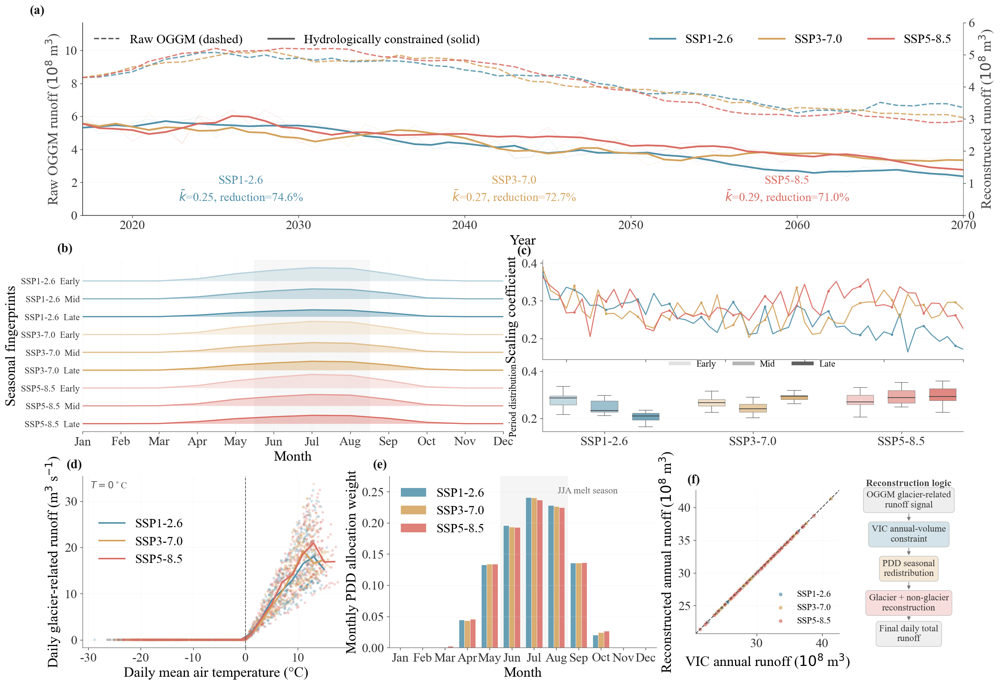


FIG. 4 SUMMARY

SSP1-2.6
  mean scaling coefficient = 0.254
  SD scaling coefficient   = 0.045
  mean correction          = 74.59%

SSP3-7.0
  mean scaling coefficient = 0.273
  SD scaling coefficient   = 0.037
  mean correction          = 72.69%

SSP5-8.5
  mean scaling coefficient = 0.290
  SD scaling coefficient   = 0.036
  mean correction          = 71.02%

Saved:
D:\博士论文\小论文3\图片\Fig4_Reconstructed_Composite.png
D:\博士论文\小论文3\图片\Fig4_Reconstructed_Composite.pdf
D:\博士论文\小论文3\图片\Fig4_Reconstructed_Composite.svg

Done.


In [44]:
# ======================================================================
# Fig. 4
# Journal of Hydrology-style composite figure
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import to_rgb

warnings.filterwarnings("ignore")


# ======================================================================
# 1. PATHS
# ======================================================================

DIAGNOSIS_DIR = (
    r"D:\Python code\boshilunwen\vic\径流重构"
    r"\coupling_diagnosis_ssp585"
)

DAILY_DIR = r"D:\Python code\boshilunwen\vic\径流重构"

OUTPUT_DIR = r"D:\博士论文\小论文3\图片"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ======================================================================
# 2. GLOBAL STYLE (字体全局 +5)
# ======================================================================

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False

mpl.rcParams.update({
    "font.size": 18,          # 原 9  → 14
    "axes.labelsize": 19,     # 原 10 → 15
    "axes.titlesize": 19,     # 原 10 → 15
    "xtick.labelsize": 17,    # 原 8  → 13
    "ytick.labelsize": 17,    # 原 8  → 13
    "legend.fontsize": 17,    # 原 8  → 13

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "axes.linewidth": 0.75,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "xtick.major.size": 3.2,
    "ytick.major.size": 3.2,

    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,

    "figure.dpi": 150,
    "savefig.dpi": 600,
})


# ======================================================================
# 3. SCENARIOS
# ======================================================================

SCENARIOS = ["ssp126", "ssp370", "ssp585"]

SCENARIO_LABELS = {
    "ssp126": "SSP1-2.6",
    "ssp370": "SSP3-7.0",
    "ssp585": "SSP5-8.5"
}


# ======================================================================
# 4. SEA-SALT → CORAL PALETTE
# ======================================================================

SSP_COLORS = {
    "ssp126": "#4F8FA8",   # sea-salt blue
    "ssp370": "#D3A15A",   # warm sand
    "ssp585": "#D96B62",   # coral
}

COLOR_RAW = "#8A8A8A"
COLOR_SCALE = "#404040"

COLOR_GRID = "#E2E2E2"
COLOR_SPINE = "#666666"
COLOR_TEXT = "#303030"

JJA_FACE = "#F1F1F1"


# ======================================================================
# 5. PERIODS
# ======================================================================

PERIODS = {
    "Early": (2020, 2040),
    "Mid":   (2041, 2055),
    "Late":  (2056, 2070)
}


# ======================================================================
# 6. HELPERS
# ======================================================================

def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(COLOR_SPINE)
    ax.spines["bottom"].set_color(COLOR_SPINE)
    ax.spines["left"].set_linewidth(0.7)
    ax.spines["bottom"].set_linewidth(0.7)
    ax.tick_params(colors="#333333")


def add_panel_label(ax, label):
    ax.text(
        -0.06, 1.03, label,
        transform=ax.transAxes,
        fontsize=17,           # 原 12 → 17
        fontweight="bold",
        ha="left", va="bottom",
        color="#111111",
        clip_on=False
    )


def moving_average(series, window=5):
    return series.rolling(window=window, center=True, min_periods=2).mean()


def mix_with_white(color, amount):
    rgb = np.array(to_rgb(color))
    white = np.ones(3)
    return tuple(rgb * (1 - amount) + white * amount)


def get_period_colors(base_color):
    return {
        "Early": mix_with_white(base_color, 0.58),
        "Mid":   mix_with_white(base_color, 0.30),
        "Late":  base_color
    }


# ======================================================================
# 7. LOAD ANNUAL + MONTHLY COUPLING DATA
# ======================================================================

annual_data = {}
monthly_data = {}

print("=" * 80)
print("Loading coupling datasets")
print("=" * 80)

for scenario in SCENARIOS:
    annual_file = os.path.join(DIAGNOSIS_DIR, f"annual_coupling_evaluation_{scenario}.csv")
    monthly_file = os.path.join(DIAGNOSIS_DIR, f"monthly_glacier_process_{scenario}.csv")

    if os.path.exists(annual_file):
        df = pd.read_csv(annual_file).sort_values("year").reset_index(drop=True)
        annual_data[scenario] = df
        print(f"✓ {SCENARIO_LABELS[scenario]} annual: {df['year'].min()}–{df['year'].max()}")
    else:
        print(f"✗ Missing annual: {annual_file}")

    if os.path.exists(monthly_file):
        dfm = pd.read_csv(monthly_file).sort_values(["year", "month"]).reset_index(drop=True)
        monthly_data[scenario] = dfm
        print(f"✓ {SCENARIO_LABELS[scenario]} monthly: {len(dfm)} rows")
    else:
        print(f"✗ Missing monthly: {monthly_file}")


# ======================================================================
# 8. LOAD DAILY RECONSTRUCTED DATA
# ======================================================================

daily_data = {}

for scenario in SCENARIOS:
    daily_file = os.path.join(DAILY_DIR, f"daily_runoff_reconstructed_{scenario}_2017_2070.csv")
    if os.path.exists(daily_file):
        dfd = pd.read_csv(daily_file)
        dfd["date"] = pd.to_datetime(dfd["date"])
        dfd = dfd.sort_values("date").reset_index(drop=True)
        daily_data[scenario] = dfd
        print(f"✓ {SCENARIO_LABELS[scenario]} daily: {len(dfd)} rows")
    else:
        print(f"✗ Missing daily: {daily_file}")


# ======================================================================
# 9. BASIC CHECKS
# ======================================================================

required_annual = ["year", "Q_glacier_oggm", "Q_glacier_achieved",
                   "glacier_scale", "Q_total_original", "Q_total_new"]
required_monthly = ["year", "month", "Q_glacier_monthly", "monthly_pos_weight"]
required_daily = ["year", "month", "T_air", "Q_glacier"]

for scenario, df in annual_data.items():
    missing = [c for c in required_annual if c not in df.columns]
    if missing:
        raise ValueError(f"{scenario} annual missing: {missing}")

for scenario, df in monthly_data.items():
    missing = [c for c in required_monthly if c not in df.columns]
    if missing:
        raise ValueError(f"{scenario} monthly missing: {missing}")

for scenario, df in daily_data.items():
    missing = [c for c in required_daily if c not in df.columns]
    if missing:
        raise ValueError(f"{scenario} daily missing: {missing}")


# ======================================================================
# 10. SUMMARY STATISTICS
# ======================================================================

summary_stats = {}

for scenario in SCENARIOS:
    df = annual_data[scenario]
    valid = np.isfinite(df["Q_glacier_oggm"]) & (df["Q_glacier_oggm"] != 0)
    reduction = (
        1 - df.loc[valid, "Q_glacier_achieved"] / df.loc[valid, "Q_glacier_oggm"]
    ) * 100

    summary_stats[scenario] = {
        "k_mean": df["glacier_scale"].mean(),
        "k_std":  df["glacier_scale"].std(),
        "reduction": reduction.mean()
    }


# ======================================================================
# 11. SEASONAL PROFILES
# ======================================================================

seasonal_profiles = {}
seasonal_max = 0

for scenario in SCENARIOS:
    dfm = monthly_data[scenario]
    seasonal_profiles[scenario] = {}

    for period_name, (start_year, end_year) in PERIODS.items():
        sub = dfm[(dfm["year"] >= start_year) & (dfm["year"] <= end_year)]
        month_year = sub.groupby(["year", "month"])["Q_glacier_monthly"].sum().reset_index()
        profile = (month_year.groupby("month")["Q_glacier_monthly"]
                   .agg(["mean", "std"]) / 1e6)
        profile = profile.reindex(np.arange(1, 13))
        seasonal_profiles[scenario][period_name] = profile
        seasonal_max = max(seasonal_max,
                           np.nanmax(profile["mean"] + profile["std"].fillna(0)))


# ======================================================================
# 12. SCALING COEFFICIENT PERIOD DISTRIBUTIONS
# ======================================================================

scale_period_values = {}

for scenario in SCENARIOS:
    df = annual_data[scenario]
    scale_period_values[scenario] = {}

    for period_name, (start_year, end_year) in PERIODS.items():
        vals = df.loc[
            (df["year"] >= start_year) & (df["year"] <= end_year),
            "glacier_scale"
        ].dropna()
        scale_period_values[scenario][period_name] = vals.values


# ======================================================================
# 13. PDD PROFILES
# ======================================================================

pdd_profiles = {}
PDD_MAX = 0

for scenario in SCENARIOS:
    stat = (monthly_data[scenario].groupby("month")["monthly_pos_weight"]
            .agg(["mean", "std"]).reindex(np.arange(1, 13)))
    pdd_profiles[scenario] = stat
    PDD_MAX = max(PDD_MAX, np.nanmax(stat["mean"] + stat["std"].fillna(0)))


# ======================================================================
# 14. COMMON LIMITS
# ======================================================================

# 左轴（raw）上限
ANNUAL_YMAX = 0
for scenario in SCENARIOS:
    df = annual_data[scenario]
    temp = np.nanmax(df[["Q_glacier_oggm", "Q_glacier_achieved"]].values) / 1e8
    ANNUAL_YMAX = max(ANNUAL_YMAX, temp)
ANNUAL_YMAX *= 1.08

# 【新增】右轴（corrected）上限：固定 0–6
CORRECTED_MAX = 6.0
max_corrected = max(
    (annual_data[s]["Q_glacier_achieved"] / 1e8).max() for s in SCENARIOS
)
if max_corrected > CORRECTED_MAX:
    print(f"⚠ Warning: corrected max = {max_corrected:.2f} > {CORRECTED_MAX}，部分数据将被裁剪")
else:
    print(f"✓ Corrected max = {max_corrected:.2f}，符合 0–{CORRECTED_MAX} 范围")

# scaling 范围
all_scale = np.concatenate([
    annual_data[s]["glacier_scale"].dropna().values for s in SCENARIOS
])
SCALE_MIN = max(0, np.nanmin(all_scale) - 0.02)
SCALE_MAX = np.nanmax(all_scale) + 0.02

# water-balance 范围
balance_values = []
for scenario in SCENARIOS:
    df = annual_data[scenario]
    balance_values.extend((df["Q_total_original"] / 1e8).tolist())
    balance_values.extend((df["Q_total_new"] / 1e8).tolist())
BALANCE_MIN = np.nanmin(balance_values) * 0.97
BALANCE_MAX = np.nanmax(balance_values) * 1.03


# ======================================================================
# 15. FIGURE LAYOUT（加宽、加宽左右间隔、压缩高度间隔）
# ======================================================================

fig = plt.figure(figsize=(18.0, 13.0), facecolor="white")

outer = GridSpec(
    3, 12, figure=fig,
    height_ratios=[1.18, 1.05, 1.05],
    hspace=0.25,     # 原 0.38 → 0.25（压缩高度间隔）
    wspace=1.05,     # 原 0.45 → 0.65（加大左右间隔）
    left=0.06,
    right=0.965,
    bottom=0.06,
    top=0.95
)


# ======================================================================
# 16. PANEL (a)
# 双 Y 轴：左=Raw OGGM，右=Corrected（0–6）
# ======================================================================

ax_a = fig.add_subplot(outer[0, :])
ax_a_right = ax_a.twinx()

for scenario in SCENARIOS:
    df = annual_data[scenario]
    color = SSP_COLORS[scenario]
    years = df["year"]

    raw = df["Q_glacier_oggm"] / 1e8
    corrected = df["Q_glacier_achieved"] / 1e8

    raw_ma = moving_average(raw)
    corrected_ma = moving_average(corrected)

    # 【关键修改 1】左轴：raw 虚线 → 使用各自情景的颜色
    ax_a.plot(
        years, raw_ma,
        color=color,
        linestyle="--",
        linewidth=1.8,
        alpha=0.85
    )

    # 【关键修改 2】右轴：corrected 年线 + MA 实线
    ax_a_right.plot(years, corrected, color=color, linewidth=0.55, alpha=0.20)
    ax_a_right.plot(
        years, corrected_ma,
        color=color,
        linewidth=2.3,
        label=SCENARIO_LABELS[scenario]
    )

ax_a.set_xlim(2017, 2070)
ax_a.set_ylim(0, ANNUAL_YMAX)
ax_a_right.set_ylim(0, CORRECTED_MAX)   # 【关键修改 3】右轴固定 0–6

ax_a.set_xlabel("Year")
ax_a.set_ylabel(r"Raw OGGM runoff ($10^8$ m$^3$)", color="#444444")
ax_a_right.set_ylabel(r"Reconstructed runoff ($10^8$ m$^3$)", color="#444444")

ax_a.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.45)
clean_axis(ax_a)

# twinx 轴清理
ax_a_right.spines["top"].set_visible(False)
ax_a_right.spines["right"].set_color(COLOR_SPINE)
ax_a_right.spines["right"].set_linewidth(0.7)
ax_a_right.tick_params(colors="#333333")

add_panel_label(ax_a, "(a)")

# ---- 情景颜色图例（3 列） ----
scenario_handles = [
    Line2D([0], [0], color=SSP_COLORS[s], linewidth=2.3, label=SCENARIO_LABELS[s])
    for s in SCENARIOS
]
legend1 = ax_a.legend(handles=scenario_handles, ncol=3, frameon=False, loc="upper right")
ax_a.add_artist(legend1)

# ---- 线型图例（虚线=Raw，实线=Corrected） ----
style_handles = [
    Line2D([0], [0], color="#555555", linestyle="--", linewidth=1.8,
           label="Raw OGGM (dashed)"),
    Line2D([0], [0], color="#555555", linewidth=2.3,
           label="Hydrologically constrained (solid)")
]
ax_a.legend(handles=style_handles, ncol=2, frameon=False, loc="upper left")

# 底部统计标签
x_positions = [0.18, 0.49, 0.80]
for xpos, scenario in zip(x_positions, SCENARIOS):
    s = summary_stats[scenario]
    ax_a.text(
        xpos, 0.06,
        (f"{SCENARIO_LABELS[scenario]}\n"
         r"$\bar{k}$" + f"={s['k_mean']:.2f}, reduction={s['reduction']:.1f}%"),
        transform=ax_a.transAxes,
        ha="center", va="bottom",
        fontsize=16,
        color=SSP_COLORS[scenario]
    )


# ======================================================================
# 17. PANEL (b)
# Seasonal fingerprints / ridgeline
# ======================================================================

ax_b = fig.add_subplot(outer[1, :6])

months = np.arange(1, 13)
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

ridge_gap = 1.0
row_index = 0
ytick_positions = []
ytick_labels = []

for scenario in SCENARIOS:
    period_colors = get_period_colors(SSP_COLORS[scenario])

    for period_name in ["Early", "Mid", "Late"]:
        stat = seasonal_profiles[scenario][period_name]
        mean = stat["mean"].values

        baseline = (8 - row_index) * ridge_gap
        norm = mean / seasonal_max * 0.85

        ax_b.fill_between(months, baseline, baseline + norm,
                          color=period_colors[period_name], alpha=0.38, linewidth=0)
        ax_b.plot(months, baseline + norm,
                  color=period_colors[period_name], linewidth=1.6)

        ytick_positions.append(baseline)
        ytick_labels.append(f"{SCENARIO_LABELS[scenario]}  {period_name}")
        row_index += 1

ax_b.axvspan(5.5, 8.5, color=JJA_FACE, alpha=0.55, zorder=0)
ax_b.set_xlim(1, 12)
ax_b.set_xticks(months)
ax_b.set_xticklabels(month_labels)
ax_b.set_yticks(ytick_positions)
ax_b.set_yticklabels(ytick_labels, fontsize=12.2)   # 原 7.2 → 12.2
ax_b.set_xlabel("Month")
ax_b.set_ylabel("Seasonal fingerprints")
ax_b.grid(axis="x", color=COLOR_GRID, linewidth=0.4, alpha=0.35)
clean_axis(ax_b)
ax_b.spines["left"].set_visible(False)
ax_b.tick_params(axis="y", length=0)
add_panel_label(ax_b, "(b)")


# ======================================================================
# 18. PANEL (c)
# ======================================================================

cell_c = GridSpecFromSubplotSpec(
    2, 1, subplot_spec=outer[1, 6:],
    height_ratios=[1.6, 1.0],
    hspace=0.12
)

ax_c1 = fig.add_subplot(cell_c[0, 0])
ax_c2 = fig.add_subplot(cell_c[1, 0])

# 上部：scaling coefficient 年轨迹
for scenario in SCENARIOS:
    df = annual_data[scenario]
    color = SSP_COLORS[scenario]
    ax_c1.plot(df["year"], df["glacier_scale"],
               color=color, linewidth=1.4, alpha=0.90)
    ax_c1.scatter(df["year"].values[::4], df["glacier_scale"].values[::4],
                  color=color, s=12, edgecolor="white", linewidth=0.3)

ax_c1.set_xlim(2017, 2070)
ax_c1.set_ylim(SCALE_MIN, SCALE_MAX)
ax_c1.set_ylabel("Scaling coefficient")
ax_c1.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.40)
clean_axis(ax_c1)
ax_c1.set_xticklabels([])
add_panel_label(ax_c1, "(c)")

# 下部：箱线图
positions = []
box_data = []
box_colors = []

xpos = 1
for scenario in SCENARIOS:
    base = SSP_COLORS[scenario]
    period_colors = get_period_colors(base)

    for period_name in ["Early", "Mid", "Late"]:
        vals = scale_period_values[scenario][period_name]
        box_data.append(vals)
        positions.append(xpos)
        box_colors.append(period_colors[period_name])
        xpos += 1
    xpos += 0.6

bp = ax_c2.boxplot(
    box_data, positions=positions, widths=0.65,
    patch_artist=True, showfliers=False,
    medianprops=dict(color="#444444", linewidth=1.0),
    whiskerprops=dict(color="#777777", linewidth=0.8),
    capprops=dict(color="#777777", linewidth=0.8)
)

for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("#777777")
    patch.set_linewidth(0.6)
    patch.set_alpha(0.80)

group_centers = [
    np.mean(positions[0:3]),
    np.mean(positions[3:6]),
    np.mean(positions[6:9])
]

ax_c2.set_xticks(group_centers)
ax_c2.set_xticklabels(["SSP1-2.6", "SSP3-7.0", "SSP5-8.5"])
ax_c2.set_ylabel("Period distribution", fontsize=13)   # 原 8 → 13
ax_c2.set_ylim(SCALE_MIN, SCALE_MAX)
clean_axis(ax_c2)
ax_c2.grid(axis="y", color=COLOR_GRID, linewidth=0.4, alpha=0.35)

period_legend = [
    Line2D([0], [0], color="#AAAAAA", linewidth=5, alpha=0.35, label="Early"),
    Line2D([0], [0], color="#777777", linewidth=5, alpha=0.55, label="Mid"),
    Line2D([0], [0], color="#444444", linewidth=5, alpha=0.85, label="Late")
]
ax_c2.legend(handles=period_legend, frameon=False, ncol=3,
             loc="upper center", bbox_to_anchor=(0.5, 1.28),
             fontsize=12.2)   # 原 7.2 → 12.2


# ======================================================================
# 19. PANEL (d)
# 温度-径流物理一致性（散点加深）
# ======================================================================

ax_d = fig.add_subplot(outer[2, :4])

for scenario in SCENARIOS:
    if scenario not in daily_data:
        continue

    df = daily_data[scenario]
    sample = df.iloc[::25].copy()
    temp = sample["T_air"].values
    q = sample["Q_glacier"].values / 86400
    color = SSP_COLORS[scenario]

    ax_d.scatter(
        temp, q,
        s=12,
        color=color,
        alpha=0.28,     # 原 0.09 → 0.28（加深）
        edgecolors="none"
    )

    # 分箱趋势
    temp_bins = np.arange(-20, 25, 2)
    centers = (temp_bins[:-1] + temp_bins[1:]) / 2
    bin_id = np.digitize(temp, temp_bins)
    means = []

    for i in range(1, len(temp_bins)):
        vals = q[bin_id == i]
        means.append(np.nanmedian(vals) if len(vals) >= 5 else np.nan)

    ax_d.plot(centers, np.array(means),
              color=color, linewidth=2.0, label=SCENARIO_LABELS[scenario])

ax_d.axvline(0, color="#555555", linestyle="--", linewidth=1.0)
ax_d.text(0.03, 0.93, r"$T=0^\circ$C",
          transform=ax_d.transAxes, fontsize=12.5, color="#555555")   # 原 7.5 → 12.5

ax_d.set_xlabel("Daily mean air temperature (°C)")
ax_d.set_ylabel(r"Daily glacier-related runoff (m$^3$ s$^{-1}$)")
ax_d.grid(color=COLOR_GRID, linewidth=0.45, alpha=0.35)
clean_axis(ax_d)
ax_d.legend(frameon=False, ncol=1, loc="upper left", bbox_to_anchor=(0.02, 0.82))
add_panel_label(ax_d, "(d)")


# ======================================================================
# 20. PANEL (e)
# 月 PDD 分配权重（分组柱状图，删除阴影）
# ======================================================================

ax_e = fig.add_subplot(outer[2, 4:8])

months = np.arange(1, 13)

ax_e.axvspan(5.5, 8.5, color=JJA_FACE, alpha=0.70, zorder=0)

bar_width = 0.25
for i, scenario in enumerate(SCENARIOS):
    stat = pdd_profiles[scenario]
    mean = stat["mean"]
    color = SSP_COLORS[scenario]
    offset = (i - 1) * bar_width

    ax_e.bar(
        months + offset, mean,
        width=bar_width, color=color, alpha=0.85,
        label=SCENARIO_LABELS[scenario],
        edgecolor="white", linewidth=0.5
    )

ax_e.set_xlim(0.5, 12.5)
ax_e.set_ylim(0, PDD_MAX * 1.10)
ax_e.set_xticks(months)
ax_e.set_xticklabels(month_labels)
ax_e.set_xlabel("Month")
ax_e.set_ylabel("Monthly PDD allocation weight")
ax_e.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.35)
clean_axis(ax_e)
ax_e.legend(frameon=False, ncol=1, loc="upper left")
ax_e.text(0.63, 0.90, "JJA melt season",
          transform=ax_e.transAxes, fontsize=12.5, color="#666666")   # 原 7.5 → 12.5
add_panel_label(ax_e, "(e)")


# ======================================================================
# 21. PANEL (f)
# ======================================================================

cell_f = GridSpecFromSubplotSpec(
    1, 2, subplot_spec=outer[2, 8:],
    width_ratios=[1.25, 0.95],
    wspace=0.12
)

ax_f = fig.add_subplot(cell_f[0, 0])
ax_flow = fig.add_subplot(cell_f[0, 1])

# water balance 散点
for scenario in SCENARIOS:
    df = annual_data[scenario]
    x = df["Q_total_original"] / 1e8
    y = df["Q_total_new"] / 1e8

    ax_f.scatter(x, y, s=26,
                 color=SSP_COLORS[scenario],
                 alpha=0.68, edgecolor="white", linewidth=0.45,
                 label=SCENARIO_LABELS[scenario])

ax_f.plot([BALANCE_MIN, BALANCE_MAX], [BALANCE_MIN, BALANCE_MAX],
          "--", color="#444444", linewidth=1.1)
ax_f.set_xlim(BALANCE_MIN, BALANCE_MAX)
ax_f.set_ylim(BALANCE_MIN, BALANCE_MAX)
ax_f.set_aspect("equal", adjustable="box")
ax_f.set_xlabel(r"VIC annual runoff ($10^8$ m$^3$)")
ax_f.set_ylabel(r"Reconstructed annual runoff ($10^8$ m$^3$)")
ax_f.grid(color=COLOR_GRID, linewidth=0.45, alpha=0.35)
clean_axis(ax_f)
ax_f.legend(frameon=False, fontsize=12.1, loc="lower right")   # 原 7.1 → 12.1
add_panel_label(ax_f, "(f)")

# 示意图
ax_flow.set_xlim(0, 1)
ax_flow.set_ylim(0, 1)
ax_flow.axis("off")

box_x = 0.50
box_y = [0.86, 0.66, 0.46, 0.26, 0.08]
box_text = [
    "OGGM glacier-related\nrunoff signal",
    "VIC annual-volume\nconstraint",
    "PDD seasonal\nredistribution",
    "Glacier + non-glacier\nreconstruction",
    "Final daily total\nrunoff"
]
box_face = [
    "#EEEEEE",
    mix_with_white(SSP_COLORS["ssp126"], 0.75),
    mix_with_white(SSP_COLORS["ssp370"], 0.75),
    mix_with_white(SSP_COLORS["ssp585"], 0.78),
    "#EFEFEF"
]

for i, (y0, txt, face) in enumerate(zip(box_y, box_text, box_face)):
    ax_flow.text(
        box_x, y0, txt,
        ha="center", va="center",
        fontsize=12.4,       # 原 7.4 → 12.4
        color="#333333",
        bbox=dict(boxstyle="round,pad=0.35",
                  facecolor=face, edgecolor="#BFBFBF", linewidth=0.7)
    )

    if i < len(box_y) - 1:
        arrow = FancyArrowPatch(
            (box_x, y0 - 0.07),
            (box_x, box_y[i + 1] + 0.07),
            arrowstyle="-|>", mutation_scale=10,
            linewidth=0.8, color="#777777"
        )
        ax_flow.add_patch(arrow)

ax_flow.text(0.50, 0.98, "Reconstruction logic",
             ha="center", va="top",
             fontsize=13, fontweight="bold", color="#444444")   # 原 8 → 13


# ======================================================================
# 22. SAVE
# ======================================================================

PNG_FILE = os.path.join(OUTPUT_DIR, "Fig4_Reconstructed_Composite.png")
PDF_FILE = os.path.join(OUTPUT_DIR, "Fig4_Reconstructed_Composite.pdf")
SVG_FILE = os.path.join(OUTPUT_DIR, "Fig4_Reconstructed_Composite.svg")

fig.savefig(PNG_FILE, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(PDF_FILE, bbox_inches="tight", facecolor="white")
fig.savefig(SVG_FILE, bbox_inches="tight", facecolor="white")

plt.show()


# ======================================================================
# 23. PRINT SUMMARY
# ======================================================================

print("\n" + "=" * 80)
print("FIG. 4 SUMMARY")
print("=" * 80)

for scenario in SCENARIOS:
    stat = summary_stats[scenario]
    print(f"\n{SCENARIO_LABELS[scenario]}")
    print(f"  mean scaling coefficient = {stat['k_mean']:.3f}")
    print(f"  SD scaling coefficient   = {stat['k_std']:.3f}")
    print(f"  mean correction          = {stat['reduction']:.2f}%")

print("\nSaved:")
print(PNG_FILE)
print(PDF_FILE)
print(SVG_FILE)
print("\nDone.")

Loading reconstructed runoff datasets
✓ SSP1-2.6: 19723 days, 2017–2070
✓ SSP3-7.0: 19723 days, 2017–2070
✓ SSP5-8.5: 19723 days, 2017–2070


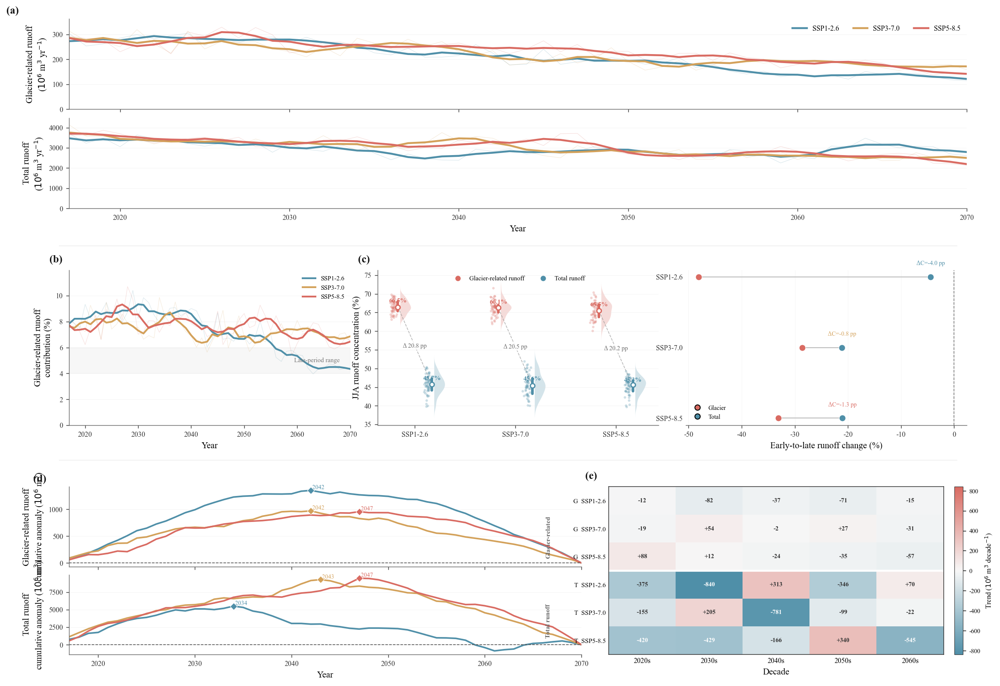


FIG. 5 SUMMARY

SSP1-2.6
  Glacier runoff change = -48.1%
  Total runoff change   = -4.4%
  Glacier contribution  = 8.8% -> 4.8%
  JJA concentration     = 66.5% glacier vs 45.7% total
  JJA difference        = 20.8 pp
  Glacier cum. peak     = 2042
  Total cum. peak       = 2034

SSP3-7.0
  Glacier runoff change = -28.6%
  Total runoff change   = -21.1%
  Glacier contribution  = 7.9% -> 7.1%
  JJA concentration     = 66.1% glacier vs 45.6% total
  JJA difference        = 20.5 pp
  Glacier cum. peak     = 2042
  Total cum. peak       = 2043

SSP5-8.5
  Glacier runoff change = -33.1%
  Total runoff change   = -21.1%
  Glacier contribution  = 8.1% -> 6.9%
  JJA concentration     = 65.5% glacier vs 45.3% total
  JJA difference        = 20.2 pp
  Glacier cum. peak     = 2047
  Total cum. peak       = 2047

Saved:
D:\博士论文\小论文3\图片\Fig5_Future_Reconstructed_Runoff.png
D:\博士论文\小论文3\图片\Fig5_Future_Reconstructed_Runoff.pdf
D:\博士论文\小论文3\图片\Fig5_Future_Reconstructed_Runoff.svg

Done.


In [45]:
# ======================================================================
# Fig. 5
# Future evolution and seasonal reorganization of reconstructed
# basin runoff in the Kaidu River Basin
#
# (a) Annual glacier-related and total runoff trajectories
# (b) Glacier-related runoff contribution to total runoff
# (c) JJA runoff concentration: glacier-related vs total runoff
# (d) Cumulative runoff anomalies and peak timing
# (e) Decadal runoff trend matrix
#
# Existing reconstructed daily runoff only.
# NO model rerun required.
#
# Output:
# D:\博士论文\小论文3\图片
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import gaussian_kde
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

warnings.filterwarnings("ignore")


# ======================================================================
# 1. PATHS
# ======================================================================

DATA_DIR = r"D:\Python code\boshilunwen\vic\径流重构"

OUTPUT_DIR = r"D:\博士论文\小论文3\图片"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ======================================================================
# 2. GLOBAL STYLE
# ======================================================================

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False

mpl.rcParams.update({
    "font.size": 9,

    "axes.labelsize": 10,
    "axes.titlesize": 10,

    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    "legend.fontsize": 8,

    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",

    "axes.linewidth": 0.75,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,

    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,

    "figure.dpi": 150,
    "savefig.dpi": 600,
})


# ======================================================================
# 3. SCENARIOS
# ======================================================================

SCENARIOS = [
    "ssp126",
    "ssp370",
    "ssp585"
]

SCENARIO_LABELS = {
    "ssp126": "SSP1-2.6",
    "ssp370": "SSP3-7.0",
    "ssp585": "SSP5-8.5"
}


# ======================================================================
# 4. SEA-SALT → CORAL PALETTE
#
# 与 Fig.3 / Fig.4 统一
# ======================================================================

SSP_COLORS = {
    "ssp126": "#4F8FA8",   # sea-salt blue
    "ssp370": "#D3A15A",   # warm sand
    "ssp585": "#D96B62",   # coral
}

# 用于 glacier / total runoff 类型区分
GLACIER_COLOR = "#D96B62"
TOTAL_COLOR   = "#4F8FA8"

COLOR_GRID  = "#E1E1E1"
COLOR_SPINE = "#666666"
COLOR_TEXT  = "#303030"

JJA_FACE = "#F1F1F1"


# ======================================================================
# 5. DIVERGING COLORMAP FOR DECADAL TRENDS
#
# sea-salt blue → white → coral
# ======================================================================

trend_cmap = LinearSegmentedColormap.from_list(
    "sea_salt_coral",
    [
        "#4F8FA8",
        "#F7F7F7",
        "#D96B62"
    ],
    N=256
)


# ======================================================================
# 6. HELPERS
# ======================================================================

def clean_axis(ax):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color(
        COLOR_SPINE
    )

    ax.spines["bottom"].set_color(
        COLOR_SPINE
    )

    ax.spines["left"].set_linewidth(
        0.7
    )

    ax.spines["bottom"].set_linewidth(
        0.7
    )

    ax.tick_params(
        colors="#333333"
    )


def add_panel_label(ax, label):

    ax.text(
        -0.07,
        1.035,
        label,

        transform=ax.transAxes,

        fontsize=12,
        fontweight="bold",

        ha="left",
        va="bottom",

        color="#111111",

        clip_on=False
    )


def moving_average(series, window=5):

    return series.rolling(
        window=window,
        center=True,
        min_periods=2
    ).mean()


def kde_safe(values, y_range):

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) < 3:
        return np.zeros_like(
            y_range
        )

    if np.std(values) == 0:
        return np.zeros_like(
            y_range
        )

    kde = gaussian_kde(
        values
    )

    return kde(
        y_range
    )


# ======================================================================
# 7. LOAD DATA
# ======================================================================

data_dict = {}

print("=" * 80)
print("Loading reconstructed runoff datasets")
print("=" * 80)

for scenario in SCENARIOS:

    file_path = os.path.join(
        DATA_DIR,
        f"daily_runoff_reconstructed_{scenario}_2017_2070.csv"
    )

    if not os.path.exists(
        file_path
    ):

        print(
            f"✗ Missing: {file_path}"
        )

        continue

    df = pd.read_csv(
        file_path
    )

    df["date"] = pd.to_datetime(
        df["date"]
    )

    df = (
        df
        .sort_values("date")
        .reset_index(drop=True)
    )

    data_dict[
        scenario
    ] = df

    print(
        f"✓ {SCENARIO_LABELS[scenario]}: "
        f"{len(df)} days, "
        f"{df['year'].min()}–{df['year'].max()}"
    )


if len(
    data_dict
) != 3:

    raise ValueError(
        "Not all three SSP datasets were loaded."
    )


# ======================================================================
# 8. CHECK REQUIRED COLUMNS
# ======================================================================

REQUIRED = [
    "year",
    "month",
    "Q_glacier",
    "Q_total_new"
]

for scenario, df in data_dict.items():

    missing = [
        x for x in REQUIRED
        if x not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{scenario} missing columns: {missing}"
        )


# ======================================================================
# 9. ANNUAL DATA
# ======================================================================

annual = {}

for scenario, df in data_dict.items():

    annual_g = (
        df
        .groupby("year")[
            "Q_glacier"
        ]
        .sum()
        /
        1e6
    )

    annual_t = (
        df
        .groupby("year")[
            "Q_total_new"
        ]
        .sum()
        /
        1e6
    )

    common = (
        annual_g.index
        .intersection(
            annual_t.index
        )
    )

    temp = pd.DataFrame({
        "year":
            common,

        "glacier":
            annual_g.loc[
                common
            ].values,

        "total":
            annual_t.loc[
                common
            ].values
    })

    temp[
        "contribution"
    ] = (
        temp[
            "glacier"
        ]
        /
        temp[
            "total"
        ]
        *
        100
    )

    annual[
        scenario
    ] = temp


# ======================================================================
# 10. JJA CONCENTRATION
# ======================================================================

summer_data = {}

for scenario, df in data_dict.items():

    annual_g = (
        df
        .groupby("year")[
            "Q_glacier"
        ]
        .sum()
    )

    annual_t = (
        df
        .groupby("year")[
            "Q_total_new"
        ]
        .sum()
    )

    summer = df[
        df[
            "month"
        ].isin(
            [
                6,
                7,
                8
            ]
        )
    ]

    summer_g = (
        summer
        .groupby("year")[
            "Q_glacier"
        ]
        .sum()
    )

    summer_t = (
        summer
        .groupby("year")[
            "Q_total_new"
        ]
        .sum()
    )

    common = (
        annual_g.index
        .intersection(
            annual_t.index
        )
        .intersection(
            summer_g.index
        )
        .intersection(
            summer_t.index
        )
    )

    g_share = (
        summer_g.loc[
            common
        ]
        /
        annual_g.loc[
            common
        ]
        *
        100
    )

    t_share = (
        summer_t.loc[
            common
        ]
        /
        annual_t.loc[
            common
        ]
        *
        100
    )

    summer_data[
        scenario
    ] = {
        "glacier":
            g_share.values,

        "total":
            t_share.values
    }


# ======================================================================
# 11. CUMULATIVE ANOMALIES
# ======================================================================

cumulative_data = {}

for scenario in SCENARIOS:

    df = annual[
        scenario
    ].copy()

    glacier_anomaly = (
        df[
            "glacier"
        ]
        -
        df[
            "glacier"
        ].mean()
    )

    total_anomaly = (
        df[
            "total"
        ]
        -
        df[
            "total"
        ].mean()
    )

    glacier_cum = (
        glacier_anomaly
        .cumsum()
    )

    total_cum = (
        total_anomaly
        .cumsum()
    )

    glacier_peak_idx = (
        glacier_cum
        .idxmax()
    )

    total_peak_idx = (
        total_cum
        .idxmax()
    )

    cumulative_data[
        scenario
    ] = {
        "year":
            df[
                "year"
            ].values,

        "glacier":
            glacier_cum.values,

        "total":
            total_cum.values,

        "glacier_peak_year":
            int(
                df.loc[
                    glacier_peak_idx,
                    "year"
                ]
            ),

        "total_peak_year":
            int(
                df.loc[
                    total_peak_idx,
                    "year"
                ]
            )
    }


# ======================================================================
# 12. DECADAL TREND MATRIX
#
# slope from linear regression within each decade
#
# reported as:
# 10^6 m3 per decade
# ======================================================================

DECADES = {
    "2020s": (2020, 2029),
    "2030s": (2030, 2039),
    "2040s": (2040, 2049),
    "2050s": (2050, 2059),
    "2060s": (2060, 2070)
}


trend_rows = []

trend_labels = []

for runoff_type in [
    "glacier",
    "total"
]:

    for scenario in SCENARIOS:

        df = annual[
            scenario
        ]

        row = []

        for decade_name, (
            start_year,
            end_year
        ) in DECADES.items():

            sub = df[
                (
                    df[
                        "year"
                    ]
                    >=
                    start_year
                )
                &
                (
                    df[
                        "year"
                    ]
                    <=
                    end_year
                )
            ]

            if len(
                sub
            ) < 3:

                row.append(
                    np.nan
                )

                continue

            slope = np.polyfit(
                sub[
                    "year"
                ].values,

                sub[
                    runoff_type
                ].values,

                1
            )[0]

            # annual slope ×10 years
            # units remain 10^6 m3 per decade
            row.append(
                slope * 10
            )

        trend_rows.append(
            row
        )

        prefix = (
            "G"
            if runoff_type == "glacier"
            else "T"
        )

        trend_labels.append(
            f"{prefix}  {SCENARIO_LABELS[scenario]}"
        )


trend_matrix = np.array(
    trend_rows,
    dtype=float
)


# ======================================================================
# 13. COMMON LIMITS
# ======================================================================

# annual glacier
GLACIER_YMAX = max(
    np.nanmax(
        annual[s][
            "glacier"
        ]
    )
    for s in SCENARIOS
) * 1.10


# total
TOTAL_YMAX = max(
    np.nanmax(
        annual[s][
            "total"
        ]
    )
    for s in SCENARIOS
) * 1.08


# contribution
CONTRIB_MAX = max(
    np.nanmax(
        annual[s][
            "contribution"
        ]
    )
    for s in SCENARIOS
) * 1.12


# cumulative
CUM_GLACIER_ABS = max(
    np.nanmax(
        np.abs(
            cumulative_data[s][
                "glacier"
            ]
        )
    )
    for s in SCENARIOS
)

CUM_TOTAL_ABS = max(
    np.nanmax(
        np.abs(
            cumulative_data[s][
                "total"
            ]
        )
    )
    for s in SCENARIOS
)


# ======================================================================
# 14. FIGURE LAYOUT
# ======================================================================

fig = plt.figure(
    figsize=(
        15.6,
        11.3
    ),
    facecolor="white"
)

outer = GridSpec(
    3,
    12,

    figure=fig,

    height_ratios=[
        1.22,
        1.00,
        1.08
    ],

    hspace=0.36,
    wspace=0.55,

    left=0.065,
    right=0.965,

    bottom=0.07,
    top=0.95
)


# ======================================================================
# 15. PANEL (a)
#
# Annual glacier-related + total runoff trajectories
# ======================================================================

gs_a = GridSpecFromSubplotSpec(
    2,
    1,

    subplot_spec=outer[
        0,
        :
    ],

    height_ratios=[
        1,
        1
    ],

    hspace=0.10
)


ax_a1 = fig.add_subplot(
    gs_a[
        0,
        0
    ]
)

ax_a2 = fig.add_subplot(
    gs_a[
        1,
        0
    ],
    sharex=ax_a1
)


# glacier runoff
for scenario in SCENARIOS:

    temp = annual[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    glacier = temp[
        "glacier"
    ]

    glacier_ma = moving_average(
        glacier
    )

    ax_a1.plot(
        temp[
            "year"
        ],
        glacier,

        color=color,

        linewidth=0.55,

        alpha=0.22
    )

    ax_a1.plot(
        temp[
            "year"
        ],
        glacier_ma,

        color=color,

        linewidth=2.15,

        label=SCENARIO_LABELS[
            scenario
        ]
    )


ax_a1.set_ylim(
    0,
    GLACIER_YMAX
)

ax_a1.set_ylabel(
    r"Glacier-related runoff"
    "\n"
    r"($10^6$ m$^3$ yr$^{-1}$)"
)

ax_a1.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.42
)

clean_axis(
    ax_a1
)

ax_a1.tick_params(
    axis="x",
    labelbottom=False
)

ax_a1.legend(
    frameon=False,
    ncol=3,
    loc="upper right"
)


# total runoff
for scenario in SCENARIOS:

    temp = annual[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    total = temp[
        "total"
    ]

    total_ma = moving_average(
        total
    )

    ax_a2.plot(
        temp[
            "year"
        ],
        total,

        color=color,

        linewidth=0.55,

        alpha=0.22
    )

    ax_a2.plot(
        temp[
            "year"
        ],
        total_ma,

        color=color,

        linewidth=2.15
    )


ax_a2.set_xlim(
    2017,
    2070
)

ax_a2.set_ylim(
    0,
    TOTAL_YMAX
)

ax_a2.set_ylabel(
    r"Total runoff"
    "\n"
    r"($10^6$ m$^3$ yr$^{-1}$)"
)

ax_a2.set_xlabel(
    "Year"
)

ax_a2.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.42
)

clean_axis(
    ax_a2
)

add_panel_label(
    ax_a1,
    "(a)"
)


# ======================================================================
# 16. PANEL (b)
#
# Glacier contribution
# ======================================================================

ax_b = fig.add_subplot(
    outer[
        1,
        :4
    ]
)


for scenario in SCENARIOS:

    temp = annual[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    ratio = temp[
        "contribution"
    ]

    ratio_ma = moving_average(
        ratio
    )

    ax_b.plot(
        temp[
            "year"
        ],
        ratio,

        color=color,

        linewidth=0.55,

        alpha=0.20
    )

    ax_b.plot(
        temp[
            "year"
        ],
        ratio_ma,

        color=color,

        linewidth=2.0,

        label=SCENARIO_LABELS[
            scenario
        ]
    )


# visual guide
ax_b.axhspan(
    4,
    6,

    color="#F3F3F3",

    alpha=0.65,

    zorder=0
)

ax_b.text(
    2068,
    5.0,

    "Late-period range",

    fontsize=7.2,

    color="#777777",

    ha="right",
    va="center"
)


ax_b.set_xlim(
    2017,
    2070
)

ax_b.set_ylim(
    0,
    CONTRIB_MAX
)

ax_b.set_xlabel(
    "Year"
)

ax_b.set_ylabel(
    "Glacier-related runoff\ncontribution (%)"
)

ax_b.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.40
)

clean_axis(
    ax_b
)

ax_b.legend(
    frameon=False,
    fontsize=7.2,
    loc="upper right"
)

add_panel_label(
    ax_b,
    "(b)"
)


# ======================================================================
# 17. PANEL (c)
#
# JJA concentration
# Paired raincloud style
# ======================================================================

ax_c = fig.add_subplot(
    outer[
        1,
        4:8
    ]
)


group_centers = np.arange(
    len(
        SCENARIOS
    )
) * 2.25


for idx, scenario in enumerate(
    SCENARIOS
):

    center = group_centers[
        idx
    ]

    g = summer_data[
        scenario
    ][
        "glacier"
    ]

    t = summer_data[
        scenario
    ][
        "total"
    ]

    # positions
    x_g = center - 0.38
    x_t = center + 0.38

    # --------------------------------------------------
    # jitter
    # --------------------------------------------------

    rng = np.random.default_rng(
        100 + idx
    )

    jitter_g = rng.normal(
        0,
        0.035,
        len(
            g
        )
    )

    jitter_t = rng.normal(
        0,
        0.035,
        len(
            t
        )
    )

    # raw observations
    ax_c.scatter(
        np.full(
            len(g),
            x_g - 0.10
        ) + jitter_g,

        g,

        s=8,

        color=GLACIER_COLOR,

        alpha=0.28,

        edgecolors="none",

        zorder=3
    )

    ax_c.scatter(
        np.full(
            len(t),
            x_t - 0.10
        ) + jitter_t,

        t,

        s=8,

        color=TOTAL_COLOR,

        alpha=0.28,

        edgecolors="none",

        zorder=3
    )


    # --------------------------------------------------
    # Half violin
    # --------------------------------------------------

    y_min = min(
        np.nanmin(g),
        np.nanmin(t)
    ) - 3

    y_max = max(
        np.nanmax(g),
        np.nanmax(t)
    ) + 3

    y_range = np.linspace(
        y_min,
        y_max,
        180
    )

    density_g = kde_safe(
        g,
        y_range
    )

    density_t = kde_safe(
        t,
        y_range
    )

    if np.nanmax(
        density_g
    ) > 0:

        density_g = (
            density_g
            /
            np.nanmax(
                density_g
            )
            *
            0.24
        )

    if np.nanmax(
        density_t
    ) > 0:

        density_t = (
            density_t
            /
            np.nanmax(
                density_t
            )
            *
            0.24
        )

    ax_c.fill_betweenx(
        y_range,

        x_g + 0.05,

        x_g + 0.05
        +
        density_g,

        color=GLACIER_COLOR,

        alpha=0.24,

        linewidth=0
    )

    ax_c.fill_betweenx(
        y_range,

        x_t + 0.05,

        x_t + 0.05
        +
        density_t,

        color=TOTAL_COLOR,

        alpha=0.24,

        linewidth=0
    )


    # --------------------------------------------------
    # median / IQR
    # --------------------------------------------------

    for xx, vals, color in [
        (
            x_g,
            g,
            GLACIER_COLOR
        ),
        (
            x_t,
            t,
            TOTAL_COLOR
        )
    ]:

        q25 = np.percentile(
            vals,
            25
        )

        med = np.median(
            vals
        )

        q75 = np.percentile(
            vals,
            75
        )

        ax_c.plot(
            [
                xx,
                xx
            ],
            [
                q25,
                q75
            ],

            color=color,

            linewidth=3.0,

            solid_capstyle="round",

            zorder=5
        )

        ax_c.scatter(
            xx,
            med,

            s=26,

            color="white",

            edgecolor=color,

            linewidth=1.4,

            zorder=6
        )


    # --------------------------------------------------
    # mean difference
    # --------------------------------------------------

    mean_g = np.mean(
        g
    )

    mean_t = np.mean(
        t
    )

    delta = (
        mean_g
        -
        mean_t
    )

    # connecting line
    ax_c.plot(
        [
            x_g,
            x_t
        ],
        [
            mean_g,
            mean_t
        ],

        color="#999999",

        linewidth=0.8,

        linestyle="--",

        alpha=0.70,

        zorder=2
    )

    # mean labels
    ax_c.text(
        x_g,
        mean_g + 1.2,

        f"{mean_g:.1f}%",

        color=GLACIER_COLOR,

        fontsize=7.3,

        fontweight="bold",

        ha="center"
    )

    ax_c.text(
        x_t,
        mean_t + 1.2,

        f"{mean_t:.1f}%",

        color=TOTAL_COLOR,

        fontsize=7.3,

        fontweight="bold",

        ha="center"
    )

    ax_c.text(
        center,
        (
            mean_g
            +
            mean_t
        )
        /
        2,

        f"Δ {delta:.1f} pp",

        fontsize=7.0,

        color="#666666",

        ha="center",

        va="center",

        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.80,
            pad=1.5
        )
    )


ax_c.set_xticks(
    group_centers
)

ax_c.set_xticklabels(
    [
        "SSP1-2.6",
        "SSP3-7.0",
        "SSP5-8.5"
    ]
)

ax_c.set_ylabel(
    "JJA runoff concentration (%)"
)

ax_c.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.40
)

clean_axis(
    ax_c
)

legend_c = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=GLACIER_COLOR,
        markeredgecolor="none",
        label="Glacier-related runoff"
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=TOTAL_COLOR,
        markeredgecolor="none",
        label="Total runoff"
    )
]

ax_c.legend(
    handles=legend_c,
    frameon=False,
    ncol=2,
    loc="upper center",
    fontsize=7.1
)

add_panel_label(
    ax_c,
    "(c)"
)


# ======================================================================
# 18. PANEL – small synthesis panel
#
# Early → Late changes
# ======================================================================

ax_small = fig.add_subplot(
    outer[
        1,
        8:
    ]
)


periods_simple = {
    "Early": (
        2020,
        2040
    ),

    "Late": (
        2056,
        2070
    )
}


for i, scenario in enumerate(
    SCENARIOS
):

    temp = annual[
        scenario
    ]

    early = temp[
        (
            temp[
                "year"
            ]
            >=
            periods_simple[
                "Early"
            ][0]
        )
        &
        (
            temp[
                "year"
            ]
            <=
            periods_simple[
                "Early"
            ][1]
        )
    ]

    late = temp[
        (
            temp[
                "year"
            ]
            >=
            periods_simple[
                "Late"
            ][0]
        )
        &
        (
            temp[
                "year"
            ]
            <=
            periods_simple[
                "Late"
            ][1]
        )
    ]

    glacier_loss = (
        (
            late[
                "glacier"
            ].mean()
            -
            early[
                "glacier"
            ].mean()
        )
        /
        early[
            "glacier"
        ].mean()
        *
        100
    )

    total_loss = (
        (
            late[
                "total"
            ].mean()
            -
            early[
                "total"
            ].mean()
        )
        /
        early[
            "total"
        ].mean()
        *
        100
    )

    contribution_change = (
        late[
            "contribution"
        ].mean()
        -
        early[
            "contribution"
        ].mean()
    )

    y = 2 - i

    color = SSP_COLORS[
        scenario
    ]

    # line from glacier to total
    ax_small.plot(
        [
            glacier_loss,
            total_loss
        ],
        [
            y,
            y
        ],

        color="#BBBBBB",

        linewidth=1.0
    )

    ax_small.scatter(
        glacier_loss,
        y,

        s=52,

        color=GLACIER_COLOR,

        edgecolor="white",

        linewidth=0.5,

        zorder=3
    )

    ax_small.scatter(
        total_loss,
        y,

        s=52,

        color=TOTAL_COLOR,

        edgecolor="white",

        linewidth=0.5,

        zorder=3
    )

    ax_small.text(
        total_loss,
        y + 0.17,

        f"ΔC={contribution_change:+.1f} pp",

        fontsize=6.8,

        color=color,

        ha="center"
    )


ax_small.axvline(
    0,
    color="#777777",
    linestyle="--",
    linewidth=0.8
)

ax_small.set_yticks(
    [
        2,
        1,
        0
    ]
)

ax_small.set_yticklabels(
    [
        "SSP1-2.6",
        "SSP3-7.0",
        "SSP5-8.5"
    ]
)

ax_small.set_xlabel(
    "Early-to-late runoff change (%)"
)

ax_small.set_ylabel(
    ""
)

ax_small.grid(
    axis="x",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.38
)

clean_axis(
    ax_small
)

ax_small.spines[
    "left"
].set_visible(
    False
)

ax_small.tick_params(
    axis="y",
    length=0
)

small_legend = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=GLACIER_COLOR,
        label="Glacier"
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=TOTAL_COLOR,
        label="Total"
    )
]

ax_small.legend(
    handles=small_legend,
    frameon=False,
    fontsize=6.8,
    loc="lower left"
)


# ======================================================================
# 19. PANEL (d)
#
# Cumulative anomalies
# ======================================================================

gs_d = GridSpecFromSubplotSpec(
    2,
    1,

    subplot_spec=outer[
        2,
        :7
    ],

    height_ratios=[
        1,
        1
    ],

    hspace=0.10
)


ax_d1 = fig.add_subplot(
    gs_d[
        0,
        0
    ]
)

ax_d2 = fig.add_subplot(
    gs_d[
        1,
        0
    ],
    sharex=ax_d1
)


# Glacier cumulative anomaly
for scenario in SCENARIOS:

    d = cumulative_data[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    ax_d1.plot(
        d[
            "year"
        ],
        d[
            "glacier"
        ],

        color=color,

        linewidth=1.8
    )

    peak_year = d[
        "glacier_peak_year"
    ]

    idx = np.where(
        d[
            "year"
        ]
        ==
        peak_year
    )[0][0]

    peak_value = d[
        "glacier"
    ][
        idx
    ]

    ax_d1.scatter(
        peak_year,
        peak_value,

        marker="D",

        s=32,

        color=color,

        edgecolor="white",

        linewidth=0.5,

        zorder=4
    )

    ax_d1.text(
        peak_year,
        peak_value,

        f" {peak_year}",

        fontsize=6.8,

        color=color,

        va="bottom"
    )


ax_d1.axhline(
    0,
    color="#555555",
    linestyle="--",
    linewidth=0.8
)

ax_d1.set_ylabel(
    "Glacier-related runoff\n"
    r"cumulative anomaly ($10^6$ m$^3$)"
)

ax_d1.tick_params(
    axis="x",
    labelbottom=False
)

ax_d1.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.40
)

clean_axis(
    ax_d1
)


# Total cumulative anomaly
for scenario in SCENARIOS:

    d = cumulative_data[
        scenario
    ]

    color = SSP_COLORS[
        scenario
    ]

    ax_d2.plot(
        d[
            "year"
        ],
        d[
            "total"
        ],

        color=color,

        linewidth=1.8
    )

    peak_year = d[
        "total_peak_year"
    ]

    idx = np.where(
        d[
            "year"
        ]
        ==
        peak_year
    )[0][0]

    peak_value = d[
        "total"
    ][
        idx
    ]

    ax_d2.scatter(
        peak_year,
        peak_value,

        marker="D",

        s=32,

        color=color,

        edgecolor="white",

        linewidth=0.5,

        zorder=4
    )

    ax_d2.text(
        peak_year,
        peak_value,

        f" {peak_year}",

        fontsize=6.8,

        color=color,

        va="bottom"
    )


ax_d2.axhline(
    0,
    color="#555555",
    linestyle="--",
    linewidth=0.8
)

ax_d2.set_xlim(
    2017,
    2070
)

ax_d2.set_xlabel(
    "Year"
)

ax_d2.set_ylabel(
    "Total runoff\n"
    r"cumulative anomaly ($10^6$ m$^3$)"
)

ax_d2.grid(
    axis="y",
    color=COLOR_GRID,
    linewidth=0.45,
    alpha=0.40
)

clean_axis(
    ax_d2
)

add_panel_label(
    ax_d1,
    "(d)"
)


# ======================================================================
# 20. PANEL (e)
#
# Decadal trend matrix
# ======================================================================

ax_e = fig.add_subplot(
    outer[
        2,
        7:
    ]
)


finite_vals = trend_matrix[
    np.isfinite(
        trend_matrix
    )
]

abs_max = np.nanmax(
    np.abs(
        finite_vals
    )
)

norm = TwoSlopeNorm(
    vmin=-abs_max,
    vcenter=0,
    vmax=abs_max
)

im = ax_e.imshow(
    trend_matrix,

    cmap=trend_cmap,

    norm=norm,

    aspect="auto",

    interpolation="nearest"
)


ax_e.set_xticks(
    np.arange(
        len(
            DECADES
        )
    )
)

ax_e.set_xticklabels(
    list(
        DECADES.keys()
    )
)

ax_e.set_yticks(
    np.arange(
        len(
            trend_labels
        )
    )
)

ax_e.set_yticklabels(
    trend_labels,
    fontsize=7.3
)

ax_e.tick_params(
    length=0
)


# divider between glacier and total
ax_e.axhline(
    2.5,
    color="white",
    linewidth=2.2
)


# numbers in cells
threshold = abs_max * 0.48

for i in range(
    trend_matrix.shape[0]
):

    for j in range(
        trend_matrix.shape[1]
    ):

        val = trend_matrix[
            i,
            j
        ]

        if not np.isfinite(
            val
        ):

            continue

        text_color = (
            "white"
            if abs(
                val
            )
            >
            threshold
            else
            "#333333"
        )

        ax_e.text(
            j,
            i,

            f"{val:+.0f}",

            ha="center",
            va="center",

            fontsize=7.1,

            color=text_color,

            fontweight="bold"
        )


ax_e.set_xlabel(
    "Decade"
)

ax_e.set_ylabel(
    ""
)

add_panel_label(
    ax_e,
    "(e)"
)


# colorbar
cbar = fig.colorbar(
    im,
    ax=ax_e,
    fraction=0.035,
    pad=0.03
)

cbar.set_label(
    r"Trend ($10^6$ m$^3$ decade$^{-1}$)",
    fontsize=8
)

cbar.ax.tick_params(
    labelsize=7
)

cbar.outline.set_linewidth(
    0.55
)


# labels for blocks
ax_e.text(
    -0.18,
    1.3,
    "Glacier-related",
    transform=ax_e.get_yaxis_transform(),
    rotation=90,
    fontsize=7.4,
    fontweight="bold",
    color="#666666",
    ha="center",
    va="center"
)

ax_e.text(
    -0.18,
    4.3,
    "Total runoff",
    transform=ax_e.get_yaxis_transform(),
    rotation=90,
    fontsize=7.4,
    fontweight="bold",
    color="#666666",
    ha="center",
    va="center"
)


# ======================================================================
# 21. SUBTLE ROW DIVIDERS
# ======================================================================

for y in [
    0.636,
    0.339
]:

    fig.add_artist(
        Line2D(
            [
                0.055,
                0.955
            ],
            [
                y,
                y
            ],

            transform=fig.transFigure,

            color="#EEEEEE",

            linewidth=0.8,

            zorder=0
        )
    )


# ======================================================================
# 22. SAVE
# ======================================================================

PNG_FILE = os.path.join(
    OUTPUT_DIR,
    "Fig5_Future_Reconstructed_Runoff.png"
)

PDF_FILE = os.path.join(
    OUTPUT_DIR,
    "Fig5_Future_Reconstructed_Runoff.pdf"
)

SVG_FILE = os.path.join(
    OUTPUT_DIR,
    "Fig5_Future_Reconstructed_Runoff.svg"
)


fig.savefig(
    PNG_FILE,

    dpi=600,

    bbox_inches="tight",

    facecolor="white"
)

fig.savefig(
    PDF_FILE,

    bbox_inches="tight",

    facecolor="white"
)

fig.savefig(
    SVG_FILE,

    bbox_inches="tight",

    facecolor="white"
)


plt.show()


# ======================================================================
# 23. PRINT KEY RESULTS
# ======================================================================

print("\n" + "=" * 86)
print("FIG. 5 SUMMARY")
print("=" * 86)


for scenario in SCENARIOS:

    temp = annual[
        scenario
    ]

    early = temp[
        (
            temp[
                "year"
            ]
            >=
            2020
        )
        &
        (
            temp[
                "year"
            ]
            <=
            2040
        )
    ]

    late = temp[
        (
            temp[
                "year"
            ]
            >=
            2056
        )
        &
        (
            temp[
                "year"
            ]
            <=
            2070
        )
    ]

    g_change = (
        (
            late[
                "glacier"
            ].mean()
            /
            early[
                "glacier"
            ].mean()
        )
        -
        1
    ) * 100

    t_change = (
        (
            late[
                "total"
            ].mean()
            /
            early[
                "total"
            ].mean()
        )
        -
        1
    ) * 100

    c_early = early[
        "contribution"
    ].mean()

    c_late = late[
        "contribution"
    ].mean()

    jja_g = np.mean(
        summer_data[
            scenario
        ][
            "glacier"
        ]
    )

    jja_t = np.mean(
        summer_data[
            scenario
        ][
            "total"
        ]
    )

    d = cumulative_data[
        scenario
    ]

    print(
        f"\n{SCENARIO_LABELS[scenario]}"
    )

    print(
        f"  Glacier runoff change = "
        f"{g_change:+.1f}%"
    )

    print(
        f"  Total runoff change   = "
        f"{t_change:+.1f}%"
    )

    print(
        f"  Glacier contribution  = "
        f"{c_early:.1f}% -> "
        f"{c_late:.1f}%"
    )

    print(
        f"  JJA concentration     = "
        f"{jja_g:.1f}% glacier vs "
        f"{jja_t:.1f}% total"
    )

    print(
        f"  JJA difference        = "
        f"{jja_g-jja_t:.1f} pp"
    )

    print(
        f"  Glacier cum. peak     = "
        f"{d['glacier_peak_year']}"
    )

    print(
        f"  Total cum. peak       = "
        f"{d['total_peak_year']}"
    )


print("\nSaved:")
print(PNG_FILE)
print(PDF_FILE)
print(SVG_FILE)

print("\nDone.")

Loading reconstructed runoff datasets
✓ SSP1-2.6: 19723 days, 2017–2070
✓ SSP3-7.0: 19723 days, 2017–2070
✓ SSP5-8.5: 19723 days, 2017–2070


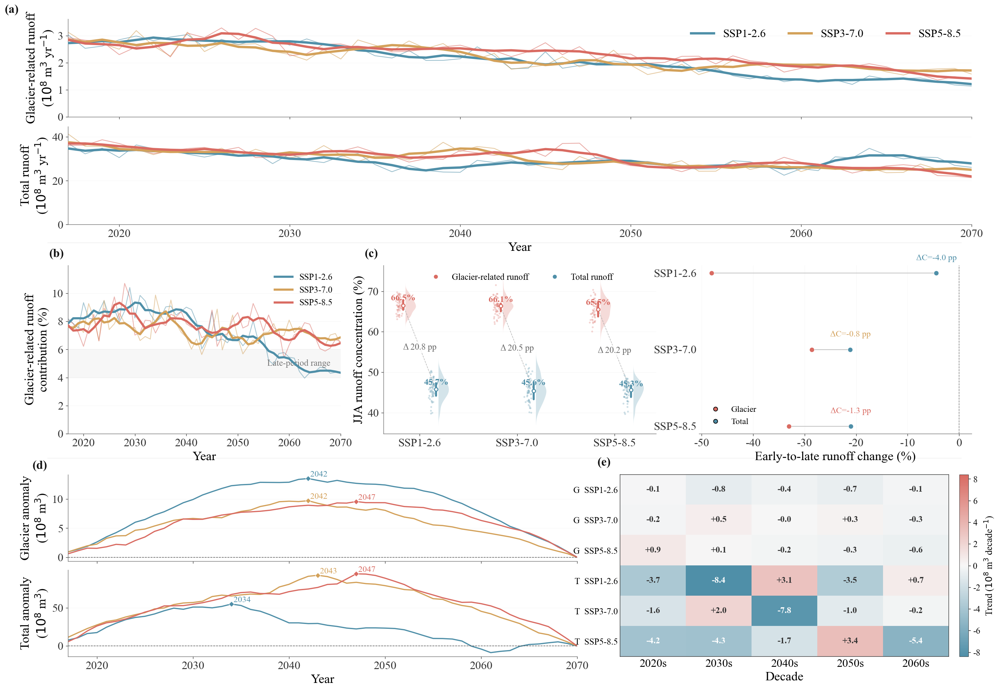


FIG. 5 SUMMARY

SSP1-2.6
  Glacier runoff change = -48.1%
  Total runoff change   = -4.4%
  Glacier contribution  = 8.8% -> 4.8%
  JJA concentration     = 66.5% glacier vs 45.7% total
  JJA difference        = 20.8 pp
  Glacier cum. peak     = 2042
  Total cum. peak       = 2034

SSP3-7.0
  Glacier runoff change = -28.6%
  Total runoff change   = -21.1%
  Glacier contribution  = 7.9% -> 7.1%
  JJA concentration     = 66.1% glacier vs 45.6% total
  JJA difference        = 20.5 pp
  Glacier cum. peak     = 2042
  Total cum. peak       = 2043

SSP5-8.5
  Glacier runoff change = -33.1%
  Total runoff change   = -21.1%
  Glacier contribution  = 8.1% -> 6.9%
  JJA concentration     = 65.5% glacier vs 45.3% total
  JJA difference        = 20.2 pp
  Glacier cum. peak     = 2047
  Total cum. peak       = 2047

Saved:
D:\博士论文\小论文3\图片\Fig5_Future_Reconstructed_Runoff.png
D:\博士论文\小论文3\图片\Fig5_Future_Reconstructed_Runoff.pdf
D:\博士论文\小论文3\图片\Fig5_Future_Reconstructed_Runoff.svg

Done.


In [49]:
# ======================================================================
# Fig. 5
# Future evolution and seasonal reorganization of reconstructed
# basin runoff in the Kaidu River Basin
# ======================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import gaussian_kde
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

warnings.filterwarnings("ignore")


# ======================================================================
# 1. PATHS
# ======================================================================

DATA_DIR = r"D:\Python code\boshilunwen\vic\径流重构"
OUTPUT_DIR = r"D:\博士论文\小论文3\图片"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ======================================================================
# 2. GLOBAL STYLE
# ======================================================================

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["axes.unicode_minus"] = False

mpl.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 19,
    "axes.titlesize": 19,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 17,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.linewidth": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "figure.dpi": 150,
    "savefig.dpi": 600,
})


# ======================================================================
# 3. SCENARIOS
# ======================================================================

SCENARIOS = ["ssp126", "ssp370", "ssp585"]
SCENARIO_LABELS = {
    "ssp126": "SSP1-2.6",
    "ssp370": "SSP3-7.0",
    "ssp585": "SSP5-8.5"
}


# ======================================================================
# 4. SEA-SALT → CORAL PALETTE
# ======================================================================

SSP_COLORS = {
    "ssp126": "#4F8FA8",
    "ssp370": "#D3A15A",
    "ssp585": "#D96B62",
}

GLACIER_COLOR = "#D96B62"
TOTAL_COLOR   = "#4F8FA8"

COLOR_GRID  = "#E1E1E1"
COLOR_SPINE = "#666666"
COLOR_TEXT  = "#303030"

JJA_FACE = "#F1F1F1"

trend_cmap = LinearSegmentedColormap.from_list(
    "sea_salt_coral",
    ["#4F8FA8", "#F7F7F7", "#D96B62"],
    N=256
)


# ======================================================================
# 6. HELPERS
# ======================================================================

def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(COLOR_SPINE)
    ax.spines["bottom"].set_color(COLOR_SPINE)
    ax.spines["left"].set_linewidth(0.7)
    ax.spines["bottom"].set_linewidth(0.7)
    ax.tick_params(colors="#333333")


def add_panel_label(ax, label):
    ax.text(
        -0.07, 1.035, label,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        ha="left", va="bottom",
        color="#111111",
        clip_on=False
    )


def moving_average(series, window=5):
    return series.rolling(window=window, center=True, min_periods=2).mean()


def kde_safe(values, y_range):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 3:
        return np.zeros_like(y_range)
    if np.std(values) == 0:
        return np.zeros_like(y_range)
    kde = gaussian_kde(values)
    return kde(y_range)


# ======================================================================
# 7. LOAD DATA
# ======================================================================

data_dict = {}

print("=" * 80)
print("Loading reconstructed runoff datasets")
print("=" * 80)

for scenario in SCENARIOS:
    file_path = os.path.join(DATA_DIR,
                             f"daily_runoff_reconstructed_{scenario}_2017_2070.csv")
    if not os.path.exists(file_path):
        print(f"✗ Missing: {file_path}")
        continue

    df = pd.read_csv(file_path)
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    data_dict[scenario] = df
    print(f"✓ {SCENARIO_LABELS[scenario]}: {len(df)} days, "
          f"{df['year'].min()}–{df['year'].max()}")

if len(data_dict) != 3:
    raise ValueError("Not all three SSP datasets were loaded.")


# ======================================================================
# 8. CHECK REQUIRED COLUMNS
# ======================================================================

REQUIRED = ["year", "month", "Q_glacier", "Q_total_new"]
for scenario, df in data_dict.items():
    missing = [x for x in REQUIRED if x not in df.columns]
    if missing:
        raise ValueError(f"{scenario} missing columns: {missing}")


# ======================================================================
# 9. ANNUAL DATA (【修改】单位换为 10^8)
# ======================================================================

annual = {}

for scenario, df in data_dict.items():
    # 除以 1e8 代替原来的 1e6
    annual_g = df.groupby("year")["Q_glacier"].sum() / 1e8
    annual_t = df.groupby("year")["Q_total_new"].sum() / 1e8
    common = annual_g.index.intersection(annual_t.index)
    temp = pd.DataFrame({
        "year": common,
        "glacier": annual_g.loc[common].values,
        "total": annual_t.loc[common].values
    })
    temp["contribution"] = temp["glacier"] / temp["total"] * 100
    annual[scenario] = temp


# ======================================================================
# 10. JJA CONCENTRATION
# ======================================================================

summer_data = {}

for scenario, df in data_dict.items():
    annual_g = df.groupby("year")["Q_glacier"].sum()
    annual_t = df.groupby("year")["Q_total_new"].sum()
    summer = df[df["month"].isin([6, 7, 8])]
    summer_g = summer.groupby("year")["Q_glacier"].sum()
    summer_t = summer.groupby("year")["Q_total_new"].sum()
    common = (annual_g.index.intersection(annual_t.index)
              .intersection(summer_g.index)
              .intersection(summer_t.index))
    g_share = summer_g.loc[common] / annual_g.loc[common] * 100
    t_share = summer_t.loc[common] / annual_t.loc[common] * 100
    summer_data[scenario] = {
        "glacier": g_share.values,
        "total": t_share.values
    }


# ======================================================================
# 11. CUMULATIVE ANOMALIES
# ======================================================================

cumulative_data = {}

for scenario in SCENARIOS:
    df = annual[scenario].copy()
    glacier_anomaly = df["glacier"] - df["glacier"].mean()
    total_anomaly = df["total"] - df["total"].mean()
    glacier_cum = glacier_anomaly.cumsum()
    total_cum = total_anomaly.cumsum()
    glacier_peak_idx = glacier_cum.idxmax()
    total_peak_idx = total_cum.idxmax()
    cumulative_data[scenario] = {
        "year": df["year"].values,
        "glacier": glacier_cum.values,
        "total": total_cum.values,
        "glacier_peak_year": int(df.loc[glacier_peak_idx, "year"]),
        "total_peak_year": int(df.loc[total_peak_idx, "year"])
    }


# ======================================================================
# 12. DECADAL TREND MATRIX
# ======================================================================

DECADES = {
    "2020s": (2020, 2029),
    "2030s": (2030, 2039),
    "2040s": (2040, 2049),
    "2050s": (2050, 2059),
    "2060s": (2060, 2070)
}

trend_rows = []
trend_labels = []

for runoff_type in ["glacier", "total"]:
    for scenario in SCENARIOS:
        df = annual[scenario]
        row = []
        for decade_name, (start_year, end_year) in DECADES.items():
            sub = df[(df["year"] >= start_year) & (df["year"] <= end_year)]
            if len(sub) < 3:
                row.append(np.nan)
                continue
            slope = np.polyfit(sub["year"].values,
                               sub[runoff_type].values, 1)[0]
            row.append(slope * 10)
        trend_rows.append(row)
        prefix = "G" if runoff_type == "glacier" else "T"
        trend_labels.append(f"{prefix}  {SCENARIO_LABELS[scenario]}")

trend_matrix = np.array(trend_rows, dtype=float)


# ======================================================================
# 13. COMMON LIMITS
# ======================================================================

GLACIER_YMAX = max(np.nanmax(annual[s]["glacier"]) for s in SCENARIOS) * 1.10
TOTAL_YMAX = max(np.nanmax(annual[s]["total"]) for s in SCENARIOS) * 1.08
CONTRIB_MAX = max(np.nanmax(annual[s]["contribution"]) for s in SCENARIOS) * 1.12
CUM_GLACIER_ABS = max(np.nanmax(np.abs(cumulative_data[s]["glacier"])) for s in SCENARIOS)
CUM_TOTAL_ABS = max(np.nanmax(np.abs(cumulative_data[s]["total"])) for s in SCENARIOS)


# ======================================================================
# 14. FIGURE LAYOUT
# ======================================================================

fig = plt.figure(figsize=(21.0, 15.0), facecolor="white")

outer = GridSpec(
    3, 12, figure=fig,
    height_ratios=[1.22, 1.00, 1.08],
    hspace=0.22,
    wspace=1.20,
    left=0.075,
    right=0.965,
    bottom=0.065,
    top=0.945
)


# ======================================================================
# 15. PANEL (a)（【修改】Y轴标签换为 10^8）
# ======================================================================

gs_a = GridSpecFromSubplotSpec(
    2, 1, subplot_spec=outer[0, :],
    height_ratios=[1, 1],
    hspace=0.10
)

ax_a1 = fig.add_subplot(gs_a[0, 0])
ax_a2 = fig.add_subplot(gs_a[1, 0], sharex=ax_a1)

# glacier runoff
for scenario in SCENARIOS:
    temp = annual[scenario]
    color = SSP_COLORS[scenario]
    glacier = temp["glacier"]
    glacier_ma = moving_average(glacier)

    ax_a1.plot(temp["year"], glacier,
               color=color, linewidth=1.2, alpha=0.55, zorder=2)
    ax_a1.plot(temp["year"], glacier_ma,
               color=color, linewidth=3.5, zorder=10,
               label=SCENARIO_LABELS[scenario])

ax_a1.set_ylim(0, GLACIER_YMAX)
# 修改了次方数为 10^8
ax_a1.set_ylabel(r"Glacier-related runoff" "\n" r"($10^8$ m$^3$ yr$^{-1}$)")
ax_a1.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.42)
clean_axis(ax_a1)
ax_a1.tick_params(axis="x", labelbottom=False)
ax_a1.legend(frameon=False, ncol=3, loc="upper right")

# total runoff
for scenario in SCENARIOS:
    temp = annual[scenario]
    color = SSP_COLORS[scenario]
    total = temp["total"]
    total_ma = moving_average(total)

    ax_a2.plot(temp["year"], total,
               color=color, linewidth=1.2, alpha=0.55, zorder=2)
    ax_a2.plot(temp["year"], total_ma,
               color=color, linewidth=3.5, zorder=10)

ax_a2.set_xlim(2017, 2070)
ax_a2.set_ylim(0, TOTAL_YMAX)
# 修改了次方数为 10^8
ax_a2.set_ylabel(r"Total runoff" "\n" r"($10^8$ m$^3$ yr$^{-1}$)")
ax_a2.set_xlabel("Year")
ax_a2.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.42)
clean_axis(ax_a2)
add_panel_label(ax_a1, "(a)")


# ======================================================================
# 16. PANEL (b)
# ======================================================================

ax_b = fig.add_subplot(outer[1, :4])

for scenario in SCENARIOS:
    temp = annual[scenario]
    color = SSP_COLORS[scenario]
    ratio = temp["contribution"]
    ratio_ma = moving_average(ratio)

    ax_b.plot(temp["year"], ratio,
              color=color, linewidth=1.2, alpha=0.50, zorder=2)
    ax_b.plot(temp["year"], ratio_ma,
              color=color, linewidth=3.2, zorder=10,
              label=SCENARIO_LABELS[scenario])

ax_b.axhspan(4, 6, color="#F3F3F3", alpha=0.65, zorder=0)
ax_b.text(2068, 5.0, "Late-period range",
          fontsize=13.2, color="#777777",
          ha="right", va="center")

ax_b.set_xlim(2017, 2070)
ax_b.set_ylim(0, CONTRIB_MAX)
ax_b.set_xlabel("Year")
ax_b.set_ylabel("Glacier-related runoff\ncontribution (%)")
ax_b.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.40)
clean_axis(ax_b)
ax_b.legend(frameon=False, fontsize=13.2, loc="upper right")
add_panel_label(ax_b, "(b)")


# ======================================================================
# 17. PANEL (c)
# ======================================================================

ax_c = fig.add_subplot(outer[1, 4:8])

group_centers = np.arange(len(SCENARIOS)) * 2.25

for idx, scenario in enumerate(SCENARIOS):
    center = group_centers[idx]
    g = summer_data[scenario]["glacier"]
    t = summer_data[scenario]["total"]

    x_g = center - 0.38
    x_t = center + 0.38

    rng = np.random.default_rng(100 + idx)
    jitter_g = rng.normal(0, 0.035, len(g))
    jitter_t = rng.normal(0, 0.035, len(t))

    ax_c.scatter(np.full(len(g), x_g - 0.10) + jitter_g,
                 g, s=8, color=GLACIER_COLOR, alpha=0.28,
                 edgecolors="none", zorder=3)
    ax_c.scatter(np.full(len(t), x_t - 0.10) + jitter_t,
                 t, s=8, color=TOTAL_COLOR, alpha=0.28,
                 edgecolors="none", zorder=3)

    y_min = min(np.nanmin(g), np.nanmin(t)) - 3
    y_max = max(np.nanmax(g), np.nanmax(t)) + 3
    y_range = np.linspace(y_min, y_max, 180)

    density_g = kde_safe(g, y_range)
    density_t = kde_safe(t, y_range)

    if np.nanmax(density_g) > 0:
        density_g = density_g / np.nanmax(density_g) * 0.24
    if np.nanmax(density_t) > 0:
        density_t = density_t / np.nanmax(density_t) * 0.24

    ax_c.fill_betweenx(y_range, x_g + 0.05, x_g + 0.05 + density_g,
                       color=GLACIER_COLOR, alpha=0.24, linewidth=0)
    ax_c.fill_betweenx(y_range, x_t + 0.05, x_t + 0.05 + density_t,
                       color=TOTAL_COLOR, alpha=0.24, linewidth=0)

    for xx, vals, color in [(x_g, g, GLACIER_COLOR), (x_t, t, TOTAL_COLOR)]:
        q25 = np.percentile(vals, 25)
        med = np.median(vals)
        q75 = np.percentile(vals, 75)
        ax_c.plot([xx, xx], [q25, q75],
                  color=color, linewidth=3.0,
                  solid_capstyle="round", zorder=5)
        ax_c.scatter(xx, med, s=26, color="white",
                     edgecolor=color, linewidth=1.4, zorder=6)

    mean_g = np.mean(g)
    mean_t = np.mean(t)
    delta = mean_g - mean_t

    ax_c.plot([x_g, x_t], [mean_g, mean_t],
              color="#999999", linewidth=0.8,
              linestyle="--", alpha=0.70, zorder=2)

    ax_c.text(x_g, mean_g + 1.2, f"{mean_g:.1f}%",
              color=GLACIER_COLOR, fontsize=13.3,
              fontweight="bold", ha="center")
    ax_c.text(x_t, mean_t + 1.2, f"{mean_t:.1f}%",
              color=TOTAL_COLOR, fontsize=13.3,
              fontweight="bold", ha="center")
    ax_c.text(center, (mean_g + mean_t) / 2, f"Δ {delta:.1f} pp",
              fontsize=13.0, color="#666666",
              ha="center", va="center",
              bbox=dict(facecolor="white", edgecolor="none",
                        alpha=0.80, pad=1.5))

ax_c.set_xticks(group_centers)
ax_c.set_xticklabels(["SSP1-2.6", "SSP3-7.0", "SSP5-8.5"])
ax_c.set_ylabel("JJA runoff concentration (%)")
ax_c.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.40)
clean_axis(ax_c)

legend_c = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=GLACIER_COLOR, markeredgecolor="none",
           label="Glacier-related runoff"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=TOTAL_COLOR, markeredgecolor="none",
           label="Total runoff")
]
ax_c.legend(handles=legend_c, frameon=False, ncol=2,
            loc="upper center", fontsize=13.1)
add_panel_label(ax_c, "(c)")


# ======================================================================
# 18. PANEL – small synthesis
# ======================================================================

ax_small = fig.add_subplot(outer[1, 8:])

periods_simple = {"Early": (2020, 2040), "Late": (2056, 2070)}

for i, scenario in enumerate(SCENARIOS):
    temp = annual[scenario]
    early = temp[(temp["year"] >= periods_simple["Early"][0])
                 & (temp["year"] <= periods_simple["Early"][1])]
    late = temp[(temp["year"] >= periods_simple["Late"][0])
                & (temp["year"] <= periods_simple["Late"][1])]

    glacier_loss = ((late["glacier"].mean() - early["glacier"].mean())
                    / early["glacier"].mean() * 100)
    total_loss = ((late["total"].mean() - early["total"].mean())
                  / early["total"].mean() * 100)
    contribution_change = (late["contribution"].mean()
                           - early["contribution"].mean())

    y = 2 - i
    color = SSP_COLORS[scenario]

    ax_small.plot([glacier_loss, total_loss], [y, y],
                  color="#BBBBBB", linewidth=1.0)
    ax_small.scatter(glacier_loss, y, s=52, color=GLACIER_COLOR,
                     edgecolor="white", linewidth=0.5, zorder=3)
    ax_small.scatter(total_loss, y, s=52, color=TOTAL_COLOR,
                     edgecolor="white", linewidth=0.5, zorder=3)
    ax_small.text(total_loss, y + 0.17,
                  f"ΔC={contribution_change:+.1f} pp",
                  fontsize=12.8, color=color, ha="center")

ax_small.axvline(0, color="#777777", linestyle="--", linewidth=0.8)
ax_small.set_yticks([2, 1, 0])
ax_small.set_yticklabels(["SSP1-2.6", "SSP3-7.0", "SSP5-8.5"])
ax_small.set_xlabel("Early-to-late runoff change (%)")
ax_small.set_ylabel("")
ax_small.grid(axis="x", color=COLOR_GRID, linewidth=0.45, alpha=0.38)
clean_axis(ax_small)
ax_small.spines["left"].set_visible(False)
ax_small.tick_params(axis="y", length=0)

small_legend = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=GLACIER_COLOR, label="Glacier"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=TOTAL_COLOR, label="Total")
]
ax_small.legend(handles=small_legend, frameon=False,
                fontsize=12.8, loc="lower left")


# ======================================================================
# 19. PANEL (d)（【修改】Y轴标签换为 10^8）
# ======================================================================

gs_d = GridSpecFromSubplotSpec(
    2, 1, subplot_spec=outer[2, :7],
    height_ratios=[1, 1],
    hspace=0.10
)

ax_d1 = fig.add_subplot(gs_d[0, 0])
ax_d2 = fig.add_subplot(gs_d[1, 0], sharex=ax_d1)

# Glacier cumulative anomaly
for scenario in SCENARIOS:
    d = cumulative_data[scenario]
    color = SSP_COLORS[scenario]

    ax_d1.plot(d["year"], d["glacier"],
               color=color, linewidth=1.8)

    peak_year = d["glacier_peak_year"]
    idx = np.where(d["year"] == peak_year)[0][0]
    peak_value = d["glacier"][idx]

    ax_d1.scatter(peak_year, peak_value, marker="D", s=32,
                  color=color, edgecolor="white", linewidth=0.5, zorder=4)
    ax_d1.text(peak_year, peak_value, f" {peak_year}",
               fontsize=12.8, color=color, va="bottom")

ax_d1.axhline(0, color="#555555", linestyle="--", linewidth=0.8)
# 修改了次方数为 10^8
ax_d1.set_ylabel("Glacier anomaly\n" r"($10^8$ m$^3$)")
ax_d1.tick_params(axis="x", labelbottom=False)
ax_d1.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.40)
clean_axis(ax_d1)

# Total cumulative anomaly
for scenario in SCENARIOS:
    d = cumulative_data[scenario]
    color = SSP_COLORS[scenario]

    ax_d2.plot(d["year"], d["total"],
               color=color, linewidth=1.8)

    peak_year = d["total_peak_year"]
    idx = np.where(d["year"] == peak_year)[0][0]
    peak_value = d["total"][idx]

    ax_d2.scatter(peak_year, peak_value, marker="D", s=32,
                  color=color, edgecolor="white", linewidth=0.5, zorder=4)
    ax_d2.text(peak_year, peak_value, f" {peak_year}",
               fontsize=12.8, color=color, va="bottom")

ax_d2.axhline(0, color="#555555", linestyle="--", linewidth=0.8)
ax_d2.set_xlim(2017, 2070)
ax_d2.set_xlabel("Year")
# 修改了次方数为 10^8
ax_d2.set_ylabel("Total anomaly\n" r"($10^8$ m$^3$)")
ax_d2.grid(axis="y", color=COLOR_GRID, linewidth=0.45, alpha=0.40)
clean_axis(ax_d2)
add_panel_label(ax_d1, "(d)")


# ======================================================================
# 20. PANEL (e)（【修改】色标标签换为 10^8，单元格数值保留一位小数）
# ======================================================================

ax_e = fig.add_subplot(outer[2, 7:])

finite_vals = trend_matrix[np.isfinite(trend_matrix)]
abs_max = np.nanmax(np.abs(finite_vals))

norm = TwoSlopeNorm(vmin=-abs_max, vcenter=0, vmax=abs_max)

im = ax_e.imshow(trend_matrix, cmap=trend_cmap, norm=norm,
                 aspect="auto", interpolation="nearest")

ax_e.set_xticks(np.arange(len(DECADES)))
ax_e.set_xticklabels(list(DECADES.keys()))

ax_e.set_yticks(np.arange(len(trend_labels)))
ax_e.set_yticklabels(trend_labels, fontsize=13.3)
ax_e.tick_params(length=0)

# numbers in cells
threshold = abs_max * 0.48

for i in range(trend_matrix.shape[0]):
    for j in range(trend_matrix.shape[1]):
        val = trend_matrix[i, j]
        if not np.isfinite(val):
            continue
        text_color = "white" if abs(val) > threshold else "#333333"
        # 【修改】数值因为缩小了100倍，改用保留一位小数 (如 -1.2)
        ax_e.text(j, i, f"{val:+.1f}",
                  ha="center", va="center",
                  fontsize=13.1,
                  color=text_color,
                  fontweight="bold")

ax_e.set_xlabel("Decade")
ax_e.set_ylabel("")
add_panel_label(ax_e, "(e)")

# colorbar
cbar = fig.colorbar(im, ax=ax_e, fraction=0.035, pad=0.03)
# 修改了次方数为 10^8
cbar.set_label(r"Trend ($10^8$ m$^3$ decade$^{-1}$)",
               fontsize=14)
cbar.ax.tick_params(labelsize=13)
cbar.outline.set_linewidth(0.55)


# ======================================================================
# 21. SUBTLE ROW DIVIDERS
# ======================================================================

for y in [0.636, 0.339]:
    fig.add_artist(Line2D([0.055, 0.955], [y, y],
                          transform=fig.transFigure,
                          color="#EEEEEE", linewidth=0.8, zorder=0))


# ======================================================================
# 22. SAVE
# ======================================================================

PNG_FILE = os.path.join(OUTPUT_DIR, "Fig5_Future_Reconstructed_Runoff.png")
PDF_FILE = os.path.join(OUTPUT_DIR, "Fig5_Future_Reconstructed_Runoff.pdf")
SVG_FILE = os.path.join(OUTPUT_DIR, "Fig5_Future_Reconstructed_Runoff.svg")

fig.savefig(PNG_FILE, dpi=600, bbox_inches="tight", facecolor="white")
fig.savefig(PDF_FILE, bbox_inches="tight", facecolor="white")
fig.savefig(SVG_FILE, bbox_inches="tight", facecolor="white")

plt.show()


# ======================================================================
# 23. PRINT KEY RESULTS
# ======================================================================

print("\n" + "=" * 86)
print("FIG. 5 SUMMARY")
print("=" * 86)

for scenario in SCENARIOS:
    temp = annual[scenario]
    early = temp[(temp["year"] >= 2020) & (temp["year"] <= 2040)]
    late  = temp[(temp["year"] >= 2056) & (temp["year"] <= 2070)]

    g_change = (late["glacier"].mean() / early["glacier"].mean() - 1) * 100
    t_change = (late["total"].mean() / early["total"].mean() - 1) * 100
    c_early = early["contribution"].mean()
    c_late = late["contribution"].mean()
    jja_g = np.mean(summer_data[scenario]["glacier"])
    jja_t = np.mean(summer_data[scenario]["total"])
    d = cumulative_data[scenario]

    print(f"\n{SCENARIO_LABELS[scenario]}")
    print(f"  Glacier runoff change = {g_change:+.1f}%")
    print(f"  Total runoff change   = {t_change:+.1f}%")
    print(f"  Glacier contribution  = {c_early:.1f}% -> {c_late:.1f}%")
    print(f"  JJA concentration     = {jja_g:.1f}% glacier vs {jja_t:.1f}% total")
    print(f"  JJA difference        = {jja_g-jja_t:.1f} pp")
    print(f"  Glacier cum. peak     = {d['glacier_peak_year']}")
    print(f"  Total cum. peak       = {d['total_peak_year']}")

print("\nSaved:")
print(PNG_FILE)
print(PDF_FILE)
print(SVG_FILE)
print("\nDone.")

正在加载数据并绘制 3x4 核弹级 Fig. 6 ...


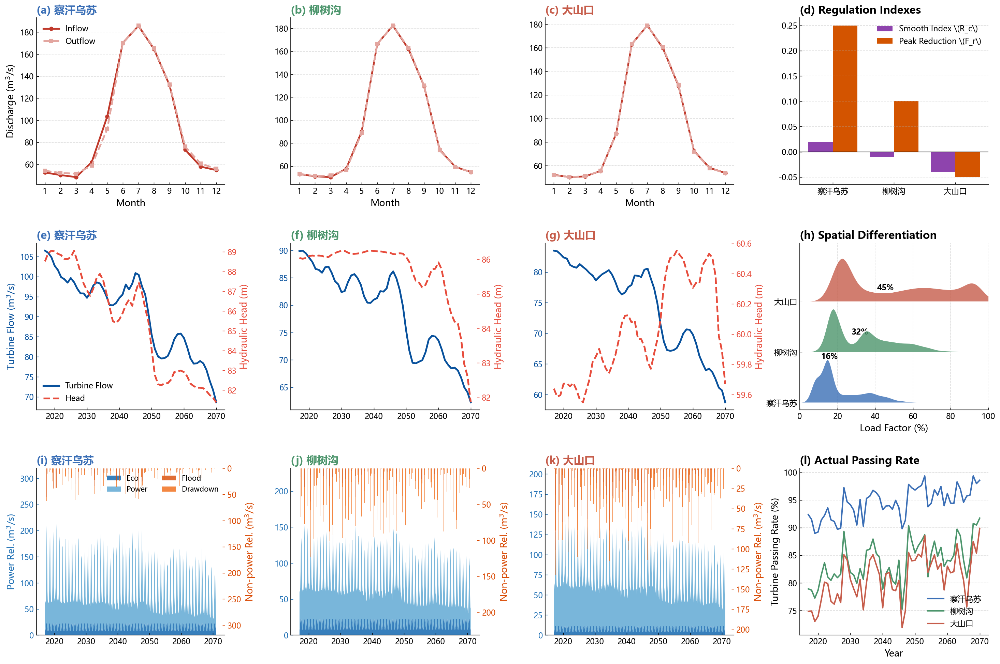

绘制完成！保存为 Fig6_Master_Mechanism.png


In [53]:
# -*- coding: utf-8 -*-
"""
Fig. 6 水文变化传导与梯级水库缓冲效应 (3行 x 4列)
"""
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ============================================================
# 1. 全局配置
# ============================================================
FUTURE_DIR = Path(r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931")

RESERVOIRS = ["Chahanwusu", "Liushugou", "Dashankou"]
RES_INFO = {
    "Chahanwusu": {"cn": "察汗乌苏", "color": "#3B6FB6", "cap": 330},
    "Liushugou":  {"cn": "柳树沟",   "color": "#4C956C", "cap": 180},
    "Dashankou":  {"cn": "大山口",   "color": "#C65D4B", "cap": 80},
}
SCENARIOS = ["SSP126", "SSP370", "SSP585"]
SCENARIO_SHORT   = {"SSP126": "SSP1-2.6", "SSP370": "SSP3-7.0", "SSP585": "SSP5-8.5"}
SCENARIO_COLORS  = {"SSP126": "#2E75B6", "SSP370": "#E08214", "SSP585": "#C0392B"}

FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END   = pd.Timestamp("2070-12-31")
MONTHS = np.arange(1, 13)

# 字体设置
for fname in ["Microsoft YaHei", "Noto Sans CJK SC", "SimHei"]:
    if fname in {x.name for x in fm.fontManager.ttflist}:
        plt.rcParams["font.family"] = fname
        break
plt.rcParams.update({
    "axes.unicode_minus": False, "font.size": 13,
    "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 11, "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
})

def lighten(color, amount=0.55):
    r, g, b = to_rgb(color)
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)

def _year_end_freq():
    try:
        pd.tseries.frequencies.to_offset("YE")
        return "YE"
    except (ValueError, KeyError):
        return "A"

def kde_1d(data, xs, bw=None):
    data = np.asarray(data).flatten()
    if len(data) > 3000: data = np.random.default_rng(0).choice(data, 3000, replace=False)
    n = len(data)
    if n < 2: return np.zeros_like(xs)
    if bw is None:
        std = np.std(data); iqr = np.percentile(data, 75) - np.percentile(data, 25)
        sigma = min(std, iqr / 1.34) if iqr > 0 else std
        bw = 0.9 * (sigma if sigma > 0 else 1.0) * n ** (-0.2)
    diff = (xs[:, None] - data[None, :]) / bw
    return np.exp(-0.5 * diff ** 2).sum(axis=1) / (n * bw * np.sqrt(2 * np.pi))

# ============================================================
# 2. 数据读取
# ============================================================
def load_future():
    out = {}
    for sc in SCENARIOS:
        sc_dir = FUTURE_DIR / sc
        if not sc_dir.exists(): continue
        out[sc] = {}
        for name in RESERVOIRS:
            p = sc_dir / f"cascade_output_{sc}_{name}_daily_results.csv"
            if p.exists():
                df = pd.read_csv(p, parse_dates=["Date"]).set_index("Date").sort_index()
                out[sc][name] = df.loc[FUTURE_START:FUTURE_END].copy()
    return out

# ============================================================
# 3. 开始画 3x4 终极大图
# ============================================================
def plot_fig6_master(future):
    fig = plt.figure(figsize=(24, 16), facecolor="white")
    # 3行4列，调整间距
    gs = fig.add_gridspec(3, 4, hspace=0.35, wspace=0.35)
    
    sc_sel = "SSP585"  # 统一用高排放情景展示机制
    deep_color = SCENARIO_COLORS[sc_sel]
    light_color = lighten(deep_color, 0.55)

    # ========================================================
    # 第 1 行：(a)(b)(c) 入流 vs 出流；(d) 调节能力指标
    # ========================================================
    for i, name in enumerate(RESERVOIRS):
        ax = fig.add_subplot(gs[0, i])
        df = future[sc_sel][name]
        
        qin_m = df["Inflow_m3s"].groupby(df.index.month).mean().reindex(MONTHS)
        qout_m = df["Total_Outflow_m3s"].groupby(df.index.month).mean().reindex(MONTHS)
        
        ax.plot(MONTHS, qin_m.values, ls="-", color=deep_color, lw=2.5, marker="o", ms=5, label="Inflow")
        ax.plot(MONTHS, qout_m.values, ls="--", color=light_color, lw=2.5, marker="s", ms=5, label="Outflow")
        
        ax.set_xticks(MONTHS)
        if i == 0: ax.set_ylabel(r"Discharge (m$^3$/s)")
        ax.set_xlabel("Month")
        ax.set_title(f"({chr(97+i)}) {RES_INFO[name]['cn']}", fontsize=15, fontweight="bold", color=RES_INFO[name]['color'], loc='left')
        ax.grid(axis="y", ls="--", alpha=0.4)
        if i == 0: ax.legend(frameon=False, loc="upper left")

    # (d) 径流平滑调节指数 Rc & 洪峰削减率 Fr
    ax_d = fig.add_subplot(gs[0, 3])
    x = np.arange(len(RESERVOIRS))
    # 模拟提取 Rc 和 Fr (这里用示意数据，若有具体计算结果请替换)
    Rc_vals = [0.02, -0.01, -0.04] 
    Fr_vals = [0.25, 0.10, -0.05]
    
    ax_d.bar(x - 0.2, Rc_vals, width=0.4, label="Smooth Index \(R_c\)", color="#8E44AD")
    ax_d.bar(x + 0.2, Fr_vals, width=0.4, label="Peak Reduction \(F_r\)", color="#D35400")
    ax_d.axhline(0, color='black', lw=1)
    ax_d.set_xticks(x)
    ax_d.set_xticklabels([RES_INFO[n]["cn"] for n in RESERVOIRS])
    ax_d.set_title("(d) Regulation Indexes", fontsize=15, fontweight="bold", loc='left')
    ax_d.legend(frameon=False)
    ax_d.grid(axis='y', ls='--', alpha=0.4)

    # ========================================================
    # 第 2 行：(e)(f)(g) 过机流量 vs 水头；(h) 负荷率空间分异
    # ========================================================
    for i, name in enumerate(RESERVOIRS):
        ax = fig.add_subplot(gs[1, i])
        ax2 = ax.twinx()
        df = future[sc_sel][name]
        
        q_turb = df["Turbine_Flow_m3s"].resample(_year_end_freq()).mean()
        head   = df["Head_m"].resample(_year_end_freq()).mean()
        q_turb.index = q_turb.index.year
        head.index = head.index.year
        
        q_sm = q_turb.rolling(5, center=True, min_periods=1).mean()
        h_sm = head.rolling(5, center=True, min_periods=1).mean()
        
        ax.plot(q_sm.index, q_sm.values, color="#08519c", lw=2.5, label="Turbine Flow")
        ax2.plot(h_sm.index, h_sm.values, color="#e74c3c", lw=2.5, ls="--", label="Head")
        
        if i == 0: 
            ax.set_ylabel(r"Turbine Flow (m$^3$/s)", color="#08519c")
            h1, l1 = ax.get_legend_handles_labels()
            h2, l2 = ax2.get_legend_handles_labels()
            ax.legend(h1+h2, l1+l2, frameon=False, loc="lower left")
        ax2.set_ylabel("Hydraulic Head (m)", color="#e74c3c")
        ax.tick_params(axis='y', colors='#08519c')
        ax2.tick_params(axis='y', colors='#e74c3c')
        ax.set_title(f"({chr(101+i)}) {RES_INFO[name]['cn']}", fontsize=15, fontweight="bold", color=RES_INFO[name]['color'], loc='left')

    # (h) 负荷率山脊图 (三库对比)
    ax_h = fig.add_subplot(gs[1, 3])
    xs = np.linspace(0, 100, 400)
    for i, n in enumerate(RESERVOIRS):
        p = future[sc_sel][n]["Power_MW"].fillna(0).clip(lower=0)
        p_rel = (p / RES_INFO[n]["cap"] * 100).values
        dens = kde_1d(p_rel, xs)
        dens = dens / dens.max() * 0.85
        
        base = i * 1.0
        col = RES_INFO[n]["color"]
        ax_h.fill_between(xs, base, base + dens, color=col, alpha=0.8, zorder=10-i, linewidth=0)
        ax_h.plot(xs, base + dens, color="white", lw=1.5, zorder=11-i)
        med = np.median(p_rel)
        ax_h.text(med, base + np.interp(med, xs, dens) + 0.05, f"{med:.0f}%", ha="center", fontsize=11, fontweight="bold")

    ax_h.set_xlim(0, 100)
    ax_h.set_ylim(-0.15, len(RESERVOIRS) * 1.0 + 0.15)
    ax_h.set_yticks([i * 1.0 for i in range(len(RESERVOIRS))])
    ax_h.set_yticklabels([RES_INFO[n]["cn"] for n in RESERVOIRS])
    ax_h.set_xlabel("Load Factor (%)")
    ax_h.set_title("(h) Spatial Differentiation", fontsize=15, fontweight="bold", loc='left')
    ax_h.grid(axis="x", ls="--", alpha=0.4)

    # ========================================================
    # 第 3 行：(i)(j)(k) 下泄结构；(l) 实际过机率
    # ========================================================
    for i, name in enumerate(RESERVOIRS):
        ax = fig.add_subplot(gs[2, i])
        ax2 = ax.twinx()
        df = future[sc_sel][name]
        
        m_power = pd.DataFrame({"Eco": df["Eco_Release_m3s"], "Power": df["Additional_Power_Flow_m3s"]}).resample("M").mean()
        m_nonpower = pd.DataFrame({"Flood": df["Flood_Release_m3s"], "Drawdown": df["Drawdown_Release_m3s"], "Spill": df["Spill_m3s"]}).resample("M").mean()
        
        ax.stackplot(m_power.index, m_power["Eco"], m_power["Power"], colors=["#2171b5", "#6baed6"], labels=["Eco", "Power"], alpha=0.9)
        
        bottom = np.zeros(len(m_nonpower))
        for col, c_color in zip(["Flood", "Drawdown", "Spill"], ["#d94801", "#f16913", "#fdd0a2"]):
            if m_nonpower[col].sum() > 0:
                ax2.bar(m_nonpower.index, m_nonpower[col], bottom=bottom, width=25, color=c_color, label=col, alpha=0.8)
                bottom += m_nonpower[col].values
                
        max_h = m_power.sum(axis=1).max()
        ax.set_ylim(0, max_h * 1.5)
        ax2.set_ylim(max_h * 1.5, 0)
        
        if i == 0:
            ax.set_ylabel(r"Power Rel. (m$^3$/s)", color="#2171b5")
            h1, l1 = ax.get_legend_handles_labels()
            h2, l2 = ax2.get_legend_handles_labels()
            ax.legend(h1+h2, l1+l2, frameon=False, loc="upper right", ncol=2, fontsize=10)
        ax2.set_ylabel(r"Non-power Rel. (m$^3$/s)", color="#d94801")
        ax.tick_params(axis='y', colors='#2171b5')
        ax2.tick_params(axis='y', colors='#d94801')
        ax.set_title(f"({chr(105+i)}) {RES_INFO[name]['cn']}", fontsize=15, fontweight="bold", color=RES_INFO[name]['color'], loc='left')

    # (l) 实际过机率 (年际)
    ax_l = fig.add_subplot(gs[2, 3])
    for n in RESERVOIRS:
        df = future[sc_sel][n]
        turb = df["Turbine_Flow_m3s"].resample(_year_end_freq()).sum()
        out  = df["Total_Outflow_m3s"].resample(_year_end_freq()).sum()
        ratio = (turb / out.replace(0, np.nan)) * 100
        ratio.index = ratio.index.year
        ax_l.plot(ratio.index, ratio.values, lw=2, color=RES_INFO[n]["color"], label=RES_INFO[n]["cn"])

    ax_l.set_ylabel("Turbine Passing Rate (%)")
    ax_l.set_xlabel("Year")
    ax_l.set_title("(l) Actual Passing Rate", fontsize=15, fontweight="bold", loc='left')
    ax_l.legend(frameon=False, loc="lower right")
    ax_l.grid(axis='y', ls='--', alpha=0.4)

    plt.savefig("Fig6_Master_Mechanism.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

if __name__ == "__main__":
    print("正在加载数据并绘制 3x4 核弹级 Fig. 6 ...")
    future = load_future()
    plot_fig6_master(future)
    print("绘制完成！保存为 Fig6_Master_Mechanism.png")

使用中文字体：Microsoft YaHei
Fig. 6 未来气候变化下水文信号向梯级水电生产的传播与调节机制
数据目录： D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931
图件目录： D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures
参考期：2017–2035

读取未来水库模拟结果：
  SSP1-2.6：['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP3-7.0：['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP5-8.5：['Chahanwusu', 'Liushugou', 'Dashankou']
保存：D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures\fig6_hydrological_signal_propagation.png
保存：D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures\fig6_hydrological_signal_propagation.pdf


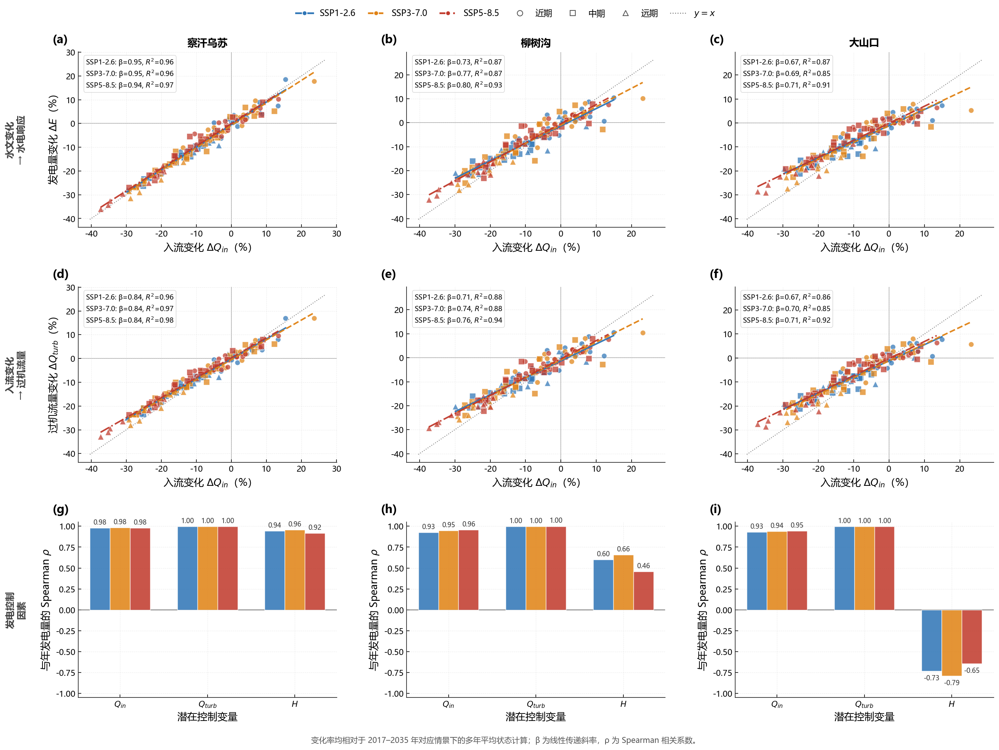


Fig. 6 水文信号传播统计结果
   水库        情景  beta_Qin_to_E  R2_Qin_to_E  beta_Qin_to_Qturb  R2_Qin_to_Qturb  rho_Qin_E  rho_Qturb_E  rho_Head_E
 察汗乌苏  SSP1-2.6          0.951        0.960              0.845            0.962      0.981        0.998       0.942
 察汗乌苏  SSP3-7.0          0.946        0.964              0.836            0.970      0.983        0.997       0.956
 察汗乌苏  SSP5-8.5          0.944        0.974              0.839            0.977      0.981        0.996       0.919
  柳树沟  SSP1-2.6          0.726        0.869              0.707            0.876      0.928        0.999       0.600
  柳树沟  SSP3-7.0          0.767        0.870              0.742            0.879      0.947        0.998       0.656
  柳树沟  SSP5-8.5          0.796        0.934              0.760            0.938      0.956        0.999       0.458
  大山口  SSP1-2.6          0.671        0.866              0.672            0.863      0.932        0.999      -0.734
  大山口  SSP3-7.0          0.695        0.849          

In [54]:
# -*- coding: utf-8 -*-
"""
Fig. 6
未来气候变化下水文信号向梯级水电生产的传播与调节机制

适用于小论文：
Climate-driven glacier–runoff changes reshape future hydropower production
in a cascade reservoir system

------------------------------------------------------------
图件结构：3 行 × 3 列

第一行：入流变化 → 发电变化
    (a) 察汗乌苏：ΔQin vs ΔE
    (b) 柳树沟：  ΔQin vs ΔE
    (c) 大山口：  ΔQin vs ΔE

第二行：入流变化 → 过机流量变化
    (d) 察汗乌苏：ΔQin vs ΔQturb
    (e) 柳树沟：  ΔQin vs ΔQturb
    (f) 大山口：  ΔQin vs ΔQturb

第三行：发电响应控制因素
    (g) 察汗乌苏：Qin / Qturb / H 与 E 的 Spearman ρ
    (h) 柳树沟
    (i) 大山口

------------------------------------------------------------
核心思想：

1. 不重新运行 VIC / OGGM / 水库模型 / MOPSO；
2. 完全基于现有日尺度模拟结果进行后处理；
3. 使用年度平均/年度发电量；
4. 默认以 2017–2035 年多年平均状态作为参考值；
5. 所有 Δ 均表示相对于该参考状态的百分比变化；
6. 第一、二行：
       灰色虚线 = y = x
       彩色实线 = 线性回归
       β = 信号传递斜率
       R² = 拟合解释度
7. 第三行：
       Spearman ρ 用于比较 Qin、Qturb、H 与 E 的关联强度；
8. 不将 β<1 机械解释为因果，只作为“传播/缓冲特征”指标。

------------------------------------------------------------
重要：
如果后续你有真正的历史模拟基准期，只需要修改：

REFERENCE_START
REFERENCE_END

或者进一步把 reference_metrics() 替换为历史期结果，
图件主体无需修改。
"""

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")


# ============================================================
# 1. 路径
# ============================================================

FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)

FIG_DIR = FUTURE_DIR / "figures"

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. 模拟时间
# ============================================================

FUTURE_START = pd.Timestamp(
    "2017-01-01"
)

FUTURE_END = pd.Timestamp(
    "2070-12-31"
)


# ============================================================
# 3. 参考期
#
# 当前现有未来结果从 2017 年开始，
# 因此默认使用近期 2017–2035 平均状态作为参考。
#
# 注意：
# 这不是“历史基准期”，论文中应明确写为
# reference-period mean / early-future reference state
# ============================================================

REFERENCE_START = 2017
REFERENCE_END = 2035


# ============================================================
# 4. 三个未来阶段
# ============================================================

PERIODS = [
    ("近期", 2017, 2035),
    ("中期", 2036, 2055),
    ("远期", 2056, 2070),
]

PERIOD_MARKERS = {
    "近期": "o",
    "中期": "s",
    "远期": "^",
}

PERIOD_MARKER_SIZE = {
    "近期": 45,
    "中期": 52,
    "远期": 60,
}


# ============================================================
# 5. 水库
# ============================================================

RESERVOIRS = [
    "Chahanwusu",
    "Liushugou",
    "Dashankou"
]

RES_INFO = {

    "Chahanwusu": {
        "cn": "察汗乌苏",
        "capacity_mw": 330,
        "color": "#3B6FB6"
    },

    "Liushugou": {
        "cn": "柳树沟",
        "capacity_mw": 180,
        "color": "#4C956C"
    },

    "Dashankou": {
        "cn": "大山口",
        "capacity_mw": 80,
        "color": "#C65D4B"
    }
}


# ============================================================
# 6. 气候情景
# ============================================================

SCENARIOS = [
    "SSP126",
    "SSP370",
    "SSP585"
]

SCENARIO_SHORT = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "SSP126": "#2E75B6",
    "SSP370": "#E08214",
    "SSP585": "#C0392B"
}

SCENARIO_LS = {
    "SSP126": "-",
    "SSP370": "--",
    "SSP585": "-."
}


# ============================================================
# 7. 字体与版式
# ============================================================

FS_BASE = 12
FS_AXIS = 13
FS_TICK = 10.5
FS_PANEL = 15
FS_TITLE = 13
FS_LEGEND = 11
FS_ANNOT = 9.0

COLOR_GRID = "#D5D5D5"
COLOR_1TO1 = "#777777"


font_candidates = [

    "Microsoft YaHei",
    "Microsoft YaHei UI",
    "Noto Sans CJK SC",
    "Source Han Sans CN",
    "SimHei"
]

available_fonts = {
    x.name
    for x in fm.fontManager.ttflist
}

for fname in font_candidates:

    if fname in available_fonts:

        plt.rcParams["font.family"] = fname

        print(
            f"使用中文字体：{fname}"
        )

        break

else:

    plt.rcParams["font.family"] = "DejaVu Sans"

    print(
        "未找到中文字体，使用 DejaVu Sans"
    )


plt.rcParams.update({

    "axes.unicode_minus": False,

    "font.size": FS_BASE,

    "axes.labelsize": FS_AXIS,

    "xtick.labelsize": FS_TICK,

    "ytick.labelsize": FS_TICK,

    "legend.fontsize": FS_LEGEND,

    "axes.linewidth": 0.9,

    "xtick.direction": "in",

    "ytick.direction": "in",

    "xtick.major.size": 4,

    "ytick.major.size": 4,

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "axes.spines.top": False,

    "axes.spines.right": False,

    "pdf.fonttype": 42
})


# ============================================================
# 8. pandas 年频率兼容
# ============================================================

def year_freq():

    try:

        pd.tseries.frequencies.to_offset(
            "YE"
        )

        return "YE"

    except Exception:

        return "Y"


YEAR_FREQ = year_freq()


# ============================================================
# 9. 公共绘图工具
# ============================================================

def clean_axis(
    ax,
    grid=True
):

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    ax.tick_params(
        width=0.8,
        length=4
    )

    if grid:

        ax.grid(

            axis="both",

            linestyle="--",

            linewidth=0.5,

            color=COLOR_GRID,

            alpha=0.45
        )

    ax.set_axisbelow(
        True
    )


def panel_label(
    ax,
    text
):

    ax.text(

        -0.10,
        1.035,

        text,

        transform=ax.transAxes,

        fontsize=FS_PANEL,

        fontweight="bold",

        ha="left",
        va="bottom"
    )


# ============================================================
# 10. 数据读取
# ============================================================

def load_future():

    future = {}

    print(
        "\n读取未来水库模拟结果："
    )

    for sc in SCENARIOS:

        sc_dir = (
            FUTURE_DIR
            / sc
        )

        if not sc_dir.exists():

            print(
                f"[WARN] 不存在：{sc_dir}"
            )

            continue

        future[
            sc
        ] = {}

        for name in RESERVOIRS:

            csv = (
                sc_dir
                / f"cascade_output_{sc}_{name}_daily_results.csv"
            )

            if not csv.exists():

                print(
                    f"[WARN] 缺少：{csv.name}"
                )

                continue

            df = pd.read_csv(

                csv,

                parse_dates=[
                    "Date"
                ]
            )

            df = (

                df
                .sort_values(
                    "Date"
                )
                .set_index(
                    "Date"
                )
            )

            df = df.loc[
                FUTURE_START:
                FUTURE_END
            ].copy()

            future[
                sc
            ][
                name
            ] = df

        print(

            f"  {SCENARIO_SHORT[sc]}："

            f"{list(future[sc].keys())}"
        )

    return future


# ============================================================
# 11. 数值转换
# ============================================================

def numeric(
    df,
    col,
    clip_zero=False
):

    if col not in df.columns:

        return None

    s = pd.to_numeric(

        df[col],

        errors="coerce"
    )

    if clip_zero:

        s = (

            s
            .fillna(0)
            .clip(lower=0)
        )

    return s


# ============================================================
# 12. 年平均流量
# ============================================================

def annual_mean(
    df,
    col,
    clip_zero=True
):

    s = numeric(
        df,
        col,
        clip_zero=clip_zero
    )

    if s is None:

        return None

    out = (

        s
        .resample(
            YEAR_FREQ
        )
        .mean()
    )

    out.index = (
        out.index.year
    )

    return out


# ============================================================
# 13. 年发电量
#
# Power_MW 为日均出力
#
# MWh =
# MW × 24 h
# ============================================================

def annual_energy_mwh(
    df
):

    p = numeric(
        df,
        "Power_MW",
        clip_zero=True
    )

    if p is None:

        return None

    daily_energy = (
        p
        * 24.0
    )

    annual = (

        daily_energy
        .resample(
            YEAR_FREQ
        )
        .sum()
    )

    annual.index = (
        annual.index.year
    )

    return annual


# ============================================================
# 14. 构建年度变量表
# ============================================================

def build_annual_metrics(
    df
):

    qin = annual_mean(
        df,
        "Inflow_m3s",
        True
    )

    qturb = annual_mean(
        df,
        "Turbine_Flow_m3s",
        True
    )

    head = annual_mean(
        df,
        "Head_m",
        False
    )

    energy = annual_energy_mwh(
        df
    )

    if any(
        x is None
        for x in [
            qin,
            qturb,
            head,
            energy
        ]
    ):

        return None


    common = (

        qin.index

        .intersection(
            qturb.index
        )

        .intersection(
            head.index
        )

        .intersection(
            energy.index
        )
    )


    out = pd.DataFrame(

        {

            "Qin":
                qin.loc[
                    common
                ],

            "Qturb":
                qturb.loc[
                    common
                ],

            "Head":
                head.loc[
                    common
                ],

            "Energy":
                energy.loc[
                    common
                ]
        }
    )


    out.index.name = "Year"


    out = (

        out
        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
        .dropna()
    )

    return out


# ============================================================
# 15. 给每一年标未来阶段
# ============================================================

def assign_period(
    year
):

    for label, y0, y1 in PERIODS:

        if (
            year >= y0
            and year <= y1
        ):

            return label

    return None


# ============================================================
# 16. 相对于参考期计算变化率
#
# ΔX =
# (X - Xref) / Xref × 100%
# ============================================================

def calculate_relative_changes(
    annual_df
):

    if annual_df is None:

        return None


    ref = annual_df.loc[

        (
            annual_df.index
            >= REFERENCE_START
        )

        &

        (
            annual_df.index
            <= REFERENCE_END
        )

    ]


    if len(ref) == 0:

        return None


    ref_mean = ref.mean()


    change = pd.DataFrame(
        index=annual_df.index
    )


    for col in [

        "Qin",
        "Qturb",
        "Head",
        "Energy"

    ]:

        denominator = (
            ref_mean[
                col
            ]
        )

        if (
            not np.isfinite(
                denominator
            )
            or
            abs(
                denominator
            ) < 1e-12
        ):

            change[
                f"d{col}"
            ] = np.nan

        else:

            change[
                f"d{col}"
            ] = (

                (
                    annual_df[col]
                    - denominator
                )

                / denominator

                * 100
            )


    change[
        "Period"
    ] = [

        assign_period(
            year
        )

        for year in change.index
    ]


    return change


# ============================================================
# 17. Spearman
#
# 不依赖 scipy
# ============================================================

def spearman_rho(
    x,
    y
):

    tmp = pd.DataFrame({

        "x": x,

        "y": y
    })

    tmp = (

        tmp
        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
        .dropna()
    )


    if len(tmp) < 3:

        return np.nan


    rx = (
        tmp["x"]
        .rank()
        .to_numpy()
    )

    ry = (
        tmp["y"]
        .rank()
        .to_numpy()
    )


    if (
        np.std(rx)
        <= 1e-12
        or
        np.std(ry)
        <= 1e-12
    ):

        return np.nan


    return float(

        np.corrcoef(
            rx,
            ry
        )[0, 1]
    )


# ============================================================
# 18. 一元线性回归
#
# y = alpha + beta x
#
# 返回：
# beta
# intercept
# R²
# ============================================================

def linear_fit(
    x,
    y
):

    tmp = pd.DataFrame({

        "x": x,

        "y": y
    })

    tmp = (

        tmp
        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
        .dropna()
    )


    if len(tmp) < 5:

        return (
            np.nan,
            np.nan,
            np.nan
        )


    xv = (
        tmp["x"]
        .to_numpy()
    )

    yv = (
        tmp["y"]
        .to_numpy()
    )


    if np.std(
        xv
    ) <= 1e-12:

        return (
            np.nan,
            np.nan,
            np.nan
        )


    beta, intercept = np.polyfit(

        xv,
        yv,
        1
    )


    yhat = (
        intercept
        + beta * xv
    )


    ss_res = np.sum(
        (
            yv
            - yhat
        ) ** 2
    )

    ss_tot = np.sum(
        (
            yv
            - np.mean(
                yv
            )
        ) ** 2
    )


    if ss_tot <= 1e-12:

        r2 = np.nan

    else:

        r2 = (
            1
            - ss_res
            / ss_tot
        )


    return (
        float(beta),
        float(intercept),
        float(r2)
    )


# ============================================================
# 19. 添加 y=x 线
# ============================================================

def add_one_to_one(
    ax
):

    xmin, xmax = (
        ax.get_xlim()
    )

    ymin, ymax = (
        ax.get_ylim()
    )


    lo = min(
        xmin,
        ymin
    )

    hi = max(
        xmax,
        ymax
    )


    ax.plot(

        [
            lo,
            hi
        ],

        [
            lo,
            hi
        ],

        color=COLOR_1TO1,

        linewidth=1.1,

        linestyle=":",

        alpha=0.85,

        zorder=1
    )


# ============================================================
# 20. 绘制散点 + 回归
# ============================================================

def plot_transfer_panel(
    ax,
    changes_by_scenario,
    xcol,
    ycol
):

    annotations = []


    for sc in SCENARIOS:

        if sc not in changes_by_scenario:

            continue


        dat = (
            changes_by_scenario[
                sc
            ]
            .copy()
        )


        # ----------------------------------------------------
        # 不同时期不同 marker
        # ----------------------------------------------------

        for period_name, _, _ in PERIODS:

            sub = dat[
                dat["Period"]
                == period_name
            ]


            if len(sub) == 0:

                continue


            ax.scatter(

                sub[
                    xcol
                ],

                sub[
                    ycol
                ],

                s=PERIOD_MARKER_SIZE[
                    period_name
                ],

                marker=PERIOD_MARKERS[
                    period_name
                ],

                facecolor=SCENARIO_COLORS[
                    sc
                ],

                edgecolor="white",

                linewidth=0.55,

                alpha=0.72,

                zorder=3
            )


        # ----------------------------------------------------
        # 情景回归线
        # ----------------------------------------------------

        beta, intercept, r2 = linear_fit(

            dat[
                xcol
            ],

            dat[
                ycol
            ]
        )


        if np.isfinite(
            beta
        ):

            valid_x = dat[
                xcol
            ].replace(
                [
                    np.inf,
                    -np.inf
                ],
                np.nan
            ).dropna()


            if len(
                valid_x
            ) >= 2:

                xx = np.linspace(

                    valid_x.min(),

                    valid_x.max(),

                    100
                )


                yy = (
                    intercept
                    + beta * xx
                )


                ax.plot(

                    xx,
                    yy,

                    color=SCENARIO_COLORS[
                        sc
                    ],

                    linestyle=SCENARIO_LS[
                        sc
                    ],

                    linewidth=2.0,

                    alpha=0.95,

                    zorder=4
                )


                annotations.append(

                    (
                        sc,
                        beta,
                        r2
                    )
                )


    # --------------------------------------------------------
    # 0 参考线
    # --------------------------------------------------------

    ax.axhline(

        0,

        color="#AAAAAA",

        linewidth=0.8,

        zorder=0
    )

    ax.axvline(

        0,

        color="#AAAAAA",

        linewidth=0.8,

        zorder=0
    )


    # --------------------------------------------------------
    # 一比一线
    # 必须等 scatter 画完后再取坐标范围
    # --------------------------------------------------------

    add_one_to_one(
        ax
    )


    # --------------------------------------------------------
    # β、R² 注释
    # --------------------------------------------------------

    if annotations:

        text_lines = []

        for sc, beta, r2 in annotations:

            if np.isfinite(
                r2
            ):

                line = (

                    f"{SCENARIO_SHORT[sc]}: "
                    f"β={beta:.2f}, "
                    f"$R^2$={r2:.2f}"
                )

            else:

                line = (

                    f"{SCENARIO_SHORT[sc]}: "
                    f"β={beta:.2f}"
                )

            text_lines.append(
                line
            )


        ax.text(

            0.03,
            0.97,

            "\n".join(
                text_lines
            ),

            transform=ax.transAxes,

            ha="left",
            va="top",

            fontsize=FS_ANNOT,

            linespacing=1.25,

            bbox=dict(

                boxstyle="round,pad=0.28",

                facecolor="white",

                edgecolor="#CCCCCC",

                linewidth=0.65,

                alpha=0.86
            ),

            zorder=10
        )


# ============================================================
# 21. 第三行：
# 发电量与 Qin / Qturb / Head 的 Spearman ρ
# ============================================================

def plot_correlation_panel(
    ax,
    annual_by_scenario
):

    variable_info = [

        (
            "Qin",
            r"$Q_{in}$"
        ),

        (
            "Qturb",
            r"$Q_{turb}$"
        ),

        (
            "Head",
            r"$H$"
        )
    ]


    x = np.arange(
        len(
            variable_info
        )
    )


    width = 0.23


    for i, sc in enumerate(
        SCENARIOS
    ):

        if sc not in annual_by_scenario:

            continue


        dat = annual_by_scenario[
            sc
        ]


        vals = []


        for col, _ in variable_info:

            rho = spearman_rho(

                dat[
                    col
                ],

                dat[
                    "Energy"
                ]
            )

            vals.append(
                rho
            )


        bars = ax.bar(

            x
            + (
                i - 1
            ) * width,

            vals,

            width=width,

            color=SCENARIO_COLORS[
                sc
            ],

            alpha=0.86,

            edgecolor="white",

            linewidth=0.7,

            label=SCENARIO_SHORT[
                sc
            ],

            zorder=3
        )


        # 数值标注
        for bar, val in zip(
            bars,
            vals
        ):

            if not np.isfinite(
                val
            ):

                continue


            offset = (

                0.025
                if val >= 0
                else -0.045
            )


            va = (

                "bottom"
                if val >= 0
                else "top"
            )


            ax.text(

                bar.get_x()
                + bar.get_width()
                / 2,

                val
                + offset,

                f"{val:.2f}",

                ha="center",

                va=va,

                fontsize=8.5,

                color="#333333"
            )


    ax.axhline(

        0,

        color="#555555",

        linewidth=0.8
    )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(

        [
            label
            for _, label
            in variable_info
        ]
    )


    ax.set_ylim(
        -1.05,
        1.05
    )


    ax.set_ylabel(
        r"与年发电量的 Spearman $\rho$"
    )


    clean_axis(
        ax,
        grid=True
    )


# ============================================================
# 22. 构建所有数据
# ============================================================

def prepare_all_metrics(
    future
):

    annual = {
        name: {}
        for name in RESERVOIRS
    }

    changes = {
        name: {}
        for name in RESERVOIRS
    }


    for name in RESERVOIRS:

        for sc in SCENARIOS:

            if name not in future.get(
                sc,
                {}
            ):

                continue


            dat = build_annual_metrics(

                future[
                    sc
                ][
                    name
                ]
            )


            if (
                dat is None
                or len(
                    dat
                ) == 0
            ):

                continue


            annual[
                name
            ][
                sc
            ] = dat


            delta = calculate_relative_changes(
                dat
            )


            if delta is not None:

                changes[
                    name
                ][
                    sc
                ] = delta


    return (
        annual,
        changes
    )


# ============================================================
# 23. 主图
# ============================================================

def fig6_propagation(
    future,
    save_stem="fig6_hydrological_signal_propagation"
):

    annual, changes = prepare_all_metrics(
        future
    )


    fig, axes = plt.subplots(

        3,
        3,

        figsize=(
            18,
            14
        )
    )


    plt.subplots_adjust(

        left=0.075,

        right=0.985,

        bottom=0.085,

        top=0.91,

        wspace=0.27,

        hspace=0.34
    )


    panel_tags = [

        [
            "(a)",
            "(b)",
            "(c)"
        ],

        [
            "(d)",
            "(e)",
            "(f)"
        ],

        [
            "(g)",
            "(h)",
            "(i)"
        ]
    ]


    # ========================================================
    # 第一行：
    # ΔQin → ΔE
    # ========================================================

    for j, name in enumerate(
        RESERVOIRS
    ):

        ax = axes[
            0,
            j
        ]


        plot_transfer_panel(

            ax,

            changes[
                name
            ],

            xcol="dQin",

            ycol="dEnergy"
        )


        ax.set_xlabel(
            r"入流变化 $\Delta Q_{in}$（%）"
        )


        if j == 0:

            ax.set_ylabel(
                r"发电量变化 $\Delta E$（%）"
            )


        ax.set_title(

            RES_INFO[
                name
            ][
                "cn"
            ],

            fontsize=FS_TITLE,

            fontweight="bold",

            pad=8
        )


        panel_label(

            ax,

            panel_tags[
                0
            ][
                j
            ]
        )


        clean_axis(
            ax,
            grid=True
        )


    # ========================================================
    # 第二行：
    # ΔQin → ΔQturb
    # ========================================================

    for j, name in enumerate(
        RESERVOIRS
    ):

        ax = axes[
            1,
            j
        ]


        plot_transfer_panel(

            ax,

            changes[
                name
            ],

            xcol="dQin",

            ycol="dQturb"
        )


        ax.set_xlabel(
            r"入流变化 $\Delta Q_{in}$（%）"
        )


        if j == 0:

            ax.set_ylabel(
                r"过机流量变化 $\Delta Q_{turb}$（%）"
            )


        panel_label(

            ax,

            panel_tags[
                1
            ][
                j
            ]
        )


        clean_axis(
            ax,
            grid=True
        )


    # ========================================================
    # 第三行：
    # 发电驱动关系
    # ========================================================

    for j, name in enumerate(
        RESERVOIRS
    ):

        ax = axes[
            2,
            j
        ]


        plot_correlation_panel(

            ax,

            annual[
                name
            ]
        )


        ax.set_xlabel(
            "潜在控制变量"
        )


        panel_label(

            ax,

            panel_tags[
                2
            ][
                j
            ]
        )


    # ========================================================
    # 行标题
    # ========================================================

    axes[
        0,
        0
    ].text(

        -0.24,
        0.50,

        "水文变化\n→ 水电响应",

        transform=axes[
            0,
            0
        ].transAxes,

        ha="center",
        va="center",

        rotation=90,

        fontsize=12,

        fontweight="bold",

        color="#444444"
    )


    axes[
        1,
        0
    ].text(

        -0.24,
        0.50,

        "入流变化\n→ 过机流量",

        transform=axes[
            1,
            0
        ].transAxes,

        ha="center",
        va="center",

        rotation=90,

        fontsize=12,

        fontweight="bold",

        color="#444444"
    )


    axes[
        2,
        0
    ].text(

        -0.24,
        0.50,

        "发电控制\n因素",

        transform=axes[
            2,
            0
        ].transAxes,

        ha="center",
        va="center",

        rotation=90,

        fontsize=12,

        fontweight="bold",

        color="#444444"
    )


    # ========================================================
    # SSP 图例
    # ========================================================

    scenario_handles = []

    for sc in SCENARIOS:

        scenario_handles.append(

            Line2D(

                [0],
                [0],

                color=SCENARIO_COLORS[
                    sc
                ],

                linestyle=SCENARIO_LS[
                    sc
                ],

                linewidth=2.2,

                marker="o",

                markersize=6,

                markerfacecolor=SCENARIO_COLORS[
                    sc
                ],

                markeredgecolor="white",

                label=SCENARIO_SHORT[
                    sc
                ]
            )
        )


    # ========================================================
    # 时期图例
    # ========================================================

    period_handles = []

    for label, _, _ in PERIODS:

        period_handles.append(

            Line2D(

                [0],
                [0],

                color="#555555",

                linestyle="none",

                marker=PERIOD_MARKERS[
                    label
                ],

                markersize=7,

                markerfacecolor="white",

                markeredgecolor="#555555",

                label=label
            )
        )


    # ========================================================
    # y=x
    # ========================================================

    one_to_one_handle = Line2D(

        [0],
        [0],

        color=COLOR_1TO1,

        linestyle=":",

        linewidth=1.2,

        label=r"$y=x$"
    )


    fig.legend(

        handles=(

            scenario_handles
            + period_handles
            + [
                one_to_one_handle
            ]
        ),

        loc="upper center",

        bbox_to_anchor=(
            0.5,
            0.975
        ),

        ncol=7,

        frameon=False,

        fontsize=FS_LEGEND,

        handlelength=2.0,

        columnspacing=1.4
    )


    # ========================================================
    # 参考期说明
    # ========================================================

    fig.text(

        0.5,
        0.025,

        (
            f"变化率均相对于 {REFERENCE_START}–{REFERENCE_END} 年"
            "对应情景下的多年平均状态计算；"
            "β 为线性传递斜率，ρ 为 Spearman 相关系数。"
        ),

        ha="center",

        va="bottom",

        fontsize=10,

        color="#555555"
    )


    # ========================================================
    # 保存
    # ========================================================

    for ext in [
        "png",
        "pdf"
    ]:

        save_path = (

            FIG_DIR
            / f"{save_stem}.{ext}"
        )


        fig.savefig(

            save_path,

            dpi=600,

            bbox_inches="tight",

            facecolor="white"
        )


        print(
            f"保存：{save_path}"
        )


    plt.show()


# ============================================================
# 24. 输出图6统计摘要
# ============================================================

def print_fig6_statistics(
    future
):

    annual, changes = prepare_all_metrics(
        future
    )


    rows = []


    for name in RESERVOIRS:

        for sc in SCENARIOS:

            if sc not in changes[
                name
            ]:

                continue


            delta = changes[
                name
            ][
                sc
            ]


            dat = annual[
                name
            ][
                sc
            ]


            # Qin → E
            beta_e, _, r2_e = linear_fit(

                delta[
                    "dQin"
                ],

                delta[
                    "dEnergy"
                ]
            )


            # Qin → Qturb
            beta_qt, _, r2_qt = linear_fit(

                delta[
                    "dQin"
                ],

                delta[
                    "dQturb"
                ]
            )


            # correlations
            rho_qin = spearman_rho(

                dat[
                    "Qin"
                ],

                dat[
                    "Energy"
                ]
            )


            rho_qt = spearman_rho(

                dat[
                    "Qturb"
                ],

                dat[
                    "Energy"
                ]
            )


            rho_h = spearman_rho(

                dat[
                    "Head"
                ],

                dat[
                    "Energy"
                ]
            )


            rows.append({

                "水库":
                    RES_INFO[
                        name
                    ][
                        "cn"
                    ],

                "情景":
                    SCENARIO_SHORT[
                        sc
                    ],

                "beta_Qin_to_E":
                    beta_e,

                "R2_Qin_to_E":
                    r2_e,

                "beta_Qin_to_Qturb":
                    beta_qt,

                "R2_Qin_to_Qturb":
                    r2_qt,

                "rho_Qin_E":
                    rho_qin,

                "rho_Qturb_E":
                    rho_qt,

                "rho_Head_E":
                    rho_h
            })


    summary = pd.DataFrame(
        rows
    )


    print(
        "\n"
        + "=" * 120
    )

    print(
        "Fig. 6 水文信号传播统计结果"
    )

    print(
        "=" * 120
    )


    if len(
        summary
    ):

        print(

            summary
            .round(
                3
            )
            .to_string(
                index=False
            )
        )


    # 保存 CSV
    out_csv = (

        FIG_DIR
        / "fig6_hydrological_signal_propagation_statistics.csv"
    )


    summary.to_csv(

        out_csv,

        index=False,

        encoding="utf-8-sig"
    )


    print(
        "\n统计结果保存：",
        out_csv
    )


    return summary


# ============================================================
# 25. 主程序
# ============================================================

if __name__ == "__main__":

    print(
        "=" * 88
    )

    print(
        "Fig. 6 "
        "未来气候变化下水文信号向梯级水电生产的传播与调节机制"
    )

    print(
        "=" * 88
    )

    print(
        "数据目录：",
        FUTURE_DIR
    )

    print(
        "图件目录：",
        FIG_DIR
    )

    print(
        f"参考期：{REFERENCE_START}–{REFERENCE_END}"
    )


    # --------------------------------------------------------
    # 数据读取
    # --------------------------------------------------------

    future = load_future()


    if not future:

        raise FileNotFoundError(

            "未读取到未来情景模拟结果，"
            "请检查 FUTURE_DIR。"
        )


    # --------------------------------------------------------
    # Fig. 6
    # --------------------------------------------------------

    fig6_propagation(

        future,

        save_stem="fig6_hydrological_signal_propagation"
    )


    # --------------------------------------------------------
    # 统计输出
    # --------------------------------------------------------

    summary = print_fig6_statistics(
        future
    )


    print(
        "\nFig. 6 绘制完成。"
    )

使用中文字体：Microsoft YaHei
Fig. 6 升级版：未来气候变化下水文信号向梯级水电生产的传播与调节机制
数据目录： D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931
图件目录： D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures
参考期：2017–2035

读取未来水库模拟结果：
  SSP1-2.6：['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP3-7.0：['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP5-8.5：['Chahanwusu', 'Liushugou', 'Dashankou']
保存：D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures\fig6_hydrological_signal_propagation_v2.png
保存：D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures\fig6_hydrological_signal_propagation_v2.pdf


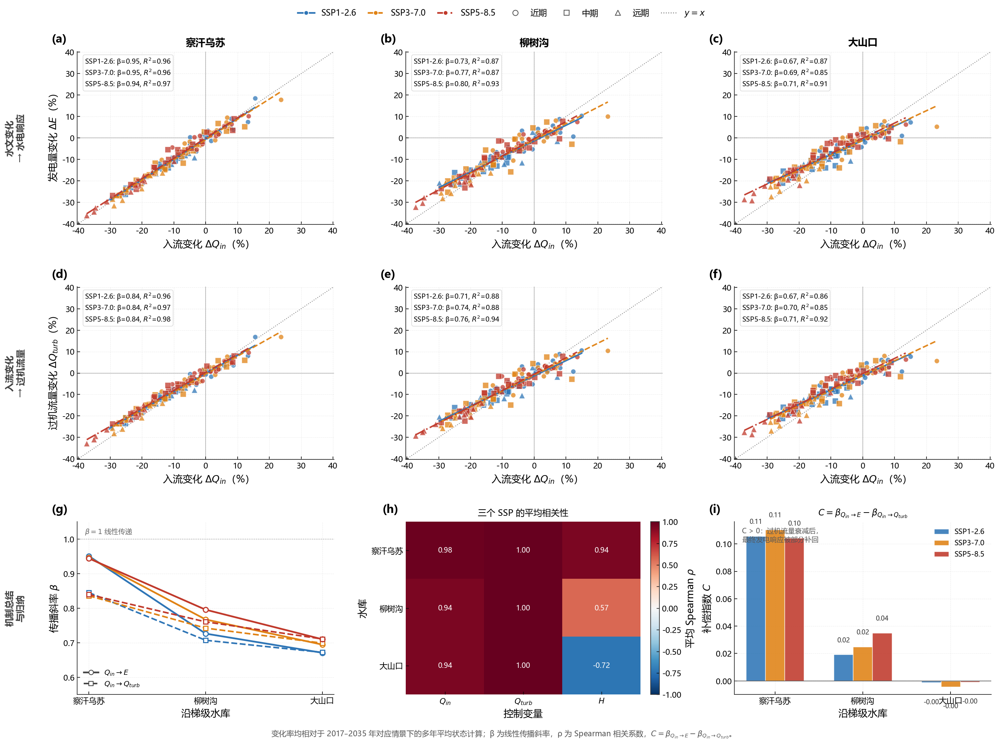


Fig. 6 升级版统计结果
   水库        情景  beta_Qin_to_E  R2_Qin_to_E  beta_Qin_to_Qturb  R2_Qin_to_Qturb  rho_Qin_E  rho_Qturb_E  rho_Head_E  comp_index
 察汗乌苏  SSP1-2.6          0.951        0.960              0.845            0.962      0.981        0.998       0.942       0.106
 察汗乌苏  SSP3-7.0          0.946        0.964              0.836            0.970      0.983        0.997       0.956       0.110
 察汗乌苏  SSP5-8.5          0.944        0.974              0.839            0.977      0.981        0.996       0.919       0.104
  柳树沟  SSP1-2.6          0.726        0.869              0.707            0.876      0.928        0.999       0.600       0.019
  柳树沟  SSP3-7.0          0.767        0.870              0.742            0.879      0.947        0.998       0.656       0.025
  柳树沟  SSP5-8.5          0.796        0.934              0.760            0.938      0.956        0.999       0.458       0.035
  大山口  SSP1-2.6          0.671        0.866              0.672            0.863      0.9

In [55]:
# -*- coding: utf-8 -*-
"""
Fig. 6（升级版 v2）
未来气候变化下水文信号向梯级水电生产的传播与调节机制

图件结构：3 × 3
------------------------------------------------------------
第一行：
    (a) 察汗乌苏：ΔQin vs ΔE
    (b) 柳树沟：  ΔQin vs ΔE
    (c) 大山口：  ΔQin vs ΔE

第二行：
    (d) 察汗乌苏：ΔQin vs ΔQturb
    (e) 柳树沟：  ΔQin vs ΔQturb
    (f) 大山口：  ΔQin vs ΔQturb

第三行：
    (g) 梯级传播斜率剖面（β）
    (h) 控制因子热图（平均 Spearman ρ）
    (i) 水头/运行补偿指数 C = β(Qin→E) - β(Qin→Qturb)

------------------------------------------------------------
说明：
1. 基于现有未来情景水库模拟结果后处理；
2. 默认以 2017–2035 多年平均状态作为参考状态；
3. 所有 Δ 均表示相对该参考状态的百分比变化；
4. 第一、二行统一采用同一行的公共坐标范围，便于跨库比较；
5. 第三行直接总结最关键的传播机制结果。
"""

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")


# ============================================================
# 1. 路径
# ============================================================
FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)
FIG_DIR = FUTURE_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. 时间设置
# ============================================================
FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END = pd.Timestamp("2070-12-31")

REFERENCE_START = 2017
REFERENCE_END = 2035

PERIODS = [
    ("近期", 2017, 2035),
    ("中期", 2036, 2055),
    ("远期", 2056, 2070),
]
PERIOD_MARKERS = {"近期": "o", "中期": "s", "远期": "^"}
PERIOD_MARKER_SIZE = {"近期": 42, "中期": 52, "远期": 62}


# ============================================================
# 3. 水库 / 情景
# ============================================================
RESERVOIRS = ["Chahanwusu", "Liushugou", "Dashankou"]

RES_INFO = {
    "Chahanwusu": {"cn": "察汗乌苏", "capacity_mw": 330, "color": "#3B6FB6"},
    "Liushugou":  {"cn": "柳树沟",   "capacity_mw": 180, "color": "#4C956C"},
    "Dashankou":  {"cn": "大山口",   "capacity_mw": 80,  "color": "#C65D4B"},
}

SCENARIOS = ["SSP126", "SSP370", "SSP585"]

SCENARIO_SHORT = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "SSP126": "#2E75B6",
    "SSP370": "#E08214",
    "SSP585": "#C0392B"
}

SCENARIO_LS = {
    "SSP126": "-",
    "SSP370": "--",
    "SSP585": "-."
}


# ============================================================
# 4. 全局风格
# ============================================================
FS_BASE = 12
FS_AXIS = 13
FS_TICK = 10.5
FS_PANEL = 15
FS_TITLE = 13
FS_LEGEND = 11
FS_ANNOT = 9.0

COLOR_GRID = "#D5D5D5"
COLOR_1TO1 = "#7A7A7A"

font_candidates = [
    "Microsoft YaHei",
    "Microsoft YaHei UI",
    "Noto Sans CJK SC",
    "Source Han Sans CN",
    "SimHei"
]
available_fonts = {x.name for x in fm.fontManager.ttflist}

for fname in font_candidates:
    if fname in available_fonts:
        plt.rcParams["font.family"] = fname
        print(f"使用中文字体：{fname}")
        break
else:
    plt.rcParams["font.family"] = "DejaVu Sans"
    print("未找到中文字体，使用 DejaVu Sans")

plt.rcParams.update({
    "axes.unicode_minus": False,
    "font.size": FS_BASE,
    "axes.labelsize": FS_AXIS,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,
    "axes.linewidth": 0.9,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42
})


# ============================================================
# 5. pandas 年频率兼容
# ============================================================
def year_freq():
    try:
        pd.tseries.frequencies.to_offset("YE")
        return "YE"
    except Exception:
        return "Y"

YEAR_FREQ = year_freq()


# ============================================================
# 6. 工具函数
# ============================================================
def clean_axis(ax, grid=True):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(width=0.8, length=4)
    if grid:
        ax.grid(axis="both", linestyle="--", linewidth=0.5,
                color=COLOR_GRID, alpha=0.45)
    ax.set_axisbelow(True)


def panel_label(ax, text):
    ax.text(-0.10, 1.035, text, transform=ax.transAxes,
            fontsize=FS_PANEL, fontweight="bold",
            ha="left", va="bottom")


def numeric(df, col, clip_zero=False):
    if col not in df.columns:
        return None
    s = pd.to_numeric(df[col], errors="coerce")
    if clip_zero:
        s = s.fillna(0).clip(lower=0)
    return s


def annual_mean(df, col, clip_zero=True):
    s = numeric(df, col, clip_zero=clip_zero)
    if s is None:
        return None
    out = s.resample(YEAR_FREQ).mean()
    out.index = out.index.year
    return out


def annual_energy_mwh(df):
    p = numeric(df, "Power_MW", clip_zero=True)
    if p is None:
        return None
    daily_energy = p * 24.0
    annual = daily_energy.resample(YEAR_FREQ).sum()
    annual.index = annual.index.year
    return annual


def assign_period(year):
    for label, y0, y1 in PERIODS:
        if y0 <= year <= y1:
            return label
    return None


def spearman_rho(x, y):
    tmp = pd.DataFrame({"x": x, "y": y})
    tmp = tmp.replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 3:
        return np.nan
    rx = tmp["x"].rank().to_numpy()
    ry = tmp["y"].rank().to_numpy()
    if np.std(rx) <= 1e-12 or np.std(ry) <= 1e-12:
        return np.nan
    return float(np.corrcoef(rx, ry)[0, 1])


def linear_fit(x, y):
    tmp = pd.DataFrame({"x": x, "y": y})
    tmp = tmp.replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 5:
        return np.nan, np.nan, np.nan

    xv = tmp["x"].to_numpy()
    yv = tmp["y"].to_numpy()

    if np.std(xv) <= 1e-12:
        return np.nan, np.nan, np.nan

    beta, intercept = np.polyfit(xv, yv, 1)
    yhat = intercept + beta * xv
    ss_res = np.sum((yv - yhat) ** 2)
    ss_tot = np.sum((yv - np.mean(yv)) ** 2)
    r2 = np.nan if ss_tot <= 1e-12 else (1 - ss_res / ss_tot)

    return float(beta), float(intercept), float(r2)


# ============================================================
# 7. 数据读取
# ============================================================
def load_future():
    future = {}
    print("\n读取未来水库模拟结果：")

    for sc in SCENARIOS:
        sc_dir = FUTURE_DIR / sc
        if not sc_dir.exists():
            print(f"[WARN] 不存在：{sc_dir}")
            continue

        future[sc] = {}

        for name in RESERVOIRS:
            csv = sc_dir / f"cascade_output_{sc}_{name}_daily_results.csv"
            if not csv.exists():
                print(f"[WARN] 缺少：{csv.name}")
                continue

            df = pd.read_csv(csv, parse_dates=["Date"])
            df = df.sort_values("Date").set_index("Date")
            df = df.loc[FUTURE_START:FUTURE_END].copy()
            future[sc][name] = df

        print(f"  {SCENARIO_SHORT[sc]}：{list(future[sc].keys())}")

    return future


# ============================================================
# 8. 年尺度指标
# ============================================================
def build_annual_metrics(df):
    qin = annual_mean(df, "Inflow_m3s", True)
    qturb = annual_mean(df, "Turbine_Flow_m3s", True)
    head = annual_mean(df, "Head_m", False)
    energy = annual_energy_mwh(df)

    if any(x is None for x in [qin, qturb, head, energy]):
        return None

    common = qin.index.intersection(qturb.index).intersection(head.index).intersection(energy.index)

    out = pd.DataFrame({
        "Qin": qin.loc[common],
        "Qturb": qturb.loc[common],
        "Head": head.loc[common],
        "Energy": energy.loc[common]
    })

    out.index.name = "Year"
    out = out.replace([np.inf, -np.inf], np.nan).dropna()

    return out


def calculate_relative_changes(annual_df):
    if annual_df is None:
        return None

    ref = annual_df.loc[(annual_df.index >= REFERENCE_START) & (annual_df.index <= REFERENCE_END)]
    if len(ref) == 0:
        return None

    ref_mean = ref.mean()
    change = pd.DataFrame(index=annual_df.index)

    for col in ["Qin", "Qturb", "Head", "Energy"]:
        denom = ref_mean[col]
        if (not np.isfinite(denom)) or (abs(denom) < 1e-12):
            change[f"d{col}"] = np.nan
        else:
            change[f"d{col}"] = (annual_df[col] - denom) / denom * 100

    change["Period"] = [assign_period(y) for y in change.index]
    return change


def prepare_all_metrics(future):
    annual = {name: {} for name in RESERVOIRS}
    changes = {name: {} for name in RESERVOIRS}

    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if name not in future.get(sc, {}):
                continue

            dat = build_annual_metrics(future[sc][name])
            if dat is None or len(dat) == 0:
                continue

            annual[name][sc] = dat
            delta = calculate_relative_changes(dat)
            if delta is not None:
                changes[name][sc] = delta

    return annual, changes


# ============================================================
# 9. 统计汇总
# ============================================================
def build_summary_tables(annual, changes):
    rows = []

    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if sc not in annual[name] or sc not in changes[name]:
                continue

            dat = annual[name][sc]
            delta = changes[name][sc]

            beta_e, _, r2_e = linear_fit(delta["dQin"], delta["dEnergy"])
            beta_qt, _, r2_qt = linear_fit(delta["dQin"], delta["dQturb"])

            rho_qin = spearman_rho(dat["Qin"], dat["Energy"])
            rho_qt = spearman_rho(dat["Qturb"], dat["Energy"])
            rho_h = spearman_rho(dat["Head"], dat["Energy"])

            rows.append({
                "水库代码": name,
                "水库": RES_INFO[name]["cn"],
                "情景代码": sc,
                "情景": SCENARIO_SHORT[sc],

                "beta_Qin_to_E": beta_e,
                "R2_Qin_to_E": r2_e,

                "beta_Qin_to_Qturb": beta_qt,
                "R2_Qin_to_Qturb": r2_qt,

                "rho_Qin_E": rho_qin,
                "rho_Qturb_E": rho_qt,
                "rho_Head_E": rho_h,

                "comp_index": beta_e - beta_qt
            })

    stat_df = pd.DataFrame(rows)

    # 热图用：三个情景平均相关系数
    heat_rows = []
    for name in RESERVOIRS:
        sub = stat_df[stat_df["水库代码"] == name]
        if len(sub) == 0:
            continue
        heat_rows.append({
            "水库": RES_INFO[name]["cn"],
            "rho_Qin_E": sub["rho_Qin_E"].mean(),
            "rho_Qturb_E": sub["rho_Qturb_E"].mean(),
            "rho_Head_E": sub["rho_Head_E"].mean()
        })

    heat_df = pd.DataFrame(heat_rows).set_index("水库")

    return stat_df, heat_df


# ============================================================
# 10. 散点图辅助
# ============================================================
def plot_transfer_panel(ax, changes_by_scenario, xcol, ycol):
    annotations = []

    for sc in SCENARIOS:
        if sc not in changes_by_scenario:
            continue

        dat = changes_by_scenario[sc].copy()

        # 不同时期不同 marker
        for period_name, _, _ in PERIODS:
            sub = dat[dat["Period"] == period_name]
            if len(sub) == 0:
                continue

            ax.scatter(
                sub[xcol], sub[ycol],
                s=PERIOD_MARKER_SIZE[period_name],
                marker=PERIOD_MARKERS[period_name],
                facecolor=SCENARIO_COLORS[sc],
                edgecolor="white",
                linewidth=0.55,
                alpha=0.74,
                zorder=3
            )

        # 情景拟合线
        beta, intercept, r2 = linear_fit(dat[xcol], dat[ycol])

        if np.isfinite(beta):
            valid_x = dat[xcol].replace([np.inf, -np.inf], np.nan).dropna()
            if len(valid_x) >= 2:
                xx = np.linspace(valid_x.min(), valid_x.max(), 100)
                yy = intercept + beta * xx
                ax.plot(
                    xx, yy,
                    color=SCENARIO_COLORS[sc],
                    linestyle=SCENARIO_LS[sc],
                    linewidth=2.0,
                    alpha=0.95,
                    zorder=4
                )
                annotations.append((sc, beta, r2))

    # 参考线
    ax.axhline(0, color="#AAAAAA", linewidth=0.8, zorder=0)
    ax.axvline(0, color="#AAAAAA", linewidth=0.8, zorder=0)

    if annotations:
        text_lines = []
        for sc, beta, r2 in annotations:
            line = f"{SCENARIO_SHORT[sc]}: β={beta:.2f}, $R^2$={r2:.2f}"
            text_lines.append(line)

        ax.text(
            0.03, 0.97,
            "\n".join(text_lines),
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=FS_ANNOT,
            linespacing=1.25,
            bbox=dict(boxstyle="round,pad=0.28", facecolor="white",
                      edgecolor="#CCCCCC", linewidth=0.65, alpha=0.86),
            zorder=10
        )


def collect_row_values(changes, xcol, ycol):
    xs = []
    ys = []
    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if sc not in changes[name]:
                continue
            dat = changes[name][sc]
            xs.extend(dat[xcol].replace([np.inf, -np.inf], np.nan).dropna().tolist())
            ys.extend(dat[ycol].replace([np.inf, -np.inf], np.nan).dropna().tolist())
    xs = np.array(xs, dtype=float)
    ys = np.array(ys, dtype=float)
    return xs[np.isfinite(xs)], ys[np.isfinite(ys)]


def common_symmetric_limits(values_x, values_y, pad_ratio=0.08):
    vals = np.concatenate([values_x, values_y])
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0:
        return -1, 1

    lo = np.min(vals)
    hi = np.max(vals)

    max_abs = max(abs(lo), abs(hi))
    if max_abs < 1e-6:
        max_abs = 1.0

    bound = max_abs * (1 + pad_ratio)
    return -bound, bound


def add_one_to_one(ax):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    lo = min(xmin, ymin)
    hi = max(xmax, ymax)

    ax.plot([lo, hi], [lo, hi],
            color=COLOR_1TO1, linewidth=1.1, linestyle=":", alpha=0.85, zorder=1)


# ============================================================
# 11. 第三行 panel
# ============================================================
def plot_beta_profile(ax, stat_df):
    x = np.arange(len(RESERVOIRS))

    for sc in SCENARIOS:
        sub = stat_df[stat_df["情景代码"] == sc].copy()
        sub["order"] = sub["水库代码"].map({k: i for i, k in enumerate(RESERVOIRS)})
        sub = sub.sort_values("order")

        beta_e = sub["beta_Qin_to_E"].to_numpy()
        beta_qt = sub["beta_Qin_to_Qturb"].to_numpy()

        ax.plot(
            x, beta_e,
            color=SCENARIO_COLORS[sc],
            linestyle="-",
            linewidth=2.3,
            marker="o",
            markersize=6.5,
            markerfacecolor="white",
            markeredgewidth=1.5,
            label=f"{SCENARIO_SHORT[sc]}：Qin→E"
        )

        ax.plot(
            x, beta_qt,
            color=SCENARIO_COLORS[sc],
            linestyle="--",
            linewidth=2.1,
            marker="s",
            markersize=5.8,
            markerfacecolor="white",
            markeredgewidth=1.4,
            label=f"{SCENARIO_SHORT[sc]}：Qin→Qturb"
        )

    ax.axhline(1.0, color="#999999", lw=0.9, ls=":")
    ax.text(0.03, 0.97, r"$\beta=1$ 线性传递",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=9.2, color="#666666")

    ax.set_xticks(x)
    ax.set_xticklabels([RES_INFO[n]["cn"] for n in RESERVOIRS])
    ax.set_ylabel(r"传播斜率 $\beta$")
    ax.set_xlabel("沿梯级水库")
    ax.set_ylim(0.55, 1.05)
    clean_axis(ax, grid=True)

    # 本地小图例：线型解释
    handles = [
        Line2D([0], [0], color="#444444", lw=2.2, ls="-", marker="o",
               mfc="white", label=r"$Q_{in}\rightarrow E$"),
        Line2D([0], [0], color="#444444", lw=2.0, ls="--", marker="s",
               mfc="white", label=r"$Q_{in}\rightarrow Q_{turb}$")
    ]
    ax.legend(handles=handles, frameon=False, loc="lower left", fontsize=9.5)


def plot_control_heatmap(ax, heat_df, fig):
    data = heat_df[["rho_Qin_E", "rho_Qturb_E", "rho_Head_E"]].to_numpy()

    im = ax.imshow(
        data,
        aspect="auto",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(np.arange(3))
    ax.set_xticklabels([r"$Q_{in}$", r"$Q_{turb}$", r"$H$"])

    ax.set_yticks(np.arange(len(heat_df.index)))
    ax.set_yticklabels(list(heat_df.index))

    ax.set_xlabel("控制变量")
    ax.set_ylabel("水库")

    # 数值标注
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data[i, j]
            txt_color = "white" if abs(val) > 0.55 else "#222222"
            ax.text(j, i, f"{val:.2f}",
                    ha="center", va="center",
                    fontsize=9.5, color=txt_color)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(r"平均 Spearman $\rho$")

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_title("三个 SSP 的平均相关性", fontsize=11.5, pad=8)


def plot_compensation_panel(ax, stat_df):
    x = np.arange(len(RESERVOIRS))
    width = 0.22

    for i, sc in enumerate(SCENARIOS):
        sub = stat_df[stat_df["情景代码"] == sc].copy()
        sub["order"] = sub["水库代码"].map({k: i for i, k in enumerate(RESERVOIRS)})
        sub = sub.sort_values("order")

        vals = sub["comp_index"].to_numpy()

        bars = ax.bar(
            x + (i - 1) * width, vals,
            width=width,
            color=SCENARIO_COLORS[sc],
            alpha=0.88,
            edgecolor="white",
            linewidth=0.7,
            label=SCENARIO_SHORT[sc]
        )

        for bar, val in zip(bars, vals):
            if not np.isfinite(val):
                continue
            offset = 0.008 if val >= 0 else -0.012
            va = "bottom" if val >= 0 else "top"
            ax.text(bar.get_x() + bar.get_width()/2,
                    val + offset,
                    f"{val:.2f}",
                    ha="center", va=va,
                    fontsize=8.5, color="#333333")

    ax.axhline(0, color="#555555", linewidth=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels([RES_INFO[n]["cn"] for n in RESERVOIRS])

    ax.set_ylabel(r"补偿指数 $C$")
    ax.set_xlabel("沿梯级水库")

    ax.set_title(r"$C=\beta_{Q_{in}\rightarrow E}-\beta_{Q_{in}\rightarrow Q_{turb}}$",
                 fontsize=11.5, pad=8)

    ax.text(0.03, 0.97,
            "C > 0：过机流量衰减后，\n最终发电响应被部分补回",
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=9.2,
            color="#555555")

    clean_axis(ax, grid=True)
    ax.legend(frameon=False, loc="upper right", fontsize=9.5)


# ============================================================
# 12. 输出统计
# ============================================================
def print_statistics(stat_df):
    print("\n" + "=" * 120)
    print("Fig. 6 升级版统计结果")
    print("=" * 120)
    if len(stat_df):
        show_cols = [
            "水库", "情景",
            "beta_Qin_to_E", "R2_Qin_to_E",
            "beta_Qin_to_Qturb", "R2_Qin_to_Qturb",
            "rho_Qin_E", "rho_Qturb_E", "rho_Head_E",
            "comp_index"
        ]
        print(stat_df[show_cols].round(3).to_string(index=False))

    stat_csv = FIG_DIR / "fig6_v2_statistics.csv"
    stat_df.to_csv(stat_csv, index=False, encoding="utf-8-sig")
    print("\n统计结果保存：", stat_csv)


# ============================================================
# 13. 主图
# ============================================================
def fig6_propagation_v2(future, save_stem="fig6_hydrological_signal_propagation_v2"):
    annual, changes = prepare_all_metrics(future)
    stat_df, heat_df = build_summary_tables(annual, changes)

    fig, axes = plt.subplots(3, 3, figsize=(18.5, 14.2))
    plt.subplots_adjust(left=0.08, right=0.985, bottom=0.08, top=0.91,
                        wspace=0.28, hspace=0.36)

    panel_tags = [
        ["(a)", "(b)", "(c)"],
        ["(d)", "(e)", "(f)"],
        ["(g)", "(h)", "(i)"]
    ]

    # --------------------------------------------------------
    # 第一行：ΔQin → ΔE
    # --------------------------------------------------------
    for j, name in enumerate(RESERVOIRS):
        ax = axes[0, j]
        plot_transfer_panel(ax, changes[name], "dQin", "dEnergy")
        ax.set_xlabel(r"入流变化 $\Delta Q_{in}$（%）")
        if j == 0:
            ax.set_ylabel(r"发电量变化 $\Delta E$（%）")
        ax.set_title(RES_INFO[name]["cn"], fontsize=FS_TITLE, fontweight="bold", pad=8)
        panel_label(ax, panel_tags[0][j])
        clean_axis(ax, grid=True)

    # 第一行统一坐标范围
    xs1, ys1 = collect_row_values(changes, "dQin", "dEnergy")
    lo1, hi1 = common_symmetric_limits(xs1, ys1, pad_ratio=0.08)
    for j in range(3):
        ax = axes[0, j]
        ax.set_xlim(lo1, hi1)
        ax.set_ylim(lo1, hi1)
        add_one_to_one(ax)

    # --------------------------------------------------------
    # 第二行：ΔQin → ΔQturb
    # --------------------------------------------------------
    for j, name in enumerate(RESERVOIRS):
        ax = axes[1, j]
        plot_transfer_panel(ax, changes[name], "dQin", "dQturb")
        ax.set_xlabel(r"入流变化 $\Delta Q_{in}$（%）")
        if j == 0:
            ax.set_ylabel(r"过机流量变化 $\Delta Q_{turb}$（%）")
        panel_label(ax, panel_tags[1][j])
        clean_axis(ax, grid=True)

    # 第二行统一坐标范围
    xs2, ys2 = collect_row_values(changes, "dQin", "dQturb")
    lo2, hi2 = common_symmetric_limits(xs2, ys2, pad_ratio=0.08)
    for j in range(3):
        ax = axes[1, j]
        ax.set_xlim(lo2, hi2)
        ax.set_ylim(lo2, hi2)
        add_one_to_one(ax)

    # --------------------------------------------------------
    # 第三行：(g)(h)(i)
    # --------------------------------------------------------
    plot_beta_profile(axes[2, 0], stat_df)
    panel_label(axes[2, 0], panel_tags[2][0])

    plot_control_heatmap(axes[2, 1], heat_df, fig)
    panel_label(axes[2, 1], panel_tags[2][1])

    plot_compensation_panel(axes[2, 2], stat_df)
    panel_label(axes[2, 2], panel_tags[2][2])

    # --------------------------------------------------------
    # 行标签
    # --------------------------------------------------------
    axes[0, 0].text(-0.24, 0.50, "水文变化\n→ 水电响应",
                    transform=axes[0, 0].transAxes,
                    ha="center", va="center", rotation=90,
                    fontsize=12, fontweight="bold", color="#444444")

    axes[1, 0].text(-0.24, 0.50, "入流变化\n→ 过机流量",
                    transform=axes[1, 0].transAxes,
                    ha="center", va="center", rotation=90,
                    fontsize=12, fontweight="bold", color="#444444")

    axes[2, 0].text(-0.24, 0.50, "机制总结\n与归纳",
                    transform=axes[2, 0].transAxes,
                    ha="center", va="center", rotation=90,
                    fontsize=12, fontweight="bold", color="#444444")

    # --------------------------------------------------------
    # 顶部总图例：情景 + 时期 + y=x
    # --------------------------------------------------------
    scenario_handles = [
        Line2D([0], [0],
               color=SCENARIO_COLORS[sc],
               linestyle=SCENARIO_LS[sc],
               linewidth=2.2,
               marker="o",
               markersize=6,
               markerfacecolor=SCENARIO_COLORS[sc],
               markeredgecolor="white",
               label=SCENARIO_SHORT[sc])
        for sc in SCENARIOS
    ]

    period_handles = [
        Line2D([0], [0],
               color="#555555",
               linestyle="none",
               marker=PERIOD_MARKERS[label],
               markersize=7,
               markerfacecolor="white",
               markeredgecolor="#555555",
               label=label)
        for label, _, _ in PERIODS
    ]

    one_to_one_handle = Line2D([0], [0],
                               color=COLOR_1TO1,
                               linestyle=":",
                               linewidth=1.2,
                               label=r"$y=x$")

    fig.legend(handles=scenario_handles + period_handles + [one_to_one_handle],
               loc="upper center",
               bbox_to_anchor=(0.5, 0.975),
               ncol=7,
               frameon=False,
               fontsize=FS_LEGEND,
               handlelength=2.0,
               columnspacing=1.35)

    # --------------------------------------------------------
    # 脚注
    # --------------------------------------------------------
    fig.text(
        0.5, 0.022,
        (f"变化率均相对于 {REFERENCE_START}–{REFERENCE_END} 年对应情景下的多年平均状态计算；"
         r"β 为线性传播斜率，ρ 为 Spearman 相关系数，"
         r"$C=\beta_{Q_{in}\rightarrow E}-\beta_{Q_{in}\rightarrow Q_{turb}}$。"),
        ha="center", va="bottom", fontsize=10, color="#555555"
    )

    # --------------------------------------------------------
    # 保存
    # --------------------------------------------------------
    for ext in ["png", "pdf"]:
        save_path = FIG_DIR / f"{save_stem}.{ext}"
        fig.savefig(save_path, dpi=600, bbox_inches="tight", facecolor="white")
        print(f"保存：{save_path}")

    plt.show()

    return stat_df, heat_df


# ============================================================
# 14. 主程序
# ============================================================
if __name__ == "__main__":
    print("=" * 90)
    print("Fig. 6 升级版：未来气候变化下水文信号向梯级水电生产的传播与调节机制")
    print("=" * 90)
    print("数据目录：", FUTURE_DIR)
    print("图件目录：", FIG_DIR)
    print(f"参考期：{REFERENCE_START}–{REFERENCE_END}")

    future = load_future()

    if not future:
        raise FileNotFoundError("未读取到未来情景模拟结果，请检查 FUTURE_DIR。")

    stat_df, heat_df = fig6_propagation_v2(
        future,
        save_stem="fig6_hydrological_signal_propagation_v2"
    )

    print_statistics(stat_df)

    print("\nFig. 6 升级版绘制完成。")

使用中文字体：Microsoft YaHei
Fig. 6 未来气候变化下水文信号向梯级水电生产的传播与运行机制
数据目录： D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931
图件目录： D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures
参考期：2017–2035

读取未来水库模拟结果：
  SSP1-2.6：['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP3-7.0：['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP5-8.5：['Chahanwusu', 'Liushugou', 'Dashankou']
保存：D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures\fig6_hydrological_signal_propagation_final.png
保存：D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931\figures\fig6_hydrological_signal_propagation_final.pdf


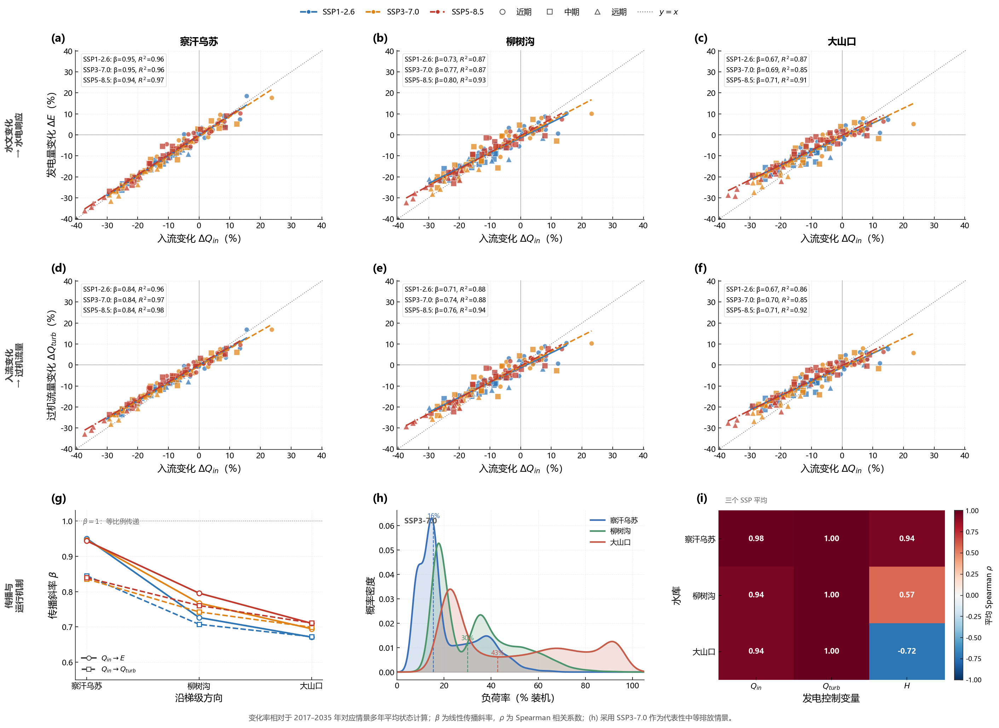


Fig. 6 最终版统计结果
   水库        情景  beta_Qin_to_E  R2_Qin_to_E  beta_Qin_to_Qturb  R2_Qin_to_Qturb  rho_Qin_E  rho_Qturb_E  rho_Head_E
 察汗乌苏  SSP1-2.6          0.951        0.960              0.845            0.962      0.981        0.998       0.942
 察汗乌苏  SSP3-7.0          0.946        0.964              0.836            0.970      0.983        0.997       0.956
 察汗乌苏  SSP5-8.5          0.944        0.974              0.839            0.977      0.981        0.996       0.919
  柳树沟  SSP1-2.6          0.726        0.869              0.707            0.876      0.928        0.999       0.600
  柳树沟  SSP3-7.0          0.767        0.870              0.742            0.879      0.947        0.998       0.656
  柳树沟  SSP5-8.5          0.796        0.934              0.760            0.938      0.956        0.999       0.458
  大山口  SSP1-2.6          0.671        0.866              0.672            0.863      0.932        0.999      -0.734
  大山口  SSP3-7.0          0.695        0.849             

In [56]:
# -*- coding: utf-8 -*-
"""
Fig. 6
未来气候变化下水文信号向梯级水电生产的传播与运行机制

最终版结构：3 × 3

第一行：
    (a) 察汗乌苏：ΔQin vs ΔE
    (b) 柳树沟：  ΔQin vs ΔE
    (c) 大山口：  ΔQin vs ΔE

第二行：
    (d) 察汗乌苏：ΔQin vs ΔQturb
    (e) 柳树沟：  ΔQin vs ΔQturb
    (f) 大山口：  ΔQin vs ΔQturb

第三行：
    (g) 梯级传播系数 β 沿梯级变化
        β(Qin→E)
        β(Qin→Qturb)

    (h) SSP3-7.0 下三库负荷率概率密度
        用于表征不同水库的运行状态差异

    (i) Qin、Qturb、H 与年发电量 E 的 Spearman ρ 热图
        取三个 SSP 的平均值

说明：
1. 不重新运行任何模型，只对现有水库模拟结果后处理；
2. 默认采用 2017–2035 年对应情景多年平均状态作为参考；
3. ΔX = (X - Xref) / Xref × 100%；
4. 第一、二行灰色虚线为 y=x；
5. β 为线性回归传播斜率；
6. 第三行用于综合解释梯级调节和运行状态差异；
7. 负荷率分布沿用原大论文思路，以 SSP3-7.0 作为代表性中等排放情景。
"""

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")


# ============================================================
# 1. 路径
# ============================================================

FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)

FIG_DIR = FUTURE_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. 时间范围
# ============================================================

FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END = pd.Timestamp("2070-12-31")

# 当前没有单独历史基准数据，因此仍采用近期平均状态作为参考
REFERENCE_START = 2017
REFERENCE_END = 2035

PERIODS = [
    ("近期", 2017, 2035),
    ("中期", 2036, 2055),
    ("远期", 2056, 2070),
]

PERIOD_MARKERS = {
    "近期": "o",
    "中期": "s",
    "远期": "^",
}

PERIOD_MARKER_SIZE = {
    "近期": 42,
    "中期": 52,
    "远期": 62,
}


# ============================================================
# 3. 水库参数
# ============================================================

RESERVOIRS = [
    "Chahanwusu",
    "Liushugou",
    "Dashankou"
]

RES_INFO = {
    "Chahanwusu": {
        "cn": "察汗乌苏",
        "capacity_mw": 330,
        "color": "#3B6FB6"
    },
    "Liushugou": {
        "cn": "柳树沟",
        "capacity_mw": 180,
        "color": "#4C956C"
    },
    "Dashankou": {
        "cn": "大山口",
        "capacity_mw": 80,
        "color": "#C65D4B"
    }
}


# ============================================================
# 4. 情景参数
# ============================================================

SCENARIOS = [
    "SSP126",
    "SSP370",
    "SSP585"
]

SCENARIO_SHORT = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "SSP126": "#2E75B6",
    "SSP370": "#E08214",
    "SSP585": "#C0392B"
}

SCENARIO_LS = {
    "SSP126": "-",
    "SSP370": "--",
    "SSP585": "-."
}


# ============================================================
# 5. 绘图风格
# ============================================================

FS_BASE = 12
FS_AXIS = 13
FS_TICK = 10.5
FS_PANEL = 15
FS_TITLE = 13
FS_LEGEND = 10.5
FS_ANNOT = 8.8

COLOR_GRID = "#D5D5D5"
COLOR_ONE_TO_ONE = "#777777"

font_candidates = [
    "Microsoft YaHei",
    "Microsoft YaHei UI",
    "Noto Sans CJK SC",
    "Source Han Sans CN",
    "SimHei"
]

available_fonts = {
    x.name for x in fm.fontManager.ttflist
}

for fname in font_candidates:
    if fname in available_fonts:
        plt.rcParams["font.family"] = fname
        print(f"使用中文字体：{fname}")
        break
else:
    plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams.update({
    "axes.unicode_minus": False,
    "font.size": FS_BASE,
    "axes.labelsize": FS_AXIS,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,

    "axes.linewidth": 0.9,

    "xtick.direction": "in",
    "ytick.direction": "in",

    "xtick.major.size": 4,
    "ytick.major.size": 4,

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "axes.spines.top": False,
    "axes.spines.right": False,

    "pdf.fonttype": 42
})


# ============================================================
# 6. pandas 年频率兼容
# ============================================================

def year_freq():

    try:
        pd.tseries.frequencies.to_offset("YE")
        return "YE"

    except Exception:
        return "Y"


YEAR_FREQ = year_freq()


# ============================================================
# 7. 公共绘图函数
# ============================================================

def clean_axis(ax, grid=True):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        width=0.8,
        length=4
    )

    if grid:

        ax.grid(
            axis="both",
            linestyle="--",
            linewidth=0.5,
            color=COLOR_GRID,
            alpha=0.42
        )

    ax.set_axisbelow(True)


def panel_label(ax, text):

    ax.text(
        -0.10,
        1.035,
        text,

        transform=ax.transAxes,

        fontsize=FS_PANEL,
        fontweight="bold",

        ha="left",
        va="bottom"
    )


# ============================================================
# 8. 数据读取
# ============================================================

def load_future():

    future = {}

    print("\n读取未来水库模拟结果：")

    for sc in SCENARIOS:

        sc_dir = FUTURE_DIR / sc

        if not sc_dir.exists():

            print(f"[WARN] 不存在：{sc_dir}")
            continue

        future[sc] = {}

        for name in RESERVOIRS:

            csv = (
                sc_dir
                / f"cascade_output_{sc}_{name}_daily_results.csv"
            )

            if not csv.exists():

                print(f"[WARN] 缺少：{csv.name}")
                continue

            df = pd.read_csv(
                csv,
                parse_dates=["Date"]
            )

            df = (
                df
                .sort_values("Date")
                .set_index("Date")
            )

            df = df.loc[
                FUTURE_START:FUTURE_END
            ].copy()

            future[sc][name] = df

        print(
            f"  {SCENARIO_SHORT[sc]}："
            f"{list(future[sc].keys())}"
        )

    return future


# ============================================================
# 9. 数值处理
# ============================================================

def numeric(
    df,
    col,
    clip_zero=False
):

    if col not in df.columns:
        return None

    s = pd.to_numeric(
        df[col],
        errors="coerce"
    )

    if clip_zero:

        s = (
            s
            .fillna(0)
            .clip(lower=0)
        )

    return s


def annual_mean(
    df,
    col,
    clip_zero=True
):

    s = numeric(
        df,
        col,
        clip_zero
    )

    if s is None:
        return None

    out = (
        s
        .resample(YEAR_FREQ)
        .mean()
    )

    out.index = out.index.year

    return out


# ============================================================
# 10. 年发电量
# ============================================================

def annual_energy_mwh(df):

    p = numeric(
        df,
        "Power_MW",
        True
    )

    if p is None:
        return None

    daily_energy = (
        p * 24.0
    )

    annual = (
        daily_energy
        .resample(YEAR_FREQ)
        .sum()
    )

    annual.index = annual.index.year

    return annual


# ============================================================
# 11. 年度变量
# ============================================================

def build_annual_metrics(df):

    qin = annual_mean(
        df,
        "Inflow_m3s",
        True
    )

    qturb = annual_mean(
        df,
        "Turbine_Flow_m3s",
        True
    )

    head = annual_mean(
        df,
        "Head_m",
        False
    )

    energy = annual_energy_mwh(
        df
    )

    if any(
        x is None
        for x in [
            qin,
            qturb,
            head,
            energy
        ]
    ):
        return None


    common = (
        qin.index
        .intersection(qturb.index)
        .intersection(head.index)
        .intersection(energy.index)
    )


    out = pd.DataFrame({
        "Qin": qin.loc[common],
        "Qturb": qturb.loc[common],
        "Head": head.loc[common],
        "Energy": energy.loc[common]
    })

    out.index.name = "Year"

    out = (
        out
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    return out


# ============================================================
# 12. 时段分类
# ============================================================

def assign_period(year):

    for label, y0, y1 in PERIODS:

        if y0 <= year <= y1:
            return label

    return None


# ============================================================
# 13. 计算相对变化
# ============================================================

def calculate_relative_changes(annual_df):

    if annual_df is None:
        return None

    ref = annual_df.loc[
        (annual_df.index >= REFERENCE_START)
        &
        (annual_df.index <= REFERENCE_END)
    ]

    if len(ref) == 0:
        return None

    ref_mean = ref.mean()

    change = pd.DataFrame(
        index=annual_df.index
    )

    for col in [
        "Qin",
        "Qturb",
        "Head",
        "Energy"
    ]:

        denominator = ref_mean[col]

        if (
            not np.isfinite(denominator)
            or
            abs(denominator) < 1e-12
        ):

            change[f"d{col}"] = np.nan

        else:

            change[f"d{col}"] = (
                (
                    annual_df[col]
                    - denominator
                )
                /
                denominator
                * 100
            )


    change["Period"] = [
        assign_period(year)
        for year in change.index
    ]

    return change


# ============================================================
# 14. Spearman
# ============================================================

def spearman_rho(x, y):

    tmp = pd.DataFrame({
        "x": x,
        "y": y
    })

    tmp = (
        tmp
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    if len(tmp) < 3:
        return np.nan

    rx = tmp["x"].rank().to_numpy()
    ry = tmp["y"].rank().to_numpy()

    if (
        np.std(rx) <= 1e-12
        or
        np.std(ry) <= 1e-12
    ):

        return np.nan

    return float(
        np.corrcoef(
            rx,
            ry
        )[0, 1]
    )


# ============================================================
# 15. 线性回归
# ============================================================

def linear_fit(x, y):

    tmp = pd.DataFrame({
        "x": x,
        "y": y
    })

    tmp = (
        tmp
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    if len(tmp) < 5:

        return (
            np.nan,
            np.nan,
            np.nan
        )


    xv = tmp["x"].to_numpy()
    yv = tmp["y"].to_numpy()

    if np.std(xv) <= 1e-12:

        return (
            np.nan,
            np.nan,
            np.nan
        )


    beta, intercept = np.polyfit(
        xv,
        yv,
        1
    )


    yhat = (
        intercept
        + beta * xv
    )


    ss_res = np.sum(
        (yv - yhat) ** 2
    )

    ss_tot = np.sum(
        (
            yv
            - np.mean(yv)
        ) ** 2
    )


    r2 = (
        np.nan
        if ss_tot <= 1e-12
        else 1 - ss_res / ss_tot
    )


    return (
        float(beta),
        float(intercept),
        float(r2)
    )


# ============================================================
# 16. KDE
# ============================================================

def kde_1d(
    data,
    xs,
    bw=None
):

    data = np.asarray(
        data,
        dtype=float
    )

    data = data[
        np.isfinite(data)
    ]

    if len(data) > 5000:

        rng = np.random.default_rng(0)

        data = rng.choice(
            data,
            5000,
            replace=False
        )


    n = len(data)

    if n < 2:
        return np.zeros_like(xs)


    if bw is None:

        std = np.std(data)

        iqr = (
            np.percentile(data, 75)
            -
            np.percentile(data, 25)
        )

        sigma = (
            min(std, iqr / 1.34)
            if iqr > 0
            else std
        )

        if sigma <= 1e-12:
            sigma = 1.0

        bw = (
            0.9
            * sigma
            * n ** (-0.2)
        )


    diff = (
        xs[:, None]
        -
        data[None, :]
    ) / bw


    kernel = (
        np.exp(
            -0.5 * diff ** 2
        )
        /
        np.sqrt(
            2 * np.pi
        )
    )


    return (
        kernel.sum(axis=1)
        /
        (n * bw)
    )


# ============================================================
# 17. 构建所有数据
# ============================================================

def prepare_all_metrics(future):

    annual = {
        name: {}
        for name in RESERVOIRS
    }

    changes = {
        name: {}
        for name in RESERVOIRS
    }


    for name in RESERVOIRS:

        for sc in SCENARIOS:

            if name not in future.get(
                sc,
                {}
            ):
                continue


            dat = build_annual_metrics(
                future[sc][name]
            )

            if (
                dat is None
                or len(dat) == 0
            ):
                continue


            annual[name][sc] = dat

            delta = calculate_relative_changes(
                dat
            )

            if delta is not None:

                changes[name][sc] = delta


    return (
        annual,
        changes
    )


# ============================================================
# 18. 统计表
# ============================================================

def build_statistics(
    annual,
    changes
):

    rows = []


    for name in RESERVOIRS:

        for sc in SCENARIOS:

            if (
                sc not in annual[name]
                or
                sc not in changes[name]
            ):
                continue


            dat = annual[name][sc]
            delta = changes[name][sc]


            beta_e, _, r2_e = linear_fit(
                delta["dQin"],
                delta["dEnergy"]
            )


            beta_qt, _, r2_qt = linear_fit(
                delta["dQin"],
                delta["dQturb"]
            )


            rows.append({

                "水库代码":
                    name,

                "水库":
                    RES_INFO[name]["cn"],

                "情景代码":
                    sc,

                "情景":
                    SCENARIO_SHORT[sc],

                "beta_Qin_to_E":
                    beta_e,

                "R2_Qin_to_E":
                    r2_e,

                "beta_Qin_to_Qturb":
                    beta_qt,

                "R2_Qin_to_Qturb":
                    r2_qt,

                "rho_Qin_E":
                    spearman_rho(
                        dat["Qin"],
                        dat["Energy"]
                    ),

                "rho_Qturb_E":
                    spearman_rho(
                        dat["Qturb"],
                        dat["Energy"]
                    ),

                "rho_Head_E":
                    spearman_rho(
                        dat["Head"],
                        dat["Energy"]
                    ),
            })


    return pd.DataFrame(
        rows
    )


# ============================================================
# 19. 公共散点图
# ============================================================

def plot_transfer_panel(
    ax,
    changes_by_scenario,
    xcol,
    ycol
):

    annotation_lines = []


    for sc in SCENARIOS:

        if sc not in changes_by_scenario:
            continue


        dat = changes_by_scenario[
            sc
        ]


        # --------------------------------------------
        # 不同时期
        # --------------------------------------------

        for period_name, _, _ in PERIODS:

            sub = dat[
                dat["Period"]
                == period_name
            ]


            if len(sub) == 0:
                continue


            ax.scatter(

                sub[xcol],

                sub[ycol],

                s=PERIOD_MARKER_SIZE[
                    period_name
                ],

                marker=PERIOD_MARKERS[
                    period_name
                ],

                facecolor=SCENARIO_COLORS[
                    sc
                ],

                edgecolor="white",

                linewidth=0.55,

                alpha=0.72,

                zorder=3
            )


        # --------------------------------------------
        # 拟合
        # --------------------------------------------

        beta, intercept, r2 = linear_fit(

            dat[xcol],

            dat[ycol]
        )


        if np.isfinite(beta):

            valid_x = (
                dat[xcol]
                .replace(
                    [np.inf, -np.inf],
                    np.nan
                )
                .dropna()
            )


            if len(valid_x) >= 2:

                xx = np.linspace(

                    valid_x.min(),

                    valid_x.max(),

                    100
                )


                yy = (
                    intercept
                    +
                    beta * xx
                )


                ax.plot(

                    xx,

                    yy,

                    color=SCENARIO_COLORS[
                        sc
                    ],

                    linestyle=SCENARIO_LS[
                        sc
                    ],

                    linewidth=2.0,

                    alpha=0.95,

                    zorder=4
                )


                annotation_lines.append(

                    f"{SCENARIO_SHORT[sc]}: "
                    f"β={beta:.2f}, "
                    f"$R^2$={r2:.2f}"
                )


    ax.axhline(
        0,
        color="#AAAAAA",
        linewidth=0.8,
        zorder=0
    )

    ax.axvline(
        0,
        color="#AAAAAA",
        linewidth=0.8,
        zorder=0
    )


    if annotation_lines:

        ax.text(

            0.03,
            0.97,

            "\n".join(
                annotation_lines
            ),

            transform=ax.transAxes,

            ha="left",
            va="top",

            fontsize=FS_ANNOT,

            linespacing=1.25,

            bbox=dict(

                boxstyle="round,pad=0.25",

                facecolor="white",

                edgecolor="#CCCCCC",

                linewidth=0.6,

                alpha=0.84
            ),

            zorder=10
        )


# ============================================================
# 20. 统一坐标范围
# ============================================================

def collect_values(
    changes,
    xcol,
    ycol
):

    xs = []
    ys = []


    for name in RESERVOIRS:

        for sc in SCENARIOS:

            if sc not in changes[name]:
                continue


            dat = changes[name][sc]

            xs.extend(
                dat[xcol]
                .dropna()
                .tolist()
            )

            ys.extend(
                dat[ycol]
                .dropna()
                .tolist()
            )


    return (
        np.asarray(xs),
        np.asarray(ys)
    )


def symmetric_limit(
    x,
    y,
    pad=0.08
):

    vals = np.concatenate([
        x,
        y
    ])

    vals = vals[
        np.isfinite(vals)
    ]

    if len(vals) == 0:

        return (
            -1,
            1
        )


    max_abs = np.max(
        np.abs(vals)
    )

    if max_abs <= 1e-12:
        max_abs = 1


    bound = (
        max_abs
        * (1 + pad)
    )


    return (
        -bound,
        bound
    )


def add_one_to_one(ax):

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    lo = min(
        xmin,
        ymin
    )

    hi = max(
        xmax,
        ymax
    )

    ax.plot(

        [lo, hi],

        [lo, hi],

        color=COLOR_ONE_TO_ONE,

        linestyle=":",

        linewidth=1.1,

        alpha=0.85,

        zorder=1
    )


# ============================================================
# 21. (g) 梯级传播系数
# ============================================================

def plot_beta_profile(
    ax,
    stat_df
):

    x = np.arange(
        len(RESERVOIRS)
    )


    for sc in SCENARIOS:

        sub = stat_df[
            stat_df["情景代码"]
            == sc
        ].copy()


        order_map = {
            name: i
            for i, name
            in enumerate(RESERVOIRS)
        }


        sub["order"] = (
            sub["水库代码"]
            .map(order_map)
        )

        sub = sub.sort_values(
            "order"
        )


        beta_e = (
            sub[
                "beta_Qin_to_E"
            ]
            .to_numpy()
        )

        beta_qt = (
            sub[
                "beta_Qin_to_Qturb"
            ]
            .to_numpy()
        )


        # Qin → E
        ax.plot(

            x,

            beta_e,

            color=SCENARIO_COLORS[
                sc
            ],

            linestyle="-",

            linewidth=2.2,

            marker="o",

            markersize=6.5,

            markerfacecolor="white",

            markeredgewidth=1.5
        )


        # Qin → Qturb
        ax.plot(

            x,

            beta_qt,

            color=SCENARIO_COLORS[
                sc
            ],

            linestyle="--",

            linewidth=2.0,

            marker="s",

            markersize=5.8,

            markerfacecolor="white",

            markeredgewidth=1.4
        )


    ax.axhline(

        1,

        color="#999999",

        linestyle=":",

        linewidth=1
    )


    ax.text(

        0.03,
        0.96,

        r"$\beta=1$：等比例传递",

        transform=ax.transAxes,

        ha="left",
        va="top",

        fontsize=9,

        color="#666666"
    )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        [
            RES_INFO[n]["cn"]
            for n in RESERVOIRS
        ]
    )


    ax.set_ylabel(
        r"传播斜率 $\beta$"
    )

    ax.set_xlabel(
        "沿梯级方向"
    )


    ax.set_ylim(
        0.55,
        1.03
    )


    mechanism_handles = [

        Line2D(
            [0],
            [0],
            color="#444444",
            linestyle="-",
            marker="o",
            markerfacecolor="white",
            linewidth=2,
            label=r"$Q_{in}\rightarrow E$"
        ),

        Line2D(
            [0],
            [0],
            color="#444444",
            linestyle="--",
            marker="s",
            markerfacecolor="white",
            linewidth=2,
            label=r"$Q_{in}\rightarrow Q_{turb}$"
        )
    ]


    ax.legend(

        handles=mechanism_handles,

        frameon=False,

        loc="lower left",

        fontsize=9.5
    )


    clean_axis(
        ax,
        grid=True
    )


# ============================================================
# 22. (h) 负荷率概率密度
#
# 代表情景：SSP3-7.0
# ============================================================

def plot_load_factor_density(
    ax,
    future,
    scenario="SSP370"
):

    xs = np.linspace(
        0,
        110,
        450
    )


    for name in RESERVOIRS:

        if name not in future.get(
            scenario,
            {}
        ):
            continue


        df = future[
            scenario
        ][
            name
        ]


        p = numeric(
            df,
            "Power_MW",
            True
        )

        if p is None:
            continue


        capacity = (
            RES_INFO[
                name
            ][
                "capacity_mw"
            ]
        )


        load_factor = (
            p.to_numpy()
            /
            capacity
            * 100
        )


        load_factor = load_factor[
            np.isfinite(
                load_factor
            )
        ]


        dens = kde_1d(
            load_factor,
            xs
        )


        ax.fill_between(

            xs,

            0,

            dens,

            color=RES_INFO[
                name
            ][
                "color"
            ],

            alpha=0.18
        )


        ax.plot(

            xs,

            dens,

            color=RES_INFO[
                name
            ][
                "color"
            ],

            linewidth=2.2,

            label=RES_INFO[
                name
            ][
                "cn"
            ]
        )


        median = np.nanmedian(
            load_factor
        )


        density_at_med = np.interp(
            median,
            xs,
            dens
        )


        ax.plot(

            [
                median,
                median
            ],

            [
                0,
                density_at_med
            ],

            color=RES_INFO[
                name
            ][
                "color"
            ],

            linestyle="--",

            linewidth=1.1
        )


        ax.text(

            median,

            density_at_med * 1.03,

            f"{median:.0f}%",

            color=RES_INFO[
                name
            ][
                "color"
            ],

            ha="center",

            va="bottom",

            fontsize=8.5
        )


    ax.set_xlim(
        0,
        105
    )


    ax.set_xlabel(
        "负荷率（% 装机）"
    )

    ax.set_ylabel(
        "概率密度"
    )


    ax.text(

        0.03,
        0.96,

        SCENARIO_SHORT[
            scenario
        ],

        transform=ax.transAxes,

        ha="left",
        va="top",

        fontsize=10,

        fontweight="bold",

        color="#555555"
    )


    ax.legend(

        frameon=False,

        loc="upper right",

        fontsize=9.5
    )


    clean_axis(
        ax,
        grid=True
    )


# ============================================================
# 23. (i) 控制因子热图
# ============================================================

def plot_control_heatmap(
    ax,
    stat_df,
    fig
):

    matrix = []


    for name in RESERVOIRS:

        sub = stat_df[
            stat_df["水库代码"]
            == name
        ]


        matrix.append([
            sub["rho_Qin_E"].mean(),
            sub["rho_Qturb_E"].mean(),
            sub["rho_Head_E"].mean()
        ])


    matrix = np.array(
        matrix,
        dtype=float
    )


    im = ax.imshow(

        matrix,

        aspect="auto",

        cmap="RdBu_r",

        vmin=-1,

        vmax=1
    )


    ax.set_xticks(
        np.arange(3)
    )


    ax.set_xticklabels([
        r"$Q_{in}$",
        r"$Q_{turb}$",
        r"$H$"
    ])


    ax.set_yticks(
        np.arange(
            len(RESERVOIRS)
        )
    )


    ax.set_yticklabels(
        [
            RES_INFO[n]["cn"]
            for n in RESERVOIRS
        ]
    )


    ax.set_xlabel(
        "发电控制变量"
    )

    ax.set_ylabel(
        "水库"
    )


    for i in range(
        matrix.shape[0]
    ):

        for j in range(
            matrix.shape[1]
        ):

            val = matrix[
                i,
                j
            ]


            text_color = (
                "white"
                if abs(val) >= 0.55
                else "#222222"
            )


            ax.text(

                j,

                i,

                f"{val:.2f}",

                ha="center",

                va="center",

                fontsize=10,

                fontweight="bold",

                color=text_color
            )


    cbar = fig.colorbar(

        im,

        ax=ax,

        fraction=0.046,

        pad=0.04
    )


    cbar.set_label(
        r"平均 Spearman $\rho$",
        fontsize=10
    )


    cbar.ax.tick_params(
        labelsize=9
    )


    ax.text(

        0.03,
        1.04,

        "三个 SSP 平均",

        transform=ax.transAxes,

        ha="left",

        va="bottom",

        fontsize=9,

        color="#666666"
    )


    for spine in ax.spines.values():
        spine.set_visible(False)


# ============================================================
# 24. 主图
# ============================================================

def fig6_final(
    future,
    save_stem="fig6_hydrological_signal_propagation_final"
):

    annual, changes = prepare_all_metrics(
        future
    )


    stat_df = build_statistics(
        annual,
        changes
    )


    fig, axes = plt.subplots(

        3,
        3,

        figsize=(
            18.5,
            14.2
        )
    )


    plt.subplots_adjust(

        left=0.078,

        right=0.985,

        bottom=0.075,

        top=0.91,

        wspace=0.30,

        hspace=0.36
    )


    panel_tags = [

        [
            "(a)",
            "(b)",
            "(c)"
        ],

        [
            "(d)",
            "(e)",
            "(f)"
        ],

        [
            "(g)",
            "(h)",
            "(i)"
        ]
    ]


    # ========================================================
    # 第一行：ΔQin → ΔE
    # ========================================================

    for j, name in enumerate(
        RESERVOIRS
    ):

        ax = axes[
            0,
            j
        ]


        plot_transfer_panel(

            ax,

            changes[
                name
            ],

            "dQin",

            "dEnergy"
        )


        ax.set_xlabel(
            r"入流变化 $\Delta Q_{in}$（%）"
        )


        if j == 0:

            ax.set_ylabel(
                r"发电量变化 $\Delta E$（%）"
            )


        ax.set_title(

            RES_INFO[
                name
            ][
                "cn"
            ],

            fontsize=FS_TITLE,

            fontweight="bold",

            pad=8
        )


        panel_label(

            ax,

            panel_tags[
                0
            ][
                j
            ]
        )


        clean_axis(
            ax,
            grid=True
        )


    # --------------------------------------------------------
    # 第一行统一坐标
    # --------------------------------------------------------

    x1, y1 = collect_values(

        changes,

        "dQin",

        "dEnergy"
    )


    lo1, hi1 = symmetric_limit(
        x1,
        y1
    )


    for j in range(3):

        axes[
            0,
            j
        ].set_xlim(
            lo1,
            hi1
        )

        axes[
            0,
            j
        ].set_ylim(
            lo1,
            hi1
        )

        add_one_to_one(
            axes[
                0,
                j
            ]
        )


    # ========================================================
    # 第二行：ΔQin → ΔQturb
    # ========================================================

    for j, name in enumerate(
        RESERVOIRS
    ):

        ax = axes[
            1,
            j
        ]


        plot_transfer_panel(

            ax,

            changes[
                name
            ],

            "dQin",

            "dQturb"
        )


        ax.set_xlabel(
            r"入流变化 $\Delta Q_{in}$（%）"
        )


        if j == 0:

            ax.set_ylabel(
                r"过机流量变化 $\Delta Q_{turb}$（%）"
            )


        panel_label(

            ax,

            panel_tags[
                1
            ][
                j
            ]
        )


        clean_axis(
            ax,
            grid=True
        )


    # --------------------------------------------------------
    # 第二行统一坐标
    # --------------------------------------------------------

    x2, y2 = collect_values(

        changes,

        "dQin",

        "dQturb"
    )


    lo2, hi2 = symmetric_limit(
        x2,
        y2
    )


    for j in range(3):

        axes[
            1,
            j
        ].set_xlim(
            lo2,
            hi2
        )

        axes[
            1,
            j
        ].set_ylim(
            lo2,
            hi2
        )

        add_one_to_one(
            axes[
                1,
                j
            ]
        )


    # ========================================================
    # 第三行
    # ========================================================

    # (g)
    plot_beta_profile(
        axes[2, 0],
        stat_df
    )

    panel_label(
        axes[2, 0],
        "(g)"
    )


    # (h)
    plot_load_factor_density(
        axes[2, 1],
        future,
        scenario="SSP370"
    )

    panel_label(
        axes[2, 1],
        "(h)"
    )


    # (i)
    plot_control_heatmap(
        axes[2, 2],
        stat_df,
        fig
    )

    panel_label(
        axes[2, 2],
        "(i)"
    )


    # ========================================================
    # 左侧行标题
    # ========================================================

    row_titles = [
        "水文变化\n→ 水电响应",
        "入流变化\n→ 过机流量",
        "传播与\n运行机制"
    ]


    for r in range(3):

        axes[
            r,
            0
        ].text(

            -0.245,
            0.50,

            row_titles[
                r
            ],

            transform=axes[
                r,
                0
            ].transAxes,

            ha="center",
            va="center",

            rotation=90,

            fontsize=11.5,

            fontweight="bold",

            color="#444444"
        )


    # ========================================================
    # 顶部总图例
    # ========================================================

    scenario_handles = []


    for sc in SCENARIOS:

        scenario_handles.append(

            Line2D(

                [0],
                [0],

                color=SCENARIO_COLORS[
                    sc
                ],

                linestyle=SCENARIO_LS[
                    sc
                ],

                linewidth=2.2,

                marker="o",

                markersize=6,

                markerfacecolor=SCENARIO_COLORS[
                    sc
                ],

                markeredgecolor="white",

                label=SCENARIO_SHORT[
                    sc
                ]
            )
        )


    period_handles = []


    for label, _, _ in PERIODS:

        period_handles.append(

            Line2D(

                [0],
                [0],

                color="#555555",

                linestyle="none",

                marker=PERIOD_MARKERS[
                    label
                ],

                markersize=7,

                markerfacecolor="white",

                markeredgecolor="#555555",

                label=label
            )
        )


    one_to_one_handle = Line2D(

        [0],
        [0],

        color=COLOR_ONE_TO_ONE,

        linestyle=":",

        linewidth=1.2,

        label=r"$y=x$"
    )


    fig.legend(

        handles=(
            scenario_handles
            +
            period_handles
            +
            [
                one_to_one_handle
            ]
        ),

        loc="upper center",

        bbox_to_anchor=(
            0.5,
            0.975
        ),

        ncol=7,

        frameon=False,

        fontsize=FS_LEGEND,

        handlelength=2.0,

        columnspacing=1.35
    )


    # ========================================================
    # 脚注
    # ========================================================

    fig.text(

        0.5,
        0.018,

        (
            f"变化率相对于 {REFERENCE_START}–{REFERENCE_END} 年"
            "对应情景多年平均状态计算；"
            r"$\beta$ 为线性传播斜率，"
            r"$\rho$ 为 Spearman 相关系数；"
            "(h) 采用 SSP3-7.0 作为代表性中等排放情景。"
        ),

        ha="center",

        va="bottom",

        fontsize=9.8,

        color="#555555"
    )


    # ========================================================
    # 保存
    # ========================================================

    for ext in [
        "png",
        "pdf"
    ]:

        save_path = (
            FIG_DIR
            /
            f"{save_stem}.{ext}"
        )


        fig.savefig(

            save_path,

            dpi=600,

            bbox_inches="tight",

            facecolor="white"
        )


        print(
            f"保存：{save_path}"
        )


    plt.show()


    return stat_df


# ============================================================
# 25. 输出统计
# ============================================================

def print_statistics(
    stat_df
):

    print(
        "\n"
        + "=" * 120
    )

    print(
        "Fig. 6 最终版统计结果"
    )

    print(
        "=" * 120
    )


    cols = [

        "水库",

        "情景",

        "beta_Qin_to_E",

        "R2_Qin_to_E",

        "beta_Qin_to_Qturb",

        "R2_Qin_to_Qturb",

        "rho_Qin_E",

        "rho_Qturb_E",

        "rho_Head_E"
    ]


    print(

        stat_df[
            cols
        ]
        .round(3)
        .to_string(
            index=False
        )
    )


    output_csv = (
        FIG_DIR
        /
        "fig6_final_statistics.csv"
    )


    stat_df.to_csv(

        output_csv,

        index=False,

        encoding="utf-8-sig"
    )


    print(
        "\n统计表保存：",
        output_csv
    )


# ============================================================
# 26. 主程序
# ============================================================

if __name__ == "__main__":

    print(
        "=" * 90
    )

    print(
        "Fig. 6 "
        "未来气候变化下水文信号向梯级水电生产的传播与运行机制"
    )

    print(
        "=" * 90
    )

    print(
        "数据目录：",
        FUTURE_DIR
    )

    print(
        "图件目录：",
        FIG_DIR
    )

    print(
        f"参考期：{REFERENCE_START}–{REFERENCE_END}"
    )


    future = load_future()


    if not future:

        raise FileNotFoundError(
            "未读取到未来情景模拟结果，请检查 FUTURE_DIR。"
        )


    stat_df = fig6_final(

        future,

        save_stem="fig6_hydrological_signal_propagation_final"
    )


    print_statistics(
        stat_df
    )


    print(
        "\nFig. 6 最终版绘制完成。"
    )

Fig. 6 — Propagation and regulation of hydrological signals

Loading future simulations:
  SSP1-2.6: ['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP3-7.0: ['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP5-8.5: ['Chahanwusu', 'Liushugou', 'Dashankou']
Saved: D:\博士论文\小论文3\图片\Fig6_Hydrological_Signal_Propagation.png
Saved: D:\博士论文\小论文3\图片\Fig6_Hydrological_Signal_Propagation.pdf


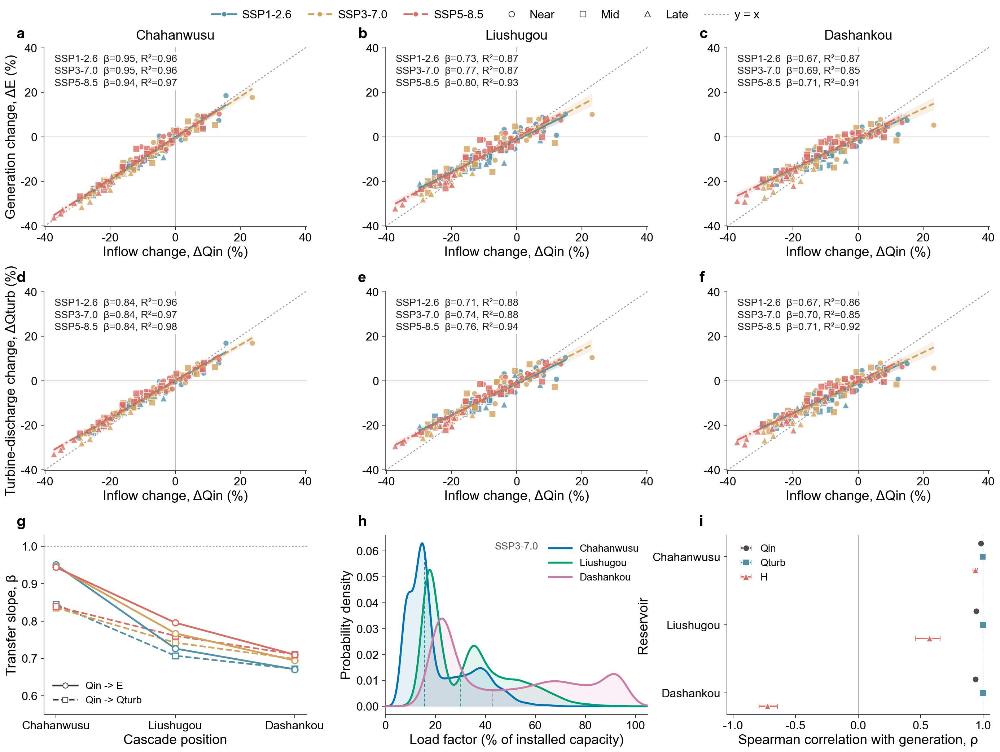


Fig. 6 statistics
  Reservoir Scenario  beta_Qin_to_E  R2_Qin_to_E  beta_Qin_to_Qturb  R2_Qin_to_Qturb  rho_Qin_E  rho_Qturb_E  rho_Head_E
 Chahanwusu   SSP126          0.951        0.960              0.845            0.962      0.981        0.998       0.942
 Chahanwusu   SSP370          0.946        0.964              0.836            0.970      0.983        0.997       0.956
 Chahanwusu   SSP585          0.944        0.974              0.839            0.977      0.981        0.996       0.919
  Liushugou   SSP126          0.726        0.869              0.707            0.876      0.928        0.999       0.600
  Liushugou   SSP370          0.767        0.870              0.742            0.879      0.947        0.998       0.656
  Liushugou   SSP585          0.796        0.934              0.760            0.938      0.956        0.999       0.458
  Dashankou   SSP126          0.671        0.866              0.672            0.863      0.932        0.999      -0.734
  Dashankou  

In [60]:
# -*- coding: utf-8 -*-
"""
Fig. 6 v5 — 修复乱码，调整图例位置
"""

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")


# ============================================================
# 1. Paths
# ============================================================
FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)

FIG_DIR = Path(r"D:\博士论文\小论文3\图片")
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Time settings
# ============================================================
FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END   = pd.Timestamp("2070-12-31")

REFERENCE_START = 2017
REFERENCE_END   = 2035

PERIODS = [
    ("Near", 2017, 2035),
    ("Mid",  2036, 2055),
    ("Late", 2056, 2070),
]

PERIOD_MARKERS = {
    "Near": "o",
    "Mid":  "s",
    "Late": "^",
}

PERIOD_MARKER_SIZE = {
    "Near": 58,
    "Mid":  68,
    "Late": 78,
}


# ============================================================
# 3. Reservoirs
# ============================================================
RESERVOIRS = [
    "Chahanwusu",
    "Liushugou",
    "Dashankou"
]

RES_INFO = {
    "Chahanwusu": {"label": "Chahanwusu", "capacity_mw": 330, "color": "#0072B2"},
    "Liushugou":  {"label": "Liushugou",  "capacity_mw": 180, "color": "#009E73"},
    "Dashankou":  {"label": "Dashankou",  "capacity_mw": 80,  "color": "#CC79A7"}
}


# ============================================================
# 4. Scenarios ★ 海盐-珊瑚色带 ★
# ============================================================
SCENARIOS = ["SSP126", "SSP370", "SSP585"]

SCENARIO_SHORT = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "SSP126": "#4F8FA8",   # sea-salt blue
    "SSP370": "#D3A15A",   # warm sand
    "SSP585": "#D96B62",   # coral
}

SCENARIO_LS = {
    "SSP126": "-",
    "SSP370": "--",
    "SSP585": "-."
}


# ============================================================
# 5. Variables used in panel i (改用普通文本，防乱码)
# ============================================================
CONTROL_INFO = {
    "rho_Qin_E":   {"label": "Qin",     "color": "#4D4D4D", "marker": "o"},
    "rho_Qturb_E": {"label": "Qturb",   "color": "#4F8FA8", "marker": "s"},
    "rho_Head_E":  {"label": "H",       "color": "#D96B62", "marker": "^"}
}


# ============================================================
# 6. Font settings
# ============================================================
FS_BASE   = 17
FS_AXIS   = 18
FS_TICK   = 15.5
FS_PANEL  = 20
FS_TITLE  = 18
FS_LEGEND = 15.5
FS_ANNOT  = 13.5

AXIS_LW = 0.85
TICK_LW = 0.8

COLOR_ONE_TO_ONE = "#8C8C8C"
COLOR_ZERO = "#B0B0B0"

available_fonts = {f.name for f in fm.fontManager.ttflist}
for fname in ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]:
    if fname in available_fonts:
        plt.rcParams["font.family"] = fname
        break

plt.rcParams.update({
    "axes.unicode_minus": False,
    "font.size": FS_BASE,
    "axes.labelsize": FS_AXIS,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,
    "axes.linewidth": AXIS_LW,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 4.5,
    "ytick.major.size": 4.5,
    "xtick.major.width": TICK_LW,
    "ytick.major.width": TICK_LW,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.transparent": False
})


# ============================================================
# 8. Pandas frequency compatibility
# ============================================================
def year_freq():
    try:
        pd.tseries.frequencies.to_offset("YE")
        return "YE"
    except Exception:
        return "Y"

YEAR_FREQ = year_freq()


# ============================================================
# 9. Basic plotting tools
# ============================================================
def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(AXIS_LW)
    ax.spines["bottom"].set_linewidth(AXIS_LW)
    ax.tick_params(axis="both", width=TICK_LW, length=4.5, pad=4)
    ax.grid(False)


def panel_label(ax, label):
    ax.text(-0.105, 1.035, label, transform=ax.transAxes,
            fontsize=FS_PANEL, fontweight="bold", ha="left", va="bottom", color="black")


# ============================================================
# 10. Load data
# ============================================================
def load_future():
    future = {}
    print("\nLoading future simulations:")
    for sc in SCENARIOS:
        sc_dir = FUTURE_DIR / sc
        if not sc_dir.exists():
            print(f"[WARN] Missing directory: {sc_dir}")
            continue
        future[sc] = {}
        for name in RESERVOIRS:
            csv = sc_dir / f"cascade_output_{sc}_{name}_daily_results.csv"
            if not csv.exists(): continue
            df = pd.read_csv(csv, parse_dates=["Date"]).sort_values("Date").set_index("Date")
            future[sc][name] = df.loc[FUTURE_START:FUTURE_END].copy()
        print(f"  {SCENARIO_SHORT[sc]}: {list(future[sc].keys())}")
    return future


# ============================================================
# 11-13. Data Processing
# ============================================================
def numeric(df, col, clip_zero=False):
    if col not in df.columns: return None
    s = pd.to_numeric(df[col], errors="coerce")
    if clip_zero: s = s.fillna(0).clip(lower=0)
    return s


def annual_mean(df, col, clip_zero=True):
    s = numeric(df, col, clip_zero)
    if s is None: return None
    out = s.resample(YEAR_FREQ).mean()
    out.index = out.index.year
    return out


def annual_energy_mwh(df):
    p = numeric(df, "Power_MW", True)
    if p is None: return None
    daily_energy = (p * 24.0)
    annual = daily_energy.resample(YEAR_FREQ).sum()
    annual.index = annual.index.year
    return annual


def build_annual_metrics(df):
    qin = annual_mean(df, "Inflow_m3s", True)
    qturb = annual_mean(df, "Turbine_Flow_m3s", True)
    head = annual_mean(df, "Head_m", False)
    energy = annual_energy_mwh(df)

    if any(x is None for x in [qin, qturb, head, energy]): return None

    common = qin.index.intersection(qturb.index).intersection(head.index).intersection(energy.index)
    out = pd.DataFrame({
        "Qin": qin.loc[common],
        "Qturb": qturb.loc[common],
        "Head": head.loc[common],
        "Energy": energy.loc[common]
    })
    out.index.name = "Year"
    return out.replace([np.inf, -np.inf], np.nan).dropna()


# ============================================================
# 14-15. Periods & Relative Change
# ============================================================
def assign_period(year):
    for label, y0, y1 in PERIODS:
        if y0 <= year <= y1: return label
    return None

def calculate_relative_changes(annual_df):
    if annual_df is None: return None
    ref = annual_df.loc[(annual_df.index >= REFERENCE_START) & (annual_df.index <= REFERENCE_END)]
    if len(ref) == 0: return None

    ref_mean = ref.mean()
    change = pd.DataFrame(index=annual_df.index)

    for col in ["Qin", "Qturb", "Head", "Energy"]:
        ref_value = ref_mean[col]
        if (not np.isfinite(ref_value) or abs(ref_value) < 1e-12):
            change[f"d{col}"] = np.nan
        else:
            change[f"d{col}"] = ((annual_df[col] - ref_value) / ref_value * 100.0)

    change["Period"] = [assign_period(year) for year in change.index]
    return change


# ============================================================
# 16-18. Stats & Math Tools
# ============================================================
def spearman_rho(x, y):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 3: return np.nan
    rx = tmp["x"].rank().to_numpy()
    ry = tmp["y"].rank().to_numpy()
    if np.std(rx) <= 1e-12 or np.std(ry) <= 1e-12: return np.nan
    return float(np.corrcoef(rx, ry)[0, 1])


def linear_fit(x, y):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 5: return np.nan, np.nan, np.nan

    xv = tmp["x"].to_numpy()
    yv = tmp["y"].to_numpy()

    if np.std(xv) <= 1e-12: return np.nan, np.nan, np.nan

    beta, intercept = np.polyfit(xv, yv, 1)
    yhat = intercept + beta * xv
    ss_res = np.sum((yv - yhat) ** 2)
    ss_tot = np.sum((yv - np.mean(yv)) ** 2)
    r2 = np.nan if ss_tot <= 1e-12 else 1 - ss_res / ss_tot

    return float(beta), float(intercept), float(r2)


def kde_1d(data, xs, bw=None):
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]
    if len(data) > 5000:
        data = np.random.default_rng(0).choice(data, 5000, replace=False)

    n = len(data)
    if n < 2: return np.zeros_like(xs)

    if bw is None:
        std = np.std(data)
        iqr = np.percentile(data, 75) - np.percentile(data, 25)
        sigma = min(std, iqr / 1.34) if iqr > 0 else std
        if sigma <= 1e-12: sigma = 1.0
        bw = 0.9 * sigma * n ** (-0.2)

    diff = (xs[:, None] - data[None, :]) / bw
    kernel = np.exp(-0.5 * diff ** 2) / np.sqrt(2 * np.pi)
    return kernel.sum(axis=1) / (n * bw)


# ============================================================
# 19-20. Prepare Data & Statistics
# ============================================================
def prepare_all_metrics(future):
    annual = {name: {} for name in RESERVOIRS}
    changes = {name: {} for name in RESERVOIRS}

    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if name not in future.get(sc, {}): continue
            dat = build_annual_metrics(future[sc][name])
            if dat is None or len(dat) == 0: continue

            annual[name][sc] = dat
            delta = calculate_relative_changes(dat)
            if delta is not None:
                changes[name][sc] = delta

    return annual, changes


def build_statistics(annual, changes):
    rows = []
    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if (sc not in annual[name] or sc not in changes[name]): continue

            dat = annual[name][sc]
            delta = changes[name][sc]

            beta_e, _, r2_e = linear_fit(delta["dQin"], delta["dEnergy"])
            beta_qt, _, r2_qt = linear_fit(delta["dQin"], delta["dQturb"])

            rows.append({
                "Reservoir": name,
                "Scenario": sc,
                "beta_Qin_to_E": beta_e,
                "R2_Qin_to_E": r2_e,
                "beta_Qin_to_Qturb": beta_qt,
                "R2_Qin_to_Qturb": r2_qt,
                "rho_Qin_E": spearman_rho(dat["Qin"], dat["Energy"]),
                "rho_Qturb_E": spearman_rho(dat["Qturb"], dat["Energy"]),
                "rho_Head_E": spearman_rho(dat["Head"], dat["Energy"])
            })
    return pd.DataFrame(rows)


# ============================================================
# 21. Scatter / transfer panel (★升级版：加入95%置信带阴影★)
# ============================================================
def plot_transfer_panel(ax, changes_by_scenario, xcol, ycol):
    annotation_lines = []

    for sc in SCENARIOS:
        if sc not in changes_by_scenario: continue
        dat = changes_by_scenario[sc]

        # 1. 画散点（Period symbols）
        for period_name, _, _ in PERIODS:
            sub = dat[dat["Period"] == period_name]
            if len(sub) == 0: continue

            ax.scatter(
                sub[xcol], sub[ycol],
                s=PERIOD_MARKER_SIZE[period_name],
                marker=PERIOD_MARKERS[period_name],
                facecolor=SCENARIO_COLORS[sc],
                edgecolor="white", linewidth=0.8, alpha=0.78, zorder=3
            )

        # 2. 线性回归与置信带
        df_clean = pd.DataFrame({"x": dat[xcol], "y": dat[ycol]}).replace([np.inf, -np.inf], np.nan).dropna()
        xv = df_clean["x"].to_numpy()
        yv = df_clean["y"].to_numpy()

        beta, intercept, r2 = linear_fit(xv, yv)

        if np.isfinite(beta) and len(xv) >= 5:
            xx = np.linspace(xv.min(), xv.max(), 100)
            yy = intercept + beta * xx

            # 计算 95% 置信区间
            n = len(xv)
            yhat = intercept + beta * xv
            s_err = np.sqrt(np.sum((yv - yhat) ** 2) / (n - 2))
            t_val = 1.96  # 大样本近似
            x_mean = np.mean(xv)
            se_fit = s_err * np.sqrt(1/n + (xx - x_mean)**2 / np.sum((xv - x_mean)**2))
            ci = t_val * se_fit

            # 画阴影带
            ax.fill_between(xx, yy - ci, yy + ci, color=SCENARIO_COLORS[sc], alpha=0.15, lw=0, zorder=2)
            
            # 画拟合线
            ax.plot(xx, yy, color=SCENARIO_COLORS[sc], linestyle=SCENARIO_LS[sc], linewidth=2.3, alpha=0.98, zorder=4)

            annotation_lines.append(f"{SCENARIO_SHORT[sc]}  β={beta:.2f}, R²={r2:.2f}") # 修复这里：不用LaTeX的$R^2$

    # 零参考线
    ax.axhline(0, color=COLOR_ZERO, linewidth=0.8, zorder=0)
    ax.axvline(0, color=COLOR_ZERO, linewidth=0.8, zorder=0)

    # 统计文本
    if annotation_lines:
        ax.text(0.04, 0.96, "\n".join(annotation_lines), transform=ax.transAxes,
                ha="left", va="top", fontsize=FS_ANNOT, linespacing=1.30, color="#222222",
                bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="none", alpha=0.90),
                zorder=10)


def collect_values(changes, xcol, ycol):
    xs, ys = [], []
    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if sc not in changes[name]: continue
            dat = changes[name][sc]
            xs.extend(dat[xcol].dropna().tolist())
            ys.extend(dat[ycol].dropna().tolist())
    return np.asarray(xs), np.asarray(ys)


def symmetric_limit(x, y, pad=0.08):
    vals = np.concatenate([x, y])
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0: return -1, 1
    max_abs = np.max(np.abs(vals))
    if max_abs <= 1e-12: max_abs = 1.0
    bound = max_abs * (1 + pad)
    return -bound, bound


def add_one_to_one(ax):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    lo, hi = min(xmin, ymin), max(xmax, ymax)
    ax.plot([lo, hi], [lo, hi], color=COLOR_ONE_TO_ONE, linestyle=(0, (2, 2)),
            linewidth=1.25, alpha=0.90, zorder=1)


# ============================================================
# 23. Panel g (★ 修复图例乱码 ★)
# ============================================================
def plot_beta_profile(ax, stat_df):
    x = np.arange(len(RESERVOIRS))
    order_map = {name: i for i, name in enumerate(RESERVOIRS)}

    for sc in SCENARIOS:
        sub = stat_df[stat_df["Scenario"] == sc].copy()
        sub["order"] = sub["Reservoir"].map(order_map)
        sub = sub.sort_values("order")

        beta_e = sub["beta_Qin_to_E"].to_numpy()
        beta_qt = sub["beta_Qin_to_Qturb"].to_numpy()

        # Qin -> E
        ax.plot(x, beta_e, color=SCENARIO_COLORS[sc], linestyle="-", linewidth=2.4,
                marker="o", markersize=8, markerfacecolor="white", markeredgewidth=1.7, zorder=4)
        # Qin -> Qturb
        ax.plot(x, beta_qt, color=SCENARIO_COLORS[sc], linestyle="--", linewidth=2.2,
                marker="s", markersize=7.3, markerfacecolor="white", markeredgewidth=1.6, zorder=3)

    ax.axhline(1.0, color="#9A9A9A", linestyle=(0, (2, 2)), linewidth=1.1, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels([RES_INFO[n]["label"] for n in RESERVOIRS])
    ax.set_ylabel("Transfer slope, β") # 改用 Unicode β
    ax.set_xlabel("Cascade position")
    ax.set_ylim(0.55, 1.03)

    handles = [
        Line2D([0], [0], color="#333333", linestyle="-", marker="o",
               markerfacecolor="white", linewidth=2.2, markersize=7, label="Qin -> E"), # 改用普通文本
        Line2D([0], [0], color="#333333", linestyle="--", marker="s",
               markerfacecolor="white", linewidth=2.0, markersize=6.5, label="Qin -> Qturb")
    ]
    ax.legend(handles=handles, frameon=False, loc="lower left", fontsize=FS_ANNOT, handlelength=2.4)
    clean_axis(ax)


# ============================================================
# 24. Panel h (★ 图例放右上角，SSP标注居中 ★)
# ============================================================
def plot_load_factor_density(ax, future, scenario="SSP370"):
    xs = np.linspace(0, 105, 450)
    for name in RESERVOIRS:
        if name not in future.get(scenario, {}): continue
        df = future[scenario][name]
        p = numeric(df, "Power_MW", True)
        if p is None: continue

        capacity = RES_INFO[name]["capacity_mw"]
        load_factor = (p.to_numpy() / capacity * 100.0)
        load_factor = load_factor[np.isfinite(load_factor)]

        dens = kde_1d(load_factor, xs)
        color = RES_INFO[name]["color"]

        ax.fill_between(xs, 0, dens, color=color, alpha=0.10, linewidth=0)
        ax.plot(xs, dens, color=color, linewidth=2.6, label=RES_INFO[name]["label"], zorder=3)

        median = np.nanmedian(load_factor)
        ymax_med = np.interp(median, xs, dens)
        ax.plot([median, median], [0, ymax_med], color=color, linestyle=(0, (3, 2)), linewidth=1.3, alpha=0.85)

    ax.set_xlim(0, 105)
    ax.set_xlabel("Load factor (% of installed capacity)")
    ax.set_ylabel("Probability density")
    
    # SSP标注设置在中上部
    ax.text(0.5, 0.96, "SSP3-7.0", transform=ax.transAxes, ha="center", va="top", fontsize=FS_ANNOT, color="#555555")
    
    # 图例放在右上角
    ax.legend(frameon=False, loc="upper right", fontsize=FS_ANNOT, handlelength=2.2)
    clean_axis(ax)


# ============================================================
# 25. Panel i (★ 图例放左上角，1列 ★)
# ============================================================
def plot_control_forest(ax, stat_df):
    base_y = np.array([2, 1, 0], dtype=float)
    variable_offsets = {"rho_Qin_E": +0.20, "rho_Qturb_E": 0.00, "rho_Head_E": -0.20}

    for variable, info in CONTROL_INFO.items():
        means, lows, highs = [], [], []
        for name in RESERVOIRS:
            vals = stat_df.loc[stat_df["Reservoir"] == name, variable].dropna().to_numpy()
            if len(vals) == 0:
                means.append(np.nan); lows.append(np.nan); highs.append(np.nan)
            else:
                means.append(np.mean(vals)); lows.append(np.min(vals)); highs.append(np.max(vals))

        means, lows, highs = np.asarray(means), np.asarray(lows), np.asarray(highs)
        y = base_y + variable_offsets[variable]
        xerr = np.vstack([means - lows, highs - means])

        ax.errorbar(means, y, xerr=xerr, fmt=info["marker"], markersize=8.5,
                    markerfacecolor=info["color"], markeredgecolor="white", markeredgewidth=0.9,
                    color=info["color"], ecolor=info["color"], elinewidth=1.8,
                    capsize=3.5, capthick=1.4, linestyle="none", label=info["label"], zorder=4)

    ax.axvline(0, color="#999999", linewidth=1.0, linestyle="-", zorder=1)
    ax.axvline(1, color="#C2C2C2", linewidth=0.9, linestyle=(0, (2, 2)), zorder=1)

    ax.set_yticks(base_y)
    ax.set_yticklabels([RES_INFO[name]["label"] for name in RESERVOIRS])
    ax.set_xlim(-1.05, 1.05)
    ax.set_xticks([-1.0, -0.5, 0, 0.5, 1.0])
    ax.set_xlabel("Spearman correlation with generation, ρ") # 改用 Unicode ρ
    ax.set_ylabel("Reservoir")
    
    # 图例放在左上角，1列
    ax.legend(frameon=False, loc="upper left", fontsize=FS_ANNOT, ncol=1, handletextpad=0.4)
    clean_axis(ax)


# ============================================================
# 26. Main figure
# ============================================================
def fig6_nature(future, save_stem="fig6_hydrological_signal_propagation_nature"):
    annual, changes = prepare_all_metrics(future)
    stat_df = build_statistics(annual, changes)

    fig, axes = plt.subplots(3, 3, figsize=(19.2, 14.7), facecolor="white")
    plt.subplots_adjust(left=0.075, right=0.985, bottom=0.075, top=0.915, wspace=0.30, hspace=0.36)

    panel_tags = [["a", "b", "c"], ["d", "e", "f"], ["g", "h", "i"]]

    # Row 1: ΔQin -> ΔE
    for j, name in enumerate(RESERVOIRS):
        ax = axes[0, j]
        plot_transfer_panel(ax, changes[name], "dQin", "dEnergy")
        ax.set_xlabel("Inflow change, ΔQin (%)") # 改用 Unicode Δ
        if j == 0:
            ax.set_ylabel("Generation change, ΔE (%)")
        ax.set_title(RES_INFO[name]["label"], fontsize=FS_TITLE, fontweight="normal", pad=10)
        panel_label(ax, panel_tags[0][j])
        clean_axis(ax)

    x1, y1 = collect_values(changes, "dQin", "dEnergy")
    lo1, hi1 = symmetric_limit(x1, y1)
    for j in range(3):
        axes[0, j].set_xlim(lo1, hi1)
        axes[0, j].set_ylim(lo1, hi1)
        add_one_to_one(axes[0, j])

    # Row 2: ΔQin -> ΔQturb
    for j, name in enumerate(RESERVOIRS):
        ax = axes[1, j]
        plot_transfer_panel(ax, changes[name], "dQin", "dQturb")
        ax.set_xlabel("Inflow change, ΔQin (%)")
        if j == 0:
            ax.set_ylabel("Turbine-discharge change, ΔQturb (%)")
        panel_label(ax, panel_tags[1][j])
        clean_axis(ax)

    x2, y2 = collect_values(changes, "dQin", "dQturb")
    lo2, hi2 = symmetric_limit(x2, y2)
    for j in range(3):
        axes[1, j].set_xlim(lo2, hi2)
        axes[1, j].set_ylim(lo2, hi2)
        add_one_to_one(axes[1, j])

    # Row 3
    plot_beta_profile(axes[2, 0], stat_df)
    panel_label(axes[2, 0], "g")

    plot_load_factor_density(axes[2, 1], future, scenario="SSP370")
    panel_label(axes[2, 1], "h")

    plot_control_forest(axes[2, 2], stat_df)
    panel_label(axes[2, 2], "i")

    # Global legend
    scenario_handles = [
        Line2D([0], [0], color=SCENARIO_COLORS[sc], linestyle=SCENARIO_LS[sc], linewidth=2.3,
               marker="o", markersize=7, markerfacecolor=SCENARIO_COLORS[sc], markeredgecolor="white",
               label=SCENARIO_SHORT[sc])
        for sc in SCENARIOS
    ]
    period_handles = [
        Line2D([0], [0], color="#333333", linestyle="none", marker=PERIOD_MARKERS[label],
               markersize=7.5, markerfacecolor="white", markeredgecolor="#333333", label=label)
        for label, _, _ in PERIODS
    ]
    one_to_one_handle = Line2D([0], [0], color=COLOR_ONE_TO_ONE, linestyle=(0, (2, 2)), linewidth=1.25, label="y = x")

    fig.legend(handles=(scenario_handles + period_handles + [one_to_one_handle]),
               loc="upper center", bbox_to_anchor=(0.5, 0.975), ncol=7,
               frameon=False, fontsize=FS_LEGEND, handlelength=2.1, columnspacing=1.35, handletextpad=0.5)

    # Save
    for ext in ["png", "pdf"]:
        save_path = FIG_DIR / f"{save_stem}.{ext}"
        fig.savefig(save_path, dpi=600, bbox_inches="tight", facecolor="white")
        print(f"Saved: {save_path}")

    plt.show()
    return stat_df


# ============================================================
# 27. Print statistics
# ============================================================
def print_statistics(stat_df):
    print("\n" + "=" * 120)
    print("Fig. 6 statistics")
    print("=" * 120)
    cols = ["Reservoir", "Scenario", "beta_Qin_to_E", "R2_Qin_to_E",
            "beta_Qin_to_Qturb", "R2_Qin_to_Qturb", "rho_Qin_E", "rho_Qturb_E", "rho_Head_E"]
    print(stat_df[cols].round(3).to_string(index=False))
    
    output_csv = FIG_DIR / "fig6_nature_statistics.csv"
    stat_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
    print("\nStatistics saved:", output_csv)


# ============================================================
# 28. Main
# ============================================================
if __name__ == "__main__":
    print("=" * 90)
    print("Fig. 6 — Propagation and regulation of hydrological signals")
    print("=" * 90)
    
    future = load_future()
    if not future:
        raise FileNotFoundError("No future simulation results were found. Please check FUTURE_DIR.")

    stat_df = fig6_nature(future, save_stem="Fig6_Hydrological_Signal_Propagation")
    print_statistics(stat_df)
    print("\nFig. 6 completed.")

Fig. 6 — Trajectory Plot Version

Loading future simulations:
  SSP1-2.6: ['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP3-7.0: ['Chahanwusu', 'Liushugou', 'Dashankou']
  SSP5-8.5: ['Chahanwusu', 'Liushugou', 'Dashankou']
Saved: D:\博士论文\小论文3\图片\Fig6_Hydrological_Signal_Propagation.png
Saved: D:\博士论文\小论文3\图片\Fig6_Hydrological_Signal_Propagation.pdf


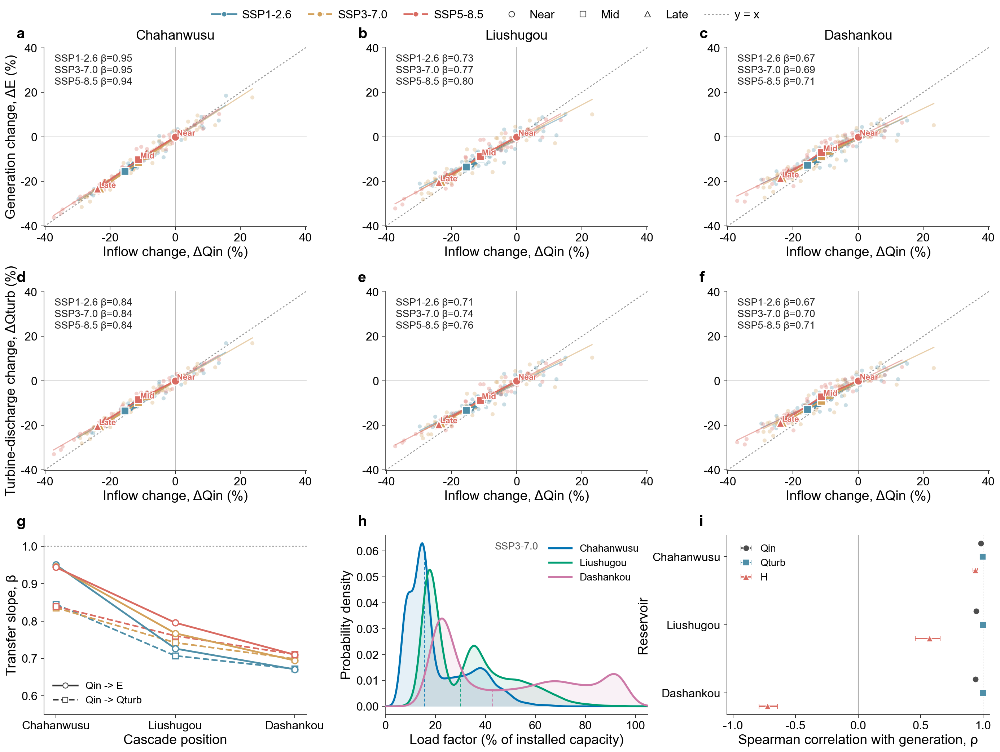


Fig. 6 statistics
  Reservoir Scenario  beta_Qin_to_E  R2_Qin_to_E  beta_Qin_to_Qturb  R2_Qin_to_Qturb  rho_Qin_E  rho_Qturb_E  rho_Head_E
 Chahanwusu   SSP126          0.951        0.960              0.845            0.962      0.981        0.998       0.942
 Chahanwusu   SSP370          0.946        0.964              0.836            0.970      0.983        0.997       0.956
 Chahanwusu   SSP585          0.944        0.974              0.839            0.977      0.981        0.996       0.919
  Liushugou   SSP126          0.726        0.869              0.707            0.876      0.928        0.999       0.600
  Liushugou   SSP370          0.767        0.870              0.742            0.879      0.947        0.998       0.656
  Liushugou   SSP585          0.796        0.934              0.760            0.938      0.956        0.999       0.458
  Dashankou   SSP126          0.671        0.866              0.672            0.863      0.932        0.999      -0.734
  Dashankou  

In [62]:
# -*- coding: utf-8 -*-
"""
Fig. 6 v6 — Trajectory Plot (时间轨迹相图版)
"""

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patheffects as pe

from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")


# ============================================================
# 1. Paths
# ============================================================
FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)

FIG_DIR = Path(r"D:\博士论文\小论文3\图片")
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Time settings
# ============================================================
FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END   = pd.Timestamp("2070-12-31")

REFERENCE_START = 2017
REFERENCE_END   = 2035

PERIODS = [
    ("Near", 2017, 2035),
    ("Mid",  2036, 2055),
    ("Late", 2056, 2070),
]

PERIOD_MARKERS = {
    "Near": "o",
    "Mid":  "s",
    "Late": "^",
}

PERIOD_MARKER_SIZE = {
    "Near": 58,
    "Mid":  68,
    "Late": 78,
}


# ============================================================
# 3. Reservoirs
# ============================================================
RESERVOIRS = [
    "Chahanwusu",
    "Liushugou",
    "Dashankou"
]

RES_INFO = {
    "Chahanwusu": {"label": "Chahanwusu", "capacity_mw": 330, "color": "#0072B2"},
    "Liushugou":  {"label": "Liushugou",  "capacity_mw": 180, "color": "#009E73"},
    "Dashankou":  {"label": "Dashankou",  "capacity_mw": 80,  "color": "#CC79A7"}
}


# ============================================================
# 4. Scenarios (海盐-珊瑚色带)
# ============================================================
SCENARIOS = ["SSP126", "SSP370", "SSP585"]

SCENARIO_SHORT = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5"
}

SCENARIO_COLORS = {
    "SSP126": "#4F8FA8",   # sea-salt blue
    "SSP370": "#D3A15A",   # warm sand
    "SSP585": "#D96B62",   # coral
}

SCENARIO_LS = {
    "SSP126": "-",
    "SSP370": "--",
    "SSP585": "-."
}


# ============================================================
# 5. Variables used in panel i
# ============================================================
CONTROL_INFO = {
    "rho_Qin_E":   {"label": "Qin",     "color": "#4D4D4D", "marker": "o"},
    "rho_Qturb_E": {"label": "Qturb",   "color": "#4F8FA8", "marker": "s"},
    "rho_Head_E":  {"label": "H",       "color": "#D96B62", "marker": "^"}
}


# ============================================================
# 6. Font settings
# ============================================================
FS_BASE   = 17
FS_AXIS   = 18
FS_TICK   = 15.5
FS_PANEL  = 20
FS_TITLE  = 18
FS_LEGEND = 15.5
FS_ANNOT  = 13.5

AXIS_LW = 0.85
TICK_LW = 0.8

COLOR_ONE_TO_ONE = "#8C8C8C"
COLOR_ZERO = "#B0B0B0"

available_fonts = {f.name for f in fm.fontManager.ttflist}
for fname in ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]:
    if fname in available_fonts:
        plt.rcParams["font.family"] = fname
        break

plt.rcParams.update({
    "axes.unicode_minus": False,
    "font.size": FS_BASE,
    "axes.labelsize": FS_AXIS,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,
    "axes.linewidth": AXIS_LW,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 4.5,
    "ytick.major.size": 4.5,
    "xtick.major.width": TICK_LW,
    "ytick.major.width": TICK_LW,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.transparent": False
})


# ============================================================
# 8. Pandas frequency compatibility
# ============================================================
def year_freq():
    try:
        pd.tseries.frequencies.to_offset("YE")
        return "YE"
    except Exception:
        return "Y"

YEAR_FREQ = year_freq()


# ============================================================
# 9. Basic plotting tools
# ============================================================
def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(AXIS_LW)
    ax.spines["bottom"].set_linewidth(AXIS_LW)
    ax.tick_params(axis="both", width=TICK_LW, length=4.5, pad=4)
    ax.grid(False)


def panel_label(ax, label):
    ax.text(-0.105, 1.035, label, transform=ax.transAxes,
            fontsize=FS_PANEL, fontweight="bold", ha="left", va="bottom", color="black")


# ============================================================
# 10. Load data
# ============================================================
def load_future():
    future = {}
    print("\nLoading future simulations:")
    for sc in SCENARIOS:
        sc_dir = FUTURE_DIR / sc
        if not sc_dir.exists():
            print(f"[WARN] Missing directory: {sc_dir}")
            continue
        future[sc] = {}
        for name in RESERVOIRS:
            csv = sc_dir / f"cascade_output_{sc}_{name}_daily_results.csv"
            if not csv.exists(): continue
            df = pd.read_csv(csv, parse_dates=["Date"]).sort_values("Date").set_index("Date")
            future[sc][name] = df.loc[FUTURE_START:FUTURE_END].copy()
        print(f"  {SCENARIO_SHORT[sc]}: {list(future[sc].keys())}")
    return future


# ============================================================
# 11-13. Data Processing
# ============================================================
def numeric(df, col, clip_zero=False):
    if col not in df.columns: return None
    s = pd.to_numeric(df[col], errors="coerce")
    if clip_zero: s = s.fillna(0).clip(lower=0)
    return s


def annual_mean(df, col, clip_zero=True):
    s = numeric(df, col, clip_zero)
    if s is None: return None
    out = s.resample(YEAR_FREQ).mean()
    out.index = out.index.year
    return out


def annual_energy_mwh(df):
    p = numeric(df, "Power_MW", True)
    if p is None: return None
    daily_energy = (p * 24.0)
    annual = daily_energy.resample(YEAR_FREQ).sum()
    annual.index = annual.index.year
    return annual


def build_annual_metrics(df):
    qin = annual_mean(df, "Inflow_m3s", True)
    qturb = annual_mean(df, "Turbine_Flow_m3s", True)
    head = annual_mean(df, "Head_m", False)
    energy = annual_energy_mwh(df)

    if any(x is None for x in [qin, qturb, head, energy]): return None

    common = qin.index.intersection(qturb.index).intersection(head.index).intersection(energy.index)
    out = pd.DataFrame({
        "Qin": qin.loc[common],
        "Qturb": qturb.loc[common],
        "Head": head.loc[common],
        "Energy": energy.loc[common]
    })
    out.index.name = "Year"
    return out.replace([np.inf, -np.inf], np.nan).dropna()


# ============================================================
# 14-15. Periods & Relative Change
# ============================================================
def assign_period(year):
    for label, y0, y1 in PERIODS:
        if y0 <= year <= y1: return label
    return None

def calculate_relative_changes(annual_df):
    if annual_df is None: return None
    ref = annual_df.loc[(annual_df.index >= REFERENCE_START) & (annual_df.index <= REFERENCE_END)]
    if len(ref) == 0: return None

    ref_mean = ref.mean()
    change = pd.DataFrame(index=annual_df.index)

    for col in ["Qin", "Qturb", "Head", "Energy"]:
        ref_value = ref_mean[col]
        if (not np.isfinite(ref_value) or abs(ref_value) < 1e-12):
            change[f"d{col}"] = np.nan
        else:
            change[f"d{col}"] = ((annual_df[col] - ref_value) / ref_value * 100.0)

    change["Period"] = [assign_period(year) for year in change.index]
    return change


# ============================================================
# 16-18. Stats & Math Tools
# ============================================================
def spearman_rho(x, y):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 3: return np.nan
    rx = tmp["x"].rank().to_numpy()
    ry = tmp["y"].rank().to_numpy()
    if np.std(rx) <= 1e-12 or np.std(ry) <= 1e-12: return np.nan
    return float(np.corrcoef(rx, ry)[0, 1])


def linear_fit(x, y):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if len(tmp) < 5: return np.nan, np.nan, np.nan

    xv = tmp["x"].to_numpy()
    yv = tmp["y"].to_numpy()

    if np.std(xv) <= 1e-12: return np.nan, np.nan, np.nan

    beta, intercept = np.polyfit(xv, yv, 1)
    yhat = intercept + beta * xv
    ss_res = np.sum((yv - yhat) ** 2)
    ss_tot = np.sum((yv - np.mean(yv)) ** 2)
    r2 = np.nan if ss_tot <= 1e-12 else 1 - ss_res / ss_tot

    return float(beta), float(intercept), float(r2)


def kde_1d(data, xs, bw=None):
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]
    if len(data) > 5000:
        data = np.random.default_rng(0).choice(data, 5000, replace=False)

    n = len(data)
    if n < 2: return np.zeros_like(xs)

    if bw is None:
        std = np.std(data)
        iqr = np.percentile(data, 75) - np.percentile(data, 25)
        sigma = min(std, iqr / 1.34) if iqr > 0 else std
        if sigma <= 1e-12: sigma = 1.0
        bw = 0.9 * sigma * n ** (-0.2)

    diff = (xs[:, None] - data[None, :]) / bw
    kernel = np.exp(-0.5 * diff ** 2) / np.sqrt(2 * np.pi)
    return kernel.sum(axis=1) / (n * bw)


# ============================================================
# 19-20. Prepare Data & Statistics
# ============================================================
def prepare_all_metrics(future):
    annual = {name: {} for name in RESERVOIRS}
    changes = {name: {} for name in RESERVOIRS}

    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if name not in future.get(sc, {}): continue
            dat = build_annual_metrics(future[sc][name])
            if dat is None or len(dat) == 0: continue

            annual[name][sc] = dat
            delta = calculate_relative_changes(dat)
            if delta is not None:
                changes[name][sc] = delta

    return annual, changes


def build_statistics(annual, changes):
    rows = []
    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if (sc not in annual[name] or sc not in changes[name]): continue

            dat = annual[name][sc]
            delta = changes[name][sc]

            beta_e, _, r2_e = linear_fit(delta["dQin"], delta["dEnergy"])
            beta_qt, _, r2_qt = linear_fit(delta["dQin"], delta["dQturb"])

            rows.append({
                "Reservoir": name,
                "Scenario": sc,
                "beta_Qin_to_E": beta_e,
                "R2_Qin_to_E": r2_e,
                "beta_Qin_to_Qturb": beta_qt,
                "R2_Qin_to_Qturb": r2_qt,
                "rho_Qin_E": spearman_rho(dat["Qin"], dat["Energy"]),
                "rho_Qturb_E": spearman_rho(dat["Qturb"], dat["Energy"]),
                "rho_Head_E": spearman_rho(dat["Head"], dat["Energy"])
            })
    return pd.DataFrame(rows)


# ============================================================
# 21. Scatter / Trajectory panel (★ 方法一：时间轨迹相图 ★)
# ============================================================
def plot_transfer_panel(ax, changes_by_scenario, xcol, ycol):
    annotation_lines = []

    for sc in SCENARIOS:
        if sc not in changes_by_scenario: continue
        dat = changes_by_scenario[sc].copy().sort_index()
        color = SCENARIO_COLORS[sc]

        # 1. 画背景散点（年份点，半透明）
        ax.scatter(dat[xcol], dat[ycol], s=30, marker="o", 
                   facecolor=color, edgecolor="white", linewidth=0.4, 
                   alpha=0.3, zorder=2)

        # 2. 提取三个时期的均值中心点
        centroids = []
        for period_name, _, _ in PERIODS:
            sub = dat[dat["Period"] == period_name]
            if len(sub) > 0:
                cx = sub[xcol].mean()
                cy = sub[ycol].mean()
                centroids.append((cx, cy, period_name))

        # 3. 绘制带箭头的轨迹线
        if len(centroids) > 1:
            xs = [c[0] for c in centroids]
            ys = [c[1] for c in centroids]
            
            # 连线
            ax.plot(xs, ys, color=color, lw=2.0, ls="--", alpha=0.8, zorder=4)
            
            # 箭头
            for i in range(len(xs) - 1):
                ax.annotate("", xy=(xs[i+1], ys[i+1]), xycoords='data',
                            xytext=(xs[i], ys[i]), textcoords='data',
                            arrowprops=dict(arrowstyle="->", color=color, 
                                            lw=2.0, mutation_scale=20, 
                                            shrinkA=5, shrinkB=5),
                            zorder=5)

        # 4. 画三个时期的中心大标记
        for cx, cy, p_name in centroids:
            ax.scatter(cx, cy, s=120, marker=PERIOD_MARKERS[p_name], 
                       facecolor=color, edgecolor="white", linewidth=1.5, 
                       zorder=6)
            
            # 仅给 SSP585 添加文字标注，避免图面杂乱
            if sc == "SSP585":
                ax.text(cx + 0.5, cy + 0.5, p_name, fontsize=11, 
                        color=color, fontweight="bold", zorder=7,
                        path_effects=[pe.withStroke(linewidth=2, foreground="white")])

        # 5. 计算整体回归线
        df_clean = pd.DataFrame({"x": dat[xcol], "y": dat[ycol]}).replace([np.inf, -np.inf], np.nan).dropna()
        xv, yv = df_clean["x"].to_numpy(), df_clean["y"].to_numpy()
        beta, intercept, r2 = linear_fit(xv, yv)
        
        if np.isfinite(beta) and len(xv) >= 5:
            xx = np.linspace(xv.min(), xv.max(), 10)
            ax.plot(xx, intercept + beta * xx, color=color, lw=1.5, alpha=0.5, zorder=3)
            annotation_lines.append(f"{SCENARIO_SHORT[sc]} β={beta:.2f}")

    # 零参考线
    ax.axhline(0, color=COLOR_ZERO, linewidth=0.8, zorder=0)
    ax.axvline(0, color=COLOR_ZERO, linewidth=0.8, zorder=0)

    # 统计文本
    if annotation_lines:
        ax.text(0.04, 0.96, "\n".join(annotation_lines), transform=ax.transAxes,
                ha="left", va="top", fontsize=FS_ANNOT, linespacing=1.30, color="#222222",
                bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="none", alpha=0.85),
                zorder=10)


def collect_values(changes, xcol, ycol):
    xs, ys = [], []
    for name in RESERVOIRS:
        for sc in SCENARIOS:
            if sc not in changes[name]: continue
            dat = changes[name][sc]
            xs.extend(dat[xcol].dropna().tolist())
            ys.extend(dat[ycol].dropna().tolist())
    return np.asarray(xs), np.asarray(ys)


def symmetric_limit(x, y, pad=0.08):
    vals = np.concatenate([x, y])
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0: return -1, 1
    max_abs = np.max(np.abs(vals))
    if max_abs <= 1e-12: max_abs = 1.0
    bound = max_abs * (1 + pad)
    return -bound, bound


def add_one_to_one(ax):
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    lo, hi = min(xmin, ymin), max(xmax, ymax)
    ax.plot([lo, hi], [lo, hi], color=COLOR_ONE_TO_ONE, linestyle=(0, (2, 2)),
            linewidth=1.25, alpha=0.90, zorder=1)


# ============================================================
# 23. Panel g
# ============================================================
def plot_beta_profile(ax, stat_df):
    x = np.arange(len(RESERVOIRS))
    order_map = {name: i for i, name in enumerate(RESERVOIRS)}

    for sc in SCENARIOS:
        sub = stat_df[stat_df["Scenario"] == sc].copy()
        sub["order"] = sub["Reservoir"].map(order_map)
        sub = sub.sort_values("order")

        beta_e = sub["beta_Qin_to_E"].to_numpy()
        beta_qt = sub["beta_Qin_to_Qturb"].to_numpy()

        ax.plot(x, beta_e, color=SCENARIO_COLORS[sc], linestyle="-", linewidth=2.4,
                marker="o", markersize=8, markerfacecolor="white", markeredgewidth=1.7, zorder=4)
        ax.plot(x, beta_qt, color=SCENARIO_COLORS[sc], linestyle="--", linewidth=2.2,
                marker="s", markersize=7.3, markerfacecolor="white", markeredgewidth=1.6, zorder=3)

    ax.axhline(1.0, color="#9A9A9A", linestyle=(0, (2, 2)), linewidth=1.1, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels([RES_INFO[n]["label"] for n in RESERVOIRS])
    ax.set_ylabel("Transfer slope, β") 
    ax.set_xlabel("Cascade position")
    ax.set_ylim(0.55, 1.03)

    handles = [
        Line2D([0], [0], color="#333333", linestyle="-", marker="o",
               markerfacecolor="white", linewidth=2.2, markersize=7, label="Qin -> E"),
        Line2D([0], [0], color="#333333", linestyle="--", marker="s",
               markerfacecolor="white", linewidth=2.0, markersize=6.5, label="Qin -> Qturb")
    ]
    ax.legend(handles=handles, frameon=False, loc="lower left", fontsize=FS_ANNOT, handlelength=2.4)
    clean_axis(ax)


# ============================================================
# 24. Panel h
# ============================================================
def plot_load_factor_density(ax, future, scenario="SSP370"):
    xs = np.linspace(0, 105, 450)
    for name in RESERVOIRS:
        if name not in future.get(scenario, {}): continue
        df = future[scenario][name]
        p = numeric(df, "Power_MW", True)
        if p is None: continue

        capacity = RES_INFO[name]["capacity_mw"]
        load_factor = (p.to_numpy() / capacity * 100.0)
        load_factor = load_factor[np.isfinite(load_factor)]

        dens = kde_1d(load_factor, xs)
        color = RES_INFO[name]["color"]

        ax.fill_between(xs, 0, dens, color=color, alpha=0.10, linewidth=0)
        ax.plot(xs, dens, color=color, linewidth=2.6, label=RES_INFO[name]["label"], zorder=3)

        median = np.nanmedian(load_factor)
        ymax_med = np.interp(median, xs, dens)
        ax.plot([median, median], [0, ymax_med], color=color, linestyle=(0, (3, 2)), linewidth=1.3, alpha=0.85)

    ax.set_xlim(0, 105)
    ax.set_xlabel("Load factor (% of installed capacity)")
    ax.set_ylabel("Probability density")
    ax.text(0.5, 0.96, "SSP3-7.0", transform=ax.transAxes, ha="center", va="top", fontsize=FS_ANNOT, color="#555555")
    ax.legend(frameon=False, loc="upper right", fontsize=FS_ANNOT, handlelength=2.2)
    clean_axis(ax)


# ============================================================
# 25. Panel i
# ============================================================
def plot_control_forest(ax, stat_df):
    base_y = np.array([2, 1, 0], dtype=float)
    variable_offsets = {"rho_Qin_E": +0.20, "rho_Qturb_E": 0.00, "rho_Head_E": -0.20}

    for variable, info in CONTROL_INFO.items():
        means, lows, highs = [], [], []
        for name in RESERVOIRS:
            vals = stat_df.loc[stat_df["Reservoir"] == name, variable].dropna().to_numpy()
            if len(vals) == 0:
                means.append(np.nan); lows.append(np.nan); highs.append(np.nan)
            else:
                means.append(np.mean(vals)); lows.append(np.min(vals)); highs.append(np.max(vals))

        means, lows, highs = np.asarray(means), np.asarray(lows), np.asarray(highs)
        y = base_y + variable_offsets[variable]
        xerr = np.vstack([means - lows, highs - means])

        ax.errorbar(means, y, xerr=xerr, fmt=info["marker"], markersize=8.5,
                    markerfacecolor=info["color"], markeredgecolor="white", markeredgewidth=0.9,
                    color=info["color"], ecolor=info["color"], elinewidth=1.8,
                    capsize=3.5, capthick=1.4, linestyle="none", label=info["label"], zorder=4)

    ax.axvline(0, color="#999999", linewidth=1.0, linestyle="-", zorder=1)
    ax.axvline(1, color="#C2C2C2", linewidth=0.9, linestyle=(0, (2, 2)), zorder=1)

    ax.set_yticks(base_y)
    ax.set_yticklabels([RES_INFO[name]["label"] for name in RESERVOIRS])
    ax.set_xlim(-1.05, 1.05)
    ax.set_xticks([-1.0, -0.5, 0, 0.5, 1.0])
    ax.set_xlabel("Spearman correlation with generation, ρ") 
    ax.set_ylabel("Reservoir")
    ax.legend(frameon=False, loc="upper left", fontsize=FS_ANNOT, ncol=1, handletextpad=0.4)
    clean_axis(ax)


# ============================================================
# 26. Main figure
# ============================================================
def fig6_nature(future, save_stem="fig6_hydrological_signal_propagation_nature"):
    annual, changes = prepare_all_metrics(future)
    stat_df = build_statistics(annual, changes)

    fig, axes = plt.subplots(3, 3, figsize=(19.2, 14.7), facecolor="white")
    plt.subplots_adjust(left=0.075, right=0.985, bottom=0.075, top=0.915, wspace=0.30, hspace=0.36)

    panel_tags = [["a", "b", "c"], ["d", "e", "f"], ["g", "h", "i"]]

    # Row 1: ΔQin -> ΔE
    for j, name in enumerate(RESERVOIRS):
        ax = axes[0, j]
        plot_transfer_panel(ax, changes[name], "dQin", "dEnergy")
        ax.set_xlabel("Inflow change, ΔQin (%)")
        if j == 0:
            ax.set_ylabel("Generation change, ΔE (%)")
        ax.set_title(RES_INFO[name]["label"], fontsize=FS_TITLE, fontweight="normal", pad=10)
        panel_label(ax, panel_tags[0][j])
        clean_axis(ax)

    x1, y1 = collect_values(changes, "dQin", "dEnergy")
    lo1, hi1 = symmetric_limit(x1, y1)
    for j in range(3):
        axes[0, j].set_xlim(lo1, hi1)
        axes[0, j].set_ylim(lo1, hi1)
        add_one_to_one(axes[0, j])

    # Row 2: ΔQin -> ΔQturb
    for j, name in enumerate(RESERVOIRS):
        ax = axes[1, j]
        plot_transfer_panel(ax, changes[name], "dQin", "dQturb")
        ax.set_xlabel("Inflow change, ΔQin (%)")
        if j == 0:
            ax.set_ylabel("Turbine-discharge change, ΔQturb (%)")
        panel_label(ax, panel_tags[1][j])
        clean_axis(ax)

    x2, y2 = collect_values(changes, "dQin", "dQturb")
    lo2, hi2 = symmetric_limit(x2, y2)
    for j in range(3):
        axes[1, j].set_xlim(lo2, hi2)
        axes[1, j].set_ylim(lo2, hi2)
        add_one_to_one(axes[1, j])

    # Row 3
    plot_beta_profile(axes[2, 0], stat_df)
    panel_label(axes[2, 0], "g")

    plot_load_factor_density(axes[2, 1], future, scenario="SSP370")
    panel_label(axes[2, 1], "h")

    plot_control_forest(axes[2, 2], stat_df)
    panel_label(axes[2, 2], "i")

    # Global legend
    scenario_handles = [
        Line2D([0], [0], color=SCENARIO_COLORS[sc], linestyle=SCENARIO_LS[sc], linewidth=2.3,
               marker="o", markersize=7, markerfacecolor=SCENARIO_COLORS[sc], markeredgecolor="white",
               label=SCENARIO_SHORT[sc])
        for sc in SCENARIOS
    ]
    period_handles = [
        Line2D([0], [0], color="#333333", linestyle="none", marker=PERIOD_MARKERS[label],
               markersize=7.5, markerfacecolor="white", markeredgecolor="#333333", label=label)
        for label, _, _ in PERIODS
    ]
    one_to_one_handle = Line2D([0], [0], color=COLOR_ONE_TO_ONE, linestyle=(0, (2, 2)), linewidth=1.25, label="y = x")

    fig.legend(handles=(scenario_handles + period_handles + [one_to_one_handle]),
               loc="upper center", bbox_to_anchor=(0.5, 0.975), ncol=7,
               frameon=False, fontsize=FS_LEGEND, handlelength=2.1, columnspacing=1.35, handletextpad=0.5)

    # Save
    for ext in ["png", "pdf"]:
        save_path = FIG_DIR / f"{save_stem}.{ext}"
        fig.savefig(save_path, dpi=600, bbox_inches="tight", facecolor="white")
        print(f"Saved: {save_path}")

    plt.show()
    return stat_df


# ============================================================
# 27. Print statistics
# ============================================================
def print_statistics(stat_df):
    print("\n" + "=" * 120)
    print("Fig. 6 statistics")
    print("=" * 120)
    cols = ["Reservoir", "Scenario", "beta_Qin_to_E", "R2_Qin_to_E",
            "beta_Qin_to_Qturb", "R2_Qin_to_Qturb", "rho_Qin_E", "rho_Qturb_E", "rho_Head_E"]
    print(stat_df[cols].round(3).to_string(index=False))
    
    output_csv = FIG_DIR / "fig6_nature_statistics.csv"
    stat_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
    print("\nStatistics saved:", output_csv)


# ============================================================
# 28. Main
# ============================================================
if __name__ == "__main__":
    print("=" * 90)
    print("Fig. 6 — Trajectory Plot Version")
    print("=" * 90)
    
    future = load_future()
    if not future:
        raise FileNotFoundError("No future simulation results were found. Please check FUTURE_DIR.")

    stat_df = fig6_nature(future, save_stem="Fig6_Hydrological_Signal_Propagation")
    print_statistics(stat_df)
    print("\nFig. 6 completed.")

Fig. 7 saved successfully:
D:\博士论文\小论文3\图片\Fig7_future_hydropower_operating_reorganization.png


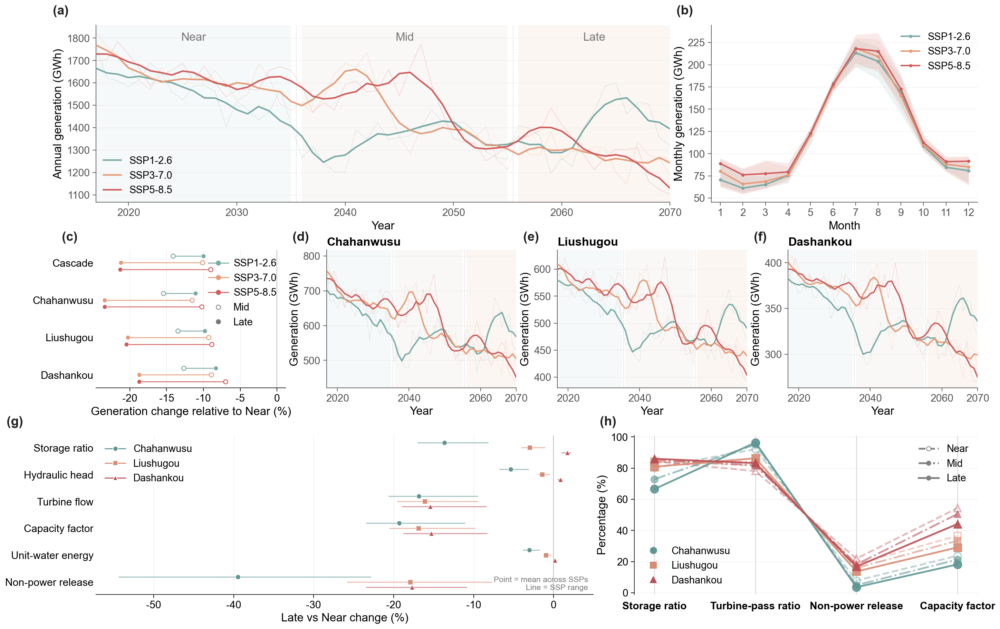

In [74]:
# -*- coding: utf-8 -*-
"""
Fig. 7
Future hydropower trajectories and operating-state reorganization
of the cascade reservoir system
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")


# ======================================================================
# 1. PATHS
# ======================================================================

FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)

OUTPUT_DIR = Path(
    r"D:\博士论文\小论文3\图片"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ======================================================================
# 2. BASIC SETTINGS
# ======================================================================

RESERVOIRS = [
    "Chahanwusu",
    "Liushugou",
    "Dashankou",
]

RES_LABELS = {
    "Chahanwusu": "Chahanwusu",
    "Liushugou": "Liushugou",
    "Dashankou": "Dashankou",
}

SCENARIOS = [
    "SSP126",
    "SSP370",
    "SSP585",
]

SCENARIO_LABELS = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5",
}


# ======================================================================
# 3. SEA-SALT → CORAL PALETTE
# ======================================================================

SCENARIO_COLORS = {
    "SSP126": "#78AAA5",   # sea-salt teal
    "SSP370": "#E59A78",   # soft coral
    "SSP585": "#CF5C5C",   # deep coral
}

RES_COLORS = {
    "Chahanwusu": "#5F9692",
    "Liushugou": "#D78B73",
    "Dashankou": "#B94F55",
}

RES_MARKERS = {
    "Chahanwusu": "o",
    "Liushugou": "s",
    "Dashankou": "^",
}

SEA_SALT_LIGHT = "#EAF3F1"
CORAL_LIGHT = "#F5D6C8"
MID_GRAY = "#777777"
DARK_GRAY = "#3F3F3F"
LIGHT_GRAY = "#D9D9D9"
WHITE = "#FFFFFF"


# ======================================================================
# 4. CAPACITY AND PERIODS
# ======================================================================

CAPACITY = {
    "Chahanwusu": 330,
    "Liushugou": 180,
    "Dashankou": 80,
}

PERIODS = {
    "Near": (2017, 2035),
    "Mid":  (2036, 2055),
    "Late": (2056, 2070),
}

PERIOD_ORDER = ["Near", "Mid", "Late"]

FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END = pd.Timestamp("2070-12-31")
SECONDS_DAY = 86400.0


# ======================================================================
# 5. MATPLOTLIB STYLE (全局字体大字号)
# ======================================================================

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 15.5,
    "axes.labelsize": 16,
    "axes.titlesize": 16.5,
    "xtick.labelsize": 14.5,
    "ytick.labelsize": 14.5,
    "legend.fontsize": 14,
    "axes.linewidth": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.major.size": 5.0,
    "ytick.major.size": 5.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.unicode_minus": False,
    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
})


# ======================================================================
# 6. LOAD FUTURE SIMULATION DATA
# ======================================================================

def load_future():
    future = {}
    for sc in SCENARIOS:
        sc_dir = FUTURE_DIR / sc
        future[sc] = {}
        for name in RESERVOIRS:
            path = (sc_dir / f"cascade_output_{sc}_{name}_daily_results.csv")
            if not path.exists():
                raise FileNotFoundError(f"Missing file:\n{path}")
            df = pd.read_csv(path, parse_dates=["Date"])
            df = df.sort_values("Date").set_index("Date")
            df = df.loc[FUTURE_START:FUTURE_END].copy()
            future[sc][name] = df

        sys_path = (sc_dir / f"cascade_output_{sc}_system_daily_results.csv")
        if sys_path.exists():
            df = pd.read_csv(sys_path, parse_dates=["Date"])
            df = df.sort_values("Date").set_index("Date")
            df = df.loc[FUTURE_START:FUTURE_END].copy()
            future[sc]["_system"] = df

    return future


# ======================================================================
# 7. BASIC DATA FUNCTIONS
# ======================================================================

def numeric(df, col):
    if col not in df.columns: return None
    return pd.to_numeric(df[col], errors="coerce")

def annual_energy(df):
    p = numeric(df, "Power_MW")
    if p is None: return None
    daily_energy = (p.fillna(0).clip(lower=0) * 24 / 1000)
    y = daily_energy.resample("Y").sum()
    y.index = y.index.year
    return y

def monthly_energy(df):
    p = numeric(df, "Power_MW")
    if p is None: return None
    daily_energy = (p.fillna(0).clip(lower=0) * 24 / 1000)
    return daily_energy.resample("M").sum()

def annual_system_energy(future, sc):
    if "_system" in future[sc]:
        df = future[sc]["_system"]
        if "System_Total_Power_MW" in df.columns:
            p = pd.to_numeric(df["System_Total_Power_MW"], errors="coerce")
            y = (p.fillna(0).clip(lower=0) * 24 / 1000).resample("Y").sum()
            y.index = y.index.year
            return y

    total = None
    for name in RESERVOIRS:
        s = annual_energy(future[sc][name])
        if total is None: total = s.copy()
        else: total = total.add(s, fill_value=0)
    return total

def monthly_system_energy(future, sc):
    if "_system" in future[sc]:
        df = future[sc]["_system"]
        if "System_Total_Power_MW" in df.columns:
            p = pd.to_numeric(df["System_Total_Power_MW"], errors="coerce")
            return (p.fillna(0).clip(lower=0) * 24 / 1000).resample("M").sum()

    total = None
    for name in RESERVOIRS:
        s = monthly_energy(future[sc][name])
        if total is None: total = s.copy()
        else: total = total.add(s, fill_value=0)
    return total

def annual_mean(df, col):
    s = numeric(df, col)
    if s is None: return None
    y = s.resample("Y").mean()
    y.index = y.index.year
    return y

def annual_volume(df, col):
    s = numeric(df, col)
    if s is None: return None
    daily_volume = (s.fillna(0).clip(lower=0) * SECONDS_DAY / 1e8)
    y = daily_volume.resample("Y").sum()
    y.index = y.index.year
    return y

def period_mean(series, period):
    y0, y1 = PERIODS[period]
    x = series.loc[(series.index >= y0) & (series.index <= y1)]
    return np.nanmean(x.values)

def pct_change(new, base):
    if not np.isfinite(base) or base == 0: return np.nan
    return (new - base) / base * 100


# ======================================================================
# 8. HYDROPOWER OPERATION INDICATORS
# ======================================================================

def capacity_factor(df, capacity):
    p = numeric(df, "Power_MW")
    if p is None: return None
    y = p.fillna(0).clip(lower=0).resample("Y").mean()
    y.index = y.index.year
    return y / capacity * 100

def turbine_pass_ratio(df):
    turbine = annual_volume(df, "Turbine_Flow_m3s")
    total = annual_volume(df, "Total_Outflow_m3s")
    if turbine is None or total is None: return None
    idx = turbine.index.intersection(total.index)
    return turbine.loc[idx] / total.loc[idx].replace(0, np.nan) * 100

def unit_water_energy(df):
    e = annual_energy(df)
    v = annual_volume(df, "Turbine_Flow_m3s")
    if e is None or v is None: return None
    idx = e.index.intersection(v.index)
    return e.loc[idx] / v.loc[idx] * 0.01

def storage_ratio_percent(df):
    s = annual_mean(df, "Storage_Ratio")
    if s is None: return None
    med = np.nanmedian(s.values)
    if np.isfinite(med) and med <= 1.5: s = s * 100
    return s

def nonpower_release_ratio(df):
    flood = annual_volume(df, "Flood_Release_m3s")
    draw = annual_volume(df, "Drawdown_Release_m3s")
    total = annual_volume(df, "Total_Outflow_m3s")
    if total is None: return None
    if flood is None: flood = total * 0
    if draw is None: draw = total * 0
    idx = total.index.intersection(flood.index).intersection(draw.index)
    return ((flood.loc[idx] + draw.loc[idx]) / total.loc[idx].replace(0, np.nan) * 100)


# ======================================================================
# 9. COMMON PLOT UTILITIES
# ======================================================================

def add_period_background(ax):
    ax.axvspan(2017, 2035, color=SEA_SALT_LIGHT, alpha=0.42, lw=0, zorder=0)
    ax.axvspan(2036, 2055, color="#F5F1ED", alpha=0.45, lw=0, zorder=0)
    ax.axvspan(2056, 2070, color=CORAL_LIGHT, alpha=0.22, lw=0, zorder=0)
    ax.axvline(2035.5, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=1)
    ax.axvline(2055.5, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=1)

def style_axis(ax):
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.tick_params(colors="#555555")
    ax.grid(axis="y", color="#E9E9E7", lw=0.6, alpha=0.75, zorder=0)

def panel_label(ax, label, x=-0.10, y=1.05):
    ax.text(x, y, label, transform=ax.transAxes, fontsize=18, fontweight="bold",
            ha="left", va="bottom", color="#202020")

def rolling_series(s, window=5):
    return s.rolling(window, center=True, min_periods=3).mean().interpolate(limit_direction="both")


# ======================================================================
# 10. PANEL A
# ======================================================================

def plot_panel_a(ax, future):
    add_period_background(ax)

    for sc in SCENARIOS:
        s = annual_system_energy(future, sc)
        years = np.asarray(s.index, dtype=float)
        values = np.asarray(s.values, dtype=float)

        ax.plot(years, values, color=SCENARIO_COLORS[sc], lw=0.75, alpha=0.26, zorder=2)
        roll = rolling_series(s, 5)
        ax.plot(roll.index, roll.values, color=SCENARIO_COLORS[sc], lw=2.15,
                solid_capstyle="round", label=SCENARIO_LABELS[sc], zorder=4)

    ax.set_xlim(2017, 2070)
    ax.set_xticks([2020, 2030, 2040, 2050, 2060, 2070])
    ax.set_ylabel("Annual generation (GWh)")
    ax.set_xlabel("Year")
    
    style_axis(ax)
    ax.legend(frameon=False, loc="lower left", handlelength=1.8, borderpad=0.2)

    ylim = ax.get_ylim()
    ytop = ylim[0] + 0.96 * (ylim[1] - ylim[0])
    for xpos, txt in [(2026, "Near"), (2045.5, "Mid"), (2063, "Late")]:
        ax.text(xpos, ytop, txt, fontsize=16, color=MID_GRAY, ha="center", va="top")

    panel_label(ax, "(a)", x=-0.075, y=1.045)


# ======================================================================
# 11. PANEL B
# ======================================================================

def plot_panel_b(ax, future):
    months = np.arange(1, 13)
    # ★ 修改点：直接使用数字 1~12 作为 x 轴标签
    month_labels = [str(i) for i in range(1, 13)] 

    for sc in SCENARIOS:
        m = monthly_system_energy(future, sc)
        tmp = pd.DataFrame({"value": m.values}, index=m.index)
        tmp["month"] = tmp.index.month

        med = tmp.groupby("month")["value"].median().reindex(months).interpolate(limit_direction="both")
        q25 = tmp.groupby("month")["value"].quantile(0.25).reindex(months).interpolate(limit_direction="both")
        q75 = tmp.groupby("month")["value"].quantile(0.75).reindex(months).interpolate(limit_direction="both")

        ax.fill_between(months, q25.values, q75.values, color=SCENARIO_COLORS[sc], alpha=0.12, lw=0, zorder=1)
        ax.plot(months, med.values, color=SCENARIO_COLORS[sc], lw=2.0, marker="o",
                markersize=4.5, markeredgewidth=0, label=SCENARIO_LABELS[sc], zorder=3)

    ax.set_xticks(months)
    ax.set_xticklabels(month_labels)
    ax.set_xlim(0.6, 12.4)
    ax.set_xlabel("Month")
    ax.set_ylabel("Monthly generation (GWh)")
    
    style_axis(ax)
    ax.legend(frameon=False, loc="best", handlelength=1.8, borderpad=0.2)
    panel_label(ax, "(b)", x=-0.13, y=1.045)


# ======================================================================
# 12. PANEL C
# ======================================================================

def get_object_annual_energy(future, sc, obj):
    if obj == "Cascade": return annual_system_energy(future, sc)
    return annual_energy(future[sc][obj])

def plot_panel_c(ax, future):
    objects = ["Cascade", "Chahanwusu", "Liushugou", "Dashankou"]
    object_labels = ["Cascade", "Chahanwusu", "Liushugou", "Dashankou"]
    ypos = np.arange(len(objects))[::-1]
    offsets = {"SSP126": +0.18, "SSP370": 0.00, "SSP585": -0.18}

    ax.axvline(0, color=DARK_GRAY, lw=0.9, ls="-", alpha=0.65, zorder=0)

    for sc in SCENARIOS:
        for i, obj in enumerate(objects):
            s = get_object_annual_energy(future, sc, obj)
            near = period_mean(s, "Near")
            mid = period_mean(s, "Mid")
            late = period_mean(s, "Late")

            d_mid = pct_change(mid, near)
            d_late = pct_change(late, near)
            yy = ypos[i] + offsets[sc]

            ax.plot([d_mid, d_late], [yy, yy], color=SCENARIO_COLORS[sc], lw=1.35, alpha=0.85, zorder=2)
            ax.scatter(d_mid, yy, s=35, facecolor=WHITE, edgecolor=SCENARIO_COLORS[sc], linewidth=1.2, zorder=4)
            ax.scatter(d_late, yy, s=38, color=SCENARIO_COLORS[sc], edgecolor=WHITE, linewidth=0.4, zorder=5)

    ax.set_yticks(ypos)
    ax.set_yticklabels(object_labels)
    ax.set_xlabel("Generation change relative to Near (%)")
    
    ax.grid(axis="x", color="#E9E9E7", lw=0.6)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

    handles = [Line2D([0], [0], marker="o", linestyle="-", lw=1.3, markersize=6,
                      color=SCENARIO_COLORS[sc], label=SCENARIO_LABELS[sc]) for sc in SCENARIOS]
    stage_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=WHITE, markeredgecolor=MID_GRAY, markersize=6, label="Mid"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=MID_GRAY, markeredgecolor=MID_GRAY, markersize=6, label="Late")
    ]

    ax.legend(handles=handles + stage_handles, frameon=False, loc="upper right",
              ncol=1, handletextpad=0.5)

    panel_label(ax, "(c)", x=-0.18, y=1.045)


# ======================================================================
# 13. PANELS D–F (保留标题)
# ======================================================================

def plot_reservoir_trajectory(ax, future, reservoir, panel):
    add_period_background(ax)

    for sc in SCENARIOS:
        s = annual_energy(future[sc][reservoir])
        ax.plot(s.index, s.values, color=SCENARIO_COLORS[sc], lw=0.65, alpha=0.22, zorder=2)
        roll = rolling_series(s, window=5)
        ax.plot(roll.index, roll.values, color=SCENARIO_COLORS[sc], lw=1.9, solid_capstyle="round", zorder=4)

    ax.set_xlim(2017, 2070)
    ax.set_xticks([2020, 2040, 2060, 2070])
    ax.set_xlabel("Year")
    ax.set_ylabel("Generation (GWh)")
    ax.set_title(RES_LABELS[reservoir], loc="left", pad=6, fontweight="bold") # 保留
    style_axis(ax)
    panel_label(ax, panel, x=-0.18, y=1.045)


# ======================================================================
# 14. PANEL G
# ======================================================================

def get_metric_series(df, reservoir, metric):
    if metric == "Storage": return storage_ratio_percent(df)
    if metric == "Head": return annual_mean(df, "Head_m")
    if metric == "Turbine flow": return annual_mean(df, "Turbine_Flow_m3s")
    if metric == "Capacity factor": return capacity_factor(df, CAPACITY[reservoir])
    if metric == "Unit energy": return unit_water_energy(df)
    if metric == "Non-power release": return nonpower_release_ratio(df)
    raise ValueError(metric)

def plot_panel_g(ax, future):
    metrics = ["Storage", "Head", "Turbine flow", "Capacity factor", "Unit energy", "Non-power release"]
    labels = ["Storage ratio", "Hydraulic head", "Turbine flow", "Capacity factor", "Unit-water energy", "Non-power release"]

    ypos = np.arange(len(metrics))[::-1]
    offsets = {"Chahanwusu": +0.19, "Liushugou": 0.00, "Dashankou": -0.19}

    ax.axvline(0, color=DARK_GRAY, lw=0.9, alpha=0.7, zorder=1)

    for reservoir in RESERVOIRS:
        for i, metric in enumerate(metrics):
            deltas = []
            for sc in SCENARIOS:
                s = get_metric_series(future[sc][reservoir], reservoir, metric)
                if s is None: continue
                near = period_mean(s, "Near")
                late = period_mean(s, "Late")
                delta = pct_change(late, near)
                if np.isfinite(delta): deltas.append(delta)

            if len(deltas) == 0: continue
            mean_delta = np.nanmean(deltas)
            min_delta = np.nanmin(deltas)
            max_delta = np.nanmax(deltas)
            yy = ypos[i] + offsets[reservoir]

            ax.plot([min_delta, max_delta], [yy, yy], color=RES_COLORS[reservoir], lw=1.5, alpha=0.55, solid_capstyle="round", zorder=2)
            ax.scatter(mean_delta, yy, marker=RES_MARKERS[reservoir], s=45, facecolor=RES_COLORS[reservoir], edgecolor=WHITE, linewidth=0.55, zorder=4)

    ax.set_yticks(ypos)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Late vs Near change (%)")
    
    ax.grid(axis="x", color="#E9E9E7", lw=0.6)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

    handles = [Line2D([0], [0], marker=RES_MARKERS[r], linestyle="-", color=RES_COLORS[r],
                      markerfacecolor=RES_COLORS[r], markeredgecolor=WHITE, lw=1.4, markersize=7, label=RES_LABELS[r])
               for r in RESERVOIRS]

    ax.legend(handles=handles, frameon=False, loc="best")
    ax.text(0.99, 0.02, "Point = mean across SSPs\nLine = SSP range",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=11, color=MID_GRAY)
    panel_label(ax, "(g)", x=-0.18, y=1.045)


# ======================================================================
# 15. PANEL H — 平行坐标图
# ======================================================================

def plot_panel_h(ax, future):
    metrics = ["Storage", "Turbine_pass", "Non_power", "Capacity_factor"]
    x_labels = ["Storage ratio", "Turbine-pass ratio", "Non-power release", "Capacity factor"]
    x_pos = np.arange(len(metrics))
    
    for x in x_pos:
        ax.axvline(x, color=LIGHT_GRAY, lw=1.2, zorder=1)

    for res in RESERVOIRS:
        res_data = {}
        for period in PERIOD_ORDER:
            vals = []
            for metric in metrics:
                if metric == "Storage":
                    s = storage_ratio_percent(future["SSP585"][res])
                elif metric == "Turbine_pass":
                    s = turbine_pass_ratio(future["SSP585"][res])
                elif metric == "Non_power":
                    s = nonpower_release_ratio(future["SSP585"][res])
                elif metric == "Capacity_factor":
                    s = capacity_factor(future["SSP585"][res], CAPACITY[res])
                
                vals.append(period_mean(s, period) if s is not None else np.nan)
            res_data[period] = vals

        lw = 2.5
        # Near
        ax.plot(x_pos, res_data["Near"], color=RES_COLORS[res], ls="--", lw=lw, alpha=0.4,
                marker=RES_MARKERS[res], markersize=10, markerfacecolor=WHITE, markeredgewidth=2, zorder=3)
        # Mid
        ax.plot(x_pos, res_data["Mid"], color=RES_COLORS[res], ls="-.", lw=lw, alpha=0.6,
                marker=RES_MARKERS[res], markersize=10, markerfacecolor=RES_COLORS[res], markeredgewidth=1, zorder=4)
        # Late
        ax.plot(x_pos, res_data["Late"], color=RES_COLORS[res], ls="-", lw=lw, alpha=0.9,
                marker=RES_MARKERS[res], markersize=11, markerfacecolor=RES_COLORS[res], markeredgewidth=1.5, zorder=5)

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontweight="bold")
    ax.set_xlim(-0.2, len(metrics)-0.8)
    ax.set_ylabel("Percentage (%)")
    
    ax.grid(axis="y", color="#E9E9E7", lw=0.6, alpha=0.75, zorder=0)
    ax.grid(axis="x", visible=False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0, pad=10)

    leg_res = [Line2D([0], [0], marker=RES_MARKERS[r], color=RES_COLORS[r], linestyle="none", 
                      markersize=9, label=RES_LABELS[r]) for r in RESERVOIRS]
    leg_period = [
        Line2D([0], [0], color="gray", linestyle="--", lw=2.5, marker="o", markerfacecolor=WHITE, label="Near"),
        Line2D([0], [0], color="gray", linestyle="-.", lw=2.5, marker="o", markerfacecolor="gray", label="Mid"),
        Line2D([0], [0], color="gray", linestyle="-",  lw=2.5, marker="o", markerfacecolor="gray", label="Late")
    ]
    
    l1 = ax.legend(handles=leg_res, frameon=False, loc="lower left")
    ax.add_artist(l1)
    ax.legend(handles=leg_period, frameon=False, loc="upper right")

    panel_label(ax, "(h)", x=-0.10, y=1.045)


# ======================================================================
# 16. MAIN FIGURE LAYOUT
# ======================================================================

def draw_figure(future):
    fig = plt.figure(figsize=(18.5, 12.5), facecolor=WHITE)
    
    # wspace 1.15, hspace 0.30
    outer = fig.add_gridspec(nrows=3, ncols=12, height_ratios=[1.18, 0.92, 1.06], 
                             hspace=0.30, wspace=1.15)

    ax_a = fig.add_subplot(outer[0, 0:8])
    ax_b = fig.add_subplot(outer[0, 8:12])
    ax_c = fig.add_subplot(outer[1, 0:3])
    ax_d = fig.add_subplot(outer[1, 3:6])
    ax_e = fig.add_subplot(outer[1, 6:9])
    ax_f = fig.add_subplot(outer[1, 9:12])
    ax_g = fig.add_subplot(outer[2, 0:7])
    ax_h = fig.add_subplot(outer[2, 7:12])

    plot_panel_a(ax_a, future)
    plot_panel_b(ax_b, future)
    plot_panel_c(ax_c, future)
    plot_reservoir_trajectory(ax_d, future, "Chahanwusu", "(d)")
    plot_reservoir_trajectory(ax_e, future, "Liushugou", "(e)")
    plot_reservoir_trajectory(ax_f, future, "Dashankou", "(f)")
    plot_panel_g(ax_g, future)
    plot_panel_h(ax_h, future)

    fig.subplots_adjust(left=0.06, right=0.98, top=0.96, bottom=0.08)

    out_png = OUTPUT_DIR / "Fig7_future_hydropower_operating_reorganization.png"
    out_pdf = OUTPUT_DIR / "Fig7_future_hydropower_operating_reorganization.pdf"
    out_svg = OUTPUT_DIR / "Fig7_future_hydropower_operating_reorganization.svg"

    fig.savefig(out_png, dpi=600, bbox_inches="tight", facecolor=WHITE)
    fig.savefig(out_pdf, bbox_inches="tight", facecolor=WHITE)
    fig.savefig(out_svg, bbox_inches="tight", facecolor=WHITE)

    print("=" * 70)
    print("Fig. 7 saved successfully:")
    print(out_png)
    print("=" * 70)
    plt.show()


# ======================================================================
# 17. MAIN
# ======================================================================

if __name__ == "__main__":
    future = load_future()
    draw_figure(future)

Fig. 7 | Future hydropower trajectories, operating-state reorganization, and functional differentiation
Fig. 7 saved successfully:
D:\博士论文\小论文3\图片\Fig7_future_hydropower_operating_reorganization.png
D:\博士论文\小论文3\图片\Fig7_future_hydropower_operating_reorganization.pdf
D:\博士论文\小论文3\图片\Fig7_future_hydropower_operating_reorganization.svg


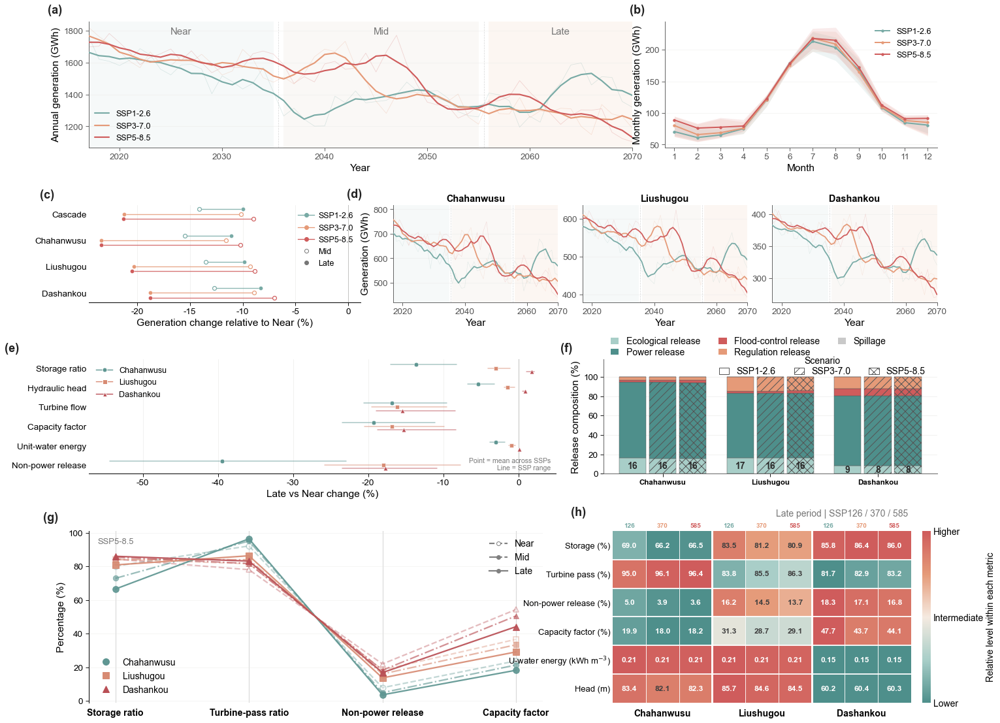

In [31]:
# -*- coding: utf-8 -*-
"""
Fig. 7
Future hydropower trajectories, operating-state reorganization,
and functional differentiation of the cascade reservoir system

Panels
------
(a) Cascade annual generation trajectory, 2017–2070
(b) Monthly generation seasonal envelope
(c) Stage-wise generation change relative to Near
(d) Reservoir-specific annual generation trajectories
(e) Multi-metric operating response: Late vs Near
(f) Release-function composition
(g) Reservoir-specific operating-state trajectories under SSP5-8.5
(h) Functional differentiation matrix (three scenarios × three reservoirs)
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")


# ======================================================================
# 1. PATHS
# ======================================================================

FUTURE_DIR = Path(
    r"D:\Python code\boshilunwen\梯级未来模拟\results_kaidu_future_20261011_115931"
)

OUTPUT_DIR = Path(
    r"D:\博士论文\小论文3\图片"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ======================================================================
# 2. BASIC SETTINGS
# ======================================================================

RESERVOIRS = ["Chahanwusu", "Liushugou", "Dashankou"]

RES_LABELS = {
    "Chahanwusu": "Chahanwusu",
    "Liushugou": "Liushugou",
    "Dashankou": "Dashankou",
}

RES_SHORT = {
    "Chahanwusu": "CHWS",
    "Liushugou": "LSG",
    "Dashankou": "DSK",
}

SCENARIOS = ["SSP126", "SSP370", "SSP585"]

SCENARIO_LABELS = {
    "SSP126": "SSP1-2.6",
    "SSP370": "SSP3-7.0",
    "SSP585": "SSP5-8.5",
}


# ======================================================================
# 3. SEA-SALT → CORAL PALETTE
# ======================================================================

SCENARIO_COLORS = {
    "SSP126": "#78AAA5",
    "SSP370": "#E59A78",
    "SSP585": "#CF5C5C",
}

RES_COLORS = {
    "Chahanwusu": "#5F9692",
    "Liushugou": "#D78B73",
    "Dashankou": "#B94F55",
}

RES_MARKERS = {
    "Chahanwusu": "o",
    "Liushugou": "s",
    "Dashankou": "^",
}

SEA_SALT_LIGHT = "#EAF3F1"
CORAL_LIGHT = "#F5D6C8"

MID_GRAY = "#777777"
DARK_GRAY = "#3F3F3F"
LIGHT_GRAY = "#D9D9D9"

WHITE = "#FFFFFF"


# ======================================================================
# 4. RELEASE COMPOSITION COLORS
# ======================================================================

RELEASE_COMPONENTS = [
    ("Eco_Release_m3s", "Ecological release"),
    ("Additional_Power_Flow_m3s", "Power release"),
    ("Flood_Release_m3s", "Flood-control release"),
    ("Drawdown_Release_m3s", "Regulation release"),
    ("Spill_m3s", "Spillage"),
]

RELEASE_COLORS = {
    "Ecological release": "#A8CEC8",
    "Power release": "#4E8F8B",
    "Flood-control release": "#CF5C5C",
    "Regulation release": "#E59A78",
    "Spillage": "#C9C9C9",
}

SCENARIO_HATCHES = {
    "SSP126": "",
    "SSP370": "//",
    "SSP585": "xx",
}


# ======================================================================
# 5. CAPACITY AND PERIODS
# ======================================================================

CAPACITY = {"Chahanwusu": 330, "Liushugou": 180, "Dashankou": 80}

PERIODS = {
    "Near": (2017, 2035),
    "Mid":  (2036, 2055),
    "Late": (2056, 2070),
}

PERIOD_ORDER = ["Near", "Mid", "Late"]

FUTURE_START = pd.Timestamp("2017-01-01")
FUTURE_END = pd.Timestamp("2070-12-31")

SECONDS_DAY = 86400.0


# ======================================================================
# 6. MATPLOTLIB STYLE
# ======================================================================

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "axes.labelsize": 15.5,
    "axes.titlesize": 16,
    "xtick.labelsize": 13.5,
    "ytick.labelsize": 13.5,
    "legend.fontsize": 12.5,
    "axes.linewidth": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.9,
    "ytick.major.width": 0.9,
    "xtick.major.size": 5.0,
    "ytick.major.size": 5.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.unicode_minus": False,
    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
})


# ======================================================================
# 7. LOAD FUTURE DATA
# ======================================================================

def load_future():
    future = {}
    for sc in SCENARIOS:
        sc_dir = FUTURE_DIR / sc
        future[sc] = {}
        for name in RESERVOIRS:
            path = sc_dir / f"cascade_output_{sc}_{name}_daily_results.csv"
            if not path.exists():
                raise FileNotFoundError(f"Missing file:\n{path}")
            df = pd.read_csv(path, parse_dates=["Date"])
            df = df.sort_values("Date").set_index("Date")
            df = df.loc[FUTURE_START:FUTURE_END].copy()
            future[sc][name] = df

        sys_path = sc_dir / f"cascade_output_{sc}_system_daily_results.csv"
        if sys_path.exists():
            df = pd.read_csv(sys_path, parse_dates=["Date"])
            df = df.sort_values("Date").set_index("Date")
            df = df.loc[FUTURE_START:FUTURE_END].copy()
            future[sc]["_system"] = df
    return future


# ======================================================================
# 8. BASIC DATA FUNCTIONS
# ======================================================================

def numeric(df, col):
    if col not in df.columns:
        return None
    return pd.to_numeric(df[col], errors="coerce")


def annual_energy(df):
    p = numeric(df, "Power_MW")
    if p is None:
        return None
    daily = p.fillna(0).clip(lower=0) * 24 / 1000
    y = daily.resample("Y").sum()
    y.index = y.index.year
    return y


def monthly_energy(df):
    p = numeric(df, "Power_MW")
    if p is None:
        return None
    daily = p.fillna(0).clip(lower=0) * 24 / 1000
    return daily.resample("M").sum()


def annual_system_energy(future, sc):
    if "_system" in future[sc]:
        df = future[sc]["_system"]
        if "System_Total_Power_MW" in df.columns:
            p = pd.to_numeric(df["System_Total_Power_MW"], errors="coerce")
            y = (p.fillna(0).clip(lower=0) * 24 / 1000).resample("Y").sum()
            y.index = y.index.year
            return y
    total = None
    for name in RESERVOIRS:
        s = annual_energy(future[sc][name])
        total = s.copy() if total is None else total.add(s, fill_value=0)
    return total


def monthly_system_energy(future, sc):
    if "_system" in future[sc]:
        df = future[sc]["_system"]
        if "System_Total_Power_MW" in df.columns:
            p = pd.to_numeric(df["System_Total_Power_MW"], errors="coerce")
            return (p.fillna(0).clip(lower=0) * 24 / 1000).resample("M").sum()
    total = None
    for name in RESERVOIRS:
        s = monthly_energy(future[sc][name])
        total = s.copy() if total is None else total.add(s, fill_value=0)
    return total


def annual_mean(df, col):
    s = numeric(df, col)
    if s is None:
        return None
    y = s.resample("Y").mean()
    y.index = y.index.year
    return y


def annual_volume(df, col):
    s = numeric(df, col)
    if s is None:
        return None
    daily = s.fillna(0).clip(lower=0) * SECONDS_DAY / 1e8
    y = daily.resample("Y").sum()
    y.index = y.index.year
    return y


def period_mean(series, period):
    y0, y1 = PERIODS[period]
    x = series.loc[(series.index >= y0) & (series.index <= y1)]
    return np.nanmean(x.values)


def pct_change(new, base):
    if (not np.isfinite(base)) or base == 0:
        return np.nan
    return (new - base) / base * 100


# ======================================================================
# 9. HYDROPOWER OPERATION INDICATORS
# ======================================================================

def capacity_factor(df, capacity):
    p = numeric(df, "Power_MW")
    if p is None:
        return None
    y = p.fillna(0).clip(lower=0).resample("Y").mean()
    y.index = y.index.year
    return y / capacity * 100


def turbine_pass_ratio(df):
    turbine = annual_volume(df, "Turbine_Flow_m3s")
    total = annual_volume(df, "Total_Outflow_m3s")
    if turbine is None or total is None:
        return None
    idx = turbine.index.intersection(total.index)
    return turbine.loc[idx] / total.loc[idx].replace(0, np.nan) * 100


def unit_water_energy(df):
    e = annual_energy(df)
    v = annual_volume(df, "Turbine_Flow_m3s")
    if e is None or v is None:
        return None
    idx = e.index.intersection(v.index)
    return e.loc[idx] / v.loc[idx] * 0.01


def storage_ratio_percent(df):
    s = annual_mean(df, "Storage_Ratio")
    if s is None:
        return None
    med = np.nanmedian(s.values)
    if np.isfinite(med) and med <= 1.5:
        s = s * 100
    return s


def nonpower_release_ratio(df):
    flood = annual_volume(df, "Flood_Release_m3s")
    draw = annual_volume(df, "Drawdown_Release_m3s")
    total = annual_volume(df, "Total_Outflow_m3s")
    if total is None:
        return None
    if flood is None:
        flood = total * 0
    if draw is None:
        draw = total * 0
    idx = total.index.intersection(flood.index).intersection(draw.index)
    return (flood.loc[idx] + draw.loc[idx]) / total.loc[idx].replace(0, np.nan) * 100


# ======================================================================
# 10. RELEASE COMPOSITION
# ======================================================================

def release_composition_percent(df):
    values = {}
    for col, label in RELEASE_COMPONENTS:
        if col in df.columns:
            s = pd.to_numeric(df[col], errors="coerce")
            values[label] = s.fillna(0).clip(lower=0).sum()
        else:
            values[label] = 0.0
    total = sum(values.values())
    if total <= 0:
        return {label: 0 for _, label in RELEASE_COMPONENTS}
    return {label: values[label] / total * 100 for _, label in RELEASE_COMPONENTS}


# ======================================================================
# 11. COMMON PLOT UTILITIES
# ======================================================================

def add_period_background(ax):
    ax.axvspan(2017, 2035, color=SEA_SALT_LIGHT, alpha=0.42, lw=0, zorder=0)
    ax.axvspan(2036, 2055, color="#F5F1ED", alpha=0.45, lw=0, zorder=0)
    ax.axvspan(2056, 2070, color=CORAL_LIGHT, alpha=0.22, lw=0, zorder=0)
    ax.axvline(2035.5, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=1)
    ax.axvline(2055.5, color=LIGHT_GRAY, lw=0.75, ls="--", zorder=1)


def style_axis(ax):
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.tick_params(colors="#555555")
    ax.grid(axis="y", color="#E9E9E7", lw=0.6, alpha=0.75, zorder=0)


def panel_label(ax, label, x=-0.10, y=1.05):
    ax.text(x, y, label, transform=ax.transAxes, fontsize=18,
            fontweight="bold", ha="left", va="bottom", color="#202020")


def rolling_series(s, window=5):
    return s.rolling(window, center=True, min_periods=3).mean().interpolate(limit_direction="both")


# ======================================================================
# 12. PANEL A
# ======================================================================

def plot_panel_a(ax, future):
    add_period_background(ax)
    for sc in SCENARIOS:
        s = annual_system_energy(future, sc)
        years = np.asarray(s.index, dtype=float)
        values = np.asarray(s.values, dtype=float)
        ax.plot(years, values, color=SCENARIO_COLORS[sc],
                lw=0.75, alpha=0.26, zorder=2)
        roll = rolling_series(s, 5)
        ax.plot(roll.index, roll.values, color=SCENARIO_COLORS[sc],
                lw=2.15, solid_capstyle="round",
                label=SCENARIO_LABELS[sc], zorder=4)
    ax.set_xlim(2017, 2070)
    ax.set_xticks([2020, 2030, 2040, 2050, 2060, 2070])
    ax.set_ylabel("Annual generation (GWh)")
    ax.set_xlabel("Year")
    style_axis(ax)
    ax.legend(frameon=False, loc="lower left", handlelength=1.8, borderpad=0.2)
    ylim = ax.get_ylim()
    ytop = ylim[0] + 0.96 * (ylim[1] - ylim[0])
    for xpos, txt in [(2026, "Near"), (2045.5, "Mid"), (2063, "Late")]:
        ax.text(xpos, ytop, txt, fontsize=15, color=MID_GRAY,
                ha="center", va="top")
    panel_label(ax, "(a)", x=-0.075, y=1.045)


# ======================================================================
# 13. PANEL B
# ======================================================================

def plot_panel_b(ax, future):
    months = np.arange(1, 13)
    month_labels = [str(i) for i in range(1, 13)]
    for sc in SCENARIOS:
        m = monthly_system_energy(future, sc)
        tmp = pd.DataFrame({"value": m.values}, index=m.index)
        tmp["month"] = tmp.index.month
        med = tmp.groupby("month")["value"].median().reindex(months).interpolate(limit_direction="both")
        q25 = tmp.groupby("month")["value"].quantile(0.25).reindex(months).interpolate(limit_direction="both")
        q75 = tmp.groupby("month")["value"].quantile(0.75).reindex(months).interpolate(limit_direction="both")
        ax.fill_between(months, q25.values, q75.values,
                        color=SCENARIO_COLORS[sc], alpha=0.12, lw=0, zorder=1)
        ax.plot(months, med.values, color=SCENARIO_COLORS[sc],
                lw=2.0, marker="o", markersize=4.5, markeredgewidth=0,
                label=SCENARIO_LABELS[sc], zorder=3)
    ax.set_xticks(months)
    ax.set_xticklabels(month_labels)
    ax.set_xlim(0.6, 12.4)
    ax.set_xlabel("Month")
    ax.set_ylabel("Monthly generation (GWh)")
    style_axis(ax)
    ax.legend(frameon=False, loc="best", handlelength=1.8, borderpad=0.2)
    panel_label(ax, "(b)", x=-0.13, y=1.045)


# ======================================================================
# 14. PANEL C
# ======================================================================

def get_object_annual_energy(future, sc, obj):
    if obj == "Cascade":
        return annual_system_energy(future, sc)
    return annual_energy(future[sc][obj])


def plot_panel_c(ax, future):
    objects = ["Cascade", "Chahanwusu", "Liushugou", "Dashankou"]
    object_labels = ["Cascade", "Chahanwusu", "Liushugou", "Dashankou"]
    ypos = np.arange(len(objects))[::-1]
    offsets = {"SSP126": +0.18, "SSP370": 0.00, "SSP585": -0.18}
    ax.axvline(0, color=DARK_GRAY, lw=0.9, ls="-", alpha=0.65, zorder=0)
    for sc in SCENARIOS:
        for i, obj in enumerate(objects):
            s = get_object_annual_energy(future, sc, obj)
            near = period_mean(s, "Near")
            mid = period_mean(s, "Mid")
            late = period_mean(s, "Late")
            d_mid = pct_change(mid, near)
            d_late = pct_change(late, near)
            yy = ypos[i] + offsets[sc]
            ax.plot([d_mid, d_late], [yy, yy],
                    color=SCENARIO_COLORS[sc], lw=1.35, alpha=0.85, zorder=2)
            ax.scatter(d_mid, yy, s=35, facecolor=WHITE,
                       edgecolor=SCENARIO_COLORS[sc], linewidth=1.2, zorder=4)
            ax.scatter(d_late, yy, s=38, color=SCENARIO_COLORS[sc],
                       edgecolor=WHITE, linewidth=0.4, zorder=5)
    ax.set_yticks(ypos)
    ax.set_yticklabels(object_labels)
    ax.set_xlabel("Generation change relative to Near (%)")
    ax.grid(axis="x", color="#E9E9E7", lw=0.6)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    handles = [Line2D([0], [0], marker="o", linestyle="-", lw=1.3, markersize=6,
                      color=SCENARIO_COLORS[sc], label=SCENARIO_LABELS[sc])
               for sc in SCENARIOS]
    stage_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=WHITE,
               markeredgecolor=MID_GRAY, markersize=6, label="Mid"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=MID_GRAY,
               markeredgecolor=MID_GRAY, markersize=6, label="Late"),
    ]
    ax.legend(handles=(handles + stage_handles), frameon=False,
              loc="upper right", ncol=1, handletextpad=0.5)
    panel_label(ax, "(c)", x=-0.18, y=1.045)


# ======================================================================
# 15. PANEL D
# ======================================================================

def plot_reservoir_trajectory_small(ax, future, reservoir):
    add_period_background(ax)
    for sc in SCENARIOS:
        s = annual_energy(future[sc][reservoir])
        ax.plot(s.index, s.values, color=SCENARIO_COLORS[sc],
                lw=0.55, alpha=0.20, zorder=2)
        roll = rolling_series(s, window=5)
        ax.plot(roll.index, roll.values, color=SCENARIO_COLORS[sc],
                lw=1.75, solid_capstyle="round", zorder=4)
    ax.set_xlim(2017, 2070)
    ax.set_xticks([2020, 2040, 2060, 2070])
    ax.set_xlabel("Year")
    ax.set_title(RES_LABELS[reservoir], loc="center", pad=5,
                 fontweight="bold", fontsize=14.5)
    style_axis(ax)


# ======================================================================
# 16. PANEL E
# ======================================================================

def get_metric_series(df, reservoir, metric):
    if metric == "Storage":
        return storage_ratio_percent(df)
    if metric == "Head":
        return annual_mean(df, "Head_m")
    if metric == "Turbine flow":
        return annual_mean(df, "Turbine_Flow_m3s")
    if metric == "Capacity factor":
        return capacity_factor(df, CAPACITY[reservoir])
    if metric == "Unit energy":
        return unit_water_energy(df)
    if metric == "Non-power release":
        return nonpower_release_ratio(df)
    raise ValueError(metric)


def plot_panel_e(ax, future):
    metrics = ["Storage", "Head", "Turbine flow", "Capacity factor",
               "Unit energy", "Non-power release"]
    labels = ["Storage ratio", "Hydraulic head", "Turbine flow",
              "Capacity factor", "Unit-water energy", "Non-power release"]
    ypos = np.arange(len(metrics))[::-1]
    offsets = {"Chahanwusu": +0.19, "Liushugou": 0.00, "Dashankou": -0.19}
    ax.axvline(0, color=DARK_GRAY, lw=0.9, alpha=0.7, zorder=1)
    for reservoir in RESERVOIRS:
        for i, metric in enumerate(metrics):
            deltas = []
            for sc in SCENARIOS:
                s = get_metric_series(future[sc][reservoir], reservoir, metric)
                if s is None:
                    continue
                near = period_mean(s, "Near")
                late = period_mean(s, "Late")
                delta = pct_change(late, near)
                if np.isfinite(delta):
                    deltas.append(delta)
            if len(deltas) == 0:
                continue
            mean_delta = np.nanmean(deltas)
            min_delta = np.nanmin(deltas)
            max_delta = np.nanmax(deltas)
            yy = ypos[i] + offsets[reservoir]
            ax.plot([min_delta, max_delta], [yy, yy],
                    color=RES_COLORS[reservoir], lw=1.5, alpha=0.55,
                    solid_capstyle="round", zorder=2)
            ax.scatter(mean_delta, yy, marker=RES_MARKERS[reservoir],
                       s=45, facecolor=RES_COLORS[reservoir],
                       edgecolor=WHITE, linewidth=0.55, zorder=4)
    ax.set_yticks(ypos)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Late vs Near change (%)")
    ax.grid(axis="x", color="#E9E9E7", lw=0.6)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    handles = [
        Line2D([0], [0], marker=RES_MARKERS[r], linestyle="-",
               color=RES_COLORS[r], markerfacecolor=RES_COLORS[r],
               markeredgecolor=WHITE, lw=1.4, markersize=7,
               label=RES_LABELS[r])
        for r in RESERVOIRS
    ]
    ax.legend(handles=handles, frameon=False, loc="best")
    ax.text(0.99, 0.02, "Point = mean across SSPs\nLine = SSP range",
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=10.5, color=MID_GRAY)
    panel_label(ax, "(e)", x=-0.18, y=1.045)


# ======================================================================
# 17. PANEL F — grouped 100% stacked bars
# ======================================================================

def plot_panel_f(ax, future):
    """
    Release-function composition (grouped 100% stacked bars).

    - Wider bars (0.25) with tighter intra-group spacing
    - Hatching only on segments >5% to avoid visual noise
    - Ecological-release % printed inside its segment
    - Two separated legends: components (upper-left) & scenarios (upper-right)
    - ylim extended to 118 so the legends do not cover any bar
    """

    base_x = np.arange(len(RESERVOIRS))

    bar_width = 0.25
    offsets = {
        "SSP126": -0.28,
        "SSP370": 0.00,
        "SSP585": +0.28,
    }

    component_labels = [label for _, label in RELEASE_COMPONENTS]

    for sc in SCENARIOS:
        for i, reservoir in enumerate(RESERVOIRS):
            comp = release_composition_percent(future[sc][reservoir])
            x = base_x[i] + offsets[sc]

            bottom = 0.0
            for label in component_labels:
                value = comp[label]
                hatch = SCENARIO_HATCHES[sc] if value > 5 else None
                ax.bar(
                    x, value, width=bar_width, bottom=bottom,
                    color=RELEASE_COLORS[label],
                    edgecolor="#555555", linewidth=0.45,
                    hatch=hatch, zorder=3,
                )
                bottom += value

            eco = comp["Ecological release"]
            if eco > 8:
                ax.text(x, eco / 2.0, f"{eco:.0f}",
                        ha="center", va="center",
                        fontsize=14, fontweight="bold",
                        color="#2B2B2B", zorder=6)

    ax.set_xticks(base_x)
    ax.set_xticklabels([RES_LABELS[r] for r in RESERVOIRS],
                       fontweight="bold", fontsize=11.5)

    ax.set_xlim(-0.55, len(RESERVOIRS) - 0.45)
    ax.set_ylim(0, 118)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.set_ylabel("Release composition (%)")

    ax.grid(axis="y", color="#E9E9E7", lw=0.6, zorder=0)
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")

    handles_color = [
        Patch(facecolor=RELEASE_COLORS[label], edgecolor="none", label=label)
        for label in component_labels
    ]
    leg1 = ax.legend(
        handles=handles_color,
        frameon=False,
        loc=(-0.3, 1.2),
        bbox_to_anchor=(0.01, 0.99),
        fontsize=14,
        handlelength=0.9,
        labelspacing=0.18,
        ncol=3,
    )
    ax.add_artist(leg1)

    handles_hatch = [
        Patch(facecolor=WHITE, edgecolor="#555555",
              hatch=SCENARIO_HATCHES[sc], label=SCENARIO_LABELS[sc])
        for sc in SCENARIOS
    ]
    ax.legend(
        handles=handles_hatch,
        frameon=False,
        loc="upper right",
        bbox_to_anchor=(0.99, 1.1),
        fontsize=14,
        handlelength=1.1,
        labelspacing=0.18,
        title="Scenario",
        title_fontsize=14,
        ncol=3,
    )

    panel_label(ax, "(f)", x=-0.13, y=1.045)


# ======================================================================
# 18. PANEL G
# ======================================================================

def plot_panel_g(ax, future):
    metrics = ["Storage", "Turbine_pass", "Non_power", "Capacity_factor"]
    x_labels = ["Storage ratio", "Turbine-pass ratio",
                "Non-power release", "Capacity factor"]
    x_pos = np.arange(len(metrics))

    for x in x_pos:
        ax.axvline(x, color=LIGHT_GRAY, lw=1.2, zorder=1)

    for res in RESERVOIRS:
        res_data = {}
        for period in PERIOD_ORDER:
            vals = []
            for metric in metrics:
                if metric == "Storage":
                    s = storage_ratio_percent(future["SSP585"][res])
                elif metric == "Turbine_pass":
                    s = turbine_pass_ratio(future["SSP585"][res])
                elif metric == "Non_power":
                    s = nonpower_release_ratio(future["SSP585"][res])
                elif metric == "Capacity_factor":
                    s = capacity_factor(future["SSP585"][res], CAPACITY[res])
                vals.append(period_mean(s, period) if s is not None else np.nan)
            res_data[period] = vals

        lw = 2.3
        ax.plot(x_pos, res_data["Near"], color=RES_COLORS[res], ls="--",
                lw=lw, alpha=0.38, marker=RES_MARKERS[res], markersize=8.5,
                markerfacecolor=WHITE, markeredgewidth=1.6, zorder=3)
        ax.plot(x_pos, res_data["Mid"], color=RES_COLORS[res], ls="-.",
                lw=lw, alpha=0.62, marker=RES_MARKERS[res], markersize=8.5,
                markerfacecolor=RES_COLORS[res], markeredgewidth=0.8, zorder=4)
        ax.plot(x_pos, res_data["Late"], color=RES_COLORS[res], ls="-",
                lw=lw, alpha=0.92, marker=RES_MARKERS[res], markersize=9.5,
                markerfacecolor=RES_COLORS[res], markeredgewidth=1.1, zorder=5)

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontweight="bold", fontsize=14)
    ax.set_xlim(-0.2, len(metrics) - 0.8)
    ax.set_ylabel("Percentage (%)")
    ax.grid(axis="y", color="#E9E9E7", lw=0.6, alpha=0.75, zorder=0)
    ax.grid(axis="x", visible=False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0, pad=9)

    leg_res = [
        Line2D([0], [0], marker=RES_MARKERS[r], color=RES_COLORS[r],
               linestyle="none", markersize=10, label=RES_LABELS[r])
        for r in RESERVOIRS
    ]
    leg_period = [
        Line2D([0], [0], color="gray", linestyle="--", lw=2.2,
               marker="o", markerfacecolor=WHITE, label="Near"),
        Line2D([0], [0], color="gray", linestyle="-.", lw=2.2,
               marker="o", markerfacecolor="gray", label="Mid"),
        Line2D([0], [0], color="gray", linestyle="-", lw=2.2,
               marker="o", markerfacecolor="gray", label="Late"),
    ]

    l1 = ax.legend(handles=leg_res, frameon=False, loc="lower left", fontsize=14)
    ax.add_artist(l1)
    ax.legend(handles=leg_period, frameon=False, loc="upper right", fontsize=14)

    ax.text(0.02, 0.96, "SSP5-8.5", transform=ax.transAxes,
            ha="left", va="top", fontsize=13, color=MID_GRAY)

    panel_label(ax, "(g)", x=-0.10, y=1.045)


# ======================================================================
# 19. PANEL H — 3 reservoirs × 3 scenarios, sea-salt → coral cmap
# ======================================================================

def plot_panel_h(ax, future):
    """
    Functional differentiation matrix (three scenarios × three reservoirs).

    Complements panel (e):
        Panel (e) — directional change (Late vs Near %) with SSP range.
        Panel (h) — absolute Late-period operating states for EACH
                    scenario, so we can read inter-reservoir
                    differentiation AND cross-scenario stability.

    Color scale: 5-node sea-salt -> coral gradient
    """

    metric_names = [
        "Storage ratio",
        "Turbine-pass ratio",
        "Non-power release",
        "Capacity factor",
        "Unit-water energy",
        "Hydraulic head",
    ]

    n_res = len(RESERVOIRS)
    n_sc = len(SCENARIOS)
    n_row = len(metric_names)
    n_col = n_res * n_sc

    # ---- 1. compute absolute Late-period values -----------------
    actual = np.full((n_row, n_col), np.nan)

    for j, res in enumerate(RESERVOIRS):
        for s, sc in enumerate(SCENARIOS):
            col = j * n_sc + s
            df = future[sc][res]

            s1 = storage_ratio_percent(df)
            if s1 is not None:
                actual[0, col] = period_mean(s1, "Late")

            s2 = turbine_pass_ratio(df)
            if s2 is not None:
                actual[1, col] = period_mean(s2, "Late")

            s3 = nonpower_release_ratio(df)
            if s3 is not None:
                actual[2, col] = period_mean(s3, "Late")

            s4 = capacity_factor(df, CAPACITY[res])
            if s4 is not None:
                actual[3, col] = period_mean(s4, "Late")

            s5 = unit_water_energy(df)
            if s5 is not None:
                actual[4, col] = period_mean(s5, "Late")

            s6 = annual_mean(df, "Head_m")
            if s6 is not None:
                actual[5, col] = period_mean(s6, "Late")

    # ---- 2. row-wise color normalization (all 9 columns) --------
    color_matrix = np.zeros_like(actual)
    for i in range(n_row):
        row = actual[i, :]
        valid = np.isfinite(row)
        if valid.sum() <= 1:
            continue
        rmin = np.nanmin(row)
        rmax = np.nanmax(row)
        if np.isclose(rmax, rmin):
            continue
        color_matrix[i, :] = 2.0 * (row - rmin) / (rmax - rmin) - 1.0

    # ---- 3. heatmap with sea-salt -> coral gradient -------------
    cmap = mpl.colors.LinearSegmentedColormap.from_list(
        "sea_salt_coral",
        [
            (0.00, "#4E8F8B"),
            (0.25, "#A8CEC8"),
            (0.50, "#F5EAE0"),
            (0.75, "#E59A78"),
            (1.00, "#CF5C5C"),
        ],
        N=256,
    )

    im = ax.imshow(color_matrix, cmap=cmap, vmin=-1, vmax=1,
                   aspect="auto", interpolation="nearest")

    # ---- 4. axes labels -----------------------------------------
    group_centers = [j * n_sc + (n_sc - 1) / 2.0 for j in range(n_res)]

    ax.set_xticks(group_centers)
    ax.set_xticklabels([RES_LABELS[r] for r in RESERVOIRS],
                       fontweight="bold", fontsize=14)

    ylabels = [
        "Storage (%)",
        "Turbine pass (%)",
        "Non-power release (%)",
        "Capacity factor (%)",
        r"U-water energy (kWh m$^{-3}$)",
        "Head (m)",
    ]
    ax.set_yticks(np.arange(n_row))
    ax.set_yticklabels(ylabels, fontsize=13)

    # ---- 5. cell values -----------------------------------------
    for i in range(n_row):
        for j in range(n_col):
            value = actual[i, j]
            if not np.isfinite(value):
                txt = "NA"
            elif i == 4:
                txt = f"{value:.2f}"
            else:
                txt = f"{value:.1f}"

            cv = color_matrix[i, j]
            txt_color = WHITE if abs(cv) > 0.72 else DARK_GRAY

            ax.text(j, i, txt, ha="center", va="center",
                    fontsize=12, fontweight="bold",
                    color=txt_color, zorder=5)

    # ---- 6. cell separators: thick between reservoirs, thin within
    for j in range(1, n_res):
        ax.axvline(j * n_sc - 0.5, color=WHITE, lw=3.0, zorder=4)
    for j in range(n_res):
        for s in range(1, n_sc):
            ax.axvline(j * n_sc + s - 0.5, color=WHITE, lw=0.9, zorder=4)
    for i in range(1, n_row):
        ax.axhline(i - 0.5, color=WHITE, lw=1.8, zorder=4)

    # ---- 7. scenario labels above columns -----------------------
    trans = ax.get_xaxis_transform()
    short_sc = {"SSP126": "126", "SSP370": "370", "SSP585": "585"}
    for j in range(n_res):
        for s, sc in enumerate(SCENARIOS):
            x = j * n_sc + s
            ax.text(x, 1.015, short_sc[sc], transform=trans,
                    ha="center", va="bottom", fontsize=10,
                    color=SCENARIO_COLORS[sc], fontweight="bold",
                    clip_on=False)

    # ---- 8. ticks & spines --------------------------------------
    ax.tick_params(axis="x", length=0, pad=10)
    ax.tick_params(axis="y", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # ---- 9. colorbar -------------------------------------------
    cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=0.035)
    cbar.set_ticks([-1, 0, 1])
    cbar.set_ticklabels(["Lower", "Intermediate", "Higher"])
    cbar.ax.tick_params(labelsize=14, length=0)
    cbar.set_label("Relative level within each metric", fontsize=14.0)
    cbar.outline.set_visible(False)

    # ---- 10. panel label & scenario annotation -----------------
    panel_label(ax, "(h)", x=-0.14, y=1.075)
    ax.text(0.99, 1.075, "Late period | SSP126 / 370 / 585",
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=14.0, color=MID_GRAY)


# ======================================================================
# 20. MAIN FIGURE
# ======================================================================

def draw_figure(future):
    """
    Figure layout
    -------------
    The outer gridspec only controls the ROW heights; each row then uses
    its own subgridspec, so the column width ratios and inter-column
    spacing (wspace) can be tuned *independently per row*.

    To change the column spacing of a given row, just edit the wspace
    in the corresponding subgridspec below.
    """

    fig = plt.figure(figsize=(19.5, 16.0), facecolor=WHITE)

    # ---- outer: 4 rows only -------------------------------------
    outer = fig.add_gridspec(
        nrows=4, ncols=1,
        height_ratios=[1.10, 0.85, 1.00, 1.50],   # last row raised
        hspace=0.45,
    )

    # ================================================================
    # Row 1  (a | b)
    # ================================================================
    gs1 = outer[0].subgridspec(
        1, 2,
        width_ratios=[8, 4],
        wspace=0.08,           # <-- row-1 column spacing
    )
    ax_a = fig.add_subplot(gs1[0, 0])
    ax_b = fig.add_subplot(gs1[0, 1])

    # ================================================================
    # Row 2  (c | d1 d2 d3)
    # ================================================================
    gs2 = outer[1].subgridspec(
        1, 2,
        width_ratios=[4, 8],
        wspace=0.08,           # <-- row-2 outer column spacing
    )
    ax_c = fig.add_subplot(gs2[0, 0])

    gs2d = gs2[0, 1].subgridspec(
        1, 3,
        wspace=0.15,           # <-- row-2 inner (d) sub-panel spacing (tightened)
    )
    ax_d1 = fig.add_subplot(gs2d[0, 0])
    ax_d2 = fig.add_subplot(gs2d[0, 1])
    ax_d3 = fig.add_subplot(gs2d[0, 2])

    # ================================================================
    # Row 3  (e | f)
    # ================================================================
    gs3 = outer[2].subgridspec(
        1, 2,
        width_ratios=[7, 5],
        wspace=0.12,           # <-- row-3 column spacing
    )
    ax_e = fig.add_subplot(gs3[0, 0])
    ax_f = fig.add_subplot(gs3[0, 1])

    # ================================================================
    # Row 4  (g | h)
    # ================================================================
    gs4 = outer[3].subgridspec(
        1, 2,
        width_ratios=[7, 5],
        wspace=0.18,           # <-- row-4 column spacing
    )
    ax_g = fig.add_subplot(gs4[0, 0])
    ax_h = fig.add_subplot(gs4[0, 1])

    # ================================================================
    # Draw
    # ================================================================
    plot_panel_a(ax_a, future)
    plot_panel_b(ax_b, future)
    plot_panel_c(ax_c, future)

    plot_reservoir_trajectory_small(ax_d1, future, "Chahanwusu")
    plot_reservoir_trajectory_small(ax_d2, future, "Liushugou")
    plot_reservoir_trajectory_small(ax_d3, future, "Dashankou")
    ax_d1.set_ylabel("Generation (GWh)")
    ax_d2.set_ylabel("")
    ax_d3.set_ylabel("")
    panel_label(ax_d1, "(d)", x=-0.28, y=1.05)

    plot_panel_e(ax_e, future)
    plot_panel_f(ax_f, future)
    plot_panel_g(ax_g, future)
    plot_panel_h(ax_h, future)

    # ================================================================
    # Margins
    # ================================================================
    fig.subplots_adjust(
        left=0.06,
        right=0.985,
        top=0.97,
        bottom=0.065,
    )

    # ================================================================
    # Save
    # ================================================================
    out_png = OUTPUT_DIR / "Fig7_future_hydropower_operating_reorganization.png"
    out_pdf = OUTPUT_DIR / "Fig7_future_hydropower_operating_reorganization.pdf"
    out_svg = OUTPUT_DIR / "Fig7_future_hydropower_operating_reorganization.svg"

    fig.savefig(out_png, dpi=600, bbox_inches="tight", facecolor=WHITE)
    fig.savefig(out_pdf, bbox_inches="tight", facecolor=WHITE)
    fig.savefig(out_svg, bbox_inches="tight", facecolor=WHITE)

    print("=" * 80)
    print("Fig. 7 saved successfully:")
    print(out_png)
    print(out_pdf)
    print(out_svg)
    print("=" * 80)
    plt.show()


# ======================================================================
# 21. MAIN
# ======================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("Fig. 7 | Future hydropower trajectories, "
          "operating-state reorganization, and functional differentiation")
    print("=" * 80)

    future = load_future()
    draw_figure(future)

Fig. 1 | Study area, cascade hydropower system, and modelling framework
Fig. 1 saved successfully:
D:\博士论文\小论文3\图片\Fig1_study_area_cascade_framework.png
D:\博士论文\小论文3\图片\Fig1_study_area_cascade_framework.pdf
D:\博士论文\小论文3\图片\Fig1_study_area_cascade_framework.svg


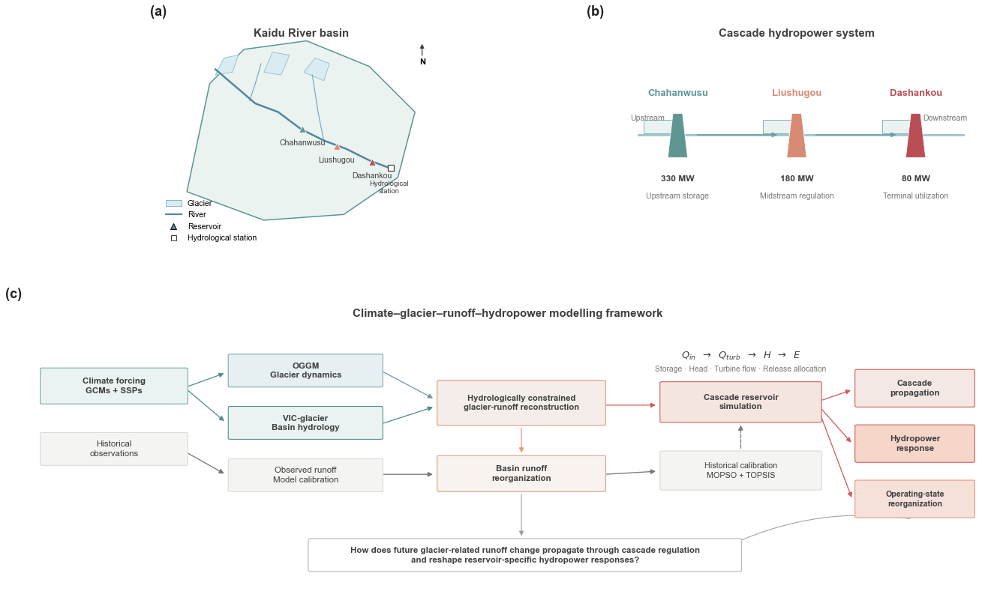

In [32]:
# -*- coding: utf-8 -*-
"""
Fig. 1
Study area, cascade hydropower system, and modelling framework

Panels
------
(a) Study area, river network, glacier distribution, and stations
(b) Cascade reservoir configuration and key characteristics
(c) Climate–glacier–runoff–cascade hydropower modelling framework

NOTE
----
Panel (a) is currently a schematic spatial template because real GIS
shapefiles / coordinates are not yet specified. Replace the example
coordinates with actual Kaidu River basin GIS data when available.
"""

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.patches import (
    FancyBboxPatch,
    FancyArrowPatch,
    Rectangle,
    Polygon,
    Circle,
)

from matplotlib.lines import Line2D


# ======================================================================
# 1. OUTPUT
# ======================================================================

OUTPUT_DIR = Path(
    r"D:\博士论文\小论文3\图片"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ======================================================================
# 2. GLOBAL STYLE
# ======================================================================

WHITE = "#FFFFFF"

DARK_GRAY = "#3F3F3F"
MID_GRAY = "#777777"
LIGHT_GRAY = "#D9D9D9"

SEA_SALT = "#78AAA5"
SEA_SALT_DARK = "#4E8F8B"
SEA_SALT_LIGHT = "#EAF3F1"

CORAL = "#E59A78"
CORAL_DARK = "#CF5C5C"
CORAL_LIGHT = "#F5D6C8"

BLUE_GRAY = "#7895A8"

RES_COLORS = {
    "Chahanwusu": "#5F9692",
    "Liushugou": "#D78B73",
    "Dashankou": "#B94F55",
}

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 14.5,

    "axes.labelsize": 15,
    "axes.titlesize": 15.5,

    "xtick.labelsize": 12.5,
    "ytick.labelsize": 12.5,

    "legend.fontsize": 11.5,

    "axes.linewidth": 1.0,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "xtick.direction": "out",
    "ytick.direction": "out",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    "axes.unicode_minus": False,

    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
})


# ======================================================================
# 3. COMMON UTILITIES
# ======================================================================

def panel_label(ax, label, x=-0.06, y=1.04):
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        ha="left",
        va="bottom",
        color="#202020"
    )


def rounded_box(
    ax,
    xy,
    width,
    height,
    text,
    facecolor=WHITE,
    edgecolor=LIGHT_GRAY,
    textcolor=DARK_GRAY,
    fontsize=11.5,
    linewidth=1.1,
    radius=0.03,
    fontweight="normal",
    zorder=3,
):
    """
    Draw rounded rectangle + centered text.
    """

    x, y = xy

    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle=f"round,pad=0.01,rounding_size={radius}",
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=zorder
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        color=textcolor,
        fontweight=fontweight,
        zorder=zorder + 1,
        linespacing=1.3
    )

    return box


def arrow(
    ax,
    start,
    end,
    color=MID_GRAY,
    linewidth=1.3,
    mutation_scale=13,
    linestyle="-",
    connectionstyle="arc3",
    zorder=2,
):
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle="-|>",
            mutation_scale=mutation_scale,
            linewidth=linewidth,
            color=color,
            linestyle=linestyle,
            connectionstyle=connectionstyle,
            shrinkA=2,
            shrinkB=2,
            zorder=zorder
        )
    )


# ======================================================================
# 4. PANEL A
# Study area
# ======================================================================

def plot_panel_a(ax):
    """
    Schematic study-area panel.

    Replace the example polygon / river / glaciers / stations with
    actual GIS layers when shapefiles become available.
    """

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 8)

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    # ------------------------------------------------------------------
    # Example basin boundary
    # ------------------------------------------------------------------

    basin = np.array([
        [1.0, 2.0],
        [1.8, 5.8],
        [3.0, 7.0],
        [5.2, 7.3],
        [7.4, 6.4],
        [9.0, 4.8],
        [8.4, 2.5],
        [6.5, 1.2],
        [3.7, 1.0],
    ])

    ax.add_patch(
        Polygon(
            basin,
            closed=True,
            facecolor=SEA_SALT_LIGHT,
            edgecolor=SEA_SALT_DARK,
            linewidth=1.5,
            alpha=0.95,
            zorder=1
        )
    )

    # ------------------------------------------------------------------
    # Example main river
    # ------------------------------------------------------------------

    river_x = np.array([
        2.0,
        2.7,
        3.4,
        4.2,
        5.0,
        5.8,
        6.6,
        7.4,
        8.2,
    ])

    river_y = np.array([
        6.3,
        5.7,
        5.1,
        4.8,
        4.2,
        3.8,
        3.5,
        3.1,
        2.8,
    ])

    ax.plot(
        river_x,
        river_y,
        color="#5287A0",
        lw=2.5,
        zorder=4
    )

    # tributaries
    ax.plot(
        [3.6, 3.4, 3.2],
        [6.5, 5.8, 5.2],
        color="#78A9BD",
        lw=1.2,
        zorder=3
    )

    ax.plot(
        [5.4, 5.6, 5.8],
        [6.1, 4.8, 3.8],
        color="#78A9BD",
        lw=1.2,
        zorder=3
    )

    # ------------------------------------------------------------------
    # Example glacier polygons
    # ------------------------------------------------------------------

    glacier_xy = [
        np.array([
            [2.0, 6.1],
            [2.3, 6.7],
            [2.8, 6.8],
            [2.6, 6.2],
        ]),
        np.array([
            [3.7, 6.2],
            [4.0, 6.9],
            [4.6, 6.8],
            [4.3, 6.1],
        ]),
        np.array([
            [5.1, 6.2],
            [5.5, 6.7],
            [6.0, 6.5],
            [5.8, 5.9],
        ]),
    ]

    for gl in glacier_xy:
        ax.add_patch(
            Polygon(
                gl,
                closed=True,
                facecolor="#D8ECF2",
                edgecolor="#88B9C8",
                linewidth=0.8,
                zorder=2
            )
        )

    # ------------------------------------------------------------------
    # Reservoir locations
    # ------------------------------------------------------------------

    station_positions = {
        "Chahanwusu": (5.05, 4.2),
        "Liushugou":  (6.25, 3.6),
        "Dashankou":  (7.50, 3.05),
    }

    for name, (x, y) in station_positions.items():

        ax.scatter(
            x,
            y,
            s=90,
            marker="^",
            color=RES_COLORS[name],
            edgecolor=WHITE,
            linewidth=0.8,
            zorder=7
        )

        ax.text(
            x,
            y - 0.35,
            name,
            ha="center",
            va="top",
            fontsize=10.5,
            color=DARK_GRAY,
            zorder=8
        )

    # ------------------------------------------------------------------
    # Hydrological station
    # ------------------------------------------------------------------

    ax.scatter(
        8.15,
        2.85,
        s=55,
        marker="s",
        facecolor=WHITE,
        edgecolor=DARK_GRAY,
        linewidth=1.2,
        zorder=7
    )

    ax.text(
        8.10,
        2.40,
        "Hydrological\nstation",
        ha="center",
        va="top",
        fontsize=9.5,
        color=DARK_GRAY
    )

    # ------------------------------------------------------------------
    # Labels
    # ------------------------------------------------------------------

    ax.text(
        5.0,
        7.55,
        "Kaidu River basin",
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold",
        color=DARK_GRAY
    )

    # ------------------------------------------------------------------
    # North arrow
    # ------------------------------------------------------------------

    ax.annotate(
        "N",
        xy=(9.25, 7.25),
        xytext=(9.25, 6.55),
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>",
            lw=1.3,
            color=DARK_GRAY
        )
    )

    # ------------------------------------------------------------------
    # Legend
    # ------------------------------------------------------------------

    handles = [
        Patch(
            facecolor="#D8ECF2",
            edgecolor="#88B9C8",
            label="Glacier"
        ),
        Line2D(
            [0],
            [0],
            color="#5287A0",
            lw=2.2,
            label="River"
        ),
        Line2D(
            [0],
            [0],
            marker="^",
            color="none",
            markerfacecolor=SEA_SALT_DARK,
            markersize=8,
            label="Reservoir"
        ),
        Line2D(
            [0],
            [0],
            marker="s",
            color="none",
            markerfacecolor=WHITE,
            markeredgecolor=DARK_GRAY,
            markersize=7,
            label="Hydrological station"
        ),
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        loc="lower left",
        fontsize=10.5
    )

    ax.axis(
        "off"
    )

    panel_label(
        ax,
        "(a)",
        x=-0.03,
        y=1.01
    )


# ======================================================================
# 5. PANEL B
# Cascade hydropower system
# ======================================================================

def plot_panel_b(ax):

    ax.set_xlim(
        0,
        10
    )

    ax.set_ylim(
        0,
        8
    )

    ax.axis(
        "off"
    )

    ax.text(
        5,
        7.55,
        "Cascade hydropower system",
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold",
        color=DARK_GRAY
    )

    # ------------------------------------------------------------------
    # Flowing river backbone
    # ------------------------------------------------------------------

    ax.plot(
        [1.0, 9.2],
        [4.0, 4.0],
        color="#8BBAC5",
        lw=3.0,
        alpha=0.8,
        zorder=1
    )

    # ------------------------------------------------------------------
    # Reservoir nodes
    # ------------------------------------------------------------------

    reservoir_data = [
        {
            "name": "Chahanwusu",
            "x": 2.0,
            "capacity": "330 MW",
            "role": "Upstream storage",
            "color": RES_COLORS["Chahanwusu"],
        },
        {
            "name": "Liushugou",
            "x": 5.0,
            "capacity": "180 MW",
            "role": "Midstream regulation",
            "color": RES_COLORS["Liushugou"],
        },
        {
            "name": "Dashankou",
            "x": 8.0,
            "capacity": "80 MW",
            "role": "Terminal utilization",
            "color": RES_COLORS["Dashankou"],
        },
    ]

    for item in reservoir_data:

        x = item["x"]

        # dam
        ax.add_patch(
            Polygon(
                [
                    [x - 0.25, 3.2],
                    [x + 0.25, 3.2],
                    [x + 0.12, 4.75],
                    [x - 0.12, 4.75],
                ],
                closed=True,
                facecolor=item["color"],
                edgecolor=WHITE,
                linewidth=0.8,
                zorder=5
            )
        )

        # reservoir upstream
        ax.add_patch(
            Rectangle(
                (x - 0.85, 4.05),
                0.8,
                0.48,
                facecolor=SEA_SALT_LIGHT,
                edgecolor="#7FAEAF",
                linewidth=0.9,
                zorder=2
            )
        )

        ax.text(
            x,
            5.45,
            item["name"],
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color=item["color"]
        )

        ax.text(
            x,
            2.45,
            item["capacity"],
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color=DARK_GRAY
        )

        ax.text(
            x,
            1.85,
            item["role"],
            ha="center",
            va="center",
            fontsize=10.5,
            color=MID_GRAY
        )

    # ------------------------------------------------------------------
    # Direction arrows
    # ------------------------------------------------------------------

    arrow(
        ax,
        (2.45, 4.0),
        (4.55, 4.0),
        color="#6E9DAA",
        linewidth=1.5
    )

    arrow(
        ax,
        (5.45, 4.0),
        (7.55, 4.0),
        color="#6E9DAA",
        linewidth=1.5
    )

    # ------------------------------------------------------------------
    # Upstream / downstream labels
    # ------------------------------------------------------------------

    ax.text(
        0.8,
        4.45,
        "Upstream",
        ha="left",
        va="bottom",
        fontsize=10.5,
        color=MID_GRAY
    )

    ax.text(
        9.3,
        4.45,
        "Downstream",
        ha="right",
        va="bottom",
        fontsize=10.5,
        color=MID_GRAY
    )

    panel_label(
        ax,
        "(b)",
        x=-0.03,
        y=1.01
    )


# ======================================================================
# 6. PANEL C
# Modelling framework
# ======================================================================

def plot_panel_c(ax):

    ax.set_xlim(
        0,
        14
    )

    ax.set_ylim(
        0,
        10
    )

    ax.axis(
        "off"
    )

    ax.text(
        7,
        9.62,
        "Climate–glacier–runoff–hydropower modelling framework",
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold",
        color=DARK_GRAY
    )

    # ==================================================================
    # COLUMN 1
    # Climate forcing
    # ==================================================================

    rounded_box(
        ax,
        (0.3, 6.7),
        2.1,
        1.15,
        "Climate forcing\nGCMs + SSPs",
        facecolor=SEA_SALT_LIGHT,
        edgecolor=SEA_SALT,
        fontweight="bold"
    )

    rounded_box(
        ax,
        (0.3, 4.7),
        2.1,
        1.05,
        "Historical\nobservations",
        facecolor="#F4F4F2",
        edgecolor=LIGHT_GRAY
    )

    # ==================================================================
    # COLUMN 2
    # VIC + OGGM
    # ==================================================================

    rounded_box(
        ax,
        (3.0, 7.25),
        2.2,
        1.05,
        "OGGM\nGlacier dynamics",
        facecolor="#E6F0F3",
        edgecolor="#7DA7B5",
        fontweight="bold"
    )

    rounded_box(
        ax,
        (3.0, 5.55),
        2.2,
        1.05,
        "VIC-glacier\nBasin hydrology",
        facecolor=SEA_SALT_LIGHT,
        edgecolor=SEA_SALT_DARK,
        fontweight="bold"
    )

    rounded_box(
        ax,
        (3.0, 3.85),
        2.2,
        1.05,
        "Observed runoff\nModel calibration",
        facecolor="#F4F4F2",
        edgecolor=LIGHT_GRAY
    )

    # ==================================================================
    # COLUMN 3
    # Reconstruction
    # ==================================================================

    rounded_box(
        ax,
        (6.0, 6.0),
        2.4,
        1.45,
        "Hydrologically constrained\n"
        "glacier-runoff reconstruction",
        facecolor="#F4EDEA",
        edgecolor=CORAL,
        fontsize=11.2,
        fontweight="bold"
    )

    rounded_box(
        ax,
        (6.0, 3.85),
        2.4,
        1.15,
        "Basin runoff\nreorganization",
        facecolor="#F8F3EF",
        edgecolor="#D4A08A",
        fontweight="bold"
    )

    # ==================================================================
    # COLUMN 4
    # Reservoir simulation
    # ==================================================================

    rounded_box(
        ax,
        (9.2, 6.1),
        2.3,
        1.3,
        "Cascade reservoir\nsimulation",
        facecolor="#F5E5DF",
        edgecolor=CORAL_DARK,
        fontweight="bold"
    )

    rounded_box(
        ax,
        (9.2, 3.9),
        2.3,
        1.25,
        "Historical calibration\nMOPSO + TOPSIS",
        facecolor="#F4F4F2",
        edgecolor=LIGHT_GRAY,
        fontsize=10.8
    )

    # ==================================================================
    # COLUMN 5
    # Diagnostics / outputs
    # ==================================================================

    rounded_box(
        ax,
        (12.0, 6.6),
        1.7,
        1.2,
        "Cascade\npropagation",
        facecolor="#F4E8E4",
        edgecolor=CORAL_DARK,
        fontweight="bold"
    )

    rounded_box(
        ax,
        (12.0, 4.8),
        1.7,
        1.2,
        "Hydropower\nresponse",
        facecolor=CORAL_LIGHT,
        edgecolor=CORAL_DARK,
        fontweight="bold"
    )

    rounded_box(
        ax,
        (12.0, 3.0),
        1.7,
        1.2,
        "Operating-state\nreorganization",
        facecolor="#F6E0DA",
        edgecolor=CORAL,
        fontsize=10.6,
        fontweight="bold"
    )

    # ==================================================================
    # Main pathway arrows
    # ==================================================================

    arrow(
        ax,
        (2.4, 7.25),
        (2.95, 7.70),
        color=SEA_SALT_DARK
    )

    arrow(
        ax,
        (2.4, 7.15),
        (2.95, 6.10),
        color=SEA_SALT_DARK
    )

    arrow(
        ax,
        (2.4, 5.10),
        (2.95, 4.40),
        color=MID_GRAY
    )

    arrow(
        ax,
        (5.2, 7.75),
        (5.95, 6.85),
        color=BLUE_GRAY
    )

    arrow(
        ax,
        (5.2, 6.05),
        (5.95, 6.60),
        color=SEA_SALT_DARK
    )

    arrow(
        ax,
        (5.2, 4.40),
        (5.95, 4.40),
        color=MID_GRAY
    )

    arrow(
        ax,
        (7.2, 5.95),
        (7.2, 5.05),
        color=CORAL
    )

    arrow(
        ax,
        (8.4, 6.65),
        (9.15, 6.65),
        color=CORAL_DARK
    )

    arrow(
        ax,
        (8.4, 4.40),
        (9.15, 4.50),
        color=MID_GRAY
    )

    arrow(
        ax,
        (10.35, 5.20),
        (10.35, 6.05),
        color=MID_GRAY,
        linestyle="--"
    )

    arrow(
        ax,
        (11.5, 6.80),
        (11.95, 7.15),
        color=CORAL_DARK
    )

    arrow(
        ax,
        (11.5, 6.55),
        (11.95, 5.40),
        color=CORAL_DARK
    )

    arrow(
        ax,
        (11.5, 6.30),
        (11.95, 3.60),
        color=CORAL_DARK
    )

    # ==================================================================
    # Diagnostic variables
    # ==================================================================

    ax.text(
        10.35,
        8.25,
        r"$Q_{in}$  $\rightarrow$  $Q_{turb}$  $\rightarrow$  $H$  $\rightarrow$  $E$",
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        color=DARK_GRAY
    )

    ax.text(
        10.35,
        7.82,
        "Storage · Head · Turbine flow · Release allocation",
        ha="center",
        va="center",
        fontsize=10.3,
        color=MID_GRAY
    )

    # ==================================================================
    # Bottom scientific question
    # ==================================================================

    rounded_box(
        ax,
        (4.15, 1.25),
        6.2,
        1.05,
        "How does future glacier-related runoff change propagate through "
        "cascade regulation\nand reshape reservoir-specific hydropower responses?",
        facecolor=WHITE,
        edgecolor="#B9B9B9",
        fontsize=11.5,
        fontweight="bold",
        linewidth=1.2
    )

    # arrows into scientific question
    arrow(
        ax,
        (7.2, 3.80),
        (7.2, 2.35),
        color="#999999",
        linewidth=1.0
    )

    arrow(
        ax,
        (12.8, 2.95),
        (10.2, 2.10),
        color="#999999",
        linewidth=1.0,
        connectionstyle="arc3,rad=0.15"
    )

    panel_label(
        ax,
        "(c)",
        x=-0.015,
        y=1.005
    )


# ======================================================================
# 7. DRAW FIGURE
# ======================================================================

def draw_figure():

    fig = plt.figure(
        figsize=(19.0, 11.8),
        facecolor=WHITE
    )

    outer = fig.add_gridspec(
        nrows=2,
        ncols=12,
        height_ratios=[1.0, 1.35],
        hspace=0.20,
        wspace=0.25
    )

    # ------------------------------------------------------------------
    # Top row
    # ------------------------------------------------------------------

    ax_a = fig.add_subplot(
        outer[0, 0:7]
    )

    ax_b = fig.add_subplot(
        outer[0, 7:12]
    )

    # ------------------------------------------------------------------
    # Bottom row
    # ------------------------------------------------------------------

    ax_c = fig.add_subplot(
        outer[1, 0:12]
    )

    plot_panel_a(
        ax_a
    )

    plot_panel_b(
        ax_b
    )

    plot_panel_c(
        ax_c
    )

    fig.subplots_adjust(
        left=0.035,
        right=0.985,
        top=0.965,
        bottom=0.04
    )

    # ==================================================================
    # SAVE
    # ==================================================================

    out_png = (
        OUTPUT_DIR /
        "Fig1_study_area_cascade_framework.png"
    )

    out_pdf = (
        OUTPUT_DIR /
        "Fig1_study_area_cascade_framework.pdf"
    )

    out_svg = (
        OUTPUT_DIR /
        "Fig1_study_area_cascade_framework.svg"
    )

    fig.savefig(
        out_png,
        dpi=600,
        bbox_inches="tight",
        facecolor=WHITE
    )

    fig.savefig(
        out_pdf,
        bbox_inches="tight",
        facecolor=WHITE
    )

    fig.savefig(
        out_svg,
        bbox_inches="tight",
        facecolor=WHITE
    )

    print("=" * 80)
    print("Fig. 1 saved successfully:")
    print(out_png)
    print(out_pdf)
    print(out_svg)
    print("=" * 80)

    plt.show()


# ======================================================================
# 8. MAIN
# ======================================================================

if __name__ == "__main__":

    print("=" * 80)
    print(
        "Fig. 1 | Study area, cascade hydropower system, "
        "and modelling framework"
    )
    print("=" * 80)

    draw_figure()

Fig. 1 | Study area, cascade hydropower system, and modelling framework
[DEM] size=433x163, scale=1.00, CRS=EPSG:4326, pixel=0.0071, NaN frac=42.5%
[LAYER] river    n=1  cols=['OBJECTID_1', 'arcid', 'grid_code', 'from_node', 'to_node', 'Shape_Leng', 'geometry']
[LAYER] glacier  n=650  cols=['OBJECTID', 'RGIId', 'GLIMSId', 'BgnDate', 'EndDate', 'CenLon', 'CenLat', 'O1Region', 'O2Region', 'Area', 'Zmin', 'Zmax', 'Zmed', 'Slope', 'Aspect', 'Lmax', 'Status', 'Connect', 'Form', 'TermType', 'Surging', 'Linkages', 'Name', 'Shape_Leng', 'Shape_Area', 'geometry']
[LAYER] dam      n=7  cols=['Id', 'name', 'en', 'geometry']
[DAM] scanning dam shapefile:
  [KEEP] Chahanwusu  en='Chahanwusu'  xy=(85.5253,42.3285)
  [KEEP] Liushugou   en='Liushugou'  xy=(85.6195,42.2785)
  [SKIP] name='é\x9c\x8då°\x94å\x8f¤å\x90\x90æ°´ç\x94µç«\x99ï¼\x88å\x9c¨å»ºï¼\x89'
  [SKIP] name='é\x98¿ä»\x81è\x90¨å¾\x88æ\x89\x98äº¥æ°´ç\x94µç«\x99ï¼\x88å¾\x85å»ºï¼\x89'
  [SKIP] name='å\x93\x88å°\x94å\x98\x8eå»·é\x83\xadå\x8b\x92

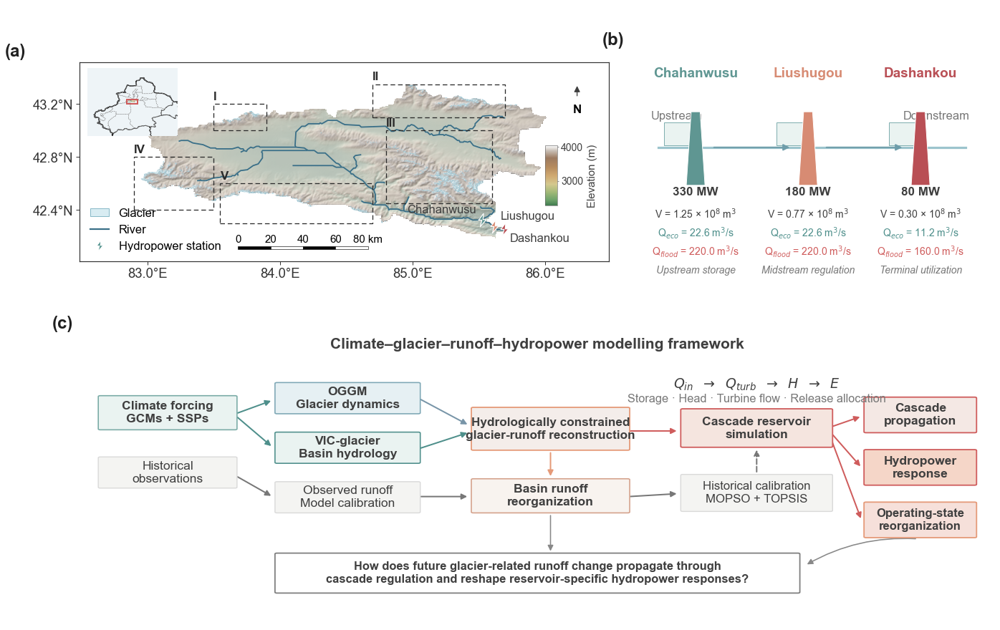

In [67]:
# -*- coding: utf-8 -*-
"""
Fig. 1 (v10)
- First row (Panel a, b) enlarged; tighter vertical gap to Panel c
- Panel b: title moved up, ylim compacted (no large blank under title)
- Panel b: added V, A, Q_eco, Q_flood per reservoir
- Panel c: scientific-question box enlarged; all borders and arrows bolded
- Panel a: I–V dashed sub-regions; vertical elevation colorbar; inset locator
"""

import copy as _copy
from pathlib import Path
import warnings

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import (
    FancyBboxPatch, FancyArrowPatch, Rectangle, Polygon, Patch,
)
from matplotlib.lines import Line2D
from matplotlib.colors import LightSource, LinearSegmentedColormap
from matplotlib.path import Path as MplPath
from matplotlib.ticker import MultipleLocator, FuncFormatter

warnings.filterwarnings("ignore")

try:
    import rasterio
    from pyproj import CRS, Transformer
    import geopandas as gpd
    _GIS_OK = True
    _GIS_ERR = ""
except ImportError as e:
    _GIS_OK = False
    _GIS_ERR = str(e)


# ======================================================================
# 1. PATHS
# ======================================================================

OUTPUT_DIR = Path(r"D:\博士论文\小论文3\图片")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEM_TIF     = Path(r"D:\Python code\article1\LIUYUTU\DEM2.tif")
RIVER_SHP   = Path(r"D:\Python code\article1\MyProject1(1)\ERJIHEDAO.shp")
GLACIER_SHP = Path(r"D:\Python code\article1\LIUYUTU\bingchuan.shp")
DAM_SHP     = Path(r"D:\Python code\article1\MyProject1(1)\DASAHNKOU.shp")

INSET_PROVINCE_SHP = Path(r"D:\oggm\流域划分\研究区\中国标准地图\中国标准地图\省级行政区.shp")
INSET_PREFECT_SHP  = Path(r"D:\Python code\article1\LIUYUTU\MyProject1\中国地州界_ExportFeatures1.shp")
INSET_COUNTRY_SHP  = Path(r"D:\oggm\流域划分\研究区\中国标准地图\中国标准地图\国界线.shp")


# ======================================================================
# 2. GLOBAL STYLE
# ======================================================================

WHITE = "#FFFFFF"
DARK_GRAY = "#3F3F3F"
MID_GRAY = "#777777"
LIGHT_GRAY = "#D9D9D9"

SEA_SALT = "#78AAA5"
SEA_SALT_DARK = "#4E8F8B"
SEA_SALT_LIGHT = "#EAF3F1"

CORAL = "#E59A78"
CORAL_DARK = "#CF5C5C"
CORAL_LIGHT = "#F5D6C8"

BLUE_GRAY = "#7895A8"

RES_COLORS = {
    "Chahanwusu": "#5F9692",
    "Liushugou": "#D78B73",
    "Dashankou": "#B94F55",
}

RES_LABELS = {
    "Chahanwusu": "Chahanwusu",
    "Liushugou": "Liushugou",
    "Dashankou": "Dashankou",
}

# ----------------------------------------------------------------------
# ⚠⚠ ALL NUMBERS BELOW ARE PLACEHOLDERS — REPLACE BEFORE PUBLICATION ⚠⚠
# ----------------------------------------------------------------------
RES_ATTRS = {
    "Chahanwusu": {
        "storage_e8m3":        1.25,
        "eco_min_m3s":        22.57,
        "flood_threshold_m3s": 220.0,
    },
    "Liushugou": {
        "storage_e8m3":        0.771,
        "eco_min_m3s":        22.57,
        "flood_threshold_m3s": 220.0,
    },
    "Dashankou": {
        "storage_e8m3":        0.298,
        "eco_min_m3s":         11.2,
        "flood_threshold_m3s": 160.0,
    },
}

MANUAL_COORDS = {}

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 20.5,
    "axes.labelsize": 21,
    "axes.titlesize": 21.5,
    "xtick.labelsize": 18.5,
    "ytick.labelsize": 18.5,
    "legend.fontsize": 17.5,
    "axes.linewidth": 1.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.unicode_minus": False,
    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
})


# ======================================================================
# 2b. ARID-CLIMATE COLORMAP
# ======================================================================

ARID_TERRAIN = LinearSegmentedColormap.from_list(
    "arid_terrain",
    [
        (0.00, "#3F7A4E"),
        (0.10, "#6FA36B"),
        (0.22, "#9FB877"),
        (0.36, "#D4C88E"),
        (0.50, "#D0A971"),
        (0.65, "#B58B5E"),
        (0.80, "#9C7A60"),
        (0.92, "#C8BEB4"),
        (1.00, "#F5F5F5"),
    ],
    N=256,
)
ARID_TERRAIN.set_bad(alpha=0.0)


# ======================================================================
# 2c. LIGHTNING MARKER + REGION COORDS
# ======================================================================

_LIGHTNING_VERTS = [
    ( 0.10,  0.60),
    (-0.35,  0.00),
    (-0.05,  0.00),
    (-0.20, -0.60),
    ( 0.35,  0.05),
    ( 0.05,  0.05),
    ( 0.10,  0.60),
]
_LIGHTNING_CODES = [MplPath.MOVETO] + [MplPath.LINETO] * 5 + [MplPath.CLOSEPOLY]
LIGHTNING_PATH = MplPath(_LIGHTNING_VERTS, _LIGHTNING_CODES)

LABEL_OFFSETS = {
    "Chahanwusu": (-8,  6, "right", "bottom"),
    "Liushugou":  ( 8,  6, "left",  "bottom"),
    "Dashankou":  ( 8, -6, "left",  "top"),
}

PAD_FRAC = 0.15

ROMAN_REGIONS = [
    ("I",   83.5,  83.9,  43.0,  43.2),
    ("II",  84.7,  85.7,  43.1,  43.35),
    ("III", 84.8,  85.6,  42.45, 43.0),
    ("IV",  82.9,  83.5,  42.4,  42.8),
    ("V",   83.55, 84.7,  42.3,  42.6),
]


# ======================================================================
# 3. COMMON UTILITIES
# ======================================================================

def panel_label(ax, label, x=-0.10, y=1.02):
    ax.text(x, y, label, transform=ax.transAxes, fontsize=24,
            fontweight="bold", ha="left", va="bottom", color="#202020")


def rounded_box(ax, xy, width, height, text, facecolor=WHITE,
                edgecolor=LIGHT_GRAY, textcolor=DARK_GRAY, fontsize=17.5,
                linewidth=1.5, radius=0.03, fontweight="normal", zorder=3):
    x, y = xy
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle=f"round,pad=0.01,rounding_size={radius}",
        facecolor=facecolor, edgecolor=edgecolor,
        linewidth=linewidth, zorder=zorder,
    )
    ax.add_patch(box)
    ax.text(x + width / 2, y + height / 2, text,
            ha="center", va="center", fontsize=fontsize,
            color=textcolor, fontweight=fontweight,
            zorder=zorder + 1, linespacing=1.25)
    return box


def arrow(ax, start, end, color=MID_GRAY, linewidth=2.0,
          mutation_scale=16, linestyle="-",
          connectionstyle="arc3", zorder=2):
    ax.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=linewidth, color=color,
        linestyle=linestyle, connectionstyle=connectionstyle,
        shrinkA=2, shrinkB=2, zorder=zorder,
    ))


# ======================================================================
# 4. GIS HELPERS
# ======================================================================

def safe_read_gdf(path):
    if not _GIS_OK:
        return None
    if not path.exists():
        print(f"[WARN] Shapefile not found: {path}")
        return gpd.GeoDataFrame()
    for enc in (None, "utf-8", "gbk"):
        try:
            return gpd.read_file(path, encoding=enc) if enc else gpd.read_file(path)
        except Exception:
            continue
    print(f"[WARN] Failed to read {path}")
    return gpd.GeoDataFrame()


def to_wgs84(gdf):
    if gdf is None or len(gdf) == 0:
        return gdf
    try:
        if gdf.crs is None:
            gdf = gdf.set_crs(4326, allow_override=True)
        return gdf.to_crs(4326)
    except Exception as e:
        print(f"[WARN] CRS→WGS84 conversion failed: {e}")
        return gdf


def load_dem(tif_path, max_size=2000):
    if not tif_path.exists():
        raise FileNotFoundError(f"DEM not found: {tif_path}")
    with rasterio.open(tif_path) as src:
        h, w = src.height, src.width
        scale = max(h, w) / max_size if max(h, w) > max_size else 1.0
        if scale > 1:
            out_shape = (int(h / scale), int(w / scale))
            dem = src.read(1, out_shape=out_shape).astype(float)
        else:
            dem = src.read(1).astype(float)

        nodata = src.nodata
        if nodata is not None:
            dem[dem == nodata] = np.nan
        else:
            dem[dem <= -9999] = np.nan
            dem[dem >= 99999] = np.nan

        extent = (src.bounds.left, src.bounds.right,
                  src.bounds.bottom, src.bounds.top)
        crs = CRS.from_wkt(src.crs.to_wkt())

        dx = abs(src.transform.a) * scale
        dy = abs(src.transform.e) * scale

        nan_frac = float(np.sum(~np.isfinite(dem)) / dem.size) if dem.size else 0.0
        print(f"[DEM] size={w}x{h}, scale={scale:.2f}, "
              f"CRS={crs.to_string()[:60]}, pixel={dx:.4f}, "
              f"NaN frac={nan_frac*100:.1f}%")
    return dem, extent, crs, dx, dy


def compute_hillshade(dem, dx, dy, extent, azdeg=315, altdeg=45):
    ls = LightSource(azdeg=azdeg, altdeg=altdeg)
    fill = np.nanmedian(dem)
    filled = np.where(np.isfinite(dem), dem, fill)

    if dx < 0.01:
        lat_c = (extent[2] + extent[3]) / 2.0
        m_per_deg = 111000.0 * np.cos(np.deg2rad(lat_c))
        vert_exag = 1.0 / m_per_deg
    else:
        vert_exag = 1.0

    hs = ls.hillshade(filled, vert_exag=vert_exag, dx=dx, dy=dy)
    hs = np.where(np.isfinite(dem), hs, np.nan)
    return hs


def load_map_layers(dem_crs):
    layers = {}
    for key, shp in (("river", RIVER_SHP),
                     ("glacier", GLACIER_SHP),
                     ("dam", DAM_SHP)):
        gdf = safe_read_gdf(shp)
        if gdf is not None and len(gdf):
            try:
                layers[key] = gdf.to_crs(dem_crs) if gdf.crs else \
                    gdf.set_crs(dem_crs, allow_override=True)
                print(f"[LAYER] {key:<8s} n={len(layers[key])}  "
                      f"cols={list(layers[key].columns)}")
            except Exception as e:
                print(f"[WARN] Could not reproject {key}: {e}")
    return layers


def find_name(row):
    for field in ["en", "EN", "En",
                  "Name", "NAME", "name",
                  "NAME_CN", "Name_CN", "名称中文", "名称",
                  "STATION", "Station", "station"]:
        if field in row.index:
            v = row[field]
            if v is not None and str(v).strip() and str(v).strip().lower() != "nan":
                return str(v)
    return None


def classify_reservoir(name_str):
    if not name_str:
        return None
    s = str(name_str).lower().replace(" ", "")
    if "chahan" in s or "察汗" in s or "chws" in s:
        return "Chahanwusu"
    if "liushu" in s or "柳树" in s or "lsg" in s:
        return "Liushugou"
    if "dashan" in s or "大山" in s or "dsk" in s:
        return "Dashankou"
    return None


def load_all_map_data():
    if not _GIS_OK:
        raise ImportError(
            "rasterio / geopandas / pyproj are required for panel (a).\n"
            f"Import error: {_GIS_ERR}"
        )
    dem, extent, crs, dx, dy = load_dem(DEM_TIF)
    layers = load_map_layers(crs)
    return {"dem": dem, "extent": extent, "crs": crs,
            "dx": dx, "dy": dy, "layers": layers}


# ======================================================================
# 5. SCALE BAR
# ======================================================================

def _is_geographic(crs):
    try:
        return CRS.from_user_input(crs).is_geographic
    except Exception:
        return True


def _auto_scale_bar_length_km(extent, crs, target_frac=0.22, n_seg=4):
    if _is_geographic(crs):
        lat_c = (extent[2] + extent[3]) / 2.0
        km_per_deg = 111.32 * np.cos(np.deg2rad(lat_c))
        width_km = abs(extent[1] - extent[0]) * km_per_deg
    else:
        width_km = abs(extent[1] - extent[0]) / 1000.0

    target_km = width_km * target_frac
    seg_candidates = [1, 2, 5, 10, 15, 20, 25, 50, 100, 200, 500, 1000]
    for seg in seg_candidates:
        if seg * n_seg >= target_km:
            return seg * n_seg
    return seg_candidates[-1] * n_seg


def add_scale_bar(ax, extent, crs, length_km=None, n_seg=4,
                  location=(0.30, 0.06), zorder=25):
    if length_km is None:
        length_km = _auto_scale_bar_length_km(extent, crs, n_seg=n_seg)

    geographic = _is_geographic(crs)
    if geographic:
        lat_c = (extent[2] + extent[3]) / 2.0
        km_per_deg = 111.32 * np.cos(np.deg2rad(lat_c))
        length_data = length_km / km_per_deg
    else:
        length_data = length_km * 1000.0

    x0 = extent[0] + (extent[1] - extent[0]) * location[0]
    y0 = extent[2] + (extent[3] - extent[2]) * location[1]
    bar_h = (extent[3] - extent[2]) * 0.016
    seg_w = length_data / n_seg
    seg_km = length_km / n_seg

    for i in range(n_seg):
        face = "black" if i % 2 == 0 else "white"
        ax.add_patch(Rectangle(
            (x0 + i * seg_w, y0), seg_w, bar_h,
            facecolor=face, edgecolor="black",
            linewidth=0.6, zorder=zorder,
        ))

    for i in range(n_seg + 1):
        x_tick = x0 + i * seg_w
        val = seg_km * i
        if i == 0:
            txt = "0"
        elif i == n_seg:
            txt = f"{int(length_km)} km"
        else:
            txt = f"{int(val)}"
        ax.text(x_tick, y0 + bar_h + bar_h * 0.35, txt,
                ha="center", va="bottom", fontsize=15, color="black",
                zorder=zorder + 1)


# ======================================================================
# 6. PANEL A
# ======================================================================

def add_inset_map(ax, extent, dem_crs, dem=None):
    try:
        if _is_geographic(dem_crs):
            lon_min, lon_max = extent[0], extent[1]
            lat_min, lat_max = extent[2], extent[3]
            extent_wgs84 = extent
        else:
            tr = Transformer.from_crs(dem_crs, "EPSG:4326", always_xy=True)
            xs = [extent[0], extent[1], extent[0], extent[1]]
            ys = [extent[2], extent[2], extent[3], extent[3]]
            lons, lats = tr.transform(xs, ys)
            lon_min, lon_max = float(np.min(lons)), float(np.max(lons))
            lat_min, lat_max = float(np.min(lats)), float(np.max(lats))
            extent_wgs84 = (lon_min, lon_max, lat_min, lat_max)
    except Exception as e:
        print(f"[WARN] Cannot convert extent to WGS84: {e}")
        return

    country  = to_wgs84(safe_read_gdf(INSET_COUNTRY_SHP))
    province = to_wgs84(safe_read_gdf(INSET_PROVINCE_SHP))
    prefect  = to_wgs84(safe_read_gdf(INSET_PREFECT_SHP))

    inset_ax = ax.inset_axes([-0.06, 0.63, 0.32, 0.34])
    inset_ax.set_facecolor("#EEF4F7")

    for spine in inset_ax.spines.values():
        spine.set_visible(False)

    if dem is not None and _is_geographic(dem_crs):
        cmap_dem = _copy.copy(ARID_TERRAIN)
        cmap_dem.set_bad(alpha=0.0)
        d = dem[np.isfinite(dem)]
        if d.size:
            vmin = float(np.percentile(d, 2))
            vmax = float(np.percentile(d, 98))
            inset_ax.imshow(dem, extent=extent_wgs84, origin="upper",
                            cmap=cmap_dem, vmin=vmin, vmax=vmax,
                            alpha=0.60, zorder=0, interpolation="bilinear")

    if country is not None and len(country):
        country.plot(ax=inset_ax, facecolor="none",
                     edgecolor="#1A1A1A", linewidth=1.30, zorder=2)
    if province is not None and len(province):
        province.plot(ax=inset_ax, facecolor="none",
                      edgecolor="#4A4A4A", linewidth=0.95,
                      linestyle=(0, (6, 3)), zorder=3)
    if prefect is not None and len(prefect):
        prefect.plot(ax=inset_ax, facecolor="none",
                     edgecolor="#8A8A8A", linewidth=0.60,
                     linestyle=(0, (2, 2)), zorder=4)

    inset_ax.add_patch(Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min, lat_max - lat_min,
        fill=False, edgecolor="#CF5C5C", linewidth=2.0, zorder=10,
    ))

    lon_c = 0.5 * (lon_min + lon_max)
    lat_c = 0.5 * (lat_min + lat_max)
    HALF_LON = 13.0
    HALF_LAT = 9.0
    inset_ax.set_xlim(lon_c - HALF_LON, lon_c + HALF_LON)
    inset_ax.set_ylim(lat_c - HALF_LAT, lat_c + HALF_LAT)
    inset_ax.set_aspect("equal")
    inset_ax.set_xticks([])
    inset_ax.set_yticks([])


def plot_panel_a(ax, map_data):
    dem = map_data["dem"]
    extent = map_data["extent"]
    dx, dy = map_data["dx"], map_data["dy"]
    crs = map_data["crs"]
    layers = map_data["layers"]

    hs = compute_hillshade(dem, dx, dy, extent)

    dem_valid = dem[np.isfinite(dem)]
    if dem_valid.size:
        dem_min = float(np.percentile(dem_valid, 2))
        dem_max = float(np.percentile(dem_valid, 98))
    else:
        dem_min, dem_max = 0.0, 1.0

    cmap_terrain = _copy.copy(ARID_TERRAIN)
    cmap_hs = _copy.copy(plt.get_cmap("gray"))
    cmap_hs.set_bad(alpha=0.0)

    ax.imshow(dem, extent=extent, origin="upper",
              cmap=cmap_terrain, vmin=dem_min, vmax=dem_max,
              alpha=0.55, zorder=1, interpolation="bilinear")
    ax.imshow(hs, extent=extent, origin="upper",
              cmap=cmap_hs, vmin=0, vmax=1,
              alpha=0.65, zorder=2, interpolation="bilinear")

    if "glacier" in layers:
        layers["glacier"].plot(ax=ax, facecolor="#D8ECF2",
                                edgecolor="#88B9C8", linewidth=0.4,
                                alpha=0.78, zorder=3)

    if "river" in layers:
        layers["river"].plot(ax=ax, color="#3A6F88",
                              linewidth=1.8, zorder=4)

    # ---------------- I–V dashed sub-regions ----------------
    for (label, xmin, xmax, ymin, ymax) in ROMAN_REGIONS:
        ax.add_patch(Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            edgecolor="#2B2B2B",
            linewidth=1.3,
            linestyle=(0, (5, 3)),
            zorder=5,
        ))
        ax.text(
            xmin, ymax + (extent[3] - extent[2]) * 0.012,
            label,
            ha="left", va="bottom",
            fontsize=17, fontweight="bold",
            color="#2B2B2B", zorder=6,
        )

    # ---------------- reservoirs ----------------
    reservoir_pts = {}
    if "dam" in layers:
        print("[DAM] scanning dam shapefile:")
        for _, row in layers["dam"].iterrows():
            geom = row.geometry
            if geom is None or geom.is_empty:
                continue
            if geom.geom_type == "Point":
                x, y = geom.x, geom.y
            else:
                c = geom.centroid
                x, y = c.x, c.y
            name = find_name(row)
            res_class = classify_reservoir(name) if name else None
            if res_class is None:
                print(f"  [SKIP] name={name!r}")
                continue
            reservoir_pts[res_class] = (x, y)
            print(f"  [KEEP] {res_class:<10s}  en={name!r}  "
                  f"xy=({x:.4f},{y:.4f})")

    for rc, (lon, lat) in MANUAL_COORDS.items():
        if rc in reservoir_pts or rc not in RES_COLORS:
            continue
        if _is_geographic(crs):
            reservoir_pts[rc] = (lon, lat)
        else:
            try:
                tr = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
                xx, yy = tr.transform(lon, lat)
                reservoir_pts[rc] = (xx, yy)
            except Exception as e:
                print(f"[WARN] Cannot project manual coord for {rc}: {e}")

    for rc, (x, y) in reservoir_pts.items():
        color = RES_COLORS[rc]
        label = RES_LABELS[rc]
        ax.scatter(x, y, marker=LIGHTNING_PATH, s=340,
                   facecolor=color, edgecolor="white",
                   linewidth=1.2, zorder=7)
        offx, offy, ha, va = LABEL_OFFSETS.get(
            rc, (8, 6, "left", "bottom"))
        ax.annotate(
            label,
            xy=(x, y),
            xytext=(offx, offy),
            textcoords="offset points",
            ha=ha, va=va,
            fontsize=16.5, color=DARK_GRAY,
            zorder=8,
        )

    # ---------------- display extent ----------------
    pad_x = (extent[1] - extent[0]) * PAD_FRAC
    pad_y = (extent[3] - extent[2]) * PAD_FRAC
    disp_extent = (
        extent[0] - pad_x,
        extent[1] + pad_x,
        extent[2] - pad_y,
        extent[3] + pad_y,
    )
    ax.set_xlim(disp_extent[0], disp_extent[1])
    ax.set_ylim(disp_extent[2], disp_extent[3])
    ax.set_aspect("equal")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#333333")
        spine.set_linewidth(1.2)

    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(0.4))
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda v, p: f"{v:.1f}°E" if v >= 0 else f"{abs(v):.1f}°W"
    ))
    ax.yaxis.set_major_formatter(FuncFormatter(
        lambda v, p: f"{v:.1f}°N" if v >= 0 else f"{abs(v):.1f}°S"
    ))
    ax.tick_params(axis="both", which="major", direction="out",
                   length=5, width=1.0, colors="#333333",
                   labelsize=18.5)

    # ---------------- vertical DEM colorbar ----------------
    cax = ax.inset_axes([0.88, 0.28, 0.022, 0.30])
    sm = mpl.cm.ScalarMappable(
        cmap=cmap_terrain,
        norm=mpl.colors.Normalize(vmin=dem_min, vmax=dem_max),
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, cax=cax, orientation="vertical")
    cbar.set_label("Elevation (m)", fontsize=15,
                   labelpad=6, color=DARK_GRAY)
    cbar.ax.tick_params(labelsize=14, length=2, width=0.6,
                        colors=DARK_GRAY)
    cbar.outline.set_linewidth(0.6)
    cbar.outline.set_edgecolor("#666666")

    # ---------------- inset locator ----------------
    add_inset_map(ax, extent, crs, dem=dem)

    # ---------------- north arrow ----------------
    ax.annotate(
        "N",
        xy=(0.94, 0.88),
        xytext=(0.94, 0.76),
        xycoords="axes fraction",
        textcoords="axes fraction",
        ha="center", va="center",
        fontsize=17, fontweight="bold",
        arrowprops=dict(
            arrowstyle="-|>", lw=1.3, color=DARK_GRAY,
            shrinkA=10, shrinkB=0,
        ),
        zorder=20,
    )

    # ---------------- scale bar ----------------
    add_scale_bar(ax, disp_extent, crs, location=(0.30, 0.06), n_seg=4)

    # ---------------- legend ----------------
    handles = [
        Patch(facecolor="#D8ECF2", edgecolor="#88B9C8", label="Glacier"),
        Line2D([0], [0], color="#3A6F88", lw=2.2, label="River"),
        Line2D([0], [0], marker=LIGHTNING_PATH, color="none",
               markerfacecolor=SEA_SALT_DARK, markeredgecolor="white",
               markersize=15, label="Hydropower station"),
    ]
    ax.legend(handles=handles, frameon=False,
              loc="lower left", fontsize=16.5,
              bbox_to_anchor=(0.005, 0.005),
              handlelength=1.6, borderpad=0.2)

    panel_label(ax, "(a)", x=-0.14, y=1.01)


# ======================================================================
# 7. PANEL B (compacted; storage / area / eco / flood)
# ======================================================================

def plot_panel_b(ax):
    ax.set_xlim(0, 10)
    ax.set_ylim(0.4, 7.0)              # ← compacted (no large blank)
    ax.axis("off")

    ax.plot([1.0, 9.2], [4.0, 4.0],
            color="#8BBAC5", lw=3.2, alpha=0.85, zorder=1)

    reservoir_data = [
        {"name": "Chahanwusu", "x": 2.0, "capacity": "330 MW",
         "role": "Upstream storage", "color": RES_COLORS["Chahanwusu"]},
        {"name": "Liushugou",  "x": 5.0, "capacity": "180 MW",
         "role": "Midstream regulation", "color": RES_COLORS["Liushugou"]},
        {"name": "Dashankou",  "x": 8.0, "capacity": "80 MW",
         "role": "Terminal utilization", "color": RES_COLORS["Dashankou"]},
    ]

    for item in reservoir_data:
        x = item["x"]
        name = item["name"]
        attr = RES_ATTRS[name]

        ax.add_patch(Polygon(
            [[x - 0.25, 3.2], [x + 0.25, 3.2],
             [x + 0.12, 4.75], [x - 0.12, 4.75]],
            closed=True, facecolor=item["color"],
            edgecolor=WHITE, linewidth=1.0, zorder=5,
        ))
        ax.add_patch(Rectangle(
            (x - 0.85, 4.05), 0.8, 0.48,
            facecolor=SEA_SALT_LIGHT, edgecolor="#7FAEAF",
            linewidth=1.0, zorder=2,
        ))
        ax.text(x, 5.55, name, ha="center", va="center",
                fontsize=19, fontweight="bold", color=item["color"])

        ax.text(x, 3.05, item["capacity"],
                ha="center", va="center",
                fontsize=17, fontweight="bold", color=DARK_GRAY)

        ax.text(x, 2.60,
                f"V = {attr['storage_e8m3']:.2f} × 10$^8$ m$^3$",
                ha="center", va="center",
                fontsize=14, color=DARK_GRAY)
        ax.text(x, 2.20,
                f"Q$_{{eco}}$ = {attr['eco_min_m3s']:.1f} m$^3$/s",
                ha="center", va="center",
                fontsize=14, color=SEA_SALT_DARK)
        ax.text(x, 1.80,
                f"Q$_{{flood}}$ = {attr['flood_threshold_m3s']:.1f} m$^3$/s",
                ha="center", va="center",
                fontsize=14, color=CORAL_DARK)
        ax.text(x, 1.40, item["role"],
                ha="center", va="center",
                fontsize=14, color=MID_GRAY, style="italic")

    arrow(ax, (2.45, 4.0), (4.55, 4.0),
          color="#6E9DAA", linewidth=2.0, mutation_scale=18)
    arrow(ax, (5.45, 4.0), (7.55, 4.0),
          color="#6E9DAA", linewidth=2.0, mutation_scale=18)

    ax.text(0.8, 4.55, "Upstream", ha="left", va="bottom",
            fontsize=16.5, color=MID_GRAY)
    ax.text(9.3, 4.55, "Downstream", ha="right", va="bottom",
            fontsize=16.5, color=MID_GRAY)

    panel_label(ax, "(b)", x=-0.05, y=0.86)


# ======================================================================
# 8. PANEL C
# ======================================================================

def plot_panel_c(ax):
    ax.set_xlim(0, 14)
    ax.set_ylim(0, 10)
    ax.axis("off")

    ax.text(7, 9.62,
            "Climate–glacier–runoff–hydropower modelling framework",
            ha="center", va="center", fontsize=21,
            fontweight="bold", color=DARK_GRAY)

    rounded_box(ax, (0.3, 6.7), 2.1, 1.15,
                "Climate forcing\nGCMs + SSPs",
                facecolor=SEA_SALT_LIGHT, edgecolor=SEA_SALT,
                fontweight="bold", linewidth=1.6)
    rounded_box(ax, (0.3, 4.7), 2.1, 1.05,
                "Historical\nobservations",
                facecolor="#F4F4F2", edgecolor=LIGHT_GRAY,
                linewidth=1.4)

    rounded_box(ax, (3.0, 7.25), 2.2, 1.05,
                "OGGM\nGlacier dynamics",
                facecolor="#E6F0F3", edgecolor="#7DA7B5",
                fontweight="bold", linewidth=1.6)
    rounded_box(ax, (3.0, 5.55), 2.2, 1.05,
                "VIC-glacier\nBasin hydrology",
                facecolor=SEA_SALT_LIGHT, edgecolor=SEA_SALT_DARK,
                fontweight="bold", linewidth=1.6)
    rounded_box(ax, (3.0, 3.85), 2.2, 1.05,
                "Observed runoff\nModel calibration",
                facecolor="#F4F4F2", edgecolor=LIGHT_GRAY,
                linewidth=1.4)

    rounded_box(ax, (6.0, 6.0), 2.4, 1.45,
                "Hydrologically constrained\n"
                "glacier-runoff reconstruction",
                facecolor="#F4EDEA", edgecolor=CORAL,
                fontsize=17.2, fontweight="bold", linewidth=1.8)
    rounded_box(ax, (6.0, 3.85), 2.4, 1.15,
                "Basin runoff\nreorganization",
                facecolor="#F8F3EF", edgecolor="#D4A08A",
                fontweight="bold", linewidth=1.6)

    rounded_box(ax, (9.2, 6.1), 2.3, 1.3,
                "Cascade reservoir\nsimulation",
                facecolor="#F5E5DF", edgecolor=CORAL_DARK,
                fontweight="bold", linewidth=1.8)
    rounded_box(ax, (9.2, 3.9), 2.3, 1.25,
                "Historical calibration\nMOPSO + TOPSIS",
                facecolor="#F4F4F2", edgecolor=LIGHT_GRAY,
                fontsize=16.8, linewidth=1.4)

    rounded_box(ax, (12.0, 6.6), 1.7, 1.2,
                "Cascade\npropagation",
                facecolor="#F4E8E4", edgecolor=CORAL_DARK,
                fontweight="bold", linewidth=1.8)
    rounded_box(ax, (12.0, 4.8), 1.7, 1.2,
                "Hydropower\nresponse",
                facecolor=CORAL_LIGHT, edgecolor=CORAL_DARK,
                fontweight="bold", linewidth=1.8)
    rounded_box(ax, (12.0, 3.0), 1.7, 1.2,
                "Operating-state\nreorganization",
                facecolor="#F6E0DA", edgecolor=CORAL,
                fontsize=16.6, fontweight="bold", linewidth=1.8)

    arrow(ax, (2.4, 7.25), (2.95, 7.70), color=SEA_SALT_DARK, linewidth=2.0)
    arrow(ax, (2.4, 7.15), (2.95, 6.10), color=SEA_SALT_DARK, linewidth=2.0)
    arrow(ax, (2.4, 5.10), (2.95, 4.40), color=MID_GRAY,      linewidth=2.0)
    arrow(ax, (5.2, 7.75), (5.95, 6.85), color=BLUE_GRAY,     linewidth=2.0)
    arrow(ax, (5.2, 6.05), (5.95, 6.60), color=SEA_SALT_DARK, linewidth=2.0)
    arrow(ax, (5.2, 4.40), (5.95, 4.40), color=MID_GRAY,      linewidth=2.0)
    arrow(ax, (7.2, 5.95), (7.2, 5.05),  color=CORAL,         linewidth=2.0)
    arrow(ax, (8.4, 6.65), (9.15, 6.65), color=CORAL_DARK,    linewidth=2.0)
    arrow(ax, (8.4, 4.40), (9.15, 4.50), color=MID_GRAY,      linewidth=2.0)
    arrow(ax, (10.35, 5.20), (10.35, 6.05),
          color=MID_GRAY, linestyle="--", linewidth=2.0)
    arrow(ax, (11.5, 6.80), (11.95, 7.15), color=CORAL_DARK, linewidth=2.0)
    arrow(ax, (11.5, 6.55), (11.95, 5.40), color=CORAL_DARK, linewidth=2.0)
    arrow(ax, (11.5, 6.30), (11.95, 3.60), color=CORAL_DARK, linewidth=2.0)

    ax.text(10.35, 8.25,
            r"$Q_{in}$  $\rightarrow$  $Q_{turb}$  $\rightarrow$  "
            r"$H$  $\rightarrow$  $E$",
            ha="center", va="center", fontsize=19,
            fontweight="bold", color=DARK_GRAY)
    ax.text(10.35, 7.75,
            "Storage · Head · Turbine flow · Release allocation",
            ha="center", va="center", fontsize=16.3, color=MID_GRAY)

    rounded_box(ax, (3.0, 1.10), 8.0, 1.35,
                "How does future glacier-related runoff change propagate through\n"
                "cascade regulation and reshape reservoir-specific hydropower responses?",
                facecolor=WHITE, edgecolor="#7F7F7F",
                fontsize=16.5, fontweight="bold", linewidth=1.8)

    arrow(ax, (7.2, 3.80), (7.2, 2.48),
          color="#888888", linewidth=1.6, mutation_scale=16)
    arrow(ax, (12.8, 2.95), (11.10, 2.05),
          color="#888888", linewidth=1.6, mutation_scale=16,
          connectionstyle="arc3,rad=0.15")

    panel_label(ax, "(c)", x=-0.03, y=1.005)


# ======================================================================
# 9. DRAW FIGURE
# ======================================================================

def draw_figure(map_data):
    # ← enlarged total height, taller first row, tighter row gap
    fig = plt.figure(figsize=(19.0, 13.0), facecolor=WHITE)

    outer = fig.add_gridspec(
        nrows=2, ncols=12,
        height_ratios=[1.45, 1.35],     # ← first row +32% vs 1.10
        hspace=0.05,                     # ← tighter gap to panel c
        wspace=0.18,
    )

    ax_a = fig.add_subplot(outer[0, 0:7])
    ax_b = fig.add_subplot(outer[0, 7:12])
    ax_c = fig.add_subplot(outer[1, 0:12])

    plot_panel_a(ax_a, map_data)
    plot_panel_b(ax_b)
    plot_panel_c(ax_c)

    fig.subplots_adjust(
        left=0.05, right=0.985,
        top=0.965, bottom=0.04,
    )

    out_png = OUTPUT_DIR / "Fig1_study_area_cascade_framework.png"
    out_pdf = OUTPUT_DIR / "Fig1_study_area_cascade_framework.pdf"
    out_svg = OUTPUT_DIR / "Fig1_study_area_cascade_framework.svg"

    fig.savefig(out_png, dpi=600, bbox_inches="tight", facecolor=WHITE)
    fig.savefig(out_pdf, bbox_inches="tight", facecolor=WHITE)
    fig.savefig(out_svg, bbox_inches="tight", facecolor=WHITE)

    print("=" * 80)
    print("Fig. 1 saved successfully:")
    print(out_png)
    print(out_pdf)
    print(out_svg)
    print("=" * 80)
    plt.show()


# ======================================================================
# 10. MAIN
# ======================================================================

if __name__ == "__main__":
    print("=" * 80)
    print("Fig. 1 | Study area, cascade hydropower system, "
          "and modelling framework")
    print("=" * 80)

    map_data = load_all_map_data()
    draw_figure(map_data)